In [78]:
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

file_path = r"C:\Users\UE\OneDrive - Uniwersytet Ekonomiczny w Katowicach\Pulpit\Probability Weighted Regime\European Union Carbon Permits Allowance (EUA) Yearly Futures.csv"

df_raw = pd.read_csv(
    file_path,
    encoding="utf-8-sig"
)

In [79]:
# ------------------------------------------------------------
# RENAME COLUMNS
# ------------------------------------------------------------

df = df_raw.rename(columns={
    "Data": "Date",
    "Ostatnio": "Close",
    "Otwarcie": "Open",
    "Max.": "High",
    "Min.": "Low",
    "Wol.": "Volume",
    "Zmiana%": "Change_pct"
}).copy()


# ------------------------------------------------------------
# DATE
# ------------------------------------------------------------

df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d.%m.%Y"
)


# ------------------------------------------------------------
# OHLC
# ------------------------------------------------------------

price_columns = ["Close", "Open", "High", "Low"]

for col in price_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
    )


# ------------------------------------------------------------
# PERCENTAGE CHANGE
# ------------------------------------------------------------

df["Change_pct"] = (
    df["Change_pct"]
    .astype(str)
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["Change_pct"] = pd.to_numeric(
    df["Change_pct"],
    errors="coerce"
)


# ------------------------------------------------------------
# VOLUME
# ------------------------------------------------------------

def convert_volume(value):
    
    if pd.isna(value):
        return np.nan
    
    value = str(value).strip().replace(",", ".")
    
    if value.endswith("K"):
        return float(value[:-1]) * 1_000
    elif value.endswith("M"):
        return float(value[:-1]) * 1_000_000
    elif value.endswith("B"):
        return float(value[:-1]) * 1_000_000_000
    
    try:
        return float(value)
    except ValueError:
        return np.nan


df["Volume"] = df["Volume"].apply(convert_volume)


# ------------------------------------------------------------
# SORT DATA
# ------------------------------------------------------------

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# BASIC VALIDATION
# ------------------------------------------------------------

print("Number of observations:", len(df))
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())
print("Duplicated dates:", df["Date"].duplicated().sum())

print("\nMissing values:")
print(df.isna().sum())


# OHLC consistency check
invalid_ohlc = df[
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
]

print("\nPotential OHLC inconsistencies:")
print(len(invalid_ohlc))

if len(invalid_ohlc) > 0:
    print(invalid_ohlc)


# ------------------------------------------------------------
# FINAL DATAFRAME
# ------------------------------------------------------------

df.head()

Number of observations: 4286
Start date: 2010-01-25 00:00:00
End date: 2026-09-22 00:00:00
Duplicated dates: 0

Missing values:
Date           0
Close          0
Open           0
High           0
Low            0
Volume        21
Change_pct     0
dtype: int64

Potential OHLC inconsistencies:
2
           Date  Close   Open   High    Low  Volume  Change_pct
3834 2024-12-16  65.27  64.05  64.31  62.73  6170.0        1.30
4089 2025-12-15  87.28  83.67  85.51  83.67  6630.0        4.17


,Date,Close,Open,High,Low,Volume,Change_pct
0,2010-01-25,13.45,13.05,13.48,13.05,7230.0,2.44
1,2010-01-26,13.61,13.49,13.65,13.40,11930.0,1.19
2,2010-01-27,13.40,13.65,13.78,13.38,11240.0,-1.54
3,2010-01-28,13.14,13.45,13.52,13.08,13310.0,-1.94
4,2010-01-29,12.86,13.14,13.14,12.82,12350.0,-2.13


In [80]:
# ============================================================
# STEP 2 - FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. OHLC / HIGH-LOW VALIDITY FLAGS
# ------------------------------------------------------------

# Broad OHLC inconsistency:
# relevant for estimators using Open/High/Low/Close
df["Invalid_OHLC"] = (
    (df["High"] < df[["Open", "Close", "Low"]].max(axis=1))
    |
    (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
)


# Parkinson uses ONLY High and Low.
# Open/Close outside the reported H-L range do not invalidate
# Parkinson variance if H and L themselves are valid.
df["Invalid_HL"] = (
    (~np.isfinite(df["High"]))
    |
    (~np.isfinite(df["Low"]))
    |
    (df["High"] <= 0)
    |
    (df["Low"] <= 0)
    |
    (df["High"] < df["Low"])
)


# ------------------------------------------------------------
# 2. RETURNS
# ------------------------------------------------------------

df["Log_Return"] = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Close"].shift(1)
    )
)

df["Abs_Return"] = (
    df["Log_Return"].abs()
)

df["Squared_Return"] = (
    df["Log_Return"] ** 2
)

df["Return_Difference"] = (
    df["Log_Return"]
    -
    df["Change_pct"]
)


# ------------------------------------------------------------
# 3. INTRADAY RANGE
# ------------------------------------------------------------

df["Log_Range"] = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df.loc[
    df["Invalid_HL"],
    "Log_Range"
] = np.nan


# ------------------------------------------------------------
# 4. PARKINSON VARIANCE
# ------------------------------------------------------------

log_hl = (
    100
    *
    np.log(
        df["High"]
        /
        df["Low"]
    )
)

df["Parkinson_Var"] = (
    (log_hl ** 2)
    /
    (4 * np.log(2))
)

# IMPORTANT:
# Parkinson depends only on High and Low
df.loc[
    df["Invalid_HL"],
    "Parkinson_Var"
] = np.nan


df["Parkinson_Vol"] = (
    np.sqrt(
        df["Parkinson_Var"]
    )
)


# ------------------------------------------------------------
# 5. GARMAN-KLASS
# ------------------------------------------------------------

log_co = (
    100
    *
    np.log(
        df["Close"]
        /
        df["Open"]
    )
)

df["GK_Var"] = (
    0.5 * (log_hl ** 2)
    -
    (2 * np.log(2) - 1)
    * (log_co ** 2)
)

# GK uses full OHLC,
# therefore broad OHLC inconsistency matters here.
df.loc[
    df["Invalid_OHLC"],
    "GK_Var"
] = np.nan


df["GK_Vol"] = np.sqrt(
    df["GK_Var"].where(
        df["GK_Var"] >= 0
    )
)


# ------------------------------------------------------------
# 6. ROLLING RETURN VOLATILITY
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Return_Vol_{window}"
    ] = (
        df["Log_Return"]
        .rolling(window)
        .std()
    )


# ------------------------------------------------------------
# 7. ROLLING PARKINSON VARIANCE
# ------------------------------------------------------------

for window in [
    5,
    10,
    20
]:

    df[
        f"Parkinson_Mean_{window}"
    ] = (
        df["Parkinson_Var"]
        .rolling(window)
        .mean()
    )


# ------------------------------------------------------------
# 8. LAGS
# ------------------------------------------------------------

lags = [
    1,
    2,
    3,
    5,
    10,
    20
]


for lag in lags:

    df[
        f"Parkinson_Lag_{lag}"
    ] = (
        df["Parkinson_Var"]
        .shift(lag)
    )

    df[
        f"Abs_Return_Lag_{lag}"
    ] = (
        df["Abs_Return"]
        .shift(lag)
    )

    df[
        f"Squared_Return_Lag_{lag}"
    ] = (
        df["Squared_Return"]
        .shift(lag)
    )


# ------------------------------------------------------------
# 9. VOLUME FEATURES
# ------------------------------------------------------------

df["Log_Volume"] = (
    np.log1p(
        df["Volume"]
    )
)

df["Volume_Change"] = (
    df["Volume"]
    .pct_change(
        fill_method=None
    )
)

df["Volume_Mean_5"] = (
    df["Volume"]
    .rolling(5)
    .mean()
)

df["Volume_Mean_20"] = (
    df["Volume"]
    .rolling(20)
    .mean()
)


# ------------------------------------------------------------
# 10. TARGETS: t+1
# ------------------------------------------------------------

df["Target_Parkinson_t1"] = (
    df["Parkinson_Var"]
    .shift(-1)
)

df["Target_GK_t1"] = (
    df["GK_Var"]
    .shift(-1)
)

df["Target_Squared_Return_t1"] = (
    df["Squared_Return"]
    .shift(-1)
)


# ------------------------------------------------------------
# 11. AUDIT
# ------------------------------------------------------------

print(
    "Broad OHLC inconsistencies:",
    int(
        df["Invalid_OHLC"].sum()
    )
)

print(
    "Invalid High-Low observations:",
    int(
        df["Invalid_HL"].sum()
    )
)

print(
    "High = Low observations:",
    int(
        (df["High"] == df["Low"]).sum()
    )
)

print(
    "Zero Parkinson variance:",
    int(
        (df["Parkinson_Var"] == 0).sum()
    )
)

print(
    "Negative GK variance:",
    int(
        (df["GK_Var"] < 0).sum()
    )
)


print(
    "\nMissing engineered variables:"
)

print(
    df[
        [
            "Log_Return",
            "Parkinson_Var",
            "GK_Var",
            "Return_Vol_5",
            "Return_Vol_10",
            "Return_Vol_20",
            "Target_Parkinson_t1"
        ]
    ]
    .isna()
    .sum()
)

Broad OHLC inconsistencies: 2
Invalid High-Low observations: 0
High = Low observations: 17
Zero Parkinson variance: 17
Negative GK variance: 0

Missing engineered variables:
Log_Return              1
Parkinson_Var           0
GK_Var                  2
Return_Vol_5            5
Return_Vol_10          10
Return_Vol_20          20
Target_Parkinson_t1     1
dtype: int64


In [81]:
# ============================================================
# STEP 3.1 - EXTREME RETURNS
# ============================================================

extreme_returns = (
    df[
        [
            "Date",
            "Close",
            "Log_Return",
            "Change_pct",
            "Parkinson_Var",
            "GK_Var"
        ]
    ]
    .dropna(subset=["Log_Return"])
    .assign(Abs_Log_Return=lambda x: x["Log_Return"].abs())
    .sort_values("Abs_Log_Return", ascending=False)
    .head(20)
)

display(extreme_returns)

,Date,Close,Log_Return,Change_pct,Parkinson_Var,GK_Var,Abs_Log_Return
831,2013-04-16,3.09,-43.207658,-35.08,1442.458721,1257.373420,43.207658
780,2013-02-01,4.34,23.823380,26.90,351.596738,303.880168,23.823380
844,2013-05-03,3.78,20.155292,22.33,213.110585,117.562390,20.155292
2222,2018-09-13,18.90,-19.415601,-17.65,144.331364,57.071031,19.415601
493,2011-12-21,8.36,18.040951,19.77,44.827183,34.354615,18.040951
2611,2020-03-18,15.30,-17.959453,-16.44,101.579108,52.335892,17.959453
3115,2022-03-01,68.85,-17.734672,-16.25,218.741245,175.171862,17.734672
1077,2014-03-28,4.40,-17.471696,-16.03,453.992209,516.552005,17.471696
3120,2022-03-08,68.51,16.137763,17.51,150.186235,87.268471,16.137763
773,2013-01-23,4.65,-15.874839,-14.68,132.044530,76.527020,15.874839


In [82]:
# ============================================================
# STEP 3.2 - EXTREME RETURN COUNTS
# ============================================================

thresholds = [5, 10, 15, 20, 30]

for threshold in thresholds:
    count = (df["Log_Return"].abs() > threshold).sum()
    
    print(
        f"|Return| > {threshold}%: {count}"
    )

|Return| > 5%: 324
|Return| > 10%: 38
|Return| > 15%: 10
|Return| > 20%: 3
|Return| > 30%: 1


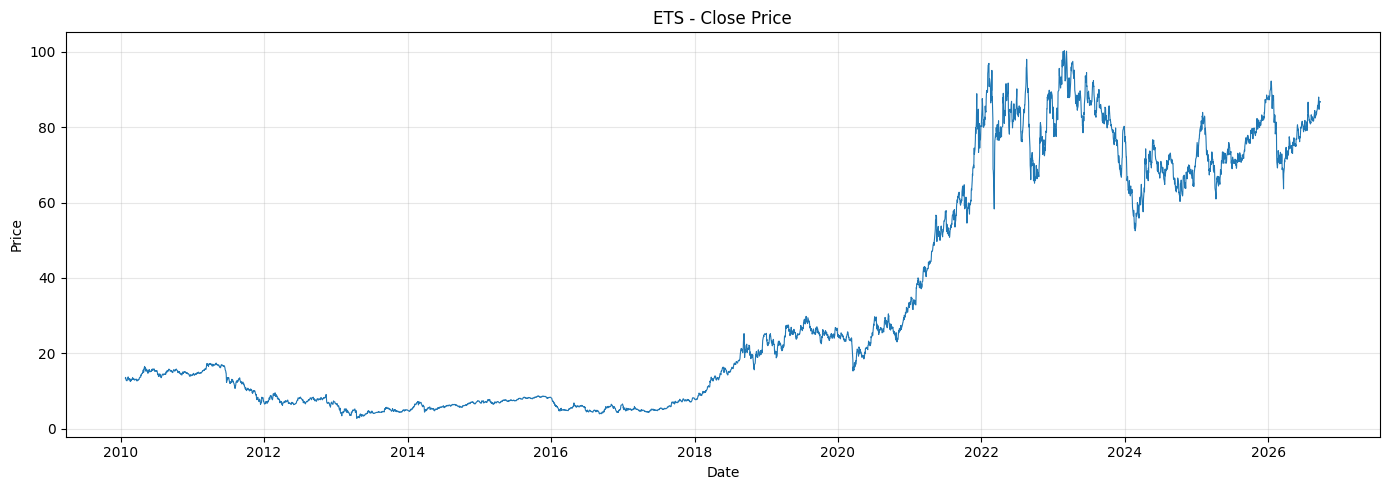

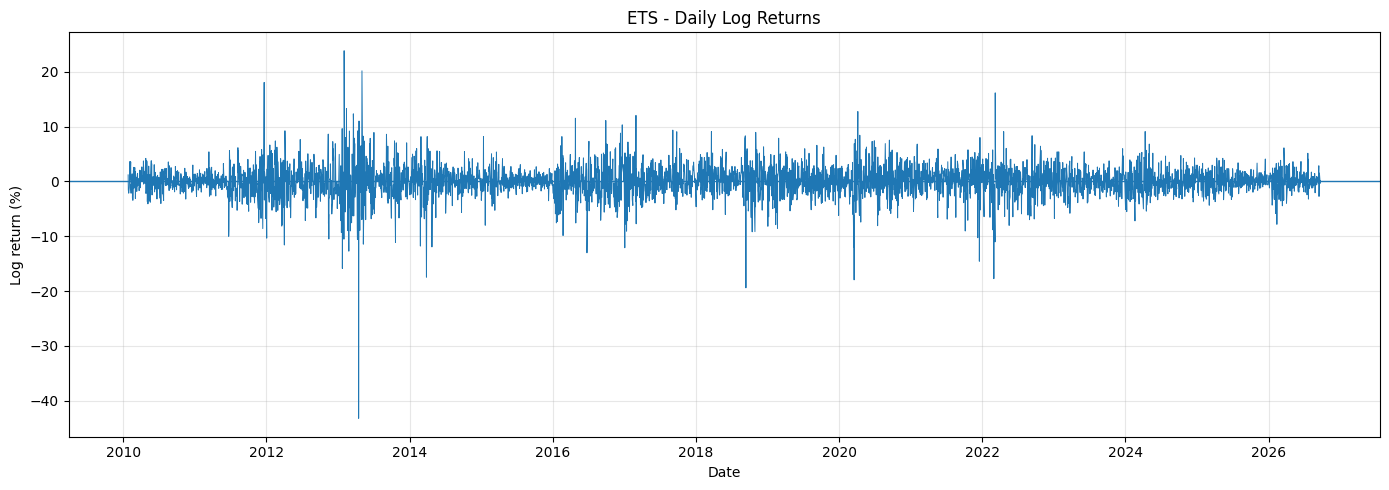

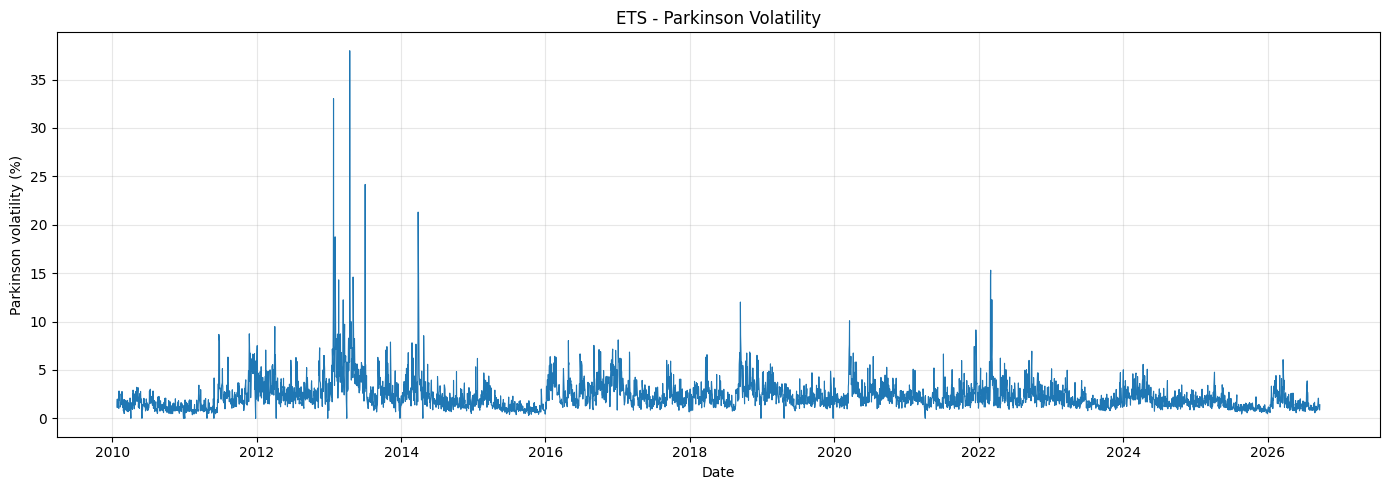

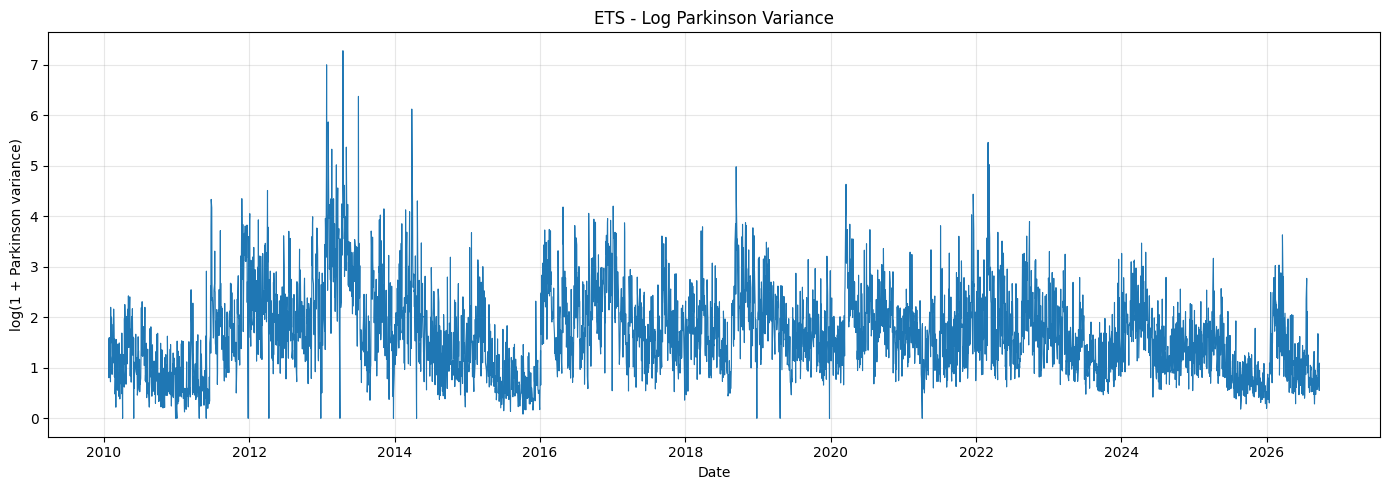

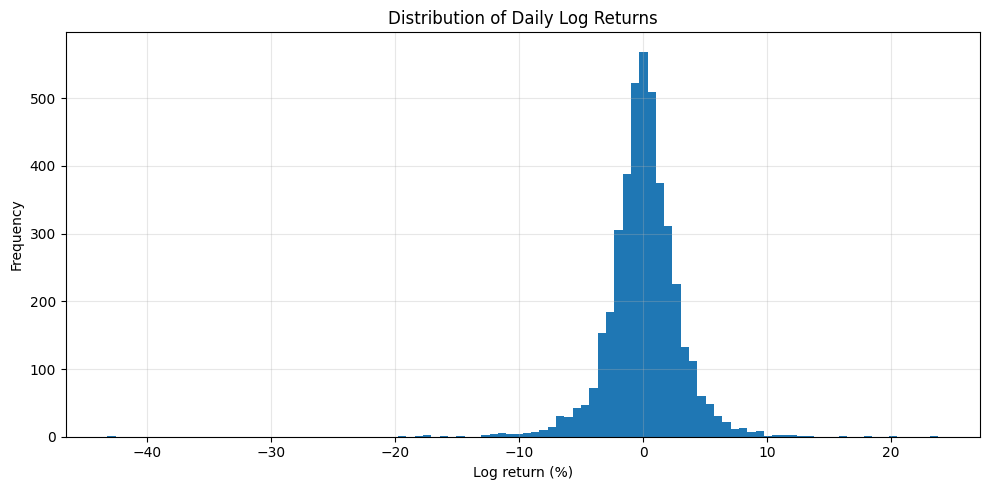

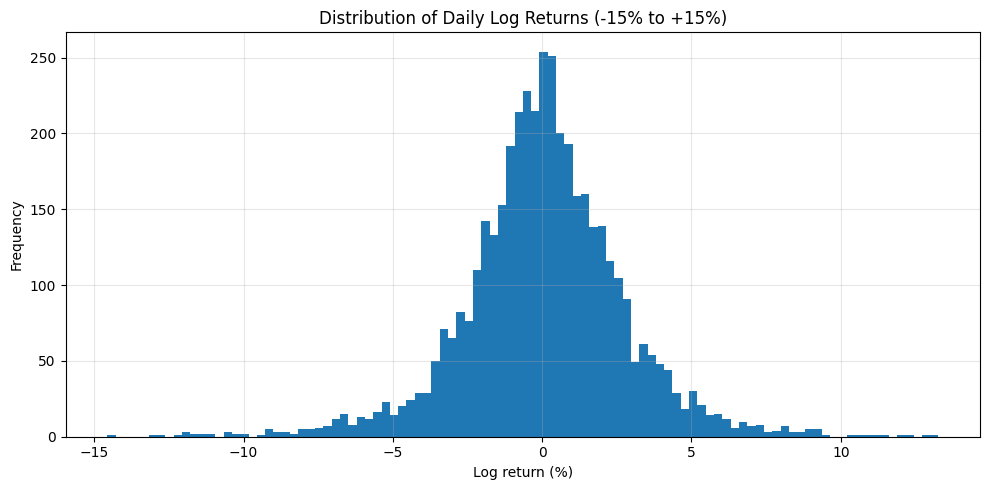

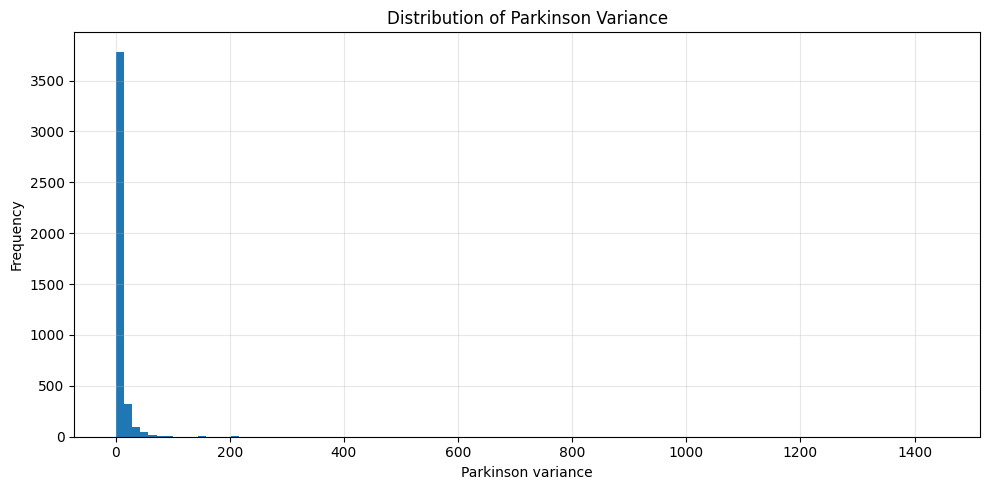

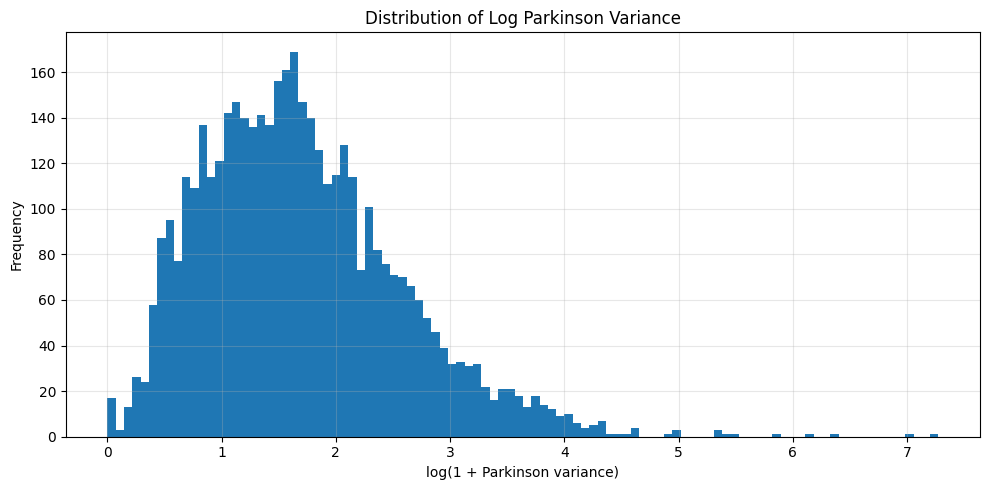

<Figure size 1000x500 with 0 Axes>

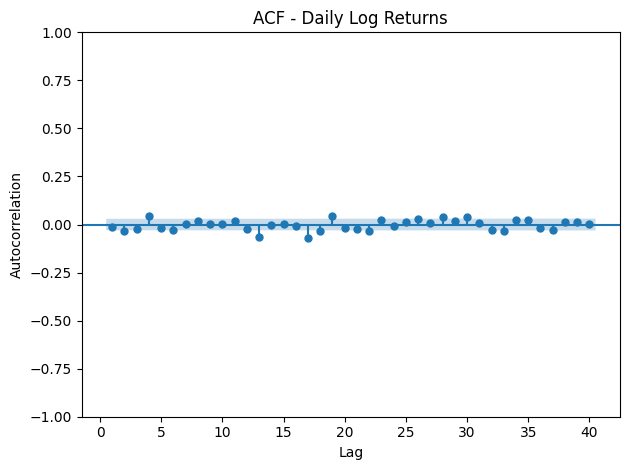

<Figure size 1000x500 with 0 Axes>

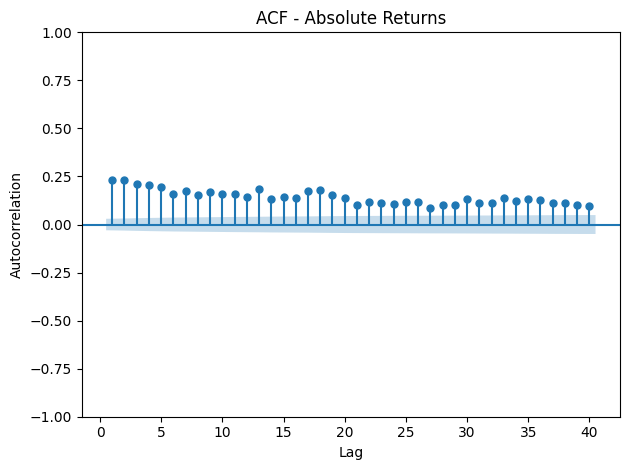

<Figure size 1000x500 with 0 Axes>

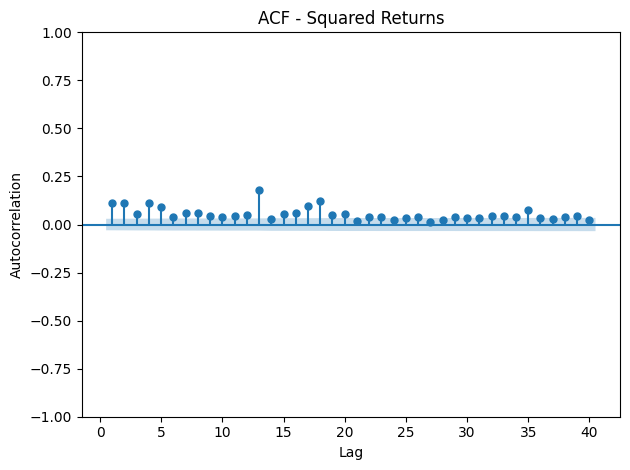

<Figure size 1000x500 with 0 Axes>

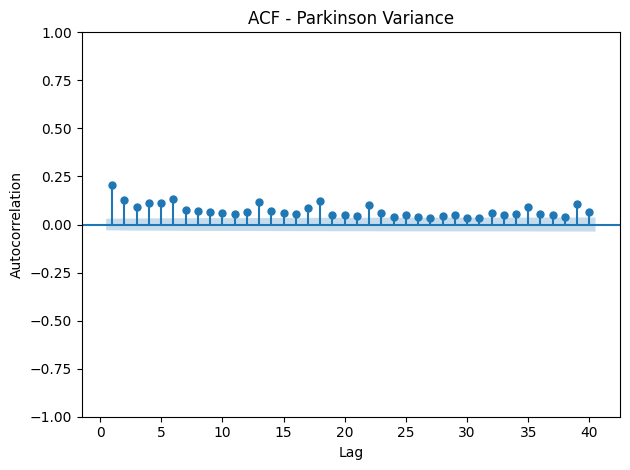


LJUNG-BOX TEST - LOG RETURNS


,lb_stat,lb_pvalue
5,18.245363,2.654107e-03
10,23.309346,9.660559e-03
20,82.209970,1.649799e-09



LJUNG-BOX TEST - SQUARED RETURNS


,lb_stat,lb_pvalue
5,212.512546,5.963468e-44
10,265.500286,2.967962e-51
20,584.117336,6.361289e-111



ARCH-LM TEST


LM statistic    1.678924e+02
LM p-value      7.574521e-31
F statistic     1.743060e+01
F p-value       1.724312e-31
dtype: float64

... (2 outputs left out)


ADF TEST - PARKINSON VARIANCE


ADF statistic   -9.202311e+00
p-value          1.986855e-15
lags             2.100000e+01
observations     4.264000e+03
dtype: float64


CORRELATION BETWEEN VOLATILITY MEASURES


,Squared_Return,Parkinson_Var,GK_Var,Return_Vol_5,Return_Vol_20
Squared_Return,1.000000,0.773953,0.602561,0.438617,0.312161
Parkinson_Var,0.773953,1.000000,0.969624,0.421033,0.312408
GK_Var,0.602561,0.969624,1.000000,0.371644,0.279172
Return_Vol_5,0.438617,0.421033,0.371644,1.000000,0.742385
Return_Vol_20,0.312161,0.312408,0.279172,0.742385,1.000000


In [83]:
# ============================================================
# STEP 3.3 - 3.18
# DIAGNOSTICS OF NATURAL GAS PRICE AND VOLATILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import adfuller


# ============================================================
# STEP 3.3 - PRICE SERIES
# ============================================================

dates = df["Date"].to_numpy()
close = df["Close"].to_numpy()

plt.figure(figsize=(14, 5))

plt.plot(
    dates,
    close,
    linewidth=0.8
)

plt.title("ETS - Close Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.4 - LOG RETURNS
# ============================================================

dates_returns = (
    df.loc[df["Log_Return"].notna(), "Date"]
    .to_numpy()
)

log_returns = (
    df.loc[df["Log_Return"].notna(), "Log_Return"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_returns,
    log_returns,
    linewidth=0.7
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.title("ETS - Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log return (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.5 - PARKINSON VOLATILITY
# ============================================================

mask = df["Parkinson_Vol"].notna()

dates_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

parkinson_vol = (
    df.loc[mask, "Parkinson_Vol"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_parkinson,
    parkinson_vol,
    linewidth=0.8
)

plt.title("ETS - Parkinson Volatility")
plt.xlabel("Date")
plt.ylabel("Parkinson volatility (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.6 - LOG PARKINSON VARIANCE
# ============================================================

df["Log_Parkinson_Var"] = np.log1p(
    df["Parkinson_Var"]
)

mask = df["Log_Parkinson_Var"].notna()

dates_log_parkinson = (
    df.loc[mask, "Date"]
    .to_numpy()
)

log_parkinson = (
    df.loc[mask, "Log_Parkinson_Var"]
    .to_numpy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    dates_log_parkinson,
    log_parkinson,
    linewidth=0.8
)

plt.title("ETS - Log Parkinson Variance")
plt.xlabel("Date")
plt.ylabel("log(1 + Parkinson variance)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.7 - RETURN DISTRIBUTION
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

# Full distribution

plt.figure(figsize=(10, 5))

plt.hist(
    returns_clean,
    bins=100
)

plt.title("Distribution of Daily Log Returns")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Zoomed distribution: -15% to +15%
# ------------------------------------------------------------

returns_zoom = returns_clean[
    (returns_clean >= -15)
    &
    (returns_clean <= 15)
]

plt.figure(figsize=(10, 5))

plt.hist(
    returns_zoom,
    bins=100
)

plt.title("Distribution of Daily Log Returns (-15% to +15%)")
plt.xlabel("Log return (%)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.8 - PARKINSON VARIANCE DISTRIBUTION
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    parkinson_var_clean,
    bins=100
)

plt.title("Distribution of Parkinson Variance")
plt.xlabel("Parkinson variance")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Log Parkinson variance
# ------------------------------------------------------------

log_parkinson_clean = (
    df["Log_Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plt.hist(
    log_parkinson_clean,
    bins=100
)

plt.title("Distribution of Log Parkinson Variance")
plt.xlabel("log(1 + Parkinson variance)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.9 - ACF OF RETURNS
# ============================================================

returns_clean = (
    df["Log_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Daily Log Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.10 - ACF OF ABSOLUTE RETURNS
# ============================================================

abs_returns_clean = (
    df["Abs_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    abs_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Absolute Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.11 - ACF OF SQUARED RETURNS
# ============================================================

squared_returns_clean = (
    df["Squared_Return"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    squared_returns_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Squared Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.12 - ACF OF PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

plt.figure(figsize=(10, 5))

plot_acf(
    parkinson_var_clean,
    lags=40,
    zero=False
)

plt.title("ACF - Parkinson Variance")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()


# ============================================================
# STEP 3.13 - LJUNG-BOX TEST: RETURNS
# ============================================================

lb_returns = acorr_ljungbox(
    returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - LOG RETURNS")
print("========================================")

display(lb_returns)


# ============================================================
# STEP 3.14 - LJUNG-BOX TEST: SQUARED RETURNS
# ============================================================

lb_squared = acorr_ljungbox(
    squared_returns_clean,
    lags=[5, 10, 20],
    return_df=True
)

print("\n========================================")
print("LJUNG-BOX TEST - SQUARED RETURNS")
print("========================================")

display(lb_squared)


# ============================================================
# STEP 3.15 - ARCH-LM TEST
# ============================================================

arch_test = het_arch(
    returns_clean,
    nlags=10
)

arch_results = pd.Series(
    {
        "LM statistic": arch_test[0],
        "LM p-value": arch_test[1],
        "F statistic": arch_test[2],
        "F p-value": arch_test[3]
    }
)

print("\n========================================")
print("ARCH-LM TEST")
print("========================================")

display(arch_results)


# ============================================================
# STEP 3.16 - ADF TEST: LOG RETURNS
# ============================================================

adf_result = adfuller(
    returns_clean,
    autolag="AIC"
)

adf_results = pd.Series(
    {
        "ADF statistic": adf_result[0],
        "p-value": adf_result[1],
        "lags": adf_result[2],
        "observations": adf_result[3]
    }
)

print("\n========================================")
print("ADF TEST - LOG RETURNS")
print("========================================")

display(adf_results)


# ============================================================
# STEP 3.17 - ADF TEST: PARKINSON VARIANCE
# ============================================================

parkinson_var_clean = (
    df["Parkinson_Var"]
    .dropna()
    .to_numpy()
)

adf_pv = adfuller(
    parkinson_var_clean,
    autolag="AIC"
)

adf_pv_results = pd.Series(
    {
        "ADF statistic": adf_pv[0],
        "p-value": adf_pv[1],
        "lags": adf_pv[2],
        "observations": adf_pv[3]
    }
)

print("\n========================================")
print("ADF TEST - PARKINSON VARIANCE")
print("========================================")

display(adf_pv_results)


# ============================================================
# STEP 3.18 - CORRELATION BETWEEN VOLATILITY MEASURES
# ============================================================

volatility_variables = [
    "Squared_Return",
    "Parkinson_Var",
    "GK_Var",
    "Return_Vol_5",
    "Return_Vol_20"
]

vol_corr = (
    df[volatility_variables]
    .corr()
)

print("\n========================================")
print("CORRELATION BETWEEN VOLATILITY MEASURES")
print("========================================")

display(vol_corr)

In [84]:
# ============================================================
# STEP 4 - FINAL VERSION
# COPPER - 5-DAY VOLATILITY REGIMES
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. ENSURE FULL SAMPLE AND CORRECT ORDER
# ------------------------------------------------------------

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Full df shape:",
    df.shape
)

print(
    "Date range:",
    df["Date"].min(),
    "-",
    df["Date"].max()
)


# ------------------------------------------------------------
# 1. REMOVE OLD REGIME VARIABLES
# ------------------------------------------------------------

columns_to_remove = [
    "Parkinson_Mean_5",
    "PV_Q33",
    "PV_Q67",
    "Volatility_Regime",
    "PV5_Q33",
    "PV5_Q67",
    "Volatility_Regime_5D"
]


df = df.drop(
    columns=[
        col
        for col in columns_to_remove
        if col in df.columns
    ]
)


# ------------------------------------------------------------
# 2. 5-DAY PARKINSON MEAN
# IDENTICAL TO GAS / BRENT
# ------------------------------------------------------------

df[
    "Parkinson_Mean_5"
] = (
    df[
        "Parkinson_Var"
    ]
    .rolling(
        window=5,
        min_periods=4
    )
    .mean()
)


# ------------------------------------------------------------
# 3. CAUSAL ROLLING Q33 / Q67
# ------------------------------------------------------------

regime_window = 252
min_regime_obs = 250


df[
    "PV5_Q33"
] = (
    df[
        "Parkinson_Mean_5"
    ]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.33)
)


df[
    "PV5_Q67"
] = (
    df[
        "Parkinson_Mean_5"
    ]
    .shift(1)
    .rolling(
        window=regime_window,
        min_periods=min_regime_obs
    )
    .quantile(0.67)
)


# ------------------------------------------------------------
# 4. DEFINE REGIMES
# ------------------------------------------------------------

conditions = [

    df[
        "Parkinson_Mean_5"
    ]
    <
    df[
        "PV5_Q33"
    ],

    (
        (
            df[
                "Parkinson_Mean_5"
            ]
            >=
            df[
                "PV5_Q33"
            ]
        )
        &
        (
            df[
                "Parkinson_Mean_5"
            ]
            <=
            df[
                "PV5_Q67"
            ]
        )
    ),

    df[
        "Parkinson_Mean_5"
    ]
    >
    df[
        "PV5_Q67"
    ]
]


df[
    "Volatility_Regime_5D"
] = np.select(
    conditions,
    [
        "Low",
        "Normal",
        "High"
    ],
    default=None
)


# ------------------------------------------------------------
# 5. FULL-SAMPLE AUDIT
# ------------------------------------------------------------

print(
    "\nMissing values:"
)

print(
    df[
        [
            "Parkinson_Var",
            "Parkinson_Mean_5",
            "PV5_Q33",
            "PV5_Q67",
            "Volatility_Regime_5D"
        ]
    ]
    .isna()
    .sum()
)


print(
    "\nFull-sample regime counts:"
)

print(
    df[
        "Volatility_Regime_5D"
    ]
    .value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 6. VALIDATION-SPECIFIC AUDIT
# ------------------------------------------------------------

validation_regime_audit = (
    df[
        (
            df["Date"]
            >=
            pd.Timestamp(
                "2017-01-02"
            )
        )
        &
        (
            df["Date"]
            <=
            pd.Timestamp(
                "2019-12-31"
            )
        )
    ]
    .copy()
)


print(
    "\nValidation observations:",
    len(
        validation_regime_audit
    )
)


print(
    "\nValidation regime counts:"
)

print(
    validation_regime_audit[
        "Volatility_Regime_5D"
    ]
    .value_counts(
        dropna=False
    )
)

Full df shape: (4286, 50)
Date range: 2010-01-25 00:00:00 - 2026-09-22 00:00:00

Missing values:
Parkinson_Var             0
Parkinson_Mean_5          3
PV5_Q33                 253
PV5_Q67                 253
Volatility_Regime_5D    253
dtype: int64

Full-sample regime counts:
Volatility_Regime_5D
Low       1552
High      1316
Normal    1165
None       253
Name: count, dtype: int64

Validation observations: 770

Validation regime counts:
Volatility_Regime_5D
Low       336
Normal    238
High      196
Name: count, dtype: int64


In [85]:
# ============================================================
# STEP 4.4 - REGIME PERSISTENCE
# ============================================================

regime_df_5d = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_df_5d["Previous_Regime"] = (
    regime_df_5d["Volatility_Regime_5D"]
    .shift(1)
)

regime_df_5d["Regime_Changed"] = (
    regime_df_5d["Volatility_Regime_5D"]
    != regime_df_5d["Previous_Regime"]
)

change_rate = (
    regime_df_5d["Regime_Changed"]
    .iloc[1:]
    .mean()
)

print(
    "Share of observations with regime change:",
    round(change_rate * 100, 2),
    "%"
)


transition_matrix_5d = pd.crosstab(
    regime_df_5d["Previous_Regime"],
    regime_df_5d["Volatility_Regime_5D"],
    normalize="index"
)

transition_matrix_5d = transition_matrix_5d.reindex(
    index=["Low", "Normal", "High"],
    columns=["Low", "Normal", "High"]
)

display(transition_matrix_5d)

Share of observations with regime change: 15.4 %


Volatility_Regime_5D,Low,Normal,High
Previous_Regime,,,
Low,0.880799,0.112113,0.007088
Normal,0.150344,0.742268,0.107388
High,0.006839,0.096505,0.896657


In [86]:
# ============================================================
# STEP 4.5 - REGIME DURATION
# ============================================================

regime_duration = (
    df[
        ["Date", "Volatility_Regime_5D"]
    ]
    .dropna()
    .copy()
)

regime_duration["Spell_ID"] = (
    regime_duration["Volatility_Regime_5D"]
    != regime_duration["Volatility_Regime_5D"].shift(1)
).cumsum()


spells = (
    regime_duration
    .groupby("Spell_ID")
    .agg(
        Regime=("Volatility_Regime_5D", "first"),
        Start=("Date", "min"),
        End=("Date", "max"),
        Duration=("Date", "size")
    )
)


duration_summary = (
    spells
    .groupby("Regime")["Duration"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(duration_summary)

,count,mean,median,min,max
Regime,,,,,
Low,185,8.389189,4.0,1,144
Normal,301,3.870432,3.0,1,40
High,136,9.676471,5.0,1,97


In [87]:
# ============================================================
# STEP 4.6 - VOLATILITY STATE SUMMARY
# ============================================================

regime_state_summary = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Mean_5"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Mean_5"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(regime_state_summary)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1552,2.835421,2.701834,1.502304,0.387714,9.274763
Normal,1165,6.286285,5.594480,3.615983,1.212649,23.748641
High,1316,17.925902,10.791290,31.042155,1.760281,373.419299


In [88]:
# ============================================================
# STEP 4.7 - DAILY VOLATILITY WITHIN REGIMES
# Optional descriptive analysis
# ============================================================

daily_volatility_by_regime = (
    df
    .dropna(
        subset=[
            "Volatility_Regime_5D",
            "Parkinson_Var"
        ]
    )
    .groupby("Volatility_Regime_5D")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(["Low", "Normal", "High"])
)

display(daily_volatility_by_regime)

,count,mean,median,std,min,max
Volatility_Regime_5D,,,,,,
Low,1552,2.822892,2.128061,2.452438,0.0,24.141549
Normal,1165,6.303910,4.510070,6.098631,0.0,62.147205
High,1316,17.924845,9.019766,57.558735,0.0,1442.458721


In [89]:
# ============================================================
# STEP 5.1 - TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_end = pd.Timestamp("2016-12-31")
validation_end = pd.Timestamp("2019-12-31")


df["Sample"] = np.select(
    [
        df["Date"] <= train_end,

        (
            (df["Date"] > train_end)
            &
            (df["Date"] <= validation_end)
        ),

        df["Date"] > validation_end
    ],
    [
        "Train",
        "Validation",
        "Test"
    ],
    default=None
)

In [90]:
# ============================================================
# STEP 5.2 - SAMPLE SUMMARY
# ============================================================

sample_summary = (
    df
    .groupby("Sample")
    .agg(
        Start=("Date", "min"),
        End=("Date", "max"),
        Observations=("Date", "size")
    )
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(sample_summary)

,Start,End,Observations
Sample,,,
Train,2010-01-25,2016-12-30,1787
Validation,2017-01-02,2019-12-31,770
Test,2020-01-02,2026-09-22,1729


In [91]:
# ============================================================
# STEP 5.3 - REGIMES BY SAMPLE
# ============================================================

regime_by_sample = pd.crosstab(
    df["Sample"],
    df["Volatility_Regime_5D"]
)

regime_by_sample = regime_by_sample.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,549,386,599
Validation,336,238,196
Test,667,541,521


In [92]:
# ============================================================
# STEP 5.4 - REGIME SHARES BY SAMPLE
# ============================================================

regime_by_sample_pct = (
    pd.crosstab(
        df["Sample"],
        df["Volatility_Regime_5D"],
        normalize="index"
    )
    * 100
)

regime_by_sample_pct = regime_by_sample_pct.reindex(
    index=["Train", "Validation", "Test"],
    columns=["Low", "Normal", "High"]
)

display(regime_by_sample_pct)

Volatility_Regime_5D,Low,Normal,High
Sample,,,
Train,35.788787,25.162973,39.048240
Validation,43.636364,30.909091,25.454545
Test,38.577212,31.289763,30.133025


In [93]:
# ============================================================
# STEP 5.5 - TARGET VOLATILITY BY SAMPLE
# ============================================================

target_by_sample = (
    df
    .groupby("Sample")["Parkinson_Var"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex([
        "Train",
        "Validation",
        "Test"
    ])
)

display(target_by_sample)

,count,mean,median,std,min,max
Sample,,,,,,
Train,1787,11.164951,3.981635,49.033764,0.0,1442.458721
Validation,770,7.683023,4.819054,9.691719,0.0,144.331364
Test,1729,5.798843,3.489313,10.768862,0.0,234.129406


In [94]:
# ============================================================
# STEP 6.1 - FINAL FEATURE SET
# ============================================================

features = [

    # Current Parkinson volatility
    "Parkinson_Var",

    # Lagged Parkinson volatility
    "Parkinson_Lag_1",
    "Parkinson_Lag_2",
    "Parkinson_Lag_3",
    "Parkinson_Lag_5",
    "Parkinson_Lag_10",
    "Parkinson_Lag_20",

    # Aggregated Parkinson volatility
    "Parkinson_Mean_5",
    "Parkinson_Mean_10",
    "Parkinson_Mean_20",

    # Current return information
    "Abs_Return",
    "Squared_Return",

    # Lagged absolute returns
    "Abs_Return_Lag_1",
    "Abs_Return_Lag_2",
    "Abs_Return_Lag_3",
    "Abs_Return_Lag_5",
    "Abs_Return_Lag_10",
    "Abs_Return_Lag_20",

    # Lagged squared returns
    "Squared_Return_Lag_1",
    "Squared_Return_Lag_2",
    "Squared_Return_Lag_3",
    "Squared_Return_Lag_5",
    "Squared_Return_Lag_10",
    "Squared_Return_Lag_20",

    # Rolling return volatility
    "Return_Vol_5",
    "Return_Vol_10",
    "Return_Vol_20"
]

target = "Target_Parkinson_t1"

In [95]:
# ============================================================
# STEP 6.2 - CREATE MODEL DATASET
# ============================================================

model_columns = (
    [
        "Date",
        "Sample",
        "Volatility_Regime_5D"
    ]
    + features
    + [target]
)

model_df = (
    df[model_columns]
    .copy()
)

print("Initial model dataset shape:")
print(model_df.shape)

Initial model dataset shape:
(4286, 31)


In [96]:
# ============================================================
# STEP 6.3 - MISSING VALUES
# ============================================================

missing_values = (
    model_df
    .isna()
    .sum()
)

print("Missing values before filtering:")
display(missing_values)

Missing values before filtering:


Date                       0
Sample                     0
Volatility_Regime_5D     253
Parkinson_Var              0
Parkinson_Lag_1            1
Parkinson_Lag_2            2
Parkinson_Lag_3            3
Parkinson_Lag_5            5
Parkinson_Lag_10          10
Parkinson_Lag_20          20
Parkinson_Mean_5           3
Parkinson_Mean_10          9
Parkinson_Mean_20         19
Abs_Return                 1
Squared_Return             1
Abs_Return_Lag_1           2
Abs_Return_Lag_2           3
Abs_Return_Lag_3           4
Abs_Return_Lag_5           6
Abs_Return_Lag_10         11
Abs_Return_Lag_20         21
Squared_Return_Lag_1       2
Squared_Return_Lag_2       3
Squared_Return_Lag_3       4
Squared_Return_Lag_5       6
Squared_Return_Lag_10     11
Squared_Return_Lag_20     21
Return_Vol_5               5
Return_Vol_10             10
Return_Vol_20             20
Target_Parkinson_t1        1
dtype: int64

In [97]:
# ============================================================
# STEP 6.4 - COMPLETE MODEL SAMPLE
# ============================================================

model_df_complete = (
    model_df
    .dropna(
        subset=features + [target]
    )
    .reset_index(drop=True)
)

print(
    "Observations before filtering:",
    len(model_df)
)

print(
    "Observations after filtering:",
    len(model_df_complete)
)

print(
    "Removed observations:",
    len(model_df) - len(model_df_complete)
)

print(
    "\nModel date range:",
    model_df_complete["Date"].min(),
    "-",
    model_df_complete["Date"].max()
)

Observations before filtering: 4286
Observations after filtering: 4264
Removed observations: 22

Model date range: 2010-02-23 00:00:00 - 2026-09-21 00:00:00


In [22]:
# ============================================================
# STEP 6.5 - X AND y
# ============================================================

X = (
    model_df_complete[features]
    .copy()
)

y = (
    model_df_complete[target]
    .copy()
)

dates_model = (
    model_df_complete["Date"]
    .copy()
)

samples_model = (
    model_df_complete["Sample"]
    .copy()
)

regimes_model = (
    model_df_complete["Volatility_Regime_5D"]
    .copy()
)


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4264, 27)
y shape: (4264,)


In [23]:
# ============================================================
# STEP 6.6 - SAMPLE MASKS
# ============================================================

train_mask = (
    model_df_complete["Sample"] == "Train"
)

validation_mask = (
    model_df_complete["Sample"] == "Validation"
)

test_mask = (
    model_df_complete["Sample"] == "Test"
)

In [24]:
# ============================================================
# STEP 6.7 - TRAIN / VALIDATION / TEST MATRICES
# ============================================================

X_train = (
    X.loc[train_mask]
    .copy()
)

y_train = (
    y.loc[train_mask]
    .copy()
)


X_validation = (
    X.loc[validation_mask]
    .copy()
)

y_validation = (
    y.loc[validation_mask]
    .copy()
)


X_test = (
    X.loc[test_mask]
    .copy()
)

y_test = (
    y.loc[test_mask]
    .copy()
)


print(
    "Train:",
    X_train.shape,
    y_train.shape
)

print(
    "Validation:",
    X_validation.shape,
    y_validation.shape
)

print(
    "Test:",
    X_test.shape,
    y_test.shape
)

Train: (1766, 27) (1766,)
Validation: (770, 27) (770,)
Test: (1728, 27) (1728,)


In [25]:
# ============================================================
# STEP 6.8 - DATES AND REGIMES BY SAMPLE
# ============================================================

dates_train = (
    model_df_complete.loc[
        train_mask,
        "Date"
    ]
    .copy()
)

dates_validation = (
    model_df_complete.loc[
        validation_mask,
        "Date"
    ]
    .copy()
)

dates_test = (
    model_df_complete.loc[
        test_mask,
        "Date"
    ]
    .copy()
)


regimes_train = (
    model_df_complete.loc[
        train_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_validation = (
    model_df_complete.loc[
        validation_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

regimes_test = (
    model_df_complete.loc[
        test_mask,
        "Volatility_Regime_5D"
    ]
    .copy()
)

In [26]:
# ============================================================
# STEP 6.9 - CHRONOLOGICAL CHECK
# ============================================================

print("TRAIN")
print(
    model_df_complete.loc[
        train_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        train_mask,
        "Date"
    ].max()
)


print("\nVALIDATION")
print(
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        validation_mask,
        "Date"
    ].max()
)


print("\nTEST")
print(
    model_df_complete.loc[
        test_mask,
        "Date"
    ].min(),
    "-",
    model_df_complete.loc[
        test_mask,
        "Date"
    ].max()
)

TRAIN
2010-02-23 00:00:00 - 2016-12-30 00:00:00

VALIDATION
2017-01-02 00:00:00 - 2019-12-31 00:00:00

TEST
2020-01-02 00:00:00 - 2026-09-21 00:00:00


In [27]:
# ============================================================
# STEP 6.10 - TARGET ALIGNMENT CHECK
# ============================================================

alignment_check = (
    df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1"
        ]
    ]
    .copy()
)

alignment_check[
    "Next_Parkinson_Actual"
] = (
    alignment_check[
        "Parkinson_Var"
    ]
    .shift(-1)
)

alignment_check[
    "Difference"
] = (
    alignment_check[
        "Target_Parkinson_t1"
    ]
    -
    alignment_check[
        "Next_Parkinson_Actual"
    ]
)


max_alignment_difference = (
    alignment_check[
        "Difference"
    ]
    .abs()
    .max()
)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

Maximum target alignment difference: 0.0


In [28]:
# ============================================================
# STEP 6.11 - FINAL NaN CHECK
# ============================================================

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Missing values in y:",
    y.isna().sum()
)

Missing values in X: 0
Missing values in y: 0


In [29]:
# ============================================================
# STEP 6.12 - INFINITE VALUES CHECK
# ============================================================

number_of_infinite_X = (
    np.isinf(
        X.to_numpy()
    )
    .sum()
)

number_of_infinite_y = (
    np.isinf(
        y.to_numpy()
    )
    .sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

print(
    "Infinite values in y:",
    number_of_infinite_y
)

Infinite values in X: 0
Infinite values in y: 0


In [30]:
# ============================================================
# STEP 6.13 - FINAL MODEL DATA SUMMARY
# ============================================================

final_summary = pd.DataFrame({
    "Sample": [
        "Train",
        "Validation",
        "Test"
    ],

    "Observations": [
        train_mask.sum(),
        validation_mask.sum(),
        test_mask.sum()
    ],

    "Start": [
        dates_train.min(),
        dates_validation.min(),
        dates_test.min()
    ],

    "End": [
        dates_train.max(),
        dates_validation.max(),
        dates_test.max()
    ]
})

display(final_summary)

print(
    "\nNumber of features:",
    len(features)
)

print(
    "Target:",
    target
)

,Sample,Observations,Start,End
0,Train,1766,2010-02-23,2016-12-30
1,Validation,770,2017-01-02,2019-12-31
2,Test,1728,2020-01-02,2026-09-21



Number of features: 27
Target: Target_Parkinson_t1


In [31]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

print(
    "Maximum target alignment difference:",
    max_alignment_difference
)

print(
    "Missing values in X:",
    X.isna().sum().sum()
)

print(
    "Infinite values in X:",
    number_of_infinite_X
)

Train: (1766, 27) (1766,)
Validation: (770, 27) (770,)
Test: (1728, 27) (1728,)
Maximum target alignment difference: 0.0
Missing values in X: 0
Infinite values in X: 0


In [32]:
# ============================================================
# COMMON FORECAST EVALUATION FUNCTIONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


def qlike_loss_strict(
    actual,
    forecast
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan


    if np.any(
        forecast <= 0
    ):
        return np.nan


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


def evaluate_forecast(
    actual,
    forecast,
    model_name
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    mae = mean_absolute_error(
        actual,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    return pd.DataFrame({
        "Model": [model_name],
        "N": [len(actual)],
        "Nonpositive": [
            int(np.sum(forecast <= 0))
        ],
        "MAE": [mae],
        "RMSE": [rmse],
        "QLIKE": [qlike],
        "QLIKE_Admissible": [
            "Yes"
            if np.isfinite(qlike)
            else "No"
        ]
    })

In [33]:

# ============================================================
# FIXED MODEL CONFIGURATIONS
# Recovered from completed original notebooks
# NO GRID SEARCH / NO HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd

# CHANGE THIS FOR EACH NOTEBOOK:
# "EUA", "BRENT", "COPPER", "NATURAL_GAS"

MARKET = "EUA"

MODEL_CONFIGS = {

    # ========================================================
    # EUROPEAN UNION ALLOWANCES
    # ========================================================

    "EUA": {
        "RF": {
            "n_estimators": 100,
            "max_depth": 10,
            "max_features": 1.0,
            "min_samples_leaf": 3,
            "min_samples_split": 10
        },
        "XGB": {
            "n_estimators": 200,
            "max_depth": 1,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        "SVR": {
            "kernel": "linear",
            "C": 1.0,
            "epsilon": 0.5
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (1, 1, 3),
            "GJR-GARCH": (1, 1, 3)
        }
    },

    # ========================================================
    # BRENT CRUDE OIL
    # ========================================================

    "BRENT": {
        "RF": {
            "n_estimators": 300,
            "max_depth": None,
            "max_features": 0.5,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 300,
            "max_depth": 2,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "SVR": {
            "kernel": "rbf",
            "C": 10.0,
            "epsilon": 1.0,
            "gamma": 0.01
        },
        "ARCH": {
            "GARCH": (2, 0, 1),
            "EGARCH": (1, 1, 2),
            "GJR-GARCH": (2, 1, 2)
        }
    },

    # ========================================================
    # COPPER
    # ========================================================

    "COPPER": {
        "RF": {
            "n_estimators": 100,
            "max_depth": 6,
            "max_features": 0.5,
            "min_samples_leaf": 8,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 450,
            "max_depth": 1,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "SVR": {
            "kernel": "linear",
            "C": 0.1,
            "epsilon": 0.5
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (2, 1, 2),
            "GJR-GARCH": (1, 1, 2)
        }
    },

    # ========================================================
    # NATURAL GAS
    # ========================================================

    "NATURAL_GAS": {
        "RF": {
            "n_estimators": 300,
            "max_depth": 6,
            "max_features": 0.25,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "XGB": {
            "n_estimators": 100,
            "max_depth": 1,
            "learning_rate": 0.1,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 5.0
        },
        "SVR": {
            "kernel": "rbf",
            "C": 10.0,
            "epsilon": 3.0,
            "gamma": 0.01
        },
        "ARCH": {
            "GARCH": (1, 0, 3),
            "EGARCH": (1, 1, 2),
            "GJR-GARCH": (1, 1, 3)
        }
    }
}

# ============================================================
# ASSIGN CONFIGURATIONS TO EXISTING NOTEBOOK VARIABLES
# ============================================================

assert MARKET in MODEL_CONFIGS

config = MODEL_CONFIGS[MARKET]

rf_final_params = config["RF"].copy()
xgb_final_params = config["XGB"].copy()
svr_final_params = config["SVR"].copy()

# All four markets selected Constant mean on Train

best_mean_name = "Constant"

best_mean_config = {
    "Name": "Constant",
    "Mean": "Constant",
    "Lags": None
}

# Build ARCH specifications expected by STEP 11.9

arch_final_specs = {}

for family, (p, o, q) in config["ARCH"].items():

    arch_final_specs[family] = {
        "vol": "EGARCH" if family == "EGARCH" else "GARCH",
        "p": p,
        "o": o,
        "q": q
    }

print("MARKET:", MARKET)
print("RF:", rf_final_params)
print("XGBoost:", xgb_final_params)
print("SVR:", svr_final_params)
print("ARCH:", arch_final_specs)
print("Mean:", best_mean_config)


MARKET: EUA
RF: {'n_estimators': 100, 'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 3, 'min_samples_split': 10}
XGBoost: {'n_estimators': 200, 'max_depth': 1, 'learning_rate': 0.05, 'subsample': 1.0, 'colsample_bytree': 0.6, 'min_child_weight': 1, 'reg_alpha': 0.0, 'reg_lambda': 1.0}
SVR: {'kernel': 'linear', 'C': 1.0, 'epsilon': 0.5}
ARCH: {'GARCH': {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 3}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 3}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 3}}
Mean: {'Name': 'Constant', 'Mean': 'Constant', 'Lags': None}


In [34]:
# ============================================================
# STEP 7.1 - HAR SPECIFICATION
# ============================================================

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"

In [35]:
# ============================================================
# FORECAST EVALUATION FUNCTIONS
# Penalized QLIKE for tuning
# Strict QLIKE for reported results
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# ------------------------------------------------------------
# 1. PENALIZED QLIKE
# ONLY for hyperparameter tuning / GridSearch
# ------------------------------------------------------------

def qlike_loss_penalized(
    actual,
    forecast,
    epsilon=1e-8
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    # Technical protection used only during tuning
    forecast_safe = np.maximum(
        forecast,
        epsilon
    )
    
    return np.mean(
        np.log(forecast_safe)
        +
        actual / forecast_safe
    )


# ------------------------------------------------------------
# 2. STRICT QLIKE
# For Validation/Test results reported in the paper
# ------------------------------------------------------------

def qlike_loss_strict(
    actual,
    forecast
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    
    # Missing / infinite values
    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan
    
    
    # Variance forecasts must be strictly positive
    if np.any(
        forecast <= 0
    ):
        return np.nan
    
    
    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


# ------------------------------------------------------------
# 3. FINAL FORECAST EVALUATION
# ------------------------------------------------------------

def evaluate_forecast(
    actual,
    forecast,
    model_name
):
    
    actual = np.asarray(
        actual,
        dtype=float
    )
    
    forecast = np.asarray(
        forecast,
        dtype=float
    )
    
    
    mae = mean_absolute_error(
        actual,
        forecast
    )
    
    
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )
    
    
    qlike = qlike_loss_strict(
        actual,
        forecast
    )
    
    
    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )
    
    
    return pd.DataFrame({
        
        "Model": [
            model_name
        ],
        
        "N": [
            len(actual)
        ],
        
        "Nonpositive": [
            nonpositive
        ],
        
        "MAE": [
            mae
        ],
        
        "RMSE": [
            rmse
        ],
        
        "QLIKE": [
            qlike
        ]
    })

In [36]:
# ============================================================
# STEP 7.3 - FINAL WALK-FORWARD HAR
# ============================================================

from sklearn.linear_model import LinearRegression

har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

har_target = "Target_Parkinson_t1"


validation_origins = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .copy()
)


har_wf_forecasts = []


for _, row in validation_origins.iterrows():

    origin_date = row["Date"]

    # Only observations whose t+1 target is already known
    train_history = (
        model_df_complete[
            model_df_complete["Date"] < origin_date
        ]
        .dropna(
            subset=har_features + [har_target]
        )
    )

    X_hist = train_history[har_features]
    y_hist = train_history[har_target]

    X_current = pd.DataFrame(
        [row[har_features].values],
        columns=har_features
    )

    model = LinearRegression()

    model.fit(
        X_hist,
        y_hist
    )

    forecast = float(
        model.predict(X_current)[0]
    )

    har_wf_forecasts.append(
        {
            "Date": origin_date,
            "Forecast_HAR": forecast
        }
    )


har_validation_wf = pd.DataFrame(
    har_wf_forecasts
)


print(
    "HAR walk-forward forecasts:",
    len(har_validation_wf)
)

display(
    har_validation_wf.head()
)

HAR walk-forward forecasts: 770


,Date,Forecast_HAR
0,2017-01-02,16.326183
1,2017-01-03,22.147426
2,2017-01-04,20.161614
3,2017-01-05,20.266898
4,2017-01-06,20.876436


In [37]:
validation_base = (
    validation_origins[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)

validation_base["Forecast_Naive"] = (
    validation_base["Parkinson_Var"]
)

validation_base = (
    validation_base
    .merge(
        har_validation_wf,
        on="Date",
        how="left"
    )
)

display(validation_base.head())

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR
0,2017-01-02,20.317755,65.654247,Normal,20.317755,16.326183
1,2017-01-03,65.654247,41.659943,High,65.654247,22.147426
2,2017-01-04,41.659943,34.198104,High,41.659943,20.161614
3,2017-01-05,34.198104,34.285399,High,34.198104,20.266898
4,2017-01-06,34.285399,36.407590,High,34.285399,20.876436


In [38]:
# ============================================================
# STEP 7.5 - FINAL VALIDATION PERFORMANCE
# ============================================================

results_naive = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_Naive"],
    model_name="Naive"
)

results_har = evaluate_forecast(
    actual=validation_base["Target_Parkinson_t1"],
    forecast=validation_base["Forecast_HAR"],
    model_name="HAR"
)

validation_results = pd.concat(
    [
        results_naive,
        results_har
    ],
    ignore_index=True
)

display(validation_results)

,Model,N,Nonpositive,MAE,RMSE,QLIKE
0,Naive,770,3,5.518388,10.010930,NaN
1,HAR,770,0,5.303231,8.657459,2.944459


In [39]:
# ============================================================
# STEP 7.6 - CHECK FINAL HAR FORECASTS
# ============================================================

print(
    "Minimum HAR forecast:",
    validation_base["Forecast_HAR"].min()
)

print(
    "Negative HAR forecasts:",
    (
        validation_base["Forecast_HAR"] < 0
    ).sum()
)

print(
    "Missing HAR forecasts:",
    validation_base["Forecast_HAR"].isna().sum()
)

Minimum HAR forecast: 5.0598678934742445
Negative HAR forecasts: 0
Missing HAR forecasts: 0


In [40]:
# ============================================================
# STEP 7.7 - FINAL PERFORMANCE BY REGIME
# ============================================================

regime_results = []

for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = validation_base[
        validation_base[
            "Volatility_Regime_5D"
        ] == regime
    ]

    for model_name, forecast_col in [
        ("Naive", "Forecast_Naive"),
        ("HAR", "Forecast_HAR")
    ]:

        result = evaluate_forecast(
            actual=temp["Target_Parkinson_t1"],
            forecast=temp[forecast_col],
            model_name=model_name
        )

        result["Regime"] = regime

        regime_results.append(result)


validation_results_by_regime = pd.concat(
    regime_results,
    ignore_index=True
)

display(
    validation_results_by_regime[
        [
            "Regime",
            "Model",
            "MAE",
            "RMSE",
            "QLIKE"
        ]
    ]
)

,Regime,Model,MAE,RMSE,QLIKE
0,Low,Naive,3.135730,4.834618,NaN
1,Low,HAR,4.004250,4.815532,2.602351
2,Normal,Naive,4.892203,7.809850,3.103951
3,Normal,HAR,5.006810,7.413786,2.944903
4,High,Naive,10.363312,16.720756,3.696789
5,High,HAR,7.889997,13.709751,3.530390


In [41]:
# ============================================================
# STEP 7.9 - DIEBOLD-MARIANO TEST FUNCTION
# STRICT QLIKE
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t


def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast_1 = np.asarray(
        forecast_1,
        dtype=float
    )

    forecast_2 = np.asarray(
        forecast_2,
        dtype=float
    )


    # --------------------------------------------------------
    # Joint finite sample
    # --------------------------------------------------------

    valid = (
        np.isfinite(actual)
        &
        np.isfinite(forecast_1)
        &
        np.isfinite(forecast_2)
    )


    actual = actual[valid]

    forecast_1 = forecast_1[valid]

    forecast_2 = forecast_2[valid]


    n = len(actual)


    if n < 10:

        raise ValueError(
            "Too few valid observations for the DM test."
        )


    loss = loss.upper()


    # --------------------------------------------------------
    # Loss functions
    # --------------------------------------------------------

    if loss == "MAE":

        loss_1 = np.abs(
            actual - forecast_1
        )

        loss_2 = np.abs(
            actual - forecast_2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - forecast_1
        ) ** 2

        loss_2 = (
            actual - forecast_2
        ) ** 2


    elif loss == "QLIKE":

        if (
            np.any(forecast_1 <= 0)
            or
            np.any(forecast_2 <= 0)
        ):

            raise ValueError(
                "QLIKE DM test requires "
                "strictly positive forecasts."
            )


        loss_1 = (
            np.log(forecast_1)
            +
            actual / forecast_1
        )

        loss_2 = (
            np.log(forecast_2)
            +
            actual / forecast_2
        )


    else:

        raise ValueError(
            "loss must be 'MAE', 'MSE', or 'QLIKE'."
        )


    # --------------------------------------------------------
    # Loss differential
    # Negative -> forecast 1 better
    # --------------------------------------------------------

    d = (
        loss_1
        -
        loss_2
    )


    mean_d = np.mean(
        d
    )


    # --------------------------------------------------------
    # HAC lag
    # --------------------------------------------------------

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    # --------------------------------------------------------
    # Newey-West long-run variance
    # --------------------------------------------------------

    d_centered = (
        d - mean_d
    )


    gamma_0 = (
        np.sum(
            d_centered ** 2
        )
        /
        n
    )


    long_run_variance = gamma_0


    for lag in range(
        1,
        hac_lags + 1
    ):

        gamma_lag = (
            np.sum(
                d_centered[lag:]
                *
                d_centered[:-lag]
            )
            /
            n
        )


        bartlett_weight = (
            1
            -
            lag
            /
            (hac_lags + 1)
        )


        long_run_variance += (
            2
            *
            bartlett_weight
            *
            gamma_lag
        )


    if long_run_variance <= 0:

        raise ValueError(
            "Estimated long-run variance is non-positive."
        )


    # --------------------------------------------------------
    # DM statistic
    # --------------------------------------------------------

    dm_stat = (
        mean_d
        /
        np.sqrt(
            long_run_variance
            /
            n
        )
    )


    # --------------------------------------------------------
    # Harvey-Leybourne-Newbold correction
    # --------------------------------------------------------

    hln_correction = np.sqrt(
        (
            n
            + 1
            - 2 * h
            + (
                h * (h - 1)
                /
                n
            )
        )
        /
        n
    )


    dm_stat_corrected = (
        dm_stat
        *
        hln_correction
    )


    p_value = (
        2
        *
        student_t.sf(
            np.abs(
                dm_stat_corrected
            ),
            df=n - 1
        )
    )


    return pd.DataFrame({
        "Loss": [loss],
        "N": [n],
        "Mean_Loss_Diff": [mean_d],
        "DM_stat": [dm_stat_corrected],
        "p_value": [p_value],
        "HAC_lags": [hac_lags]
    })

In [42]:
# ============================================================
# FINAL GLOBAL DM TEST
# HAR vs Naive
# QLIKE excluded because Naive contains zero forecast
# ============================================================

dm_results_global = []


for loss_function in [
    "MAE",
    "MSE"
]:

    result = diebold_mariano_test(

        actual=
            validation_base[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            validation_base[
                "Forecast_HAR"
            ],

        forecast_2=
            validation_base[
                "Forecast_Naive"
            ],

        loss=
            loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "HAR vs Naive"


    dm_results_global.append(
        result
    )


dm_results_global = pd.concat(
    dm_results_global,
    ignore_index=True
)


display(dm_results_global)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Comparison
0,MAE,770,-0.215157,-0.880958,0.378616,6,HAR vs Naive
1,MSE,770,-25.267125,-3.457243,0.000576,6,HAR vs Naive


In [43]:
# ============================================================
# DIAGNOSTIC - VALIDATION BASE BEFORE DM BY REGIME
# ============================================================

print("Validation base shape:", validation_base.shape)

print("\nRegime counts:")
print(
    validation_base[
        "Volatility_Regime_5D"
    ].value_counts(
        dropna=False
    )
)


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp_check = (
        validation_base[
            validation_base[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )

    print(
        "\n=============================="
    )

    print(
        "REGIME:",
        regime
    )

    print(
        "N:",
        len(temp_check)
    )

    if len(temp_check) > 0:

        print(
            "Target finite:",
            np.isfinite(
                temp_check[
                    "Target_Parkinson_t1"
                ]
            ).sum()
        )

        print(
            "HAR finite:",
            np.isfinite(
                temp_check[
                    "Forecast_HAR"
                ]
            ).sum()
        )

        print(
            "Naive finite:",
            np.isfinite(
                temp_check[
                    "Forecast_Naive"
                ]
            ).sum()
        )

        print(
            "HAR nonpositive:",
            (
                temp_check[
                    "Forecast_HAR"
                ] <= 0
            ).sum()
        )

        print(
            "Naive nonpositive:",
            (
                temp_check[
                    "Forecast_Naive"
                ] <= 0
            ).sum()
        )

Validation base shape: (770, 6)

Regime counts:
Volatility_Regime_5D
Low       336
Normal    238
High      196
Name: count, dtype: int64

REGIME: Low
N: 336
Target finite: 336
HAR finite: 336
Naive finite: 336
HAR nonpositive: 0
Naive nonpositive: 3

REGIME: Normal
N: 238
Target finite: 238
HAR finite: 238
Naive finite: 238
HAR nonpositive: 0
Naive nonpositive: 0

REGIME: High
N: 196
Target finite: 196
HAR finite: 196
Naive finite: 196
HAR nonpositive: 0
Naive nonpositive: 0


In [44]:
# ============================================================
# FINAL DM TEST BY REGIME
# STRICT QLIKE
# ============================================================

dm_results_regime = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = (
        validation_base[
            validation_base[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    losses_to_test = [
        "MAE",
        "MSE"
    ]


    if (
        np.all(
            temp[
                "Forecast_HAR"
            ] > 0
        )
        and
        np.all(
            temp[
                "Forecast_Naive"
            ] > 0
        )
    ):

        losses_to_test.append(
            "QLIKE"
        )


    for loss_function in losses_to_test:

        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                temp[
                    "Forecast_HAR"
                ],

            forecast_2=
                temp[
                    "Forecast_Naive"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Regime"
        ] = regime

        result[
            "Comparison"
        ] = "HAR vs Naive"


        dm_results_regime.append(
            result
        )


dm_results_regime = pd.concat(
    dm_results_regime,
    ignore_index=True
)


display(dm_results_regime)

,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Regime,Comparison
0,MAE,336,0.868520,4.162963,0.000040,5,Low,HAR vs Naive
1,MSE,336,-0.184179,-0.086682,0.930976,5,Low,HAR vs Naive
2,MAE,238,0.114607,0.468713,0.639705,4,Normal,HAR vs Naive
3,MSE,238,-6.029525,-1.397729,0.163501,4,Normal,HAR vs Naive
4,QLIKE,238,-0.159049,-2.883033,0.004301,4,Normal,HAR vs Naive
5,MAE,196,-2.473315,-4.109345,0.000058,4,High,HAR vs Naive
6,MSE,196,-91.626404,-3.744812,0.000238,4,High,HAR vs Naive
7,QLIKE,196,-0.166399,-3.000146,0.003051,4,High,HAR vs Naive


In [45]:
# ============================================================
# STEP 8.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)
from arch import arch_model

In [46]:
# ============================================================
# BRENT - ZERO PARKINSON / NAIVE FORECAST AUDIT
# ============================================================

print(
    "Zero Parkinson_Var - full sample:",
    (df["Parkinson_Var"] == 0).sum()
)

print(
    "Zero Target_Parkinson_t1 - full sample:",
    (df["Target_Parkinson_t1"] == 0).sum()
)


print("\nZero Parkinson_Var by sample:")

display(
    df.loc[
        df["Parkinson_Var"] == 0
    ]
    .groupby("Sample")
    .size()
    .rename("Zero_Parkinson")
)


print("\nZero target by sample:")

display(
    df.loc[
        df["Target_Parkinson_t1"] == 0
    ]
    .groupby("Sample")
    .size()
    .rename("Zero_Target")
)


print("\nRows with Parkinson_Var = 0:")

display(
    df.loc[
        df["Parkinson_Var"] == 0,
        [
            "Date",
            "Open",
            "High",
            "Low",
            "Close",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Sample",
            "Volatility_Regime_5D"
        ]
    ]
)

Zero Parkinson_Var - full sample: 17
Zero Target_Parkinson_t1 - full sample: 17

Zero Parkinson_Var by sample:


Sample
Test           1
Train         13
Validation     3
Name: Zero_Parkinson, dtype: int64


Zero target by sample:


Sample
Test           1
Train         13
Validation     3
Name: Zero_Target, dtype: int64


Rows with Parkinson_Var = 0:


,Date,Open,High,Low,Close,Parkinson_Var,Target_Parkinson_t1,Sample,Volatility_Regime_5D
49,2010-04-05,13.09,13.09,13.09,13.09,0.0,2.499909,Train,None
89,2010-05-31,15.11,15.11,15.11,15.11,0.0,2.047537,Train,None
238,2010-12-27,14.09,14.09,14.09,14.09,0.0,0.000000,Train,None
239,2010-12-28,14.09,14.09,14.09,14.09,0.0,1.722717,Train,None
243,2011-01-03,14.24,14.24,14.24,14.24,0.0,3.610002,Train,None
322,2011-04-25,16.87,16.87,16.87,16.87,0.0,0.858774,Train,Normal
347,2011-05-30,16.89,16.89,16.89,16.89,0.0,17.403631,Train,Normal
496,2011-12-27,8.22,8.22,8.22,8.22,0.0,16.404620,Train,High
568,2012-04-09,6.81,6.81,6.81,6.81,0.0,14.624943,Train,High
754,2012-12-26,7.12,7.12,7.12,7.12,0.0,2.305398,Train,Low


In [47]:
# ============================================================
# BRENT - ZERO NAIVE FORECASTS IN VALIDATION
# ============================================================

zero_naive_validation = (
    validation_base[
        validation_base["Forecast_Naive"] <= 0
    ]
    .copy()
)

print(
    "Non-positive Naive forecasts in Validation:",
    len(zero_naive_validation)
)

display(
    zero_naive_validation
)

Non-positive Naive forecasts in Validation: 3


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR
508,2018-12-26,0.0,3.572070,Low,0.0,8.675157
589,2019-04-22,0.0,6.261200,Low,0.0,7.221194
766,2019-12-26,0.0,3.550802,Low,0.0,6.383660


In [48]:
# ============================================================
# STEP 8.1 - RETURN DATA FOR GARCH-FAMILY MODELS
# ============================================================

returns_df = (
    df[
        [
            "Date",
            "Log_Return"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
)


train_returns = (
    returns_df.loc[
        returns_df["Date"] <= train_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .copy()
)


y_train_returns = (
    train_returns
    .set_index("Date")["Log_Return"]
)


print(
    "Train returns:",
    len(train_returns)
)

print(
    "Start:",
    train_returns["Date"].min()
)

print(
    "End:",
    train_returns["Date"].max()
)

print(
    "Missing returns:",
    train_returns["Log_Return"].isna().sum()
)

Train returns: 1786
Start: 2010-01-26 00:00:00
End: 2016-12-30 00:00:00
Missing returns: 0


In [49]:
# ============================================================
# STEP 8.2 - MEAN EQUATION SELECTION
# Constant vs AR(1) vs AR(2)
# Primary criterion: BIC on TRAIN
# ============================================================

mean_candidates = [
    {
        "Name": "Constant",
        "Mean": "Constant",
        "Lags": None
    },
    {
        "Name": "AR(1)",
        "Mean": "AR",
        "Lags": 1
    },
    {
        "Name": "AR(2)",
        "Mean": "AR",
        "Lags": 2
    }
]


mean_results = []


for candidate in mean_candidates:

    kwargs = {
        "y": y_train_returns,
        "mean": candidate["Mean"],
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1,
        "dist": "StudentsT",
        "rescale": False,
        "hold_back": 2
    }

    if candidate["Mean"] == "AR":
        kwargs["lags"] = candidate["Lags"]


    model = arch_model(**kwargs)


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    mean_results.append(
        {
            "Mean_Model": candidate["Name"],
            "AIC": result.aic,
            "BIC": result.bic,
            "LogLik": result.loglikelihood,
            "Convergence_Flag":
                result.convergence_flag
        }
    )


mean_selection = pd.DataFrame(
    mean_results
)


display(
    mean_selection.sort_values("BIC")
)

,Mean_Model,AIC,BIC,LogLik,Convergence_Flag
0,Constant,8320.708430,8348.141497,-4155.354215,0
1,AR(1),8321.313563,8354.233242,-4154.656781,0
2,AR(2),8316.342377,8354.748670,-4151.171188,0


In [50]:
# ============================================================
# STEP 8.2 - SELECT FINAL MEAN EQUATION
# ============================================================

mean_selection_ok = (
    mean_selection[
        mean_selection[
            "Convergence_Flag"
        ] == 0
    ]
    .copy()
)


if len(mean_selection_ok) == 0:
    raise RuntimeError(
        "None of the candidate mean models converged."
    )


best_mean_name = (
    mean_selection_ok
    .sort_values("BIC")
    .iloc[0]["Mean_Model"]
)


best_mean_config = next(
    candidate
    for candidate in mean_candidates
    if candidate["Name"] == best_mean_name
)


print(
    "Selected mean equation:",
    best_mean_name
)

print(
    "Configuration:",
    best_mean_config
)

Selected mean equation: Constant
Configuration: {'Name': 'Constant', 'Mean': 'Constant', 'Lags': None}


In [105]:
# ============================================================
# STEP 8.3 - ARCH MODEL FACTORY
# ============================================================

def build_arch_model(
    returns,
    family,
    p,
    q,
    mean_config
):

    kwargs = {
        "y": returns,
        "mean": mean_config["Mean"],
        "p": p,
        "q": q,
        "dist": "StudentsT",
        "rescale": False
    }


    if mean_config["Mean"] == "AR":
        kwargs["lags"] = (
            mean_config["Lags"]
        )


    if family == "GARCH":

        kwargs["vol"] = "GARCH"
        kwargs["o"] = 0


    elif family == "EGARCH":

        kwargs["vol"] = "EGARCH"
        kwargs["o"] = 1


    elif family == "GJR-GARCH":

        # GJR-GARCH in the arch package:
        # vol="GARCH" with o > 0
        kwargs["vol"] = "GARCH"
        kwargs["o"] = 1


    else:

        raise ValueError(
            f"Unknown model family: {family}"
        )


    return arch_model(
        **kwargs
    )

In [106]:
# ============================================================
# STEP 8.4 - PREDEFINED MODEL GRID
# ============================================================

candidate_specs = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    for p in [1, 2, 3]:

        for q in [1, 2, 3]:

            if family == "GARCH":

                label = (
                    f"GARCH({p},{q})"
                )

                o = 0

            else:

                label = (
                    f"{family}({p},1,{q})"
                )

                o = 1


            candidate_specs.append(
                {
                    "Family": family,
                    "p": p,
                    "o": o,
                    "q": q,
                    "Label": label
                }
            )


candidate_specs_df = pd.DataFrame(
    candidate_specs
)


display(candidate_specs_df)


print(
    "Number of candidate models:",
    len(candidate_specs_df)
)

,Family,p,o,q,Label
0,GARCH,1,0,1,"GARCH(1,1)"
1,GARCH,1,0,2,"GARCH(1,2)"
2,GARCH,1,0,3,"GARCH(1,3)"
3,GARCH,2,0,1,"GARCH(2,1)"
4,GARCH,2,0,2,"GARCH(2,2)"
5,GARCH,2,0,3,"GARCH(2,3)"
6,GARCH,3,0,1,"GARCH(3,1)"
7,GARCH,3,0,2,"GARCH(3,2)"
8,GARCH,3,0,3,"GARCH(3,3)"
9,EGARCH,1,1,1,"EGARCH(1,1,1)"


Number of candidate models: 27


In [107]:
# ============================================================
# STEP 8.5 - QLIKE LOSS FUNCTIONS
# ============================================================

# ------------------------------------------------------------
# 1. STRICT QLIKE
# Validation / Test / robustness / DM reporting
# ------------------------------------------------------------

def qlike_loss_strict(
    actual,
    forecast
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    # Non-finite observations make QLIKE inadmissible
    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(forecast))
    ):
        return np.nan


    # Variance forecasts must be strictly positive
    if np.any(
        forecast <= 0
    ):
        return np.nan


    return np.mean(
        np.log(forecast)
        +
        actual / forecast
    )


# ------------------------------------------------------------
# 2. PENALIZED QLIKE
# ONLY for technical hyperparameter tuning / GridSearch scorer
# ------------------------------------------------------------

def qlike_loss_penalized(
    actual,
    forecast,
    epsilon=1e-8
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )


    forecast_safe = np.maximum(
        forecast,
        epsilon
    )


    return np.mean(
        np.log(forecast_safe)
        +
        actual / forecast_safe
    )

In [108]:
# ============================================================
# STEP 8.6 - WALK-FORWARD ARCH FORECAST
# ============================================================

def walk_forward_arch(
    returns_df,
    validation_frame,
    spec,
    mean_config
):

    forecasts = []

    convergence_issues = 0
    estimation_errors = 0


    validation_sorted = (
        validation_frame
        .sort_values("Date")
        .copy()
    )


    for counter, (_, row) in enumerate(
        validation_sorted.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Information available at forecast origin t
        # ----------------------------------------------------

        history = (
            returns_df.loc[
                returns_df["Date"]
                <= origin_date,
                [
                    "Date",
                    "Log_Return"
                ]
            ]
            .set_index("Date")[
                "Log_Return"
            ]
        )


        try:

            model = build_arch_model(
                returns=history,
                family=spec["Family"],
                p=spec["p"],
                q=spec["q"],
                mean_config=mean_config
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            if (
                result.convergence_flag
                != 0
            ):
                convergence_issues += 1


            forecast_object = (
                result.forecast(
                    horizon=1,
                    reindex=False
                )
            )


            forecast_variance = float(
                forecast_object
                .variance
                .iloc[-1, 0]
            )


            if not np.isfinite(
                forecast_variance
            ):
                forecast_variance = np.nan
                estimation_errors += 1


        except Exception:

            forecast_variance = np.nan
            estimation_errors += 1


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast":
                    forecast_variance
            }
        )


        if counter % 100 == 0:

            print(
                spec["Label"],
                "- completed:",
                counter,
                "/",
                len(validation_sorted)
            )


    forecasts_df = pd.DataFrame(
        forecasts
    )


    return (
        forecasts_df,
        convergence_issues,
        estimation_errors
    )

In [109]:
# ============================================================
# STEP 8.7 - TRAIN FIT INFORMATION
# ============================================================

train_fit_results = []


for spec in candidate_specs:

    try:

        model = build_arch_model(
            returns=y_train_returns,
            family=spec["Family"],
            p=spec["p"],
            q=spec["q"],
            mean_config=best_mean_config
        )


        result = model.fit(
            update_freq=0,
            disp="off",
            show_warning=False
        )


        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    result.aic,

                "Train_BIC":
                    result.bic,

                "Train_LogLik":
                    result.loglikelihood,

                "Train_Convergence":
                    result.convergence_flag
            }
        )


    except Exception:

        train_fit_results.append(
            {
                "Label":
                    spec["Label"],

                "Family":
                    spec["Family"],

                "p":
                    spec["p"],

                "o":
                    spec["o"],

                "q":
                    spec["q"],

                "Train_AIC":
                    np.nan,

                "Train_BIC":
                    np.nan,

                "Train_LogLik":
                    np.nan,

                "Train_Convergence":
                    999
            }
        )


train_fit_table = pd.DataFrame(
    train_fit_results
)


display(
    train_fit_table
    .sort_values(
        [
            "Family",
            "Train_BIC"
        ]
    )
)

,Label,Family,p,o,q,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
9,"EGARCH(1,1,1)",EGARCH,1,1,1,8315.523565,8348.449968,-4151.761783,0
12,"EGARCH(2,1,1)",EGARCH,2,1,1,8317.521172,8355.935309,-4151.760586,0
10,"EGARCH(1,1,2)",EGARCH,1,1,2,8317.523566,8355.937702,-4151.761783,0
15,"EGARCH(3,1,1)",EGARCH,3,1,1,8318.324612,8362.226483,-4151.162306,0
11,"EGARCH(1,1,3)",EGARCH,1,1,3,8319.314726,8363.216597,-4151.657363,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,8319.516333,8363.418203,-4151.758167,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,8320.324613,8369.714216,-4151.162306,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,8320.676966,8370.066570,-4151.338483,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,8322.324612,8377.201950,-4151.162306,0
0,"GARCH(1,1)",GARCH,1,0,1,8328.270565,8355.709234,-4159.135283,0


In [110]:
# ============================================================
# STEP 8.8 - VALIDATION GRID SEARCH
# ARCH FAMILY
# STRICT QLIKE
# ============================================================

grid_results = []

candidate_forecasts = {}


# Expected number of Validation observations
expected_validation_n = int(
    (
        validation_base[
            "Target_Parkinson_t1"
        ].notna()
        &
        np.isfinite(
            validation_base[
                "Target_Parkinson_t1"
            ]
        )
    ).sum()
)


for i, spec in enumerate(
    candidate_specs,
    start=1
):

    print(
        "\n========================================"
    )

    print(
        f"MODEL {i}/{len(candidate_specs)}"
    )

    print(
        spec["Label"]
    )

    print(
        "========================================"
    )


    (
        forecast_df,
        conv_issues,
        errors
    ) = walk_forward_arch(

        returns_df=returns_df,

        validation_frame=
            validation_base,

        spec=spec,

        mean_config=
            best_mean_config
    )


    candidate_forecasts[
        spec["Label"]
    ] = forecast_df.copy()


    # --------------------------------------------------------
    # Merge forecasts with Validation target
    # --------------------------------------------------------

    evaluation = (
        validation_base[
            [
                "Date",
                "Target_Parkinson_t1"
            ]
        ]
        .merge(
            forecast_df,
            on="Date",
            how="left"
        )
    )


    # --------------------------------------------------------
    # Finite observations
    # --------------------------------------------------------

    valid = (
        evaluation[
            "Target_Parkinson_t1"
        ].notna()
        &
        evaluation[
            "Forecast"
        ].notna()
        &
        np.isfinite(
            evaluation[
                "Target_Parkinson_t1"
            ]
        )
        &
        np.isfinite(
            evaluation[
                "Forecast"
            ]
        )
    )


    actual = (
        evaluation.loc[
            valid,
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        evaluation.loc[
            valid,
            "Forecast"
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast coverage / admissibility
    # --------------------------------------------------------

    n_forecasts = len(actual)

    coverage_complete = (
        n_forecasts
        ==
        expected_validation_n
    )


    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Performance
    # --------------------------------------------------------

    if n_forecasts > 0:

        mae = mean_absolute_error(
            actual,
            forecast
        )

        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # QLIKE is used for model selection only if:
        # 1. Validation coverage is complete
        # 2. all forecasts are strictly positive
        if coverage_complete:

            qlike = qlike_loss_strict(
                actual,
                forecast
            )

        else:

            qlike = np.nan


    else:

        mae = np.nan

        rmse = np.nan

        qlike = np.nan


    qlike_admissible = (
        coverage_complete
        and
        np.isfinite(qlike)
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    grid_results.append(
        {
            "Label":
                spec["Label"],

            "Family":
                spec["Family"],

            "p":
                spec["p"],

            "o":
                spec["o"],

            "q":
                spec["q"],

            "N_Forecasts":
                n_forecasts,

            "Expected_N":
                expected_validation_n,

            "Coverage_Complete":
                coverage_complete,

            "Nonpositive":
                nonpositive,

            "QLIKE_Admissible":
                qlike_admissible,

            "Convergence_Issues":
                conv_issues,

            "Estimation_Errors":
                errors,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike
        }
    )


grid_results = pd.DataFrame(
    grid_results
)


display(
    grid_results
    .sort_values(
        [
            "Family",
            "QLIKE"
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


MODEL 1/27
GARCH(1,1)
GARCH(1,1) - completed: 100 / 770
GARCH(1,1) - completed: 200 / 770
GARCH(1,1) - completed: 300 / 770
GARCH(1,1) - completed: 400 / 770
GARCH(1,1) - completed: 500 / 770
GARCH(1,1) - completed: 600 / 770
GARCH(1,1) - completed: 700 / 770

MODEL 2/27
GARCH(1,2)
GARCH(1,2) - completed: 100 / 770
GARCH(1,2) - completed: 200 / 770
GARCH(1,2) - completed: 300 / 770
GARCH(1,2) - completed: 400 / 770
GARCH(1,2) - completed: 500 / 770
GARCH(1,2) - completed: 600 / 770
GARCH(1,2) - completed: 700 / 770

MODEL 3/27
GARCH(1,3)
GARCH(1,3) - completed: 100 / 770
GARCH(1,3) - completed: 200 / 770
GARCH(1,3) - completed: 300 / 770
GARCH(1,3) - completed: 400 / 770
GARCH(1,3) - completed: 500 / 770
GARCH(1,3) - completed: 600 / 770
GARCH(1,3) - completed: 700 / 770

MODEL 4/27
GARCH(2,1)
GARCH(2,1) - completed: 100 / 770
GARCH(2,1) - completed: 200 / 770
GARCH(2,1) - completed: 300 / 770
GARCH(2,1) - completed: 400 / 770
GARCH(2,1) - completed: 500 / 770
GARCH(2,1) - completed: 

GJR-GARCH(2,1,2) - completed: 400 / 770
GJR-GARCH(2,1,2) - completed: 500 / 770
GJR-GARCH(2,1,2) - completed: 600 / 770
GJR-GARCH(2,1,2) - completed: 700 / 770

MODEL 24/27
GJR-GARCH(2,1,3)
GJR-GARCH(2,1,3) - completed: 100 / 770
GJR-GARCH(2,1,3) - completed: 200 / 770
GJR-GARCH(2,1,3) - completed: 300 / 770
GJR-GARCH(2,1,3) - completed: 400 / 770
GJR-GARCH(2,1,3) - completed: 500 / 770
GJR-GARCH(2,1,3) - completed: 600 / 770
GJR-GARCH(2,1,3) - completed: 700 / 770

MODEL 25/27
GJR-GARCH(3,1,1)
GJR-GARCH(3,1,1) - completed: 100 / 770
GJR-GARCH(3,1,1) - completed: 200 / 770
GJR-GARCH(3,1,1) - completed: 300 / 770
GJR-GARCH(3,1,1) - completed: 400 / 770
GJR-GARCH(3,1,1) - completed: 500 / 770
GJR-GARCH(3,1,1) - completed: 600 / 770
GJR-GARCH(3,1,1) - completed: 700 / 770

MODEL 26/27
GJR-GARCH(3,1,2)
GJR-GARCH(3,1,2) - completed: 100 / 770
GJR-GARCH(3,1,2) - completed: 200 / 770
GJR-GARCH(3,1,2) - completed: 300 / 770
GJR-GARCH(3,1,2) - completed: 400 / 770
GJR-GARCH(3,1,2) - completed: 

,Label,Family,p,o,q,N_Forecasts,Expected_N,Coverage_Complete,Nonpositive,QLIKE_Admissible,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE
0,"EGARCH(1,1,3)",EGARCH,1,1,3,770,770,True,0,True,0,0,5.429852,9.009330,2.947017
1,"EGARCH(2,1,1)",EGARCH,2,1,1,770,770,True,0,True,0,0,5.437283,9.036234,2.947528
2,"EGARCH(1,1,2)",EGARCH,1,1,2,770,770,True,0,True,0,0,5.443624,9.041344,2.947647
3,"EGARCH(2,1,2)",EGARCH,2,1,2,770,770,True,0,True,0,0,5.437820,9.037621,2.947650
4,"EGARCH(1,1,1)",EGARCH,1,1,1,770,770,True,0,True,0,0,5.453060,9.061707,2.947944
5,"EGARCH(3,1,1)",EGARCH,3,1,1,770,770,True,0,True,0,0,5.430354,9.031186,2.948436
6,"EGARCH(3,1,2)",EGARCH,3,1,2,770,770,True,0,True,0,0,5.430359,9.031197,2.948436
7,"EGARCH(3,1,3)",EGARCH,3,1,3,770,770,True,0,True,0,0,5.432069,9.032121,2.948504
8,"EGARCH(2,1,3)",EGARCH,2,1,3,770,770,True,0,True,0,0,5.450559,9.034771,2.948903
9,"GARCH(1,3)",GARCH,1,0,3,770,770,True,0,True,0,0,5.251780,8.898482,2.923403


In [111]:
# ============================================================
# STEP 8.9 - COMPLETE CANDIDATE TABLE
# ============================================================

garch_selection_table = (
    grid_results
    .merge(
        train_fit_table,
        on=[
            "Label",
            "Family",
            "p",
            "o",
            "q"
        ],
        how="left"
    )
)


display(
    garch_selection_table
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Label,Family,p,o,q,N_Forecasts,Expected_N,Coverage_Complete,Nonpositive,QLIKE_Admissible,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_LogLik,Train_Convergence
11,"EGARCH(1,1,3)",EGARCH,1,1,3,770,770,True,0,True,0,0,5.429852,9.009330,2.947017,8319.314726,8363.216597,-4151.657363,0
12,"EGARCH(2,1,1)",EGARCH,2,1,1,770,770,True,0,True,0,0,5.437283,9.036234,2.947528,8317.521172,8355.935309,-4151.760586,0
10,"EGARCH(1,1,2)",EGARCH,1,1,2,770,770,True,0,True,0,0,5.443624,9.041344,2.947647,8317.523566,8355.937702,-4151.761783,0
13,"EGARCH(2,1,2)",EGARCH,2,1,2,770,770,True,0,True,0,0,5.437820,9.037621,2.947650,8319.516333,8363.418203,-4151.758167,0
9,"EGARCH(1,1,1)",EGARCH,1,1,1,770,770,True,0,True,0,0,5.453060,9.061707,2.947944,8315.523565,8348.449968,-4151.761783,0
15,"EGARCH(3,1,1)",EGARCH,3,1,1,770,770,True,0,True,0,0,5.430354,9.031186,2.948436,8318.324612,8362.226483,-4151.162306,0
16,"EGARCH(3,1,2)",EGARCH,3,1,2,770,770,True,0,True,0,0,5.430359,9.031197,2.948436,8320.324613,8369.714216,-4151.162306,0
17,"EGARCH(3,1,3)",EGARCH,3,1,3,770,770,True,0,True,0,0,5.432069,9.032121,2.948504,8322.324612,8377.201950,-4151.162306,0
14,"EGARCH(2,1,3)",EGARCH,2,1,3,770,770,True,0,True,0,0,5.450559,9.034771,2.948903,8320.676966,8370.066570,-4151.338483,0
2,"GARCH(1,3)",GARCH,1,0,3,770,770,True,0,True,0,0,5.251780,8.898482,2.923403,8331.962988,8370.377125,-4158.981494,0


In [112]:
display(
    garch_selection_table[
        [
            "Family",
            "Label",
            "N_Forecasts",
            "Convergence_Issues",
            "Estimation_Errors",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Train_Convergence"
        ]
    ]
    .sort_values(
        [
            "Family",
            "QLIKE"
        ]
    )
)

,Family,Label,N_Forecasts,Convergence_Issues,Estimation_Errors,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Train_Convergence
11,EGARCH,"EGARCH(1,1,3)",770,0,0,5.429852,9.009330,2.947017,8319.314726,8363.216597,0
12,EGARCH,"EGARCH(2,1,1)",770,0,0,5.437283,9.036234,2.947528,8317.521172,8355.935309,0
10,EGARCH,"EGARCH(1,1,2)",770,0,0,5.443624,9.041344,2.947647,8317.523566,8355.937702,0
13,EGARCH,"EGARCH(2,1,2)",770,0,0,5.437820,9.037621,2.947650,8319.516333,8363.418203,0
9,EGARCH,"EGARCH(1,1,1)",770,0,0,5.453060,9.061707,2.947944,8315.523565,8348.449968,0
15,EGARCH,"EGARCH(3,1,1)",770,0,0,5.430354,9.031186,2.948436,8318.324612,8362.226483,0
16,EGARCH,"EGARCH(3,1,2)",770,0,0,5.430359,9.031197,2.948436,8320.324613,8369.714216,0
17,EGARCH,"EGARCH(3,1,3)",770,0,0,5.432069,9.032121,2.948504,8322.324612,8377.201950,0
14,EGARCH,"EGARCH(2,1,3)",770,0,0,5.450559,9.034771,2.948903,8320.676966,8370.066570,0
2,GARCH,"GARCH(1,3)",770,0,0,5.251780,8.898482,2.923403,8331.962988,8370.377125,0


In [113]:
# ============================================================
# STEP 8.10 - SELECT BEST MODEL PER FAMILY
# ============================================================

required_forecasts = (
    expected_validation_n
)


eligible_models = (
    garch_selection_table[
        (
            garch_selection_table[
                "Coverage_Complete"
            ]
        )
        &
        (
            garch_selection_table[
                "QLIKE_Admissible"
            ]
        )
        &
        (
            garch_selection_table[
                "N_Forecasts"
            ]
            == required_forecasts
        )
        &
        (
            garch_selection_table[
                "Estimation_Errors"
            ] == 0
        )
        &
        (
            garch_selection_table[
                "Convergence_Issues"
            ] == 0
        )
        &
        (
            garch_selection_table[
                "Train_Convergence"
            ] == 0
        )
    ]
    .copy()
)


selected_models_list = []


for family in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    family_models = (
        eligible_models[
            eligible_models[
                "Family"
            ] == family
        ]
        .sort_values(
            "QLIKE"
        )
    )


    if family_models.empty:

        raise RuntimeError(
            f"{family}: no admissible model."
        )


    selected_models_list.append(
        family_models.iloc[0]
    )


selected_models = pd.DataFrame(
    selected_models_list
)


display(
    selected_models[
        [
            "Family",
            "Label",
            "MAE",
            "RMSE",
            "QLIKE",
            "Train_AIC",
            "Train_BIC",
            "Convergence_Issues",
            "Estimation_Errors"
        ]
    ]
)

,Family,Label,MAE,RMSE,QLIKE,Train_AIC,Train_BIC,Convergence_Issues,Estimation_Errors
2,GARCH,"GARCH(1,3)",5.251780,8.898482,2.923403,8331.962988,8370.377125,0,0
11,EGARCH,"EGARCH(1,1,3)",5.429852,9.009330,2.947017,8319.314726,8363.216597,0,0
20,GJR-GARCH,"GJR-GARCH(1,1,3)",5.276156,9.060668,2.929661,8328.003382,8371.905252,0,0


In [114]:
# ============================================================
# STEP 8.11 - FINAL VALIDATION FORECAST TABLE
# ============================================================

validation_forecasts = (
    validation_base.copy()
)


family_column_names = {
    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]


    temp = (
        candidate_forecasts[
            label
        ]
        .rename(
            columns={
                "Forecast":
                    family_column_names[
                        family
                    ]
            }
        )
    )


    validation_forecasts = (
        validation_forecasts
        .merge(
            temp,
            on="Date",
            how="left"
        )
    )


display(
    validation_forecasts.head()
)


print(
    validation_forecasts.shape
)

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR
0,2017-01-02,20.317755,65.654247,Normal,20.317755,16.326183,20.143152,18.140635,18.957339
1,2017-01-03,65.654247,41.659943,High,65.654247,22.147426,34.856693,33.854493,38.365722
2,2017-01-04,41.659943,34.198104,High,41.659943,20.161614,32.898655,30.776130,34.928877
3,2017-01-05,34.198104,34.285399,High,34.198104,20.266898,35.600978,37.142497,39.207011
4,2017-01-06,34.285399,36.407590,High,34.285399,20.876436,34.235036,38.154678,38.103828


(770, 9)


In [115]:
# ============================================================
# STEP 8.12 - GLOBAL VALIDATION PERFORMANCE
# STRICT QLIKE
# ============================================================

forecast_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR"
}


global_results = []


for (
    model_name,
    forecast_col
) in forecast_columns.items():

    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    global_results.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


global_results = pd.DataFrame(
    global_results
)


display(
    global_results
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,GARCH,770,0,5.251780,8.898482,2.923403,Yes
1,GJR-GARCH,770,0,5.276156,9.060668,2.929661,Yes
2,HAR,770,0,5.303231,8.657459,2.944459,Yes
3,EGARCH,770,0,5.429852,9.009330,2.947017,Yes
4,Naive,770,3,5.518388,10.010930,NaN,No


In [116]:
# ============================================================
# STEP 8.13 - PERFORMANCE BY VOLATILITY REGIME
# STRICT QLIKE
# ============================================================

regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        validation_forecasts[
            validation_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for (
        model_name,
        forecast_col
    ) in forecast_columns.items():

        if forecast_col not in (
            regime_data.columns
        ):
            continue


        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(
                dtype=float
            )
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


regime_performance = pd.DataFrame(
    regime_performance
)


display(
    regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,GARCH,196,0,8.838526,14.084512,3.526640,Yes
1,High,HAR,196,0,7.889997,13.709751,3.530390,Yes
2,High,GJR-GARCH,196,0,9.008059,14.450432,3.537703,Yes
3,High,EGARCH,196,0,8.641186,13.936773,3.543652,Yes
4,High,Naive,196,0,10.363312,16.720756,3.696789,Yes
5,Low,GARCH,336,0,3.257240,4.734013,2.557057,Yes
6,Low,GJR-GARCH,336,0,3.230088,4.721699,2.562950,Yes
7,Low,EGARCH,336,0,3.531669,4.900441,2.582691,Yes
8,Low,HAR,336,0,4.004250,4.815532,2.602351,Yes
9,Low,Naive,336,3,3.135730,4.834618,NaN,No


In [117]:
# ============================================================
# STEP 8.14 - GLOBAL DM TESTS:
# GARCH-FAMILY MODELS VS HAR
# ============================================================

dm_vs_har_results = []


for model_name in [
    "GARCH",
    "EGARCH",
    "GJR-GARCH"
]:

    forecast_col = (
        forecast_columns[
            model_name
        ]
    )


    if forecast_col not in (
        validation_forecasts.columns
    ):
        continue


    temp = (
        validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = (
            diebold_mariano_test(

                actual=
                    temp[
                        "Target_Parkinson_t1"
                    ],

                # MODEL 1
                forecast_1=
                    temp[
                        forecast_col
                    ],

                # MODEL 2
                forecast_2=
                    temp[
                        "Forecast_HAR"
                    ],

                loss=
                    loss_function,

                h=1
            )
        )


        result[
            "Comparison"
        ] = (
            model_name
            + " vs HAR"
        )


        dm_vs_har_results.append(
            result
        )


dm_vs_har = pd.concat(
    dm_vs_har_results,
    ignore_index=True
)


display(
    dm_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,GARCH vs HAR,MAE,770,-0.051451,-0.244651,0.806792,6
1,GARCH vs HAR,MSE,770,4.231383,0.708420,0.478899,6
2,GARCH vs HAR,QLIKE,770,-0.021056,-1.462196,0.144096,6
3,EGARCH vs HAR,MAE,770,0.126621,0.614526,0.539050,6
4,EGARCH vs HAR,MSE,770,6.216434,1.073663,0.283310,6
5,EGARCH vs HAR,QLIKE,770,0.002558,0.167307,0.867172,6
6,GJR-GARCH vs HAR,MAE,770,-0.027075,-0.118849,0.905426,6
7,GJR-GARCH vs HAR,MSE,770,7.144108,1.122314,0.262079,6
8,GJR-GARCH vs HAR,QLIKE,770,-0.014797,-0.946820,0.344028,6


In [118]:
# ============================================================
# STEP 8.15 - DIAGNOSTICS OF SELECTED MODELS
# Development sample: Train + Validation
# ============================================================

development_returns = (
    returns_df.loc[
        returns_df["Date"]
        <= validation_end,
        [
            "Date",
            "Log_Return"
        ]
    ]
    .set_index("Date")[
        "Log_Return"
    ]
)


diagnostic_results = []

selected_arch_results = {}


for _, selected in (
    selected_models.iterrows()
):

    family = selected[
        "Family"
    ]

    label = selected[
        "Label"
    ]

    p = int(
        selected["p"]
    )

    q = int(
        selected["q"]
    )


    model = build_arch_model(
        returns=
            development_returns,

        family=
            family,

        p=
            p,

        q=
            q,

        mean_config=
            best_mean_config
    )


    result = model.fit(
        update_freq=0,
        disp="off",
        show_warning=False
    )


    selected_arch_results[
        family
    ] = result


    std_resid = (
        pd.Series(
            result.std_resid
        )
        .dropna()
        .to_numpy()
    )


    lb_resid = (
        acorr_ljungbox(
            std_resid,
            lags=[10, 20],
            return_df=True
        )
    )


    lb_squared = (
        acorr_ljungbox(
            std_resid ** 2,
            lags=[10, 20],
            return_df=True
        )
    )


    arch_test = (
        het_arch(
            std_resid,
            nlags=10
        )
    )


    diagnostic_results.append(
        {
            "Model":
                label,

            "Convergence":
                result.convergence_flag,

            "AIC":
                result.aic,

            "BIC":
                result.bic,

            "LB_resid_p10":
                lb_resid.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_resid_p20":
                lb_resid.loc[
                    20,
                    "lb_pvalue"
                ],

            "LB_squared_p10":
                lb_squared.loc[
                    10,
                    "lb_pvalue"
                ],

            "LB_squared_p20":
                lb_squared.loc[
                    20,
                    "lb_pvalue"
                ],

            "ARCH_LM_p":
                arch_test[1]
        }
    )


diagnostic_results = pd.DataFrame(
    diagnostic_results
)


display(
    diagnostic_results
)

,Model,Convergence,AIC,BIC,LB_resid_p10,LB_resid_p20,LB_squared_p10,LB_squared_p20,ARCH_LM_p
0,"GARCH(1,3)",0,12041.360594,12082.283985,0.687438,0.405127,0.840242,0.895574,0.850271
1,"EGARCH(1,1,3)",0,12036.314529,12083.084120,0.562813,0.213717,0.749088,0.883988,0.772047
2,"GJR-GARCH(1,1,3)",0,12040.731545,12087.501136,0.678977,0.390336,0.888605,0.918797,0.896153


In [119]:
# ============================================================
# STEP 8.16 - PARAMETER SIGNIFICANCE
# ============================================================

for family, result in selected_arch_results.items():

    print(
        "\n========================================"
    )
    print(family)
    print(
        "========================================"
    )

    parameter_table = pd.DataFrame({
        "Estimate": result.params,
        "Std_Error": result.std_err,
        "t_stat": result.tvalues,
        "p_value": result.pvalues
    })

    display(parameter_table)


GARCH


,Estimate,Std_Error,t_stat,p_value
mu,6.758188e-02,0.039115,1.727753e+00,8.403246e-02
omega,7.280105e-02,0.035389,2.057172e+00,3.966966e-02
alpha[1],1.077208e-01,0.030197,3.567256e+00,3.607397e-04
beta[1],8.148500e-01,1.119540,7.278437e-01,4.667093e-01
beta[2],3.980880e-11,1.803153,2.207732e-11,1.000000e+00
beta[3],7.718474e-02,0.714926,1.079618e-01,9.140260e-01
nu,5.625580e+00,0.608112,9.250892e+00,2.226262e-20



EGARCH


,Estimate,Std_Error,t_stat,p_value
mu,5.582592e-02,0.039918,1.398510e+00,1.619600e-01
omega,4.679669e-02,0.013758,3.401372e+00,6.704842e-04
alpha[1],2.268128e-01,0.037620,6.029050e+00,1.649258e-09
gamma[1],-3.596793e-02,0.014656,-2.454069e+00,1.412497e-02
beta[1],9.202470e-01,0.300619,3.061174e+00,2.204708e-03
beta[2],9.029072e-16,0.449844,2.007154e-15,1.000000e+00
beta[3],6.175488e-02,0.175169,3.525444e-01,7.244300e-01
nu,5.602444e+00,0.611527,9.161405e+00,5.122584e-20



GJR-GARCH


,Estimate,Std_Error,t_stat,p_value
mu,0.055900,0.039955,1.399087,1.617869e-01
omega,0.078961,0.035402,2.230434,2.571867e-02
alpha[1],0.092587,0.022139,4.182119,2.888048e-05
gamma[1],0.034762,0.022732,1.529229,1.262077e-01
beta[1],0.819273,0.668275,1.225952,2.202166e-01
beta[2],0.000000,1.050203,0.000000,1.000000e+00
beta[3],0.070152,0.409018,0.171514,8.638197e-01
nu,5.627761,0.610157,9.223467,2.876459e-20


In [120]:
# ============================================================
# STEP 9.0 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd

import sklearn
import xgboost as xgb

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.svm import SVR

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    make_scorer
)

from xgboost import XGBRegressor


print(
    "scikit-learn:",
    sklearn.__version__
)

print(
    "xgboost:",
    xgb.__version__
)

scikit-learn: 1.7.2
xgboost: 3.2.0


In [121]:
# ============================================================
# STEP 9.1 - ML TRAIN DATA
# ============================================================

ml_train = (
    model_df_complete[
        model_df_complete["Sample"] == "Train"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


X_train_ml = (
    ml_train[features]
    .copy()
)


y_train_ml = (
    ml_train[target]
    .copy()
)


dates_train_ml = (
    ml_train["Date"]
    .copy()
)


print(
    "X_train shape:",
    X_train_ml.shape
)

print(
    "y_train shape:",
    y_train_ml.shape
)

print(
    "Start:",
    dates_train_ml.min()
)

print(
    "End:",
    dates_train_ml.max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    X_train_ml.isna().sum().sum()
)

print(
    "Infinite X:",
    np.isinf(
        X_train_ml.to_numpy()
    ).sum()
)

print(
    "Missing y:",
    y_train_ml.isna().sum()
)

print(
    "Minimum y:",
    y_train_ml.min()
)

print(
    "Maximum y:",
    y_train_ml.max()
)

print(
    "Negative y:",
    (y_train_ml < 0).sum()
)

print(
    "Zero y:",
    (y_train_ml == 0).sum()
)

X_train shape: (1766, 27)
y_train shape: (1766,)
Start: 2010-02-23 00:00:00
End: 2016-12-30 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing y: 0
Minimum y: 0.0
Maximum y: 1442.4587209937133
Negative y: 0
Zero y: 13


In [122]:
# ============================================================
# STEP 9.1B - FEATURE AUDIT
# ============================================================

for forbidden_column in [
    "Target_Parkinson_t1",
    "Volatility_Regime_5D",
    "Date",
    "Sample"
]:

    print(
        forbidden_column,
        "in features:",
        forbidden_column in features
    )

Target_Parkinson_t1 in features: False
Volatility_Regime_5D in features: False
Date in features: False
Sample in features: False


In [123]:
# ============================================================
# STEP 9.2 - TIME-SERIES CROSS-VALIDATION
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5
)


cv_fold_summary = []


for fold, (
    train_idx,
    valid_idx
) in enumerate(
    tscv.split(X_train_ml),
    start=1
):

    cv_fold_summary.append(
        {
            "Fold": fold,

            "Train_N":
                len(train_idx),

            "Train_Start":
                dates_train_ml.iloc[
                    train_idx[0]
                ],

            "Train_End":
                dates_train_ml.iloc[
                    train_idx[-1]
                ],

            "Validation_N":
                len(valid_idx),

            "Validation_Start":
                dates_train_ml.iloc[
                    valid_idx[0]
                ],

            "Validation_End":
                dates_train_ml.iloc[
                    valid_idx[-1]
                ]
        }
    )


cv_fold_summary = pd.DataFrame(
    cv_fold_summary
)


display(cv_fold_summary)

,Fold,Train_N,Train_Start,Train_End,Validation_N,Validation_Start,Validation_End
0,1,296,2010-02-23,2011-04-14,294,2011-04-15,2012-06-06
1,2,590,2010-02-23,2012-06-06,294,2012-06-07,2013-07-26
2,3,884,2010-02-23,2013-07-26,294,2013-07-29,2014-09-16
3,4,1178,2010-02-23,2014-09-16,294,2014-09-17,2015-11-09
4,5,1472,2010-02-23,2015-11-09,294,2015-11-10,2016-12-30


In [124]:
# ============================================================
# STEP 9.3 - QLIKE SCORER FOR ML
# ============================================================

def qlike_ml_loss(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_pred = np.asarray(
        y_pred,
        dtype=float
    )


    if (
        np.any(~np.isfinite(y_pred))
        or
        np.any(y_pred <= 0)
    ):

        return 1e12


    return np.mean(
        np.log(y_pred)
        +
        y_true / y_pred
    )


qlike_scorer = make_scorer(
    qlike_ml_loss,
    greater_is_better=False
)

In [125]:
# ============================================================
# STEP 9.4 - RANDOM FOREST GRID
# ============================================================

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)


rf_param_grid = {

    "n_estimators": [
        100,
        300,
        600,
        1000
    ],

    "max_depth": [
        None,
        8,
        6,
        10,
        12
    ],

    "min_samples_split":  [      
        2,
        5,
        10],

    "min_samples_leaf": [
       
        3,
        5,
        8,
        10,
        12
    ],

    "max_features": [
        "sqrt",
        0.5,
         0.25,
        1.0
    ]
}


rf_grid = GridSearchCV(
    estimator=rf_model,

    param_grid=
        rf_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [126]:
# ============================================================
# STEP 9.4B - RANDOM FOREST TUNING
# ============================================================


rf_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "RF best parameters:"
)

print(
    rf_grid.best_params_
)


print(
    "\nRF best CV QLIKE:"
)

print(
    -rf_grid.best_score_
)

Fitting 5 folds for each of 1200 candidates, totalling 6000 fits
RF best parameters:
{'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 3, 'min_samples_split': 10, 'n_estimators': 100}

RF best CV QLIKE:
3.2307424911929643


In [127]:
# ============================================================
# STEP 9.5 - XGBOOST GRID
# ============================================================

xgb_model = XGBRegressor(

    objective=
        "reg:squarederror",

    random_state=42,

    n_jobs=1,

    tree_method="hist",

    verbosity=0
)


xgb_param_grid = {

    "n_estimators": [
           100,
        200,
        300,
        450,
        600
    ],

    "learning_rate": [
        0.03,
        0.1,
        0.01,
        0.05
    ],

    "max_depth": [
        2,
        4,
        6,
        1
       
    ],

    "subsample": [
        0.8,
        1.0,
        0.6
    ],

    "colsample_bytree": [
        0.8,
        1.0,
        0.6
    ],

    "min_child_weight": [
        1,
        5
    ],

    "reg_alpha": [
        0.0,
        0.1
    ],

    "reg_lambda": [1.0, 5.0,
        10.0,
        20.0]
}


xgb_grid = GridSearchCV(
    estimator=xgb_model,

    param_grid=
        xgb_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [128]:
# ============================================================
# STEP 9.5B - XGBOOST TUNING
# ============================================================

xgb_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "XGBoost best parameters:"
)

print(
    xgb_grid.best_params_
)


print(
    "\nXGBoost best CV QLIKE:"
)

print(
    -xgb_grid.best_score_
)

Fitting 5 folds for each of 11520 candidates, totalling 57600 fits
XGBoost best parameters:
{'colsample_bytree': 0.6, 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 1, 'n_estimators': 200, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'subsample': 1.0}

XGBoost best CV QLIKE:
3.3261327148472626


In [129]:
# ============================================================
# STEP 9.6 - SVR PIPELINE AND GRID
# ============================================================

svr_pipeline = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svr",
            SVR(
                cache_size=2000
            )
        )
    ]
)

In [130]:
svr_param_grid = [

    # --------------------------------------------------------
    # LINEAR KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "linear"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0
        ]
    },


    # --------------------------------------------------------
    # RBF KERNEL
    # --------------------------------------------------------

    {
        "svr__kernel": [
            "rbf"
        ],

        "svr__C": [
            0.1,
            1,
            10,
            100,
                0.01,
        0.03,
        0.1,
        0.3
        ],

        "svr__epsilon": [
            0.01,
            0.1,
            0.5,
            1.0,
             
        1.5,
        2.0,
        3.0
        ],

        "svr__gamma": [
            "scale",
            0.01,
            0.1
        ]
    }
]

In [131]:
svr_grid = GridSearchCV(
    estimator=
        svr_pipeline,

    param_grid=
        svr_param_grid,

    scoring=
        qlike_scorer,

    cv=
        tscv,

    refit=True,

    n_jobs=-1,

    verbose=1,

    return_train_score=False,

    error_score="raise"
)

In [132]:
# ============================================================
# STEP 9.6B - SVR TUNING
# ============================================================

svr_grid.fit(
    X_train_ml,
    y_train_ml
)


print(
    "SVR best parameters:"
)

print(
    svr_grid.best_params_
)


print(
    "\nSVR best CV QLIKE:"
)

print(
    -svr_grid.best_score_
)

Fitting 5 folds for each of 184 candidates, totalling 920 fits
SVR best parameters:
{'svr__C': 1, 'svr__epsilon': 0.5, 'svr__kernel': 'linear'}

SVR best CV QLIKE:
3.24405972928146


In [133]:
# ============================================================
# STEP 9.7 - ML TUNING SUMMARY
# ============================================================

ml_tuning_summary = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "Best_CV_QLIKE":
                -rf_grid.best_score_,

            "Best_Params":
                rf_grid.best_params_
        },

        {
            "Model":
                "XGBoost",

            "Best_CV_QLIKE":
                -xgb_grid.best_score_,

            "Best_Params":
                xgb_grid.best_params_
        },

        {
            "Model":
                "SVR",

            "Best_CV_QLIKE":
                -svr_grid.best_score_,

            "Best_Params":
                svr_grid.best_params_
        }
    ]
)


display(
    ml_tuning_summary
)

,Model,Best_CV_QLIKE,Best_Params
0,Random Forest,3.230742,"{'max_depth': 10, 'max_features': 1.0, 'min_sa..."
1,XGBoost,3.326133,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
2,SVR,3.244060,"{'svr__C': 1, 'svr__epsilon': 0.5, 'svr__kerne..."


In [134]:
# ============================================================
# STEP 9.7B - TOP CV CONFIGURATIONS
# ============================================================

def show_top_cv_models(
    grid_search,
    model_name,
    n=5
):

    results = pd.DataFrame(
        grid_search.cv_results_
    ).copy()


    results[
        "CV_QLIKE"
    ] = (
        -results[
            "mean_test_score"
        ]
    )


    results[
        "CV_QLIKE_STD"
    ] = (
        results[
            "std_test_score"
        ]
    )


    top = (
        results
        .sort_values(
            "rank_test_score"
        )
        .head(n)
        [
            [
                "rank_test_score",
                "CV_QLIKE",
                "CV_QLIKE_STD",
                "params"
            ]
        ]
    )


    print(
        "\n=============================="
    )

    print(
        model_name
    )

    print(
        "=============================="
    )

    display(top)


show_top_cv_models(
    rf_grid,
    "Random Forest"
)

show_top_cv_models(
    xgb_grid,
    "XGBoost"
)

show_top_cv_models(
    svr_grid,
    "SVR"
)


Random Forest


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
908,1,3.230742,0.744676,"{'max_depth': 10, 'max_features': 1.0, 'min_sa..."
188,2,3.231538,0.742605,"{'max_depth': None, 'max_features': 1.0, 'min_..."
1148,3,3.231710,0.743661,"{'max_depth': 12, 'max_features': 1.0, 'min_sa..."
428,4,3.232660,0.744416,"{'max_depth': 8, 'max_features': 1.0, 'min_sam..."
1091,5,3.233100,0.756564,"{'max_depth': 12, 'max_features': 0.25, 'min_s..."



XGBoost


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
11305,1,3.326133,0.648192,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
11317,2,3.327334,0.648583,"{'colsample_bytree': 0.6, 'learning_rate': 0.0..."
9373,3,3.327772,0.648668,"{'colsample_bytree': 0.6, 'learning_rate': 0.1..."
7465,4,3.329164,0.644561,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."
7477,5,3.329736,0.644662,"{'colsample_bytree': 1.0, 'learning_rate': 0.0..."



SVR


,rank_test_score,CV_QLIKE,CV_QLIKE_STD,params
6,1,3.244060,0.740207,"{'svr__C': 1, 'svr__epsilon': 0.5, 'svr__kerne..."
2,2,3.273190,0.746797,"{'svr__C': 0.1, 'svr__epsilon': 0.5, 'svr__ker..."
76,3,3.398730,0.886721,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."
77,4,3.428842,0.981245,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."
78,5,3.429000,0.916469,"{'svr__C': 10, 'svr__epsilon': 3.0, 'svr__gamm..."


In [141]:
# ============================================================
# STEP 9.8 - FINAL ML HYPERPARAMETERS
# AUTOMATICALLY TAKEN FROM TRAIN-ONLY GRID SEARCH
# ============================================================

# ------------------------------------------------------------
# 1. RANDOM FOREST
# ------------------------------------------------------------

rf_final_params = (
    rf_grid.best_params_.copy()
)


# ------------------------------------------------------------
# 2. XGBOOST
# ------------------------------------------------------------

xgb_final_params = (
    xgb_grid.best_params_.copy()
)


# ------------------------------------------------------------
# 3. SVR
# Remove pipeline prefix "svr__"
# ------------------------------------------------------------

svr_final_params = {
    key.replace("svr__", ""): value
    for key, value in svr_grid.best_params_.items()
}


# ------------------------------------------------------------
# 4. DISPLAY FINAL PARAMETERS
# ------------------------------------------------------------

print(
    "FINAL RF:",
    rf_final_params
)

print(
    "FINAL XGBoost:",
    xgb_final_params
)

print(
    "FINAL SVR:",
    svr_final_params
)

FINAL RF: {'max_depth': 10, 'max_features': 1.0, 'min_samples_leaf': 3, 'min_samples_split': 10, 'n_estimators': 100}
FINAL XGBoost: {'colsample_bytree': 0.6, 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 1, 'n_estimators': 200, 'reg_alpha': 0.0, 'reg_lambda': 1.0, 'subsample': 1.0}
FINAL SVR: {'C': 1, 'epsilon': 0.5, 'kernel': 'linear'}


In [142]:
# ============================================================
# STEP 9.9 - VALIDATION DATA AUDIT FOR ML
# ============================================================

ml_validation = (
    model_df_complete[
        model_df_complete["Sample"] == "Validation"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "ML Validation observations:",
    len(ml_validation)
)

print(
    "Validation start:",
    ml_validation["Date"].min()
)

print(
    "Validation end:",
    ml_validation["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    ml_validation[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        ml_validation[features]
        .to_numpy()
    ).sum()
)

print(
    "Missing target:",
    ml_validation[target]
    .isna()
    .sum()
)

ML Validation observations: 770
Validation start: 2017-01-02 00:00:00
Validation end: 2019-12-31 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [143]:
# ============================================================
# STEP 9.9B - DATE ALIGNMENT AUDIT
# ============================================================

dates_match = np.array_equal(
    ml_validation["Date"].to_numpy(),
    validation_base["Date"].to_numpy()
)


print(
    "Validation dates identical:",
    dates_match
)


if not dates_match:
    raise ValueError(
        "ML Validation dates do not match validation_base."
    )

Validation dates identical: True


In [144]:
# ============================================================
# STEP 9.10 - FINAL ML MODEL BUILDERS
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor


def build_final_rf():

    return RandomForestRegressor(
        **rf_final_params,
        random_state=42,
        n_jobs=-1
    )


def build_final_xgb():

    return XGBRegressor(
        **xgb_final_params,
        objective="reg:squarederror",
        random_state=42,
        tree_method="hist",
        n_jobs=-1,
        verbosity=0
    )


def build_final_svr():

    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "svr",
                SVR(
                    **svr_final_params,
                    cache_size=2000
                )
            )
        ]
    )

In [145]:
# ============================================================
# STEP 9.10B - EXPANDING-WINDOW ML FORECASTING
# ============================================================

import time


def walk_forward_ml(
    model_df,
    validation_df,
    features,
    target,
    model_builder,
    model_name
):

    forecasts = []

    start_time = time.time()


    for counter, (_, row) in enumerate(
        validation_df.iterrows(),
        start=1
    ):

        origin_date = row["Date"]


        # ----------------------------------------------------
        # Historical observations available at origin t
        # ----------------------------------------------------

        history = (
            model_df[
                model_df["Date"] < origin_date
            ]
            .dropna(
                subset=features + [target]
            )
            .sort_values("Date")
            .copy()
        )


        # Safety check against leakage
        if len(history) == 0:
            raise ValueError(
                f"No training history for {origin_date}"
            )


        if history["Date"].max() >= origin_date:
            raise ValueError(
                "Potential look-ahead detected."
            )


        X_history = (
            history[features]
            .copy()
        )

        y_history = (
            history[target]
            .copy()
        )


        X_current = pd.DataFrame(
            [row[features].values],
            columns=features
        )


        # Fresh model at every forecast origin
        model = model_builder()


        model.fit(
            X_history,
            y_history
        )


        forecast = float(
            model.predict(
                X_current
            )[0]
        )


        forecasts.append(
            {
                "Date": origin_date,
                "Forecast": forecast,
                "Training_N": len(history),
                "Last_Training_Date":
                    history["Date"].max()
            }
        )


        if counter % 100 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                "- completed:",
                counter,
                "/",
                len(validation_df),
                "| elapsed:",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    total_time = (
        time.time()
        -
        start_time
    )


    forecast_df = pd.DataFrame(
        forecasts
    )


    print(
        "\n",
        model_name,
        "completed."
    )

    print(
        "Total time:",
        round(
            total_time / 60,
            2
        ),
        "minutes"
    )


    return forecast_df

In [146]:
# ============================================================
# STEP 9.11A - RANDOM FOREST WALK-FORWARD
# ============================================================

rf_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest"
)

Random Forest - completed: 100 / 770 | elapsed: 1.08 min
Random Forest - completed: 200 / 770 | elapsed: 2.31 min
Random Forest - completed: 300 / 770 | elapsed: 3.64 min
Random Forest - completed: 400 / 770 | elapsed: 4.98 min
Random Forest - completed: 500 / 770 | elapsed: 6.38 min
Random Forest - completed: 600 / 770 | elapsed: 7.92 min
Random Forest - completed: 700 / 770 | elapsed: 9.61 min

 Random Forest completed.
Total time: 10.82 minutes


In [147]:
print(
    "RF forecasts:",
    len(rf_validation_forecasts)
)

print(
    "RF missing:",
    rf_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "RF non-positive:",
    (
        rf_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "RF minimum:",
    rf_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "RF maximum:",
    rf_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    rf_validation_forecasts.head()
)

RF forecasts: 770
RF missing: 0
RF non-positive: 0
RF minimum: 1.3869384280220274
RF maximum: 255.99150955366872


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,17.606941,1766,2016-12-30
1,2017-01-03,66.281605,1767,2017-01-02
2,2017-01-04,53.878827,1768,2017-01-03
3,2017-01-05,30.251149,1769,2017-01-04
4,2017-01-06,48.052688,1770,2017-01-05


In [148]:
# ============================================================
# STEP 9.11B - XGBOOST WALK-FORWARD
# ============================================================

xgb_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost"
)

XGBoost - completed: 100 / 770 | elapsed: 0.22 min
XGBoost - completed: 200 / 770 | elapsed: 0.4 min
XGBoost - completed: 300 / 770 | elapsed: 0.59 min
XGBoost - completed: 400 / 770 | elapsed: 0.77 min
XGBoost - completed: 500 / 770 | elapsed: 0.96 min
XGBoost - completed: 600 / 770 | elapsed: 1.14 min
XGBoost - completed: 700 / 770 | elapsed: 1.32 min

 XGBoost completed.
Total time: 1.45 minutes


In [149]:
print(
    "XGB forecasts:",
    len(xgb_validation_forecasts)
)

print(
    "XGB missing:",
    xgb_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "XGB non-positive:",
    (
        xgb_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "XGB minimum:",
    xgb_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "XGB maximum:",
    xgb_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    xgb_validation_forecasts.head()
)

XGB forecasts: 770
XGB missing: 0
XGB non-positive: 0
XGB minimum: 1.2325060367584229
XGB maximum: 111.9773178100586


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,8.035805,1766,2016-12-30
1,2017-01-03,45.875076,1767,2017-01-02
2,2017-01-04,56.315521,1768,2017-01-03
3,2017-01-05,26.547056,1769,2017-01-04
4,2017-01-06,69.296326,1770,2017-01-05


In [150]:
# ============================================================
# STEP 9.11C - SVR WALK-FORWARD
# ============================================================

svr_validation_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        ml_validation,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR"
)

SVR - completed: 100 / 770 | elapsed: 0.41 min
SVR - completed: 200 / 770 | elapsed: 0.85 min
SVR - completed: 300 / 770 | elapsed: 1.32 min
SVR - completed: 400 / 770 | elapsed: 1.87 min
SVR - completed: 500 / 770 | elapsed: 2.47 min
SVR - completed: 600 / 770 | elapsed: 3.1 min
SVR - completed: 700 / 770 | elapsed: 3.78 min

 SVR completed.
Total time: 4.29 minutes


In [151]:
print(
    "SVR forecasts:",
    len(svr_validation_forecasts)
)

print(
    "SVR missing:",
    svr_validation_forecasts[
        "Forecast"
    ].isna().sum()
)

print(
    "SVR non-positive:",
    (
        svr_validation_forecasts[
            "Forecast"
        ] <= 0
    ).sum()
)

print(
    "SVR minimum:",
    svr_validation_forecasts[
        "Forecast"
    ].min()
)

print(
    "SVR maximum:",
    svr_validation_forecasts[
        "Forecast"
    ].max()
)

display(
    svr_validation_forecasts.head()
)

SVR forecasts: 770
SVR missing: 0
SVR non-positive: 0
SVR minimum: 0.8540293561496854
SVR maximum: 46.014889366386186


,Date,Forecast,Training_N,Last_Training_Date
0,2017-01-02,11.342686,1766,2016-12-30
1,2017-01-03,26.169148,1767,2017-01-02
2,2017-01-04,19.919689,1768,2017-01-03
3,2017-01-05,24.326629,1769,2017-01-04
4,2017-01-06,18.309962,1770,2017-01-05


In [152]:
# ============================================================
# STEP 9.11D - ML FORECAST AUDIT
# ============================================================

ml_forecast_audit = pd.DataFrame(
    [
        {
            "Model":
                "Random Forest",

            "N":
                len(
                    rf_validation_forecasts
                ),

            "Missing":
                rf_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    rf_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                rf_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                rf_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                rf_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "XGBoost",

            "N":
                len(
                    xgb_validation_forecasts
                ),

            "Missing":
                xgb_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    xgb_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                xgb_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                xgb_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                xgb_validation_forecasts[
                    "Forecast"
                ].max()
        },

        {
            "Model":
                "SVR",

            "N":
                len(
                    svr_validation_forecasts
                ),

            "Missing":
                svr_validation_forecasts[
                    "Forecast"
                ].isna().sum(),

            "Nonpositive":
                (
                    svr_validation_forecasts[
                        "Forecast"
                    ] <= 0
                ).sum(),

            "Minimum":
                svr_validation_forecasts[
                    "Forecast"
                ].min(),

            "Median":
                svr_validation_forecasts[
                    "Forecast"
                ].median(),

            "Maximum":
                svr_validation_forecasts[
                    "Forecast"
                ].max()
        }
    ]
)


display(
    ml_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Random Forest,770,0,0,1.386938,6.365554,255.991510
1,XGBoost,770,0,0,1.232506,6.046083,111.977318
2,SVR,770,0,0,0.854029,4.781345,46.014889


In [153]:
# ============================================================
# STEP 9.11E - FIRST ML FORECASTS
# ============================================================

ml_forecast_preview = (
    ml_validation[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


# Random Forest
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
ml_forecast_preview = (
    ml_forecast_preview
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


display(
    ml_forecast_preview.head(10)
)

,Date,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,65.654247,Normal,17.606941,8.035805,11.342686
1,2017-01-03,41.659943,High,66.281605,45.875076,26.169148
2,2017-01-04,34.198104,High,53.878827,56.315521,19.919689
3,2017-01-05,34.285399,High,30.251149,26.547056,24.326629
4,2017-01-06,36.407590,High,48.052688,69.296326,18.309962
5,2017-01-09,23.192121,High,22.153840,27.155680,17.087705
6,2017-01-10,6.207142,High,18.780000,15.383142,12.111653
7,2017-01-11,38.690949,High,20.102729,15.573734,12.350130
8,2017-01-12,5.636203,High,32.658584,26.339149,17.650877
9,2017-01-13,23.107773,High,17.122882,104.852898,13.301537


In [154]:
# ============================================================
# STEP 9.11F - EXPANDING-WINDOW AUDIT
# ============================================================

for model_name, forecast_df in [
    (
        "RF",
        rf_validation_forecasts
    ),
    (
        "XGB",
        xgb_validation_forecasts
    ),
    (
        "SVR",
        svr_validation_forecasts
    )
]:

    leakage_check = (
        forecast_df[
            "Last_Training_Date"
        ]
        <
        forecast_df[
            "Date"
        ]
    ).all()


    training_grows = (
        forecast_df[
            "Training_N"
        ]
        .diff()
        .dropna()
        >= 0
    ).all()


    print(
        model_name,
        "| No look-ahead:",
        leakage_check,
        "| Expanding training sample:",
        training_grows,
        "| First N:",
        forecast_df[
            "Training_N"
        ].iloc[0],
        "| Last N:",
        forecast_df[
            "Training_N"
        ].iloc[-1]
    )

RF | No look-ahead: True | Expanding training sample: True | First N: 1766 | Last N: 2535
XGB | No look-ahead: True | Expanding training sample: True | First N: 1766 | Last N: 2535
SVR | No look-ahead: True | Expanding training sample: True | First N: 1766 | Last N: 2535


In [155]:
# ============================================================
# STEP 9.11G - FINAL ALIGNMENT / DUPLICATE AUDIT
# ============================================================

print(
    "RF duplicate dates:",
    rf_validation_forecasts["Date"].duplicated().sum()
)

print(
    "XGB duplicate dates:",
    xgb_validation_forecasts["Date"].duplicated().sum()
)

print(
    "SVR duplicate dates:",
    svr_validation_forecasts["Date"].duplicated().sum()
)

print(
    "Validation duplicate dates:",
    ml_validation["Date"].duplicated().sum()
)


target_match = np.allclose(
    ml_validation["Target_Parkinson_t1"].to_numpy(),
    validation_forecasts["Target_Parkinson_t1"].to_numpy(),
    equal_nan=True
)

print(
    "Targets identical to STEP 8:",
    target_match
)

RF duplicate dates: 0
XGB duplicate dates: 0
SVR duplicate dates: 0
Validation duplicate dates: 0
Targets identical to STEP 8: True


In [156]:
# ============================================================
# STEP 9.12 - MERGE ALL FORECASTS
# ============================================================

all_validation_forecasts = (
    validation_forecasts
    .copy()
)


# Random Forest
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        rf_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_RF"
            }
        ),
        on="Date",
        how="left"
    )
)


# XGBoost
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        xgb_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_XGB"
            }
        ),
        on="Date",
        how="left"
    )
)


# SVR
all_validation_forecasts = (
    all_validation_forecasts
    .merge(
        svr_validation_forecasts[
            [
                "Date",
                "Forecast"
            ]
        ]
        .rename(
            columns={
                "Forecast":
                    "Forecast_SVR"
            }
        ),
        on="Date",
        how="left"
    )
)


print(
    "Final validation shape:",
    all_validation_forecasts.shape
)

display(
    all_validation_forecasts.head()
)

Final validation shape: (770, 12)


,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2017-01-02,20.317755,65.654247,Normal,20.317755,16.326183,20.143152,18.140635,18.957339,17.606941,8.035805,11.342686
1,2017-01-03,65.654247,41.659943,High,65.654247,22.147426,34.856693,33.854493,38.365722,66.281605,45.875076,26.169148
2,2017-01-04,41.659943,34.198104,High,41.659943,20.161614,32.898655,30.776130,34.928877,53.878827,56.315521,19.919689
3,2017-01-05,34.198104,34.285399,High,34.198104,20.266898,35.600978,37.142497,39.207011,30.251149,26.547056,24.326629
4,2017-01-06,34.285399,36.407590,High,34.285399,20.876436,34.235036,38.154678,38.103828,48.052688,69.296326,18.309962


In [157]:
# ============================================================
# STEP 9.12B - FINAL FORECAST TABLE AUDIT
# ============================================================

forecast_columns_all = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


audit_all_models = []


for model_name, forecast_col in forecast_columns_all.items():

    audit_all_models.append(
        {
            "Model": model_name,

            "N":
                all_validation_forecasts[
                    forecast_col
                ].notna().sum(),

            "Missing":
                all_validation_forecasts[
                    forecast_col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_validation_forecasts[
                        forecast_col
                    ] <= 0
                ).sum()
        }
    )


audit_all_models = pd.DataFrame(
    audit_all_models
)


display(audit_all_models)

,Model,N,Missing,Nonpositive
0,Naive,770,0,3
1,HAR,770,0,0
2,GARCH,770,0,0
3,EGARCH,770,0,0
4,GJR-GARCH,770,0,0
5,Random Forest,770,0,0
6,XGBoost,770,0,0
7,SVR,770,0,0


In [158]:
# ============================================================
# STEP 9.13 - GLOBAL PERFORMANCE
# ALL MODELS
# STRICT QLIKE
# ============================================================

global_performance_all = []


for model_name, forecast_col in (
    forecast_columns_all.items()
):

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                forecast_col
            ]
        ]
        .dropna()
    )


    actual = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy(
            dtype=float
        )
    )


    forecast = (
        temp[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    global_performance_all.append(
        {
            "Model":
                model_name,

            "N":
                len(temp),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


global_performance_all = pd.DataFrame(
    global_performance_all
)


display(
    global_performance_all
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,GARCH,770,0,5.251780,8.898482,2.923403,Yes
1,Random Forest,770,0,5.322893,11.424403,2.925600,Yes
2,GJR-GARCH,770,0,5.276156,9.060668,2.929661,Yes
3,HAR,770,0,5.303231,8.657459,2.944459,Yes
4,EGARCH,770,0,5.429852,9.009330,2.947017,Yes
5,SVR,770,0,4.192376,8.512893,2.988990,Yes
6,XGBoost,770,0,5.497703,10.745476,3.000791,Yes
7,Naive,770,3,5.518388,10.010930,NaN,No


In [159]:
# ============================================================
# STEP 9.13B - GLOBAL RANKINGS
# ============================================================

global_rankings = (
    global_performance_all
    .copy()
)


global_rankings[
    "Rank_MAE"
] = (
    global_rankings[
        "MAE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


global_rankings[
    "Rank_RMSE"
] = (
    global_rankings[
        "RMSE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


global_rankings[
    "Rank_QLIKE"
] = (
    global_rankings[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE"
        ]
    ]
    .sort_values(
        "Rank_QLIKE",
        na_position="last"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE
2,GARCH,5.251780,2,8.898482,3,2.923403,1
5,Random Forest,5.322893,5,11.424403,8,2.925600,2
4,GJR-GARCH,5.276156,3,9.060668,5,2.929661,3
1,HAR,5.303231,4,8.657459,2,2.944459,4
3,EGARCH,5.429852,6,9.009330,4,2.947017,5
7,SVR,4.192376,1,8.512893,1,2.988990,6
6,XGBoost,5.497703,7,10.745476,7,3.000791,7
0,Naive,5.518388,8,10.010930,6,NaN,<NA>


In [160]:
# ============================================================
# STEP 9.14 - PERFORMANCE BY VOLATILITY REGIME
# ALL MODELS
# STRICT QLIKE
# ============================================================

regime_performance_all = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_validation_forecasts[
            all_validation_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for model_name, forecast_col in (
        forecast_columns_all.items()
    ):

        temp = (
            regime_data[
                [
                    "Target_Parkinson_t1",
                    forecast_col
                ]
            ]
            .dropna()
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(
                dtype=float
            )
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Standard loss measures
        # ----------------------------------------------------

        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        regime_performance_all.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(temp),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


regime_performance_all = pd.DataFrame(
    regime_performance_all
)


display(
    regime_performance_all
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Regime,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,High,GARCH,196,0,8.838526,14.084512,3.526640,Yes
1,High,HAR,196,0,7.889997,13.709751,3.530390,Yes
2,High,GJR-GARCH,196,0,9.008059,14.450432,3.537703,Yes
3,High,Random Forest,196,0,10.277257,20.167887,3.543516,Yes
4,High,EGARCH,196,0,8.641186,13.936773,3.543652,Yes
5,High,SVR,196,0,7.076840,13.489049,3.556059,Yes
6,High,Naive,196,0,10.363312,16.720756,3.696789,Yes
7,High,XGBoost,196,0,10.404072,18.662007,3.791095,Yes
8,Low,GARCH,336,0,3.257240,4.734013,2.557057,Yes
9,Low,GJR-GARCH,336,0,3.230088,4.721699,2.562950,Yes


In [161]:
# ============================================================
# STEP 9.14B - QLIKE RANKING BY REGIME
# ============================================================

regime_qlike_ranking = (
    regime_performance_all
    .copy()
)


regime_qlike_ranking[
    "Rank_QLIKE"
] = (
    regime_qlike_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    regime_qlike_ranking[
        [
            "Regime",
            "Model",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ],
        na_position="last"
    )
)

,Regime,Model,QLIKE,Rank_QLIKE,MAE,RMSE
18,High,GARCH,3.526640,1,8.838526,14.084512
17,High,HAR,3.530390,2,7.889997,13.709751
20,High,GJR-GARCH,3.537703,3,9.008059,14.450432
21,High,Random Forest,3.543516,4,10.277257,20.167887
19,High,EGARCH,3.543652,5,8.641186,13.936773
23,High,SVR,3.556059,6,7.076840,13.489049
16,High,Naive,3.696789,7,10.363312,16.720756
22,High,XGBoost,3.791095,8,10.404072,18.662007
2,Low,GARCH,2.557057,1,3.257240,4.734013
4,Low,GJR-GARCH,2.562950,2,3.230088,4.721699


In [162]:
# ============================================================
# STEP 9.14C - QLIKE MATRIX
# ============================================================

qlike_regime_matrix = (
    regime_performance_all
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


# Optional ordering
regime_order = [
    col
    for col in [
        "Low",
        "Normal",
        "High"
    ]
    if col in qlike_regime_matrix.columns
]


qlike_regime_matrix = (
    qlike_regime_matrix[
        regime_order
    ]
)


display(
    qlike_regime_matrix
)

Regime,Low,Normal,High
Model,,,
EGARCH,2.582691,2.970013,3.543652
GARCH,2.557057,2.943813,3.526640
GJR-GARCH,2.562950,2.946632,3.537703
HAR,2.602351,2.944903,3.530390
Naive,NaN,3.103951,3.696789
Random Forest,2.563273,2.928248,3.543516
SVR,2.641006,3.013264,3.556059
XGBoost,2.573250,2.953539,3.791095


In [163]:
# ============================================================
# STEP 9.15 - GLOBAL DIEBOLD-MARIANO TESTS
# ML MODELS VS HAR
# ============================================================

dm_ml_vs_har_results = []


ml_models_dm = {
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR"
}


for model_name, forecast_col in ml_models_dm.items():

    temp = (
        all_validation_forecasts[
            [
                "Target_Parkinson_t1",
                "Forecast_HAR",
                forecast_col
            ]
        ]
        .dropna()
    )


    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            # MODEL 1 = ML
            forecast_1=
                temp[
                    forecast_col
                ],

            # MODEL 2 = HAR
            forecast_2=
                temp[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        dm_ml_vs_har_results.append(
            result
        )


dm_ml_vs_har = pd.concat(
    dm_ml_vs_har_results,
    ignore_index=True
)


display(
    dm_ml_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,770,0.019661,0.070981,9.434311e-01,6
1,Random Forest vs HAR,MSE,770,55.565383,1.364713,1.727424e-01,6
2,Random Forest vs HAR,QLIKE,770,-0.018859,-1.183131,2.371229e-01,6
3,XGBoost vs HAR,MAE,770,0.194472,0.727555,4.671073e-01,6
4,XGBoost vs HAR,MSE,770,40.513659,2.727596,6.525246e-03,6
5,XGBoost vs HAR,QLIKE,770,0.056332,1.446870,1.483407e-01,6
6,SVR vs HAR,MAE,770,-1.110855,-8.785993,9.997451e-18,6
7,SVR vs HAR,MSE,770,-2.482245,-1.036693,3.002049e-01,6
8,SVR vs HAR,QLIKE,770,0.044532,1.718686,8.607402e-02,6


In [164]:
# ============================================================
# STEP 9.15B - GLOBAL DM:
# RANDOM FOREST VS XGBOOST
# ============================================================

dm_rf_vs_xgb_results = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    result = diebold_mariano_test(

        actual=
            all_validation_forecasts[
                "Target_Parkinson_t1"
            ],

        # MODEL 1 = RF
        forecast_1=
            all_validation_forecasts[
                "Forecast_RF"
            ],

        # MODEL 2 = XGBoost
        forecast_2=
            all_validation_forecasts[
                "Forecast_XGB"
            ],

        loss=
            loss_function,

        h=1
    )


    result[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    dm_rf_vs_xgb_results.append(
        result
    )


dm_rf_vs_xgb = pd.concat(
    dm_rf_vs_xgb_results,
    ignore_index=True
)


display(
    dm_rf_vs_xgb[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,770,-0.174810,-0.644538,0.519419,6
1,Random Forest vs XGBoost,MSE,770,15.051724,0.371345,0.710483,6
2,Random Forest vs XGBoost,QLIKE,770,-0.075191,-1.872672,0.061493,6


In [165]:
# ============================================================
# STEP 9.16A - CONDITIONAL LOSS DIFFERENTIAL TEST
# Full chronological sample + HAC
# STRICT QLIKE
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm


def conditional_loss_test(
    data,
    actual_col,
    forecast_1_col,
    forecast_2_col,
    regime_col="Volatility_Regime_5D",
    loss="QLIKE",
    hac_lags=None
):

    # --------------------------------------------------------
    # Prepare complete sample
    # --------------------------------------------------------

    temp = (
        data[
            [
                actual_col,
                forecast_1_col,
                forecast_2_col,
                regime_col
            ]
        ]
        .dropna()
        .copy()
    )


    actual = (
        temp[
            actual_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    f1 = (
        temp[
            forecast_1_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    f2 = (
        temp[
            forecast_2_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Finite-value audit
    # --------------------------------------------------------

    if (
        np.any(~np.isfinite(actual))
        or
        np.any(~np.isfinite(f1))
        or
        np.any(~np.isfinite(f2))
    ):

        raise ValueError(
            "Non-finite values detected "
            "in actual or forecast series."
        )


    loss = loss.upper()


    # --------------------------------------------------------
    # Loss functions
    # --------------------------------------------------------

    if loss == "MAE":

        loss_1 = np.abs(
            actual - f1
        )

        loss_2 = np.abs(
            actual - f2
        )


    elif loss == "MSE":

        loss_1 = (
            actual - f1
        ) ** 2

        loss_2 = (
            actual - f2
        ) ** 2


    elif loss == "QLIKE":

        # ----------------------------------------------------
        # STRICT QLIKE:
        # variance forecasts must be strictly positive
        # ----------------------------------------------------

        if (
            np.any(f1 <= 0)
            or
            np.any(f2 <= 0)
        ):

            raise ValueError(
                "QLIKE requires strictly positive forecasts."
            )


        loss_1 = (
            np.log(f1)
            +
            actual / f1
        )


        loss_2 = (
            np.log(f2)
            +
            actual / f2
        )


    else:

        raise ValueError(
            "loss must be MAE, MSE, or QLIKE."
        )


    # --------------------------------------------------------
    # Loss differential
    #
    # negative -> model 1 better
    # positive -> model 2 better
    # --------------------------------------------------------

    temp[
        "Loss_Diff"
    ] = (
        loss_1
        -
        loss_2
    )


    # --------------------------------------------------------
    # Regime dummy matrix
    #
    # NO intercept:
    # each coefficient =
    # conditional mean loss differential
    # --------------------------------------------------------

    regime_order = [
        "Low",
        "Normal",
        "High"
    ]


    X = pd.get_dummies(
        temp[
            regime_col
        ]
    )


    X = (
        X
        .reindex(
            columns=regime_order,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    # --------------------------------------------------------
    # Check regime availability
    # --------------------------------------------------------

    missing_regimes = [
        regime
        for regime in regime_order
        if X[regime].sum() == 0
    ]


    if len(missing_regimes) > 0:

        raise ValueError(
            "No observations for regime(s): "
            +
            ", ".join(
                missing_regimes
            )
        )


    # --------------------------------------------------------
    # HAC lag selection
    # --------------------------------------------------------

    n = len(temp)


    if n < 10:

        raise ValueError(
            "Too few observations "
            "for conditional loss test."
        )


    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4
                *
                (n / 100) ** (2 / 9)
            )
        )


    hac_lags = max(
        0,
        min(
            hac_lags,
            n - 1
        )
    )


    # --------------------------------------------------------
    # OLS + Newey-West HAC covariance
    # --------------------------------------------------------

    model = sm.OLS(
        y,
        X
    )


    result = model.fit(

        cov_type="HAC",

        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    # --------------------------------------------------------
    # Output table
    # --------------------------------------------------------

    output = pd.DataFrame({

        "Regime":
            regime_order,

        "Mean_Loss_Diff":
            [
                result.params[
                    regime
                ]
                for regime
                in regime_order
            ],

        "HAC_SE":
            [
                result.bse[
                    regime
                ]
                for regime
                in regime_order
            ],

        "t_stat":
            [
                result.tvalues[
                    regime
                ]
                for regime
                in regime_order
            ],

        "p_value":
            [
                result.pvalues[
                    regime
                ]
                for regime
                in regime_order
            ],

        "N_Regime":
            [
                int(
                    (
                        temp[
                            regime_col
                        ] == regime
                    ).sum()
                )
                for regime
                in regime_order
            ]
    })


    output[
        "Loss"
    ] = loss


    output[
        "HAC_lags"
    ] = hac_lags


    return (
        output,
        result
    )

In [166]:
# ============================================================
# STEP 9.16B - CONDITIONAL TESTS:
# ML MODELS VS HAR
# ============================================================

conditional_results = []


ml_comparisons = {
    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "SVR vs HAR":
        "Forecast_SVR"
}


conditional_models = {}


for comparison_name, forecast_col in (
    ml_comparisons.items()
):

    for loss_function in [
        "MAE",
        "MSE",
        "QLIKE"
    ]:

        table, model_result = (
            conditional_loss_test(

                data=
                    all_validation_forecasts,

                actual_col=
                    "Target_Parkinson_t1",

                forecast_1_col=
                    forecast_col,

                forecast_2_col=
                    "Forecast_HAR",

                regime_col=
                    "Volatility_Regime_5D",

                loss=
                    loss_function
            )
        )


        table[
            "Comparison"
        ] = comparison_name


        conditional_results.append(
            table
        )


        conditional_models[
            (
                comparison_name,
                loss_function
            )
        ] = model_result


conditional_results = pd.concat(
    conditional_results,
    ignore_index=True
)


display(
    conditional_results[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs HAR,MAE,Low,336,-0.924268,0.192470,-4.802145,1.569749e-06,6
1,Random Forest vs HAR,MAE,Normal,238,-0.597520,0.154771,-3.860674,1.130749e-04,6
2,Random Forest vs HAR,MAE,High,196,2.387260,0.886920,2.691630,7.110376e-03,6
3,Random Forest vs HAR,MSE,Low,336,1.647110,5.872211,0.280492,7.790998e-01,6
4,Random Forest vs HAR,MSE,Normal,238,-2.732000,3.264346,-0.836921,4.026369e-01,6
5,Random Forest vs HAR,MSE,High,196,218.786388,155.620316,1.405899,1.597542e-01,6
6,Random Forest vs HAR,QLIKE,Low,336,-0.039078,0.030461,-1.282880,1.995342e-01,6
7,Random Forest vs HAR,QLIKE,Normal,238,-0.016655,0.016378,-1.016909,3.091968e-01,6
8,Random Forest vs HAR,QLIKE,High,196,0.013126,0.021538,0.609415,5.422495e-01,6
9,XGBoost vs HAR,MAE,Low,336,-0.475545,0.103947,-4.574870,4.765161e-06,6


In [167]:
# ============================================================
# STEP 9.16C - CONDITIONAL TEST:
# RANDOM FOREST VS XGBOOST
# ============================================================

conditional_rf_xgb = []


for loss_function in [
    "MAE",
    "MSE",
    "QLIKE"
]:

    table, model_result = (
        conditional_loss_test(

            data=
                all_validation_forecasts,

            actual_col=
                "Target_Parkinson_t1",

            forecast_1_col=
                "Forecast_RF",

            forecast_2_col=
                "Forecast_XGB",

            regime_col=
                "Volatility_Regime_5D",

            loss=
                loss_function
        )
    )


    table[
        "Comparison"
    ] = "Random Forest vs XGBoost"


    conditional_rf_xgb.append(
        table
    )


    conditional_models[
        (
            "Random Forest vs XGBoost",
            loss_function
        )
    ] = model_result


conditional_rf_xgb = pd.concat(
    conditional_rf_xgb,
    ignore_index=True
)


display(
    conditional_rf_xgb[
        [
            "Comparison",
            "Loss",
            "Regime",
            "N_Regime",
            "Mean_Loss_Diff",
            "HAC_SE",
            "t_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)

,Comparison,Loss,Regime,N_Regime,Mean_Loss_Diff,HAC_SE,t_stat,p_value,HAC_lags
0,Random Forest vs XGBoost,MAE,Low,336,-0.448723,0.159092,-2.820526,0.004794,6
1,Random Forest vs XGBoost,MAE,Normal,238,0.172364,0.178707,0.964506,0.334792,6
2,Random Forest vs XGBoost,MAE,High,196,-0.126815,0.979600,-0.129455,0.896997,6
3,Random Forest vs XGBoost,MSE,Low,336,3.448035,4.580973,0.752686,0.451639,6
4,Random Forest vs XGBoost,MSE,Normal,238,-4.325424,5.902899,-0.732763,0.463703,6
5,Random Forest vs XGBoost,MSE,High,196,58.473157,158.542061,0.368818,0.712263,6
6,Random Forest vs XGBoost,QLIKE,Low,336,-0.009977,0.029237,-0.341265,0.732904,6
7,Random Forest vs XGBoost,QLIKE,Normal,238,-0.025291,0.024235,-1.043570,0.296684,6
8,Random Forest vs XGBoost,QLIKE,High,196,-0.247580,0.140640,-1.760378,0.078344,6


In [168]:
# ============================================================
# STEP 9.16D - REGIME DIFFERENCE TESTS
# QLIKE
# ============================================================

from scipy.stats import chi2


def regime_contrast_tests(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High

    contrasts = {
        "Low vs Normal":
            np.array(
                [1, -1, 0]
            ),

        "Low vs High":
            np.array(
                [1, 0, -1]
            ),

        "Normal vs High":
            np.array(
                [0, 1, -1]
            )
    }


    rows = []


    for contrast_name, R in (
        contrasts.items()
    ):

        test = (
            regression_result
            .t_test(R)
        )


        rows.append(
            {
                "Comparison":
                    comparison_name,

                "Regime_Contrast":
                    contrast_name,

                "Difference":
                    float(
                        np.asarray(
                            test.effect
                        ).squeeze()
                    ),

                "t_stat":
                    float(
                        np.asarray(
                            test.tvalue
                        ).squeeze()
                    ),

                "p_value":
                    float(
                        np.asarray(
                            test.pvalue
                        ).squeeze()
                    )
            }
        )


    return pd.DataFrame(rows)

In [169]:
# ============================================================
# QLIKE REGIME CONTRASTS
# ============================================================

regime_contrast_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    table = regime_contrast_tests(
        result,
        comparison_name
    )


    regime_contrast_results.append(
        table
    )


regime_contrast_results = pd.concat(
    regime_contrast_results,
    ignore_index=True
)


display(
    regime_contrast_results
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value
0,Random Forest vs HAR,Low vs Normal,-0.022424,-0.639873,0.522255
1,Random Forest vs HAR,Low vs High,-0.052204,-1.453075,0.146203
2,Random Forest vs HAR,Normal vs High,-0.029781,-1.120258,0.262604
3,XGBoost vs HAR,Low vs Normal,-0.037737,-1.356146,0.175053
4,XGBoost vs HAR,Low vs High,-0.289806,-2.071020,0.038357
5,XGBoost vs HAR,Normal vs High,-0.252070,-1.759392,0.078511
6,SVR vs HAR,Low vs Normal,-0.029707,-0.456587,0.647968
7,SVR vs HAR,Low vs High,0.012986,0.250889,0.801900
8,SVR vs HAR,Normal vs High,0.042692,0.834346,0.404086
9,Random Forest vs XGBoost,Low vs Normal,0.015313,0.405882,0.684829


In [170]:
# ============================================================
# STEP 9.16E - OMNIBUS TEST OF REGIME DEPENDENCE
# Primary loss: QLIKE
# ============================================================

import numpy as np
import pandas as pd


def regime_omnibus_test(
    regression_result,
    comparison_name
):

    # Parameter order:
    # Low, Normal, High
    #
    # H0:
    # Low = Normal
    # Low = High

    R = np.array([
        [1, -1, 0],
        [1,  0, -1]
    ])


    test = regression_result.wald_test(
        R,
        scalar=True
    )


    return pd.DataFrame({
        "Comparison": [
            comparison_name
        ],

        "Wald_stat": [
            float(
                np.asarray(
                    test.statistic
                ).squeeze()
            )
        ],

        "df": [2],

        "p_value": [
            float(
                np.asarray(
                    test.pvalue
                ).squeeze()
            )
        ]
    })


omnibus_results = []


for comparison_name in [
    "Random Forest vs HAR",
    "XGBoost vs HAR",
    "SVR vs HAR",
    "Random Forest vs XGBoost"
]:

    result = conditional_models[
        (
            comparison_name,
            "QLIKE"
        )
    ]


    omnibus_results.append(
        regime_omnibus_test(
            result,
            comparison_name
        )
    )


omnibus_results = pd.concat(
    omnibus_results,
    ignore_index=True
)


display(omnibus_results)

,Comparison,Wald_stat,df,p_value
0,Random Forest vs HAR,2.453068,2,0.293307
1,XGBoost vs HAR,6.254347,2,0.043842
2,SVR vs HAR,0.703358,2,0.703506
3,Random Forest vs XGBoost,2.781967,2,0.248830


In [171]:
# ============================================================
# STEP 9.16F - HOLM CORRECTION
# OMNIBUS QLIKE TESTS
# ============================================================

from statsmodels.stats.multitest import multipletests


holm_reject, holm_p, _, _ = multipletests(
    omnibus_results["p_value"],
    alpha=0.05,
    method="holm"
)


omnibus_results["p_value_Holm"] = (
    holm_p
)

omnibus_results["Significant_Holm_5pct"] = (
    holm_reject
)


display(
    omnibus_results
    .sort_values("p_value_Holm")
)

,Comparison,Wald_stat,df,p_value,p_value_Holm,Significant_Holm_5pct
1,XGBoost vs HAR,6.254347,2,0.043842,0.175366,False
0,Random Forest vs HAR,2.453068,2,0.293307,0.746491,False
2,SVR vs HAR,0.703358,2,0.703506,0.746491,False
3,Random Forest vs XGBoost,2.781967,2,0.248830,0.746491,False


In [172]:
# ============================================================
# HOLM CORRECTION
# PAIRWISE QLIKE REGIME CONTRASTS
# ============================================================

contrast_results_holm = (
    regime_contrast_results
    .copy()
)


reject, corrected_p, _, _ = multipletests(
    contrast_results_holm[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


contrast_results_holm[
    "p_value_Holm"
] = corrected_p


contrast_results_holm[
    "Significant_Holm_5pct"
] = reject


display(
    contrast_results_holm[
        [
            "Comparison",
            "Regime_Contrast",
            "Difference",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime_Contrast,Difference,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
4,XGBoost vs HAR,Low vs High,-0.289806,-2.071020,0.038357,0.460284,False
5,XGBoost vs HAR,Normal vs High,-0.252070,-1.759392,0.078511,0.863620,False
10,Random Forest vs XGBoost,Low vs High,0.237602,1.656812,0.097557,0.975574,False
0,Random Forest vs HAR,Low vs Normal,-0.022424,-0.639873,0.522255,1.000000,False
1,Random Forest vs HAR,Low vs High,-0.052204,-1.453075,0.146203,1.000000,False
2,Random Forest vs HAR,Normal vs High,-0.029781,-1.120258,0.262604,1.000000,False
3,XGBoost vs HAR,Low vs Normal,-0.037737,-1.356146,0.175053,1.000000,False
6,SVR vs HAR,Low vs Normal,-0.029707,-0.456587,0.647968,1.000000,False
7,SVR vs HAR,Low vs High,0.012986,0.250889,0.801900,1.000000,False
8,SVR vs HAR,Normal vs High,0.042692,0.834346,0.404086,1.000000,False


In [173]:
# ============================================================
# HOLM CORRECTION
# CONDITIONAL QLIKE DIFFERENCES
# ============================================================

conditional_qlike = (
    pd.concat(
        [
            conditional_results,
            conditional_rf_xgb
        ],
        ignore_index=True
    )
)


conditional_qlike = (
    conditional_qlike[
        conditional_qlike[
            "Loss"
        ] == "QLIKE"
    ]
    .copy()
    .reset_index(drop=True)
)


reject, corrected_p, _, _ = multipletests(
    conditional_qlike[
        "p_value"
    ],
    alpha=0.05,
    method="holm"
)


conditional_qlike[
    "p_value_Holm"
] = corrected_p


conditional_qlike[
    "Significant_Holm_5pct"
] = reject


display(
    conditional_qlike[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

,Comparison,Regime,Mean_Loss_Diff,t_stat,p_value,p_value_Holm,Significant_Holm_5pct
3,XGBoost vs HAR,Low,-0.029101,-3.389261,0.000701,0.008410,True
5,XGBoost vs HAR,High,0.260706,1.866336,0.061994,0.681938,False
11,Random Forest vs XGBoost,High,-0.247580,-1.760378,0.078344,0.783437,False
0,Random Forest vs HAR,Low,-0.039078,-1.282880,0.199534,1.000000,False
1,Random Forest vs HAR,Normal,-0.016655,-1.016909,0.309197,1.000000,False
2,Random Forest vs HAR,High,0.013126,0.609415,0.542249,1.000000,False
4,XGBoost vs HAR,Normal,0.008636,0.327276,0.743459,1.000000,False
6,SVR vs HAR,Low,0.038655,0.824220,0.409815,1.000000,False
7,SVR vs HAR,Normal,0.068362,1.532730,0.125342,1.000000,False
8,SVR vs HAR,High,0.025669,0.984868,0.324689,1.000000,False


In [174]:
# ============================================================
# STEP 10.1 - FORECAST COMBINATION DEVELOPMENT DATA
# Validation only
# ============================================================

combo_model_columns = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}


combo_dev = (
    all_validation_forecasts[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D",
            "Forecast_HAR",
            "Forecast_RF",
            "Forecast_XGB"
        ]
    ]
    .dropna()
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Combination development observations:",
    len(combo_dev)
)

print(
    "Start:",
    combo_dev["Date"].min()
)

print(
    "End:",
    combo_dev["Date"].max()
)

print(
    "Missing values:",
    combo_dev.isna().sum().sum()
)

Combination development observations: 770
Start: 2017-01-02 00:00:00
End: 2019-12-31 00:00:00
Missing values: 0


In [175]:
# ============================================================
# STEP 10.2 - COMBINATION QLIKE
# ============================================================

def combination_qlike(
    weights,
    forecasts,
    actual
):

    weights = np.asarray(
        weights,
        dtype=float
    )

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    combined_forecast = (
        forecasts @ weights
    )


    if (
        np.any(
            ~np.isfinite(
                combined_forecast
            )
        )
        or
        np.any(
            combined_forecast <= 0
        )
    ):

        return 1e12


    return np.mean(
        np.log(
            combined_forecast
        )
        +
        actual / combined_forecast
    )

In [176]:
# ============================================================
# STEP 10.3 - CONVEX QLIKE WEIGHT OPTIMIZATION
# ============================================================

from scipy.optimize import minimize


def optimize_qlike_weights(
    forecasts,
    actual
):

    forecasts = np.asarray(
        forecasts,
        dtype=float
    )

    actual = np.asarray(
        actual,
        dtype=float
    )


    n_models = (
        forecasts.shape[1]
    )


    # --------------------------------------------------------
    # Deterministic starting points
    # --------------------------------------------------------

    starts = []


    # Equal weights
    starts.append(
        np.repeat(
            1 / n_models,
            n_models
        )
    )


    # Each individual model
    for i in range(n_models):

        start = np.zeros(
            n_models
        )

        start[i] = 1.0

        starts.append(start)


    # Pairwise 50/50 combinations
    for i in range(n_models):

        for j in range(
            i + 1,
            n_models
        ):

            start = np.zeros(
                n_models
            )

            start[i] = 0.5
            start[j] = 0.5

            starts.append(start)


    constraints = {
        "type": "eq",
        "fun": lambda w:
            np.sum(w) - 1.0
    }


    bounds = [
        (0.0, 1.0)
        for _ in range(
            n_models
        )
    ]


    successful_results = []


    for start in starts:

        result = minimize(

            fun=
                combination_qlike,

            x0=
                start,

            args=(
                forecasts,
                actual
            ),

            method=
                "SLSQP",

            bounds=
                bounds,

            constraints=
                constraints,

            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )


        if result.success:

            successful_results.append(
                result
            )


    if len(
        successful_results
    ) == 0:

        raise RuntimeError(
            "No successful combination optimization."
        )


    best_result = min(
        successful_results,
        key=lambda x: x.fun
    )


    return best_result

In [177]:
# ============================================================
# STEP 10.4 - STATIC EQUAL WEIGHTS
# ============================================================

combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


combo_forecast_columns = [
    combo_model_columns[
        model
    ]
    for model in combo_model_order
]


equal_weights = np.array(
    [
        1/3,
        1/3,
        1/3
    ]
)


equal_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        equal_weights
})


print(
    "STATIC EQUAL WEIGHTS"
)

display(
    equal_weight_table
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333


In [178]:
# ============================================================
# STEP 10.5 - STATIC QLIKE-OPTIMAL WEIGHTS
# Validation development sample
# ============================================================

F_validation = (
    combo_dev[
        combo_forecast_columns
    ]
    .to_numpy()
)


y_validation = (
    combo_dev[
        "Target_Parkinson_t1"
    ]
    .to_numpy()
)


static_opt_result = (
    optimize_qlike_weights(
        forecasts=
            F_validation,

        actual=
            y_validation
    )
)


static_opt_weights = (
    static_opt_result.x
)


static_weight_table = pd.DataFrame({
    "Model":
        combo_model_order,

    "Weight":
        static_opt_weights
})


print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

display(
    static_weight_table
)


print(
    "Weight sum:",
    static_opt_weights.sum()
)

print(
    "Optimization success:",
    static_opt_result.success
)

print(
    "Validation QLIKE objective:",
    static_opt_result.fun
)

STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.296410
1,Random Forest,0.686598
2,XGBoost,0.016991


Weight sum: 1.0
Optimization success: True
Validation QLIKE objective: 2.914727096924313


In [179]:
# ============================================================
# STEP 10.6 - REGIME-SPECIFIC QLIKE-OPTIMAL WEIGHTS
# ============================================================

regime_weight_results = []


regime_opt_results = {}


for regime in [
    "Low",
    "Normal",
    "High"
]:

    temp = (
        combo_dev[
            combo_dev[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    F_regime = (
        temp[
            combo_forecast_columns
        ]
        .to_numpy()
    )


    y_regime = (
        temp[
            "Target_Parkinson_t1"
        ]
        .to_numpy()
    )


    result = optimize_qlike_weights(

        forecasts=
            F_regime,

        actual=
            y_regime
    )


    regime_opt_results[
        regime
    ] = result


    for model_name, weight in zip(
        combo_model_order,
        result.x
    ):

        regime_weight_results.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "Weight":
                    weight,

                "N_Regime":
                    len(temp),

                "QLIKE_Objective":
                    result.fun,

                "Optimization_Success":
                    result.success
            }
        )


regime_weight_table = pd.DataFrame(
    regime_weight_results
)


display(
    regime_weight_table
)

,Regime,Model,Weight,N_Regime,QLIKE_Objective,Optimization_Success
0,Low,HAR,0.000000,336,2.545809,True
1,Low,Random Forest,0.675723,336,2.545809,True
2,Low,XGBoost,0.324277,336,2.545809,True
3,Normal,HAR,0.224666,238,2.921551,True
4,Normal,Random Forest,0.467513,238,2.921551,True
5,Normal,XGBoost,0.307821,238,2.921551,True
6,High,HAR,0.735843,196,3.519662,True
7,High,Random Forest,0.264157,196,3.519662,True
8,High,XGBoost,0.000000,196,3.519662,True


In [180]:
# ============================================================
# STEP 10.6B - REGIME WEIGHT MATRIX
# ============================================================

regime_weight_matrix = (
    regime_weight_table
    .pivot(
        index="Model",
        columns="Regime",
        values="Weight"
    )
)


regime_weight_matrix = (
    regime_weight_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    regime_weight_matrix
)

Regime,Low,Normal,High
Model,,,
HAR,0.000000,0.224666,0.735843
Random Forest,0.675723,0.467513,0.264157
XGBoost,0.324277,0.307821,0.000000


In [181]:
# ============================================================
# STEP 10.6C - WEIGHT SUM AUDIT
# ============================================================

weight_sum_audit = (
    regime_weight_table
    .groupby(
        "Regime"
    )[
        "Weight"
    ]
    .sum()
    .reset_index(
        name="Weight_Sum"
    )
)


display(
    weight_sum_audit
)

,Regime,Weight_Sum
0,High,1.0
1,Low,1.0
2,Normal,1.0


In [182]:
# ============================================================
# STEP 10.7 - REGIME-SWITCHING MODEL RULE
# STRICT QLIKE
# ============================================================

eligible_switch_models = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


switch_development = (
    regime_performance_all[
        (
            regime_performance_all[
                "Model"
            ].isin(
                eligible_switch_models
            )
        )
        &
        (
            np.isfinite(
                regime_performance_all[
                    "QLIKE"
                ]
            )
        )
    ]
    .copy()
)


for regime in [
    "Low",
    "Normal",
    "High"
]:

    if not (
        switch_development[
            "Regime"
        ] == regime
    ).any():

        raise RuntimeError(
            f"No admissible switch model "
            f"for regime {regime}."
        )


best_model_by_regime = (
    switch_development
    .loc[
        switch_development
        .groupby(
            "Regime"
        )[
            "QLIKE"
        ]
        .idxmin()
    ]
    [
        [
            "Regime",
            "Model",
            "QLIKE"
        ]
    ]
    .sort_values(
        "Regime"
    )
    .reset_index(
        drop=True
    )
)


display(
    best_model_by_regime
)

,Regime,Model,QLIKE
0,High,HAR,3.530390
1,Low,Random Forest,2.563273
2,Normal,Random Forest,2.928248


In [183]:
# ============================================================
# STEP 10.8 - COMBINATION DESIGN SUMMARY
# ============================================================

print(
    "========================================"
)

print(
    "STATIC EQUAL WEIGHTS"
)

print(
    "========================================"
)

display(
    equal_weight_table
)


print(
    "\n========================================"
)

print(
    "STATIC QLIKE-OPTIMAL WEIGHTS"
)

print(
    "========================================"
)

display(
    static_weight_table
)


print(
    "\n========================================"
)

print(
    "REGIME-SPECIFIC QLIKE WEIGHTS"
)

print(
    "========================================"
)

display(
    regime_weight_matrix
)


print(
    "\n========================================"
)

print(
    "REGIME SWITCH RULE"
)

print(
    "========================================"
)

display(
    best_model_by_regime
)

STATIC EQUAL WEIGHTS


,Model,Weight
0,HAR,0.333333
1,Random Forest,0.333333
2,XGBoost,0.333333



STATIC QLIKE-OPTIMAL WEIGHTS


,Model,Weight
0,HAR,0.296410
1,Random Forest,0.686598
2,XGBoost,0.016991



REGIME-SPECIFIC QLIKE WEIGHTS


Regime,Low,Normal,High
Model,,,
HAR,0.000000,0.224666,0.735843
Random Forest,0.675723,0.467513,0.264157
XGBoost,0.324277,0.307821,0.000000



REGIME SWITCH RULE


,Regime,Model,QLIKE
0,High,HAR,3.530390
1,Low,Random Forest,2.563273
2,Normal,Random Forest,2.928248


In [184]:
# ============================================================
# CLEAN OLD STEP 11 OUTPUTS
# ============================================================

objects_to_remove = [
    "test_df",
    "test_base",
    "har_test_forecasts",
    "rf_test_forecasts",
    "xgb_test_forecasts",
    "svr_test_forecasts",
    "garch_test_forecasts",
    "egarch_test_forecasts",
    "gjr_test_forecasts",
    "all_test_forecasts",
    "final_global_performance",
    "final_regime_performance",
    "dm_final_vs_har",
    "dm_combo_pairwise",
    "final_conditional_results"
]

for obj in objects_to_remove:
    globals().pop(obj, None)

print("Old STEP 11 objects cleared.")

Old STEP 11 objects cleared.


In [185]:
# ============================================================
# STEP 11.1 - FINAL TEST SAMPLE
# ============================================================

test_df = (
    model_df_complete[
        model_df_complete["Sample"] == "Test"
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


print(
    "Test observations:",
    len(test_df)
)

print(
    "Test start:",
    test_df["Date"].min()
)

print(
    "Test end:",
    test_df["Date"].max()
)

print(
    "Number of features:",
    len(features)
)

print(
    "Missing X:",
    test_df[features]
    .isna()
    .sum()
    .sum()
)

print(
    "Infinite X:",
    np.isinf(
        test_df[features].to_numpy()
    ).sum()
)

print(
    "Missing target:",
    test_df[target]
    .isna()
    .sum()
)

Test observations: 1728
Test start: 2020-01-02 00:00:00
Test end: 2026-09-21 00:00:00
Number of features: 27
Missing X: 0
Infinite X: 0
Missing target: 0


In [186]:
# ============================================================
# STEP 11.2 - TEST REGIME AUDIT
# ============================================================

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts()
)

print()

print(
    test_df[
        "Volatility_Regime_5D"
    ]
    .value_counts(
        normalize=True
    )
    * 100
)

Volatility_Regime_5D
Low       667
Normal    540
High      521
Name: count, dtype: int64

Volatility_Regime_5D
Low       38.599537
Normal    31.250000
High      30.150463
Name: proportion, dtype: float64


In [187]:
# ============================================================
# STEP 11.3 - CHRONOLOGY AUDIT
# ============================================================

print(
    "Last Validation date:",
    validation_base["Date"].max()
)

print(
    "First Test date:",
    test_df["Date"].min()
)

print(
    "Correct chronology:",
    (
        validation_base["Date"].max()
        <
        test_df["Date"].min()
    )
)

Last Validation date: 2019-12-31 00:00:00
First Test date: 2020-01-02 00:00:00
Correct chronology: True


In [188]:
# ============================================================
# STEP 11.4 - FREEZE EXACT VALIDATION COMBINATION RULES
# ============================================================

combo_model_order = [
    "HAR",
    "Random Forest",
    "XGBoost"
]


# Equal-weight combination
weights_equal = np.repeat(
    1 / len(combo_model_order),
    len(combo_model_order)
)


# Exact static weights estimated in STEP 10
frozen_static_weights = np.asarray(
    static_opt_weights,
    dtype=float
).copy()


# Exact regime-specific weights estimated in STEP 10
frozen_regime_weights = {

    regime:
        np.asarray(
            regime_opt_results[
                regime
            ].x,
            dtype=float
        ).copy()

    for regime in [
        "Low",
        "Normal",
        "High"
    ]
}


# Exact hard-switch rule selected on Validation
frozen_switch_rule = dict(
    zip(
        best_model_by_regime[
            "Regime"
        ],
        best_model_by_regime[
            "Model"
        ]
    )
)


# ------------------------------------------------------------
# Audit
# ------------------------------------------------------------

print(
    "Equal weights:",
    weights_equal,
    "sum =",
    weights_equal.sum()
)


print(
    "Static:",
    frozen_static_weights,
    "sum =",
    frozen_static_weights.sum()
)


for regime, weights in (
    frozen_regime_weights.items()
):

    print(
        regime,
        weights,
        "sum =",
        weights.sum()
    )


print(
    "Switch:",
    frozen_switch_rule
)

Equal weights: [0.33333333 0.33333333 0.33333333] sum = 1.0
Static: [0.29641031 0.68659835 0.01699134] sum = 1.0
Low [0.         0.67572322 0.32427678] sum = 1.0
Normal [0.22466553 0.46751317 0.3078213 ] sum = 0.9999999999999999
High [0.73584303 0.26415697 0.        ] sum = 1.0
Switch: {'High': 'HAR', 'Low': 'Random Forest', 'Normal': 'Random Forest'}


In [189]:
# ============================================================
# STEP 11.5B - EXPANDING-WINDOW HAR ON FINAL TEST
# ============================================================

from sklearn.linear_model import LinearRegression
import time


har_features = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]


har_test_results = []


start_time = time.time()


for counter, (_, row) in enumerate(
    test_df.iterrows(),
    start=1
):

    origin_date = row["Date"]


    # --------------------------------------------------------
    # IMPORTANT:
    # Date < origin_date
    #
    # Row t-1 contains Target = PV_t,
    # which is already known at forecast origin t.
    # --------------------------------------------------------

    history = (
        model_df_complete[
            model_df_complete[
                "Date"
            ] < origin_date
        ]
        .dropna(
            subset=
                har_features
                +
                [target]
        )
        .sort_values("Date")
        .copy()
    )


    if (
        history["Date"].max()
        >=
        origin_date
    ):
        raise RuntimeError(
            "HAR look-ahead detected."
        )


    X_history = (
        history[
            har_features
        ]
    )

    y_history = (
        history[
            target
        ]
    )


    X_current = pd.DataFrame(
        [
            row[
                har_features
            ].values
        ],
        columns=
            har_features
    )


    model = LinearRegression()


    model.fit(
        X_history,
        y_history
    )


    forecast = float(
        model.predict(
            X_current
        )[0]
    )


    har_test_results.append(
        {
            "Date":
                origin_date,

            "Forecast_HAR":
                forecast,

            "Training_N":
                len(history),

            "Last_Training_Date":
                history[
                    "Date"
                ].max()
        }
    )


    if counter % 200 == 0:

        elapsed = (
            time.time()
            -
            start_time
        )

        print(
            "HAR:",
            counter,
            "/",
            len(test_df),
            "|",
            round(
                elapsed / 60,
                2
            ),
            "min"
        )


har_test_forecasts = pd.DataFrame(
    har_test_results
)


print(
    "\nHAR completed:",
    len(har_test_forecasts)
)

HAR: 200 / 1728 | 0.03 min
HAR: 400 / 1728 | 0.06 min
HAR: 600 / 1728 | 0.09 min
HAR: 800 / 1728 | 0.12 min
HAR: 1000 / 1728 | 0.15 min
HAR: 1200 / 1728 | 0.18 min
HAR: 1400 / 1728 | 0.21 min
HAR: 1600 / 1728 | 0.25 min

HAR completed: 1728


In [190]:
# ============================================================
# STEP 11.5C - HAR TEST AUDIT
# ============================================================

print(
    "N:",
    len(har_test_forecasts)
)

print(
    "Missing:",
    har_test_forecasts[
        "Forecast_HAR"
    ].isna().sum()
)

print(
    "Nonpositive:",
    (
        har_test_forecasts[
            "Forecast_HAR"
        ] <= 0
    ).sum()
)

print(
    "Minimum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].min()
)

print(
    "Maximum:",
    har_test_forecasts[
        "Forecast_HAR"
    ].max()
)

print(
    "No look-ahead:",
    (
        har_test_forecasts[
            "Last_Training_Date"
        ]
        <
        har_test_forecasts[
            "Date"
        ]
    ).all()
)

print(
    "First training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[0]
)

print(
    "Last training N:",
    har_test_forecasts[
        "Training_N"
    ].iloc[-1]
)

N: 1728
Missing: 0
Nonpositive: 0
Minimum: 3.7274565272041684
Maximum: 53.792459099247914
No look-ahead: True
First training N: 2536
Last training N: 4263


In [191]:
# ============================================================
# STEP 11.6 - RANDOM FOREST FINAL TEST
# ============================================================

rf_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_rf,

    model_name=
        "Random Forest - TEST"
)

Random Forest - TEST - completed: 100 / 1728 | elapsed: 1.61 min
Random Forest - TEST - completed: 200 / 1728 | elapsed: 3.29 min
Random Forest - TEST - completed: 300 / 1728 | elapsed: 5.03 min
Random Forest - TEST - completed: 400 / 1728 | elapsed: 6.84 min
Random Forest - TEST - completed: 500 / 1728 | elapsed: 8.71 min
Random Forest - TEST - completed: 600 / 1728 | elapsed: 10.7 min
Random Forest - TEST - completed: 700 / 1728 | elapsed: 12.75 min
Random Forest - TEST - completed: 800 / 1728 | elapsed: 14.96 min
Random Forest - TEST - completed: 900 / 1728 | elapsed: 17.21 min
Random Forest - TEST - completed: 1000 / 1728 | elapsed: 19.81 min
Random Forest - TEST - completed: 1100 / 1728 | elapsed: 22.36 min
Random Forest - TEST - completed: 1200 / 1728 | elapsed: 24.97 min
Random Forest - TEST - completed: 1300 / 1728 | elapsed: 27.74 min
Random Forest - TEST - completed: 1400 / 1728 | elapsed: 30.64 min
Random Forest - TEST - completed: 1500 / 1728 | elapsed: 35.67 min
Random For

In [192]:
rf_test_forecasts = (
    rf_test_forecasts
    .rename(
        columns={
            "Forecast": "Forecast_RF"
        }))
    

In [193]:
print(
    "RF N:",
    len(rf_test_forecasts)
)

print(
    "RF missing:",
    rf_test_forecasts[
        "Forecast_RF"
    ].isna().sum()
)

print(
    "RF nonpositive:",
    (
        rf_test_forecasts[
            "Forecast_RF"
        ] <= 0
    ).sum()
)

print(
    "RF min:",
    rf_test_forecasts[
        "Forecast_RF"
    ].min()
)

print(
    "RF max:",
    rf_test_forecasts[
        "Forecast_RF"
    ].max()
)

RF N: 1728
RF missing: 0
RF nonpositive: 0
RF min: 0.9210823714432069
RF max: 239.8857535045441


In [194]:

# ============================================================
# EUA - RECONSTRUCT REGIME SWITCH FROM FROZEN RULES
# WITHOUT RERUNNING VALIDATION OR MODEL TUNING
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

eua_comparison = (
    test_df[
        [
            "Date",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .merge(
        har_test_forecasts[["Date", "Forecast_HAR"]],
        on="Date",
        how="left",
        validate="one_to_one"
    )
    .merge(
        rf_test_forecasts[["Date", "Forecast_RF"]],
        on="Date",
        how="left",
        validate="one_to_one"
    )
)

# Frozen switch rule established on Validation:
# Low -> RF; Normal -> RF; High -> HAR

assert eua_comparison["Volatility_Regime_5D"].isin(
    ["Low", "Normal", "High"]
).all()

eua_comparison["Forecast_Combo_RegimeSwitch"] = (
    np.where(
        eua_comparison["Volatility_Regime_5D"] == "High",
        eua_comparison["Forecast_HAR"],
        eua_comparison["Forecast_RF"]
    )
)

required_cols = [
    "Target_Parkinson_t1",
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_Combo_RegimeSwitch"
]

assert np.isfinite(
    eua_comparison[required_cols].to_numpy(dtype=float)
).all()

assert (
    eua_comparison[
        ["Forecast_RF", "Forecast_Combo_RegimeSwitch"]
    ] > 0
).all().all()

# QLIKE evaluation
actual = eua_comparison["Target_Parkinson_t1"].to_numpy()
rf = eua_comparison["Forecast_RF"].to_numpy()
switch = eua_comparison[
    "Forecast_Combo_RegimeSwitch"
].to_numpy()

print("RF QLIKE:", qlike_loss_strict(actual, rf))
print("Switch QLIKE:", qlike_loss_strict(actual, switch))

# Direct DM test
dm_result = diebold_mariano_test(
    actual=actual,
    forecast_1=switch,
    forecast_2=rf,
    loss="QLIKE",
    h=1
)

display(dm_result)

# Save everything immediately to avoid another rerun
out_dir = Path("editor_review_outputs/EUA")
out_dir.mkdir(parents=True, exist_ok=True)

eua_comparison.to_csv(
    out_dir / "EUA_HAR_RF_Switch_Test.csv",
    index=False
)

dm_result.to_csv(
    out_dir / "EUA_DM_Switch_vs_RF.csv",
    index=False
)

print("Saved:", out_dir.resolve())


RF QLIKE: 2.5613922399930966
Switch QLIKE: 2.5588388922920577


,Loss,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags
0,QLIKE,1728,-0.002553,-0.396923,0.691473,7


Saved: C:\Users\UE\editor_review_outputs\EUA


In [195]:
# ============================================================
# STEP 11.7 - XGBOOST FINAL TEST
# ============================================================

xgb_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_xgb,

    model_name=
        "XGBoost - TEST"
)

XGBoost - TEST - completed: 100 / 1728 | elapsed: 7.53 min
XGBoost - TEST - completed: 200 / 1728 | elapsed: 17.09 min
XGBoost - TEST - completed: 300 / 1728 | elapsed: 34.32 min
XGBoost - TEST - completed: 400 / 1728 | elapsed: 57.01 min
XGBoost - TEST - completed: 500 / 1728 | elapsed: 79.29 min
XGBoost - TEST - completed: 600 / 1728 | elapsed: 101.78 min
XGBoost - TEST - completed: 700 / 1728 | elapsed: 125.16 min
XGBoost - TEST - completed: 800 / 1728 | elapsed: 148.26 min
XGBoost - TEST - completed: 900 / 1728 | elapsed: 169.6 min
XGBoost - TEST - completed: 1000 / 1728 | elapsed: 192.43 min
XGBoost - TEST - completed: 1100 / 1728 | elapsed: 214.55 min
XGBoost - TEST - completed: 1200 / 1728 | elapsed: 237.76 min
XGBoost - TEST - completed: 1300 / 1728 | elapsed: 260.97 min
XGBoost - TEST - completed: 1400 / 1728 | elapsed: 284.23 min
XGBoost - TEST - completed: 1500 / 1728 | elapsed: 307.0 min
XGBoost - TEST - completed: 1600 / 1728 | elapsed: 330.3 min
XGBoost - TEST - completed

In [196]:
xgb_test_forecasts = (
    xgb_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_XGB"
        }
    )
)

In [197]:
print(
    "XGB N:",
    len(xgb_test_forecasts)
)

print(
    "XGB missing:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].isna().sum()
)

print(
    "XGB nonpositive:",
    (
        xgb_test_forecasts[
            "Forecast_XGB"
        ] <= 0
    ).sum()
)

print(
    "XGB min:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].min()
)

print(
    "XGB max:",
    xgb_test_forecasts[
        "Forecast_XGB"
    ].max()
)

XGB N: 1728
XGB missing: 0
XGB nonpositive: 0
XGB min: 4.9216203689575195
XGB max: 141.68385314941406


In [198]:
# ============================================================
# STEP 11.8 - SVR FINAL TEST
# ============================================================

svr_test_forecasts = walk_forward_ml(

    model_df=
        model_df_complete,

    validation_df=
        test_df,

    features=
        features,

    target=
        target,

    model_builder=
        build_final_svr,

    model_name=
        "SVR - TEST"
)

SVR - TEST - completed: 100 / 1728 | elapsed: 1.33 min
SVR - TEST - completed: 200 / 1728 | elapsed: 2.64 min
SVR - TEST - completed: 300 / 1728 | elapsed: 4.04 min
SVR - TEST - completed: 400 / 1728 | elapsed: 5.64 min
SVR - TEST - completed: 500 / 1728 | elapsed: 7.63 min
SVR - TEST - completed: 600 / 1728 | elapsed: 9.43 min
SVR - TEST - completed: 700 / 1728 | elapsed: 11.35 min
SVR - TEST - completed: 800 / 1728 | elapsed: 13.32 min
SVR - TEST - completed: 900 / 1728 | elapsed: 15.39 min
SVR - TEST - completed: 1000 / 1728 | elapsed: 17.61 min
SVR - TEST - completed: 1100 / 1728 | elapsed: 20.1 min
SVR - TEST - completed: 1200 / 1728 | elapsed: 22.81 min
SVR - TEST - completed: 1300 / 1728 | elapsed: 25.53 min
SVR - TEST - completed: 1400 / 1728 | elapsed: 28.63 min
SVR - TEST - completed: 1500 / 1728 | elapsed: 31.88 min
SVR - TEST - completed: 1600 / 1728 | elapsed: 35.34 min
SVR - TEST - completed: 1700 / 1728 | elapsed: 38.75 min

 SVR - TEST completed.
Total time: 39.67 minut

In [199]:
svr_test_forecasts = (
    svr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_SVR"
        }
    )
)

In [200]:
print(
    "SVR N:",
    len(svr_test_forecasts)
)

print(
    "SVR missing:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].isna().sum()
)

print(
    "SVR nonpositive:",
    (
        svr_test_forecasts[
            "Forecast_SVR"
        ] <= 0
    ).sum()
)

print(
    "SVR min:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].min()
)

print(
    "SVR max:",
    svr_test_forecasts[
        "Forecast_SVR"
    ].max()
)

SVR N: 1728
SVR missing: 0
SVR nonpositive: 0
SVR min: 0.3581623381976291
SVR max: 48.06892880346402


In [51]:
# ============================================================
# STEP 11.9 - FROZEN ARCH SPECIFICATIONS
# ============================================================

arch_final_specs = {

    "GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 3
    },

    "EGARCH": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 3
    },

    "GJR-GARCH": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 3
    }
}


print(
    arch_final_specs
)

{'GARCH': {'vol': 'GARCH', 'p': 1, 'o': 0, 'q': 3}, 'EGARCH': {'vol': 'EGARCH', 'p': 1, 'o': 1, 'q': 3}, 'GJR-GARCH': {'vol': 'GARCH', 'p': 1, 'o': 1, 'q': 3}}


In [202]:
# ============================================================
# STEP 11.9B - FINAL ARCH WALK-FORWARD FUNCTION
# ============================================================

from arch import arch_model
import time


def walk_forward_arch_test(
    source_df,
    forecast_dates,
    model_name,
    spec
):

    rows = []

    start_time = time.time()


    for counter, origin_date in enumerate(
        forecast_dates,
        start=1
    ):

        # ----------------------------------------------------
        # Return at t is known at forecast origin t
        # ----------------------------------------------------

        history = (
            source_df[
                (
                    source_df[
                        "Date"
                    ] <= origin_date
                )
                &
                (
                    source_df[
                        "Log_Return"
                    ].notna()
                )
            ]
            .sort_values("Date")
            .copy()
        )


        y_history = (
            history[
                "Log_Return"
            ]
            .astype(float)
        )


        convergence_flag = np.nan
        estimation_error = False
        forecast = np.nan


        try:

            model = arch_model(

                y=
                    y_history,

                mean=
                    "Constant",

                vol=
                    spec["vol"],

                p=
                    spec["p"],

                o=
                    spec["o"],

                q=
                    spec["q"],

                dist=
                    "StudentsT",

                rescale=
                    False,

                hold_back=
                    2
            )


            result = model.fit(
                update_freq=0,
                disp="off",
                show_warning=False
            )


            convergence_flag = (
                result.convergence_flag
            )


            variance_forecast = (
                result
                .forecast(
                    horizon=1,
                    reindex=False
                )
                .variance
                .values[-1, 0]
            )


            forecast = float(
                variance_forecast
            )


        except Exception:

            estimation_error = True


        rows.append(
            {
                "Date":
                    origin_date,

                "Forecast":
                    forecast,

                "Training_N":
                    len(y_history),

                "Last_Return_Date":
                    history[
                        "Date"
                    ].max(),

                "Convergence_Flag":
                    convergence_flag,

                "Estimation_Error":
                    estimation_error
            }
        )


        if counter % 200 == 0:

            elapsed = (
                time.time()
                -
                start_time
            )

            print(
                model_name,
                ":",
                counter,
                "/",
                len(forecast_dates),
                "|",
                round(
                    elapsed / 60,
                    2
                ),
                "min"
            )


    print(
        "\n",
        model_name,
        "completed."
    )


    return pd.DataFrame(
        rows
    )

In [203]:
garch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GARCH(2,1)",

        spec=
            arch_final_specs[
                "GARCH"
            ]
    )
)

GARCH(2,1) : 200 / 1728 | 0.51 min
GARCH(2,1) : 400 / 1728 | 1.01 min
GARCH(2,1) : 600 / 1728 | 1.55 min
GARCH(2,1) : 800 / 1728 | 2.07 min
GARCH(2,1) : 1000 / 1728 | 2.65 min
GARCH(2,1) : 1200 / 1728 | 3.28 min
GARCH(2,1) : 1400 / 1728 | 3.94 min
GARCH(2,1) : 1600 / 1728 | 4.66 min

 GARCH(2,1) completed.


In [204]:
garch_test_forecasts = (
    garch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH"
        }
    )
)

In [205]:
egarch_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "EGARCH(1,1,2)",

        spec=
            arch_final_specs[
                "EGARCH"
            ]
    )
)

EGARCH(1,1,2) : 200 / 1728 | 0.63 min
EGARCH(1,1,2) : 400 / 1728 | 1.27 min
EGARCH(1,1,2) : 600 / 1728 | 1.9 min
EGARCH(1,1,2) : 800 / 1728 | 2.58 min
EGARCH(1,1,2) : 1000 / 1728 | 3.28 min
EGARCH(1,1,2) : 1200 / 1728 | 4.04 min
EGARCH(1,1,2) : 1400 / 1728 | 4.87 min
EGARCH(1,1,2) : 1600 / 1728 | 6.03 min

 EGARCH(1,1,2) completed.


In [206]:
egarch_test_forecasts = (
    egarch_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH"
        }
    )
)

In [207]:
gjr_test_forecasts = (
    walk_forward_arch_test(

        source_df=
            df,

        forecast_dates=
            test_df[
                "Date"
            ].tolist(),

        model_name=
            "GJR-GARCH(2,1,2)",

        spec=
            arch_final_specs[
                "GJR-GARCH"
            ]
    )
)

GJR-GARCH(2,1,2) : 200 / 1728 | 1.09 min
GJR-GARCH(2,1,2) : 400 / 1728 | 2.04 min
GJR-GARCH(2,1,2) : 600 / 1728 | 2.85 min
GJR-GARCH(2,1,2) : 800 / 1728 | 3.75 min
GJR-GARCH(2,1,2) : 1000 / 1728 | 4.69 min
GJR-GARCH(2,1,2) : 1200 / 1728 | 5.68 min
GJR-GARCH(2,1,2) : 1400 / 1728 | 6.88 min
GJR-GARCH(2,1,2) : 1600 / 1728 | 8.09 min

 GJR-GARCH(2,1,2) completed.


In [208]:
gjr_test_forecasts = (
    gjr_test_forecasts
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR"
        }
    )
)

In [209]:
# ============================================================
# STEP 11.10 - ARCH TEST FORECAST AUDIT
# ============================================================

arch_test_audit = []


for model_name, frame, col in [

    (
        "GARCH",
        garch_test_forecasts,
        "Forecast_GARCH"
    ),

    (
        "EGARCH",
        egarch_test_forecasts,
        "Forecast_EGARCH"
    ),

    (
        "GJR-GARCH",
        gjr_test_forecasts,
        "Forecast_GJR"
    )
]:

    arch_test_audit.append(
        {
            "Model":
                model_name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum(),

            "Minimum":
                frame[
                    col
                ].min(),

            "Median":
                frame[
                    col
                ].median(),

            "Maximum":
                frame[
                    col
                ].max()
        }
    )


arch_test_audit = pd.DataFrame(
    arch_test_audit
)


display(
    arch_test_audit
)

,Model,N,Missing,Nonpositive,Convergence_Issues,Estimation_Errors,Minimum,Median,Maximum
0,GARCH,1728,0,0,0,0,1.367589,5.600349,70.325971
1,EGARCH,1728,0,0,0,0,1.149048,6.039608,56.187676
2,GJR-GARCH,1728,0,0,0,0,1.382055,5.502952,71.478033


In [210]:
# ============================================================
# STEP 11.11 - MERGE ALL FINAL TEST FORECASTS
# ============================================================

# ------------------------------------------------------------
# 1. Build Test base
# ------------------------------------------------------------

test_base = (
    test_df[
        [
            "Date",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Volatility_Regime_5D"
        ]
    ]
    .copy()
)


# Naive forecast:
# today's Parkinson variance is the forecast for t+1
test_base[
    "Forecast_Naive"
] = (
    test_base[
        "Parkinson_Var"
    ]
)


# ------------------------------------------------------------
# 2. Initialize final Test table
# ------------------------------------------------------------

all_test_forecasts = (
    test_base
    .copy()
)


# ------------------------------------------------------------
# 3. Merge HAR
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        har_test_forecasts[
            [
                "Date",
                "Forecast_HAR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 4. Merge GARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        garch_test_forecasts[
            [
                "Date",
                "Forecast_GARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 5. Merge EGARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        egarch_test_forecasts[
            [
                "Date",
                "Forecast_EGARCH"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 6. Merge GJR-GARCH
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        gjr_test_forecasts[
            [
                "Date",
                "Forecast_GJR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 7. Merge Random Forest
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        rf_test_forecasts[
            [
                "Date",
                "Forecast_RF"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 8. Merge XGBoost
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        xgb_test_forecasts[
            [
                "Date",
                "Forecast_XGB"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 9. Merge SVR
# ------------------------------------------------------------

all_test_forecasts = (
    all_test_forecasts
    .merge(
        svr_test_forecasts[
            [
                "Date",
                "Forecast_SVR"
            ]
        ],
        on="Date",
        how="left"
    )
)


# ------------------------------------------------------------
# 10. Final audit
# ------------------------------------------------------------

print(
    "Final shape:",
    all_test_forecasts.shape
)


print(
    "Duplicate dates:",
    all_test_forecasts[
        "Date"
    ].duplicated().sum()
)


print(
    "Missing forecasts:"
)


display(
    all_test_forecasts[
        [
            "Forecast_Naive",
            "Forecast_HAR",
            "Forecast_GARCH",
            "Forecast_EGARCH",
            "Forecast_GJR",
            "Forecast_RF",
            "Forecast_XGB",
            "Forecast_SVR"
        ]
    ]
    .isna()
    .sum()
)


display(
    all_test_forecasts.head()
)

Final shape: (1728, 12)
Duplicate dates: 0
Missing forecasts:


Forecast_Naive     0
Forecast_HAR       0
Forecast_GARCH     0
Forecast_EGARCH    0
Forecast_GJR       0
Forecast_RF        0
Forecast_XGB       0
Forecast_SVR       0
dtype: int64

,Date,Parkinson_Var,Target_Parkinson_t1,Volatility_Regime_5D,Forecast_Naive,Forecast_HAR,Forecast_GARCH,Forecast_EGARCH,Forecast_GJR,Forecast_RF,Forecast_XGB,Forecast_SVR
0,2020-01-02,3.538560,2.114740,Normal,3.538560,7.462439,7.223269,7.855235,7.669546,7.061171,6.394095,5.943371
1,2020-01-03,2.114740,9.838336,High,2.114740,7.254711,7.232446,7.836194,7.536950,6.109026,6.010387,3.924552
2,2020-01-06,9.838336,3.457633,High,9.838336,8.342647,7.642062,8.896983,8.092049,5.830875,6.038714,4.833438
3,2020-01-07,3.457633,3.143540,Normal,3.457633,7.420848,7.021644,8.039863,7.387056,5.243602,6.028519,4.639241
4,2020-01-08,3.143540,5.717944,Normal,3.143540,7.280961,6.781118,8.123214,7.159659,4.620101,6.038209,5.069550


In [211]:
# ============================================================
# STEP 11.12 - FINAL TEST FORECAST AUDIT
# ============================================================

test_forecast_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR"
}


test_forecast_audit = []


for model_name, col in (
    test_forecast_columns.items()
):

    test_forecast_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


test_forecast_audit = pd.DataFrame(
    test_forecast_audit
)


display(
    test_forecast_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Naive,1728,0,1,0.000000,3.490126,234.129406
1,HAR,1728,0,0,3.727457,6.617191,53.792459
2,GARCH,1728,0,0,1.367589,5.600349,70.325971
3,EGARCH,1728,0,0,1.149048,6.039608,56.187676
4,GJR-GARCH,1728,0,0,1.382055,5.502952,71.478033
5,Random Forest,1728,0,0,0.921082,5.086389,239.885754
6,XGBoost,1728,0,0,4.921620,5.913605,141.683853
7,SVR,1728,0,0,0.358162,3.781651,48.068929


In [212]:
# ============================================================
# STEP 11.12B - DATE ALIGNMENT AUDIT
# ============================================================

print(
    "Duplicate dates:",
    all_test_forecasts[
        "Date"
    ].duplicated().sum()
)

print(
    "Rows:",
    len(
        all_test_forecasts
    )
)

print(
    "Dates identical to test_df:",
    np.array_equal(

        all_test_forecasts[
            "Date"
        ].to_numpy(),

        test_df[
            "Date"
        ].to_numpy()
    )
)

Duplicate dates: 0
Rows: 1728
Dates identical to test_df: True


In [213]:
# ============================================================
# STEP 11.13 - APPLY FROZEN FORECAST COMBINATIONS TO TEST
# ============================================================

combo_cols_test = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

F_test_combo = (
    all_test_forecasts[
        combo_cols_test
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# 1. Equal weights
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_EW3"
] = (
    F_test_combo
    @
    weights_equal
)


# ------------------------------------------------------------
# 2. Static QLIKE-optimal weights
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_Static"
] = (
    F_test_combo
    @
    frozen_static_weights
)


# ------------------------------------------------------------
# 3. Regime-specific weighted combination
# Frozen on Validation
# ------------------------------------------------------------

all_test_forecasts[
    "Forecast_Combo_RegimeWeighted"
] = np.nan


for regime in [
    "Low",
    "Normal",
    "High"
]:

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    regime_F = (
        all_test_forecasts.loc[
            mask,
            combo_cols_test
        ]
        .to_numpy(dtype=float)
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeWeighted"
    ] = (
        regime_F
        @
        frozen_regime_weights[
            regime
        ]
    )


# ------------------------------------------------------------
# 4. Hard regime switch
# Frozen on Validation
# ------------------------------------------------------------

switch_column_map = {
    "HAR":
        "Forecast_HAR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB"
}


all_test_forecasts[
    "Forecast_Combo_RegimeSwitch"
] = np.nan


for regime, selected_model in (
    frozen_switch_rule.items()
):

    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )

    source_col = (
        switch_column_map[
            selected_model
        ]
    )

    all_test_forecasts.loc[
        mask,
        "Forecast_Combo_RegimeSwitch"
    ] = (
        all_test_forecasts.loc[
            mask,
            source_col
        ]
    )

In [214]:
# ============================================================
# STEP 11.13B - COMBINATION FORECAST AUDIT
# ============================================================

combination_columns = {

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


combination_audit = []


for model_name, col in (
    combination_columns.items()
):

    combination_audit.append(
        {
            "Model":
                model_name,

            "N":
                all_test_forecasts[
                    col
                ].notna().sum(),

            "Missing":
                all_test_forecasts[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    all_test_forecasts[
                        col
                    ] <= 0
                ).sum(),

            "Minimum":
                all_test_forecasts[
                    col
                ].min(),

            "Median":
                all_test_forecasts[
                    col
                ].median(),

            "Maximum":
                all_test_forecasts[
                    col
                ].max()
        }
    )


combination_audit = pd.DataFrame(
    combination_audit
)


display(
    combination_audit
)

,Model,N,Missing,Nonpositive,Minimum,Median,Maximum
0,Equal Weight 3,1728,0,0,3.287424,5.869606,138.288656
1,Static QLIKE,1728,0,0,1.858387,5.553669,181.255110
2,Regime Weighted,1728,0,0,2.308089,5.586819,99.121663
3,Regime Switch,1728,0,0,0.921082,5.223571,53.792459


In [215]:
# ============================================================
# STEP 11.13C - REGIME SWITCH AUDIT
# ============================================================

switch_audit = []


for regime, selected_model in (
    frozen_switch_rule.items()
):

    source_col = (
        switch_column_map[
            selected_model
        ]
    )


    mask = (
        all_test_forecasts[
            "Volatility_Regime_5D"
        ] == regime
    )


    max_diff = np.max(
        np.abs(
            all_test_forecasts.loc[
                mask,
                "Forecast_Combo_RegimeSwitch"
            ].to_numpy()
            -
            all_test_forecasts.loc[
                mask,
                source_col
            ].to_numpy()
        )
    )


    switch_audit.append({
        "Regime":
            regime,

        "Selected_Model":
            selected_model,

        "N":
            int(mask.sum()),

        "Max_Absolute_Difference":
            max_diff
    })


switch_audit = pd.DataFrame(
    switch_audit
)


display(
    switch_audit
)


print(
    "\nRegime Switch nonpositive:",
    (
        all_test_forecasts[
            "Forecast_Combo_RegimeSwitch"
        ] <= 0
    ).sum()
)


print(
    "\nNon-positive XGBoost / Switch forecasts:"
)


display(
    all_test_forecasts.loc[
        (
            all_test_forecasts[
                "Forecast_XGB"
            ] <= 0
        )
        |
        (
            all_test_forecasts[
                "Forecast_Combo_RegimeSwitch"
            ] <= 0
        ),
        [
            "Date",
            "Volatility_Regime_5D",
            "Parkinson_Var",
            "Target_Parkinson_t1",
            "Forecast_HAR",
            "Forecast_RF",
            "Forecast_XGB",
            "Forecast_Combo_RegimeSwitch"
        ]
    ]
)

,Regime,Selected_Model,N,Max_Absolute_Difference
0,High,HAR,521,0.0
1,Low,Random Forest,667,0.0
2,Normal,Random Forest,540,0.0



Regime Switch nonpositive: 0

Non-positive XGBoost / Switch forecasts:


,Date,Volatility_Regime_5D,Parkinson_Var,Target_Parkinson_t1,Forecast_HAR,Forecast_RF,Forecast_XGB,Forecast_Combo_RegimeSwitch


In [52]:

# ============================================================
# REVISION CHECK - MODEL PARAMETERS VS MANUSCRIPT 24.10.2026
# TABLE B1: GARCH / EGARCH / GJR-GARCH
# TABLE B2: RANDOM FOREST / XGBOOST / SVR
#
# RUN AFTER STEP 11.13
# DOES NOT MODIFY ANY MODEL OR FORECAST
# ============================================================

import math
import pandas as pd

# CHANGE ONLY THIS VALUE:
MARKET = "EUA"  # Natural Gas / Brent / Copper / EUA

# ============================================================
# 1. REFERENCE PARAMETERS FROM MANUSCRIPT
# ============================================================

REFERENCE = {
    "Natural Gas": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.3595),
            "EGARCH": ("EGARCH(1,1,2)", 2.3507),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.3570)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": 6,
            "max_features": 0.25,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 100,
            "max_depth": 1,
            "learning_rate": 0.1,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 5.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 3.0,
            "gamma": 0.01
        }
    },

    "Brent": {
        "garch": {
            "GARCH": ("GARCH(2,1)", 1.9859),
            "EGARCH": ("EGARCH(1,1,2)", 1.9675),
            "GJR-GARCH": ("GJR-GARCH(2,1,2)", 1.9771)
        },
        "rf": {
            "n_estimators": 300,
            "max_depth": None,
            "max_features": 0.5,
            "min_samples_leaf": 12,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 300,
            "max_depth": 2,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 5,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "rbf",
            "C": 10,
            "epsilon": 1.0,
            "gamma": 0.01
        }
    },

    "Copper": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 1.1309),
            "EGARCH": ("EGARCH(2,1,2)", 1.1280),
            "GJR-GARCH": ("GJR-GARCH(1,1,2)", 1.1262)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 6,
            "max_features": 0.5,
            "min_samples_leaf": 8,
            "min_samples_split": 2
        },
        "xgb": {
            "n_estimators": 450,
            "max_depth": 1,
            "learning_rate": 0.03,
            "subsample": 1.0,
            "colsample_bytree": 1.0,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 10.0
        },
        "svr": {
            "kernel": "linear",
            "C": 0.1,
            "epsilon": 0.5
        }
    },

    "EUA": {
        "garch": {
            "GARCH": ("GARCH(1,3)", 2.9234),
            "EGARCH": ("EGARCH(1,1,3)", 2.9470),
            "GJR-GARCH": ("GJR-GARCH(1,1,3)", 2.9297)
        },
        "rf": {
            "n_estimators": 100,
            "max_depth": 10,
            "max_features": 1.0,
            "min_samples_leaf": 3,
            "min_samples_split": 10
        },
        "xgb": {
            "n_estimators": 200,
            "max_depth": 1,
            "learning_rate": 0.05,
            "subsample": 1.0,
            "colsample_bytree": 0.6,
            "min_child_weight": 1,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        "svr": {
            "kernel": "linear",
            "C": 1,
            "epsilon": 0.5
        }
    }
}

if MARKET not in REFERENCE:
    raise ValueError(f"Unknown market: {MARKET}")

ref = REFERENCE[MARKET]
MISSING = object()
report = []


# ============================================================
# 2. PARAMETER COMPARISON FUNCTIONS
# ============================================================

def same_value(expected, actual):

    if actual is MISSING:
        return False

    if expected is None or actual is None:
        return expected is None and actual is None

    if (
        isinstance(expected, (int, float))
        and isinstance(actual, (int, float))
    ):
        return math.isclose(
            float(expected),
            float(actual),
            rel_tol=0,
            abs_tol=1e-10
        )

    return expected == actual


def check(group, parameter, expected, actual, metric=False):

    missing = (
        actual is MISSING
        or (
            actual is not None
            and pd.isna(actual)
        )
    )

    if missing:
        status = "BRAK DANYCH"

    elif metric:
        # Manuscript QLIKE is rounded to four decimals.
        try:
            status = (
                "OK"
                if math.isclose(
                    float(actual),
                    float(expected),
                    rel_tol=0,
                    abs_tol=0.000051
                )
                else "ODCHYLENIE QLIKE"
            )
        except (TypeError, ValueError):
            status = "ODCHYLENIE QLIKE"

    else:
        status = (
            "OK"
            if same_value(expected, actual)
            else "NIEZGODNOŚĆ"
        )

    report.append({
        "Model": group,
        "Parameter": parameter,
        "Manuscript": repr(expected),
        "Notebook": (
            "BRAK"
            if actual is MISSING
            else repr(actual)
        ),
        "Status": status
    })


# ============================================================
# 3. CHECK SELECTED GARCH MODELS
# ============================================================

sm = globals().get("selected_models", MISSING)

for family, (expected_label, expected_qlike) in (
    ref["garch"].items()
):

    if (
        isinstance(sm, pd.DataFrame)
        and {"Family", "Label"}.issubset(sm.columns)
    ):

        rows = sm.loc[
            sm["Family"].astype(str) == family
        ]

        if len(rows) == 1:

            row = rows.iloc[0]

            check(
                family,
                "Selected specification",
                expected_label,
                str(row["Label"])
            )

            check(
                family,
                "Validation QLIKE",
                expected_qlike,
                row.get("QLIKE", MISSING),
                metric=True
            )

        else:
            check(
                family,
                "Selected specification",
                expected_label,
                MISSING
            )

    else:
        check(
            family,
            "Selected specification",
            expected_label,
            MISSING
        )


# ============================================================
# 4. CHECK FINAL ML PARAMETER DICTIONARIES
# ============================================================

model_variables = {
    "rf": "rf_final_params",
    "xgb": "xgb_final_params",
    "svr": "svr_final_params"
}

model_names = {
    "rf": "Random Forest",
    "xgb": "XGBoost",
    "svr": "SVR"
}

for model_key, variable_name in model_variables.items():

    current_params = globals().get(
        variable_name,
        MISSING
    )

    for parameter, expected in ref[model_key].items():

        actual = (
            current_params.get(parameter, MISSING)
            if isinstance(current_params, dict)
            else MISSING
        )

        check(
            model_names[model_key] + " - dictionary",
            parameter,
            expected,
            actual
        )


# ============================================================
# 5. CHECK ACTUAL MODEL BUILDERS
# NO MODEL FITTING IS PERFORMED
# ============================================================

builders = {
    "rf": "build_final_rf",
    "xgb": "build_final_xgb",
    "svr": "build_final_svr"
}

for model_key, function_name in builders.items():

    builder = globals().get(function_name)

    try:

        estimator = (
            builder()
            if callable(builder)
            else None
        )

        if model_key == "svr" and estimator is not None:
            estimator = estimator.named_steps["svr"]

        actual_params = (
            estimator.get_params(deep=False)
            if estimator is not None
            else {}
        )

    except Exception as error:

        print(
            f"WARNING - {function_name}: {error}"
        )

        actual_params = {}

    for parameter, expected in ref[model_key].items():

        check(
            model_names[model_key] + " - estimator",
            parameter,
            expected,
            actual_params.get(parameter, MISSING)
        )

    # Additional reproducibility settings

    if model_key in ("rf", "xgb"):

        check(
            model_names[model_key] + " - estimator",
            "random_state",
            42,
            actual_params.get("random_state", MISSING)
        )

    if model_key == "xgb":

        check(
            "XGBoost - estimator",
            "objective",
            "reg:squarederror",
            actual_params.get("objective", MISSING)
        )


# ============================================================
# 6. CHECK COMMON MODEL SETTINGS
# ============================================================

mean_config = globals().get(
    "best_mean_config",
    {}
)

check(
    "ARCH common",
    "Mean specification",
    "Constant",
    (
        mean_config.get("Mean", MISSING)
        if isinstance(mean_config, dict)
        else MISSING
    )
)

cv_object = globals().get("tscv", None)

check(
    "ML common",
    "Number of CV folds",
    5,
    getattr(cv_object, "n_splits", MISSING)
)

current_features = globals().get(
    "features",
    MISSING
)

check(
    "ML common",
    "Number of features",
    27,
    (
        len(current_features)
        if isinstance(current_features, (list, tuple))
        else MISSING
    )
)


# ============================================================
# 7. FINAL REPORT
# ============================================================

comparison_report = pd.DataFrame(report)

print("\n" + "=" * 75)
print(f"MODEL PARAMETER AUDIT - {MARKET}")
print("Reference: Manuscript 24.10.2026, Tables B1-B2")
print("=" * 75)

display(comparison_report)

print("\nSTATUS SUMMARY")
print(
    comparison_report["Status"]
    .value_counts()
    .to_string()
)

problems = comparison_report.loc[
    comparison_report["Status"] != "OK"
]

print("\n" + "=" * 75)

if problems.empty:

    print("PASS")
    print(
        "All checked parameters and selected "
        "specifications match the reference."
    )

else:

    print("ATTENTION")
    print(
        "Some parameters or Validation results "
        "require verification."
    )

    display(problems)

print("=" * 75)



MODEL PARAMETER AUDIT - EUA
Reference: Manuscript 24.10.2026, Tables B1-B2


,Model,Parameter,Manuscript,Notebook,Status
0,GARCH,Selected specification,"'GARCH(1,3)'",BRAK,BRAK DANYCH
1,EGARCH,Selected specification,"'EGARCH(1,1,3)'",BRAK,BRAK DANYCH
2,GJR-GARCH,Selected specification,"'GJR-GARCH(1,1,3)'",BRAK,BRAK DANYCH
3,Random Forest - dictionary,n_estimators,100,100,OK
4,Random Forest - dictionary,max_depth,10,10,OK
5,Random Forest - dictionary,max_features,1.0,1.0,OK
6,Random Forest - dictionary,min_samples_leaf,3,3,OK
7,Random Forest - dictionary,min_samples_split,10,10,OK
8,XGBoost - dictionary,n_estimators,200,200,OK
9,XGBoost - dictionary,max_depth,1,1,OK



STATUS SUMMARY
Status
BRAK DANYCH    23
OK             18

ATTENTION
Some parameters or Validation results require verification.


,Model,Parameter,Manuscript,Notebook,Status
0,GARCH,Selected specification,"'GARCH(1,3)'",BRAK,BRAK DANYCH
1,EGARCH,Selected specification,"'EGARCH(1,1,3)'",BRAK,BRAK DANYCH
2,GJR-GARCH,Selected specification,"'GJR-GARCH(1,1,3)'",BRAK,BRAK DANYCH
19,Random Forest - estimator,n_estimators,100,BRAK,BRAK DANYCH
20,Random Forest - estimator,max_depth,10,BRAK,BRAK DANYCH
21,Random Forest - estimator,max_features,1.0,BRAK,BRAK DANYCH
22,Random Forest - estimator,min_samples_leaf,3,BRAK,BRAK DANYCH
23,Random Forest - estimator,min_samples_split,10,BRAK,BRAK DANYCH
24,Random Forest - estimator,random_state,42,BRAK,BRAK DANYCH
25,XGBoost - estimator,n_estimators,200,BRAK,BRAK DANYCH


In [219]:

# ============================================================
# MAJOR REVISION - STAGE 1
# 11.13x - TARGET AND SPLIT BOUNDARY AUDIT
# 11.13y - FORECAST POSITIVITY AUDIT
# 11.13z - VALIDATION-BASED GARCH CALIBRATION
#
# RUN AFTER ORIGINAL STEP 11.13
# NO RETUNING, NO MODEL RE-ESTIMATION
# ORIGINAL FORECASTS ARE NOT MODIFIED
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS VALUE
MARKET = "EUA"  # Natural Gas / Brent / Copper / EUA

TARGET = "Target_Parkinson_t1"
END_TRAIN = pd.Timestamp("2016-12-31")
END_VALIDATION = pd.Timestamp("2019-12-31")

MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}

ARCH_COLUMNS = {
    k: MODEL_COLUMNS[k]
    for k in ("GARCH", "EGARCH", "GJR-GARCH")
}


# ============================================================
# COMMON FUNCTIONS
# ============================================================

def prepare_forecasts(frame, label):

    x = frame.copy(deep=True)

    required = {
        "Date",
        TARGET,
        "Forecast_HAR",
        *ARCH_COLUMNS.values()
    }

    missing = required.difference(x.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns: {sorted(missing)}"
        )

    x["Date"] = pd.to_datetime(x["Date"])

    if (
        x["Date"].isna().any()
        or x["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid or duplicated dates"
        )

    x = (
        x.sort_values("Date")
         .reset_index(drop=True)
    )

    forecast_cols = [
        c for c in MODEL_COLUMNS.values()
        if c in x.columns
    ]

    for col in [TARGET] + forecast_cols:
        x[col] = pd.to_numeric(x[col], errors="coerce")

    if (
        not np.isfinite(x[TARGET]).all()
        or (x[TARGET] < 0).any()
    ):
        raise ValueError(
            f"{label}: invalid Parkinson target"
        )

    return x


def strict_qlike(y, forecast):

    y = np.asarray(y, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if len(y) == 0 or len(y) != len(f):
        return np.nan

    if (
        not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# STEP 12.0 - SAMPLE BOUNDARY AND TARGET AUDIT
# ============================================================

val = prepare_forecasts(
    all_validation_forecasts,
    "Validation"
)

tst = prepare_forecasts(
    all_test_forecasts,
    "Test"
)

if (
    val["Date"].max() > END_VALIDATION
    or tst["Date"].min() <= END_VALIDATION
):
    raise ValueError(
        "Incorrect Validation/Test forecast-origin dates"
    )

if set(val["Date"]) & set(tst["Date"]):
    raise ValueError(
        "Overlapping Validation and Test dates"
    )

raw = df[["Date", "Parkinson_Var"]].copy()

raw["Date"] = pd.to_datetime(raw["Date"])

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

if (
    raw["Date"].isna().any()
    or raw["Date"].duplicated().any()
):
    raise ValueError("Invalid or duplicated raw dates")

# Next available trading date and realized target
raw["Target_Date_t1"] = raw["Date"].shift(-1)

raw["Target_from_df"] = (
    raw["Parkinson_Var"].shift(-1)
)

lookup = raw[
    ["Date", "Target_Date_t1", "Target_from_df"]
]

val = val.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

tst = tst.merge(
    lookup,
    on="Date",
    how="left",
    validate="one_to_one"
)

boundary_checks = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    inconsistent = (
        ~np.isclose(
            x[TARGET],
            x["Target_from_df"],
            atol=1e-8,
            rtol=1e-10
        )
        | x["Target_Date_t1"].isna()
    )

    boundary_checks.append({
        "Check": f"{split}: target alignment mismatch",
        "Count": int(inconsistent.sum())
    })

boundary_checks.extend([
    {
        "Check": "Train target realized after 2016",
        "Count": int(
            (
                (raw["Date"] <= END_TRAIN)
                &
                (raw["Target_Date_t1"] > END_TRAIN)
            ).sum()
        )
    },
    {
        "Check": "Validation target realized in Test",
        "Count": int(
            (
                val["Target_Date_t1"] > END_VALIDATION
            ).sum()
        )
    }
])

boundary_audit = pd.DataFrame(boundary_checks)

boundary_rows = val.loc[
    val["Target_Date_t1"] > END_VALIDATION,
    ["Date", "Target_Date_t1",
     TARGET, "Target_from_df"]
].copy()

print("\n=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===")
print("Market:", MARKET)

display(boundary_audit)

if not boundary_rows.empty:
    print("\nCross-boundary Validation observations:")
    display(boundary_rows)

target_errors = boundary_audit.loc[
    boundary_audit["Check"].str.contains(
        "alignment mismatch"
    ),
    "Count"
].sum()

if target_errors > 0:
    raise ValueError(
        "STOP: target alignment must be corrected"
    )


# ============================================================
# STEP 12.1 - FORECAST POSITIVITY AUDIT
# ============================================================

positivity_rows = []
positivity_details_list = []

for split, x in [
    ("Validation", val),
    ("Test", tst)
]:

    for model, col in MODEL_COLUMNS.items():

        if col not in x.columns:
            continue

        f = x[col].to_numpy(dtype=float)

        invalid = ~np.isfinite(f)
        negative = np.isfinite(f) & (f < 0)
        zero = np.isfinite(f) & (f == 0)

        positivity_rows.append({
            "Split": split,
            "Model": model,
            "N": len(x),
            "Nonfinite": int(invalid.sum()),
            "Negative": int(negative.sum()),
            "Zero": int(zero.sum()),
            "QLIKE_strict": strict_qlike(
                x[TARGET], f
            )
        })

        bad = invalid | negative | zero

        if bad.any():

            details = x.loc[
                bad,
                ["Date", TARGET, col]
            ].copy()

            details.insert(0, "Split", split)
            details.insert(1, "Model", model)

            details = details.rename(
                columns={col: "Forecast"}
            )

            positivity_details_list.append(details)

positivity_audit = pd.DataFrame(positivity_rows)

if positivity_details_list:

    positivity_details = pd.concat(
        positivity_details_list,
        ignore_index=True
    )

else:

    positivity_details = pd.DataFrame(
        columns=[
            "Split", "Model", "Date",
            TARGET, "Forecast"
        ]
    )

print("\n=== STEP 12.1: POSITIVITY AUDIT ===")
print("Market:", MARKET)

display(positivity_audit)

if not positivity_details.empty:

    print("\nDates of invalid/non-positive forecasts:")
    display(positivity_details)



# Exclude Validation rows whose target is realized
# after the Validation period.
# This adjustment applies ONLY to new calibration.
# It does not silently modify the original experiment.

safe_val = val.loc[
    val["Target_Date_t1"].le(
        END_VALIDATION
    )
].copy()

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient safe Validation observations"
    )

calibration_rows = []

calibrated_test_forecasts = tst[
    ["Date", TARGET, "Forecast_HAR",
     *ARCH_COLUMNS.values()]
].copy()

for model, col in ARCH_COLUMNS.items():

    y_val = safe_val[TARGET].to_numpy(dtype=float)
    f_val = safe_val[col].to_numpy(dtype=float)

    y_test = tst[TARGET].to_numpy(dtype=float)
    f_test = tst[col].to_numpy(dtype=float)

    if (
        not np.isfinite(f_val).all()
        or (f_val <= 0).any()
        or not np.isfinite(f_test).all()
        or (f_test <= 0).any()
    ):
        raise ValueError(
            f"{model}: invalid variance forecast"
        )

    # Exact multiplicative QLIKE recalibration:
    # c = mean(y_validation / f_validation)
    # No Test target is used to estimate c.

    c = float(np.mean(y_val / f_val))

    if not np.isfinite(c) or c <= 0:
        raise ValueError(
            f"{model}: inadmissible calibration coefficient"
        )

    f_val_cal = c * f_val
    f_test_cal = c * f_test

    calibrated_test_forecasts[
        col + "_CAL"
    ] = f_test_cal

    calibration_rows.append({
        "Market": MARKET,
        "Model": model,
        "N_Val_original": len(val),
        "N_Val_safe": len(safe_val),
        "N_Test": len(tst),
        "Scale_c": c,

        "Validation_QLIKE_original":
            strict_qlike(y_val, f_val),

        "Validation_QLIKE_calibrated":
            strict_qlike(y_val, f_val_cal),

        "Test_QLIKE_original":
            strict_qlike(y_test, f_test),

        "Test_QLIKE_calibrated":
            strict_qlike(y_test, f_test_cal),

        "Test_QLIKE_HAR":
            strict_qlike(
                y_test,
                tst["Forecast_HAR"]
            )
    })

calibration_summary = pd.DataFrame(
    calibration_rows
)

calibration_summary[
    "Delta_Test_calibrated_minus_original"
] = (
    calibration_summary["Test_QLIKE_calibrated"]
    -
    calibration_summary["Test_QLIKE_original"]
)

print("\n=== STEP 12.2: GARCH CALIBRATION ===")
print("Market:", MARKET)

display(calibration_summary.round(6))


# ============================================================
# EXPORT RESULTS - SEPARATE FOLDER PER MARKET
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

results_to_export = {
    "12_0_boundary_audit.csv": boundary_audit,
    "12_0_boundary_rows.csv": boundary_rows,
    "12_1_positivity_audit.csv": positivity_audit,
    "12_1_positivity_details.csv": positivity_details,
    "12_2_GARCH_calibration_summary.csv":
        calibration_summary,
    "12_2_GARCH_test_forecasts.csv":
        calibrated_test_forecasts
}

for filename, table in results_to_export.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\nResults saved to:")
print(output_dir.resolve())

if (boundary_audit["Count"] > 0).any():

    print(
        "\nWARNING: A Train/Validation or "
        "Validation/Test boundary requires review."
    )

    print(
        "Calibration used only targets realized "
        "within Validation, but the original "
        "model-selection pipeline may need correction."
    )



=== STEP 12.0: SAMPLE BOUNDARY AUDIT ===
Market: EUA


,Check,Count
0,Validation: target alignment mismatch,0
1,Test: target alignment mismatch,0
2,Train target realized after 2016,1
3,Validation target realized in Test,1



Cross-boundary Validation observations:


,Date,Target_Date_t1,Target_Parkinson_t1,Target_from_df
769,2019-12-31,2020-01-02,3.53856,3.53856



=== STEP 12.1: POSITIVITY AUDIT ===
Market: EUA


,Split,Model,N,Nonfinite,Negative,Zero,QLIKE_strict
0,Validation,Naive,770,0,0,3,NaN
1,Validation,HAR,770,0,0,0,2.944459
2,Validation,GARCH,770,0,0,0,2.923403
3,Validation,EGARCH,770,0,0,0,2.947017
4,Validation,GJR-GARCH,770,0,0,0,2.929661
5,Validation,Random Forest,770,0,0,0,2.925600
6,Validation,XGBoost,770,0,0,0,3.000791
7,Validation,SVR,770,0,0,0,2.988990
8,Test,Naive,1728,0,0,1,NaN
9,Test,HAR,1728,0,0,0,2.641006



Dates of invalid/non-positive forecasts:


,Split,Model,Date,Target_Parkinson_t1,Forecast
0,Validation,Naive,2018-12-26,3.572070,0.0
1,Validation,Naive,2019-04-22,6.261200,0.0
2,Validation,Naive,2019-12-26,3.550802,0.0
3,Test,Naive,2021-04-05,5.509909,0.0



=== STEP 12.2: GARCH CALIBRATION ===
Market: EUA


,Market,Model,N_Val_original,N_Val_safe,N_Test,Scale_c,Validation_QLIKE_original,Validation_QLIKE_calibrated,Test_QLIKE_original,Test_QLIKE_calibrated,Test_QLIKE_HAR,Delta_Test_calibrated_minus_original
0,EUA,GARCH,770,769,1728,0.921524,2.923912,2.920662,2.578529,2.568327,2.641006,-0.010201
1,EUA,EGARCH,770,769,1728,0.920626,2.947500,2.944173,2.584688,2.572150,2.641006,-0.012538
2,EUA,GJR-GARCH,770,769,1728,0.954894,2.930130,2.929081,2.577230,2.570808,2.641006,-0.006421



Results saved to:
C:\Users\UE\REVISION_RESULTS\EUA

Calibration used only targets realized within Validation, but the original model-selection pipeline may need correction.


In [220]:

# ============================================================
# STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
# ============================================================
# Purpose:
# Check whether excluding Validation observations whose
# target is realized after 2019-12-31 changes:
# - Static QLIKE weights
# - Regime Weighted coefficients
# - Regime Switch rules
# - Final Test QLIKE
#
# No model refitting or hyperparameter tuning.
# Original objects remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# CONFIGURATION
# ============================================================

MARKET = "EUA"  # Natural Gas / Brent / Copper / EUA

CUTOFF = pd.Timestamp("2019-12-31")

REGIMES = ["Low", "Normal", "High"]

MODEL_NAMES = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"


# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_vars = [
    "df",
    "combo_dev",
    "all_test_forecasts",
    "optimize_qlike_weights",
    "frozen_static_weights",
    "frozen_regime_weights",
    "frozen_switch_rule"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    raise RuntimeError(
        f"Missing notebook variables: {missing_vars}"
    )


# ============================================================
# 2. IDENTIFY CROSS-BOUNDARY OBSERVATIONS
# ============================================================

original_val = combo_dev.copy(deep=True)
test = all_test_forecasts.copy(deep=True)

raw = df[["Date"]].copy()

for data in [original_val, test, raw]:

    data["Date"] = pd.to_datetime(data["Date"])

    if (
        data["Date"].isna().any()
        or data["Date"].duplicated().any()
    ):
        raise ValueError(
            "Missing or duplicated dates detected."
        )

raw = (
    raw.sort_values("Date")
       .reset_index(drop=True)
)

raw["Target_Date"] = raw["Date"].shift(-1)

original_val = original_val.merge(
    raw[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

if original_val["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates."
    )

excluded = original_val.loc[
    original_val["Target_Date"] > CUTOFF
].copy()

safe_val = original_val.loc[
    original_val["Target_Date"] <= CUTOFF
].copy()

print("=" * 65)
print("STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY")
print("MARKET:", MARKET)
print("=" * 65)

print("\nOriginal Validation N:", len(original_val))
print("Corrected Validation N:", len(safe_val))
print("Excluded observations:", len(excluded))

print("\nExcluded Validation rows:")

display(
    excluded[
        ["Date", "Target_Date", TARGET, REGIME]
    ]
)

if len(safe_val) < 30:
    raise ValueError(
        "Insufficient corrected Validation observations."
    )


# ============================================================
# 3. INPUT DATA AUDIT
# ============================================================

for name, data in [
    ("Validation", safe_val),
    ("Test", test)
]:

    required_cols = COLS + [TARGET, REGIME]

    missing_cols = (
        set(required_cols) - set(data.columns)
    )

    if missing_cols:
        raise ValueError(
            f"{name}: missing columns {missing_cols}"
        )

    numeric_data = data[
        COLS + [TARGET]
    ].to_numpy(dtype=float)

    if not np.isfinite(numeric_data).all():
        raise ValueError(
            f"{name}: nonfinite values detected."
        )

    if (data[TARGET] < 0).any():
        raise ValueError(
            f"{name}: negative variance target."
        )

if (safe_val[COLS] <= 0).any().any():
    raise ValueError(
        "Non-positive Validation constituent forecasts."
    )


# ============================================================
# 4. STRICT QLIKE FUNCTION
# ============================================================

def qlike_revision(actual, forecast):

    y = np.asarray(actual, dtype=float)
    f = np.asarray(forecast, dtype=float)

    if (
        len(y) != len(f)
        or len(y) == 0
        or not np.isfinite(y).all()
        or not np.isfinite(f).all()
        or (y < 0).any()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(np.log(f) + y / f)
    )


# ============================================================
# 5. RECALCULATE STATIC QLIKE WEIGHTS
# ============================================================

F_val = safe_val[
    COLS
].to_numpy(dtype=float)

y_val = safe_val[
    TARGET
].to_numpy(dtype=float)

static_result_corrected = optimize_qlike_weights(
    forecasts=F_val,
    actual=y_val
)

new_static_weights = np.asarray(
    static_result_corrected.x,
    dtype=float
)

old_static_weights = np.asarray(
    frozen_static_weights,
    dtype=float
).copy()

static_comparison = pd.DataFrame({

    "Model": MODEL_NAMES,

    "Original": old_static_weights,

    "Corrected": new_static_weights,

    "Difference": (
        new_static_weights - old_static_weights
    )
})

print("\n=== A. STATIC WEIGHT COMPARISON ===")

display(static_comparison.round(8))


# ============================================================
# 6. RECALCULATE REGIME-SPECIFIC WEIGHTS
# ============================================================

new_regime_weights = {}
new_switch_rule = {}

regime_weight_rows = []
switch_rows = []

for regime in REGIMES:

    subset = safe_val.loc[
        safe_val[REGIME] == regime
    ].copy()

    if subset.empty:
        raise ValueError(
            f"No Validation observations for {regime}"
        )

    F = subset[
        COLS
    ].to_numpy(dtype=float)

    y = subset[
        TARGET
    ].to_numpy(dtype=float)

    result = optimize_qlike_weights(
        forecasts=F,
        actual=y
    )

    new_w = np.asarray(
        result.x,
        dtype=float
    )

    new_regime_weights[regime] = new_w

    old_w = np.asarray(
        frozen_regime_weights[regime],
        dtype=float
    )

    for model_name, old, new in zip(
        MODEL_NAMES,
        old_w,
        new_w
    ):

        regime_weight_rows.append({

            "Regime": regime,

            "Model": model_name,

            "Original": old,

            "Corrected": new,

            "Difference": new - old
        })

    # --------------------------------------------------------
    # Regime Switch: select best Validation model
    # --------------------------------------------------------

    losses = {}

    for i, model_name in enumerate(MODEL_NAMES):

        losses[model_name] = qlike_revision(
            y,
            F[:, i]
        )

    selected_model = min(
        losses,
        key=losses.get
    )

    new_switch_rule[regime] = selected_model

    old_selected = frozen_switch_rule[regime]

    switch_rows.append({

        "Regime": regime,

        "N_Validation": len(subset),

        "Original": old_selected,

        "Corrected": selected_model,

        "Changed": (
            old_selected != selected_model
        )
    })


regime_weight_comparison = pd.DataFrame(
    regime_weight_rows
)

switch_comparison = pd.DataFrame(
    switch_rows
)

print("\n=== B. REGIME WEIGHT COMPARISON ===")

display(
    regime_weight_comparison.round(8)
)

print("\n=== C. REGIME SWITCH COMPARISON ===")

display(switch_comparison)


# ============================================================
# 7. APPLY CORRECTED RULES TO UNCHANGED TEST FORECASTS
# ============================================================

F_test = test[
    COLS
].to_numpy(dtype=float)

y_test = test[
    TARGET
].to_numpy(dtype=float)

# Static combination

new_static_test = (
    F_test @ new_static_weights
)

# Regime Weighted

new_rw_test = np.full(
    len(test),
    np.nan
)

# Regime Switch

new_switch_test = np.full(
    len(test),
    np.nan
)

test_regimes = test[
    REGIME
].to_numpy()

for regime in REGIMES:

    mask = (
        test_regimes == regime
    )

    new_rw_test[mask] = (
        F_test[mask]
        @ new_regime_weights[regime]
    )

    selected_index = MODEL_NAMES.index(
        new_switch_rule[regime]
    )

    new_switch_test[mask] = (
        F_test[mask, selected_index]
    )

if (
    np.isnan(new_rw_test).any()
    or np.isnan(new_switch_test).any()
):
    raise ValueError(
        "Some Test regimes were not assigned."
    )


# ============================================================
# 8. COMPARE TEST QLIKE
# ============================================================

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        new_static_test
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        new_rw_test
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        new_switch_test
    )
]

performance_rows = []

for name, original_col, corrected_forecast in comparisons:

    original_forecast = test[
        original_col
    ].to_numpy(dtype=float)

    original_loss = qlike_revision(
        y_test,
        original_forecast
    )

    corrected_loss = qlike_revision(
        y_test,
        corrected_forecast
    )

    performance_rows.append({

        "Strategy": name,

        "Original_Test_QLIKE": original_loss,

        "Corrected_Test_QLIKE": corrected_loss,

        "Difference": (
            corrected_loss - original_loss
        ),

        "Changed_forecast_days": int(
            (
                np.abs(
                    original_forecast - corrected_forecast
                ) > 1e-10
            ).sum()
        ),

        "Max_abs_forecast_change": float(
            np.max(
                np.abs(
                    original_forecast - corrected_forecast
                )
            )
        )
    })

performance_comparison = pd.DataFrame(
    performance_rows
)

print("\n=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===")

display(
    performance_comparison.round(8)
)


# ============================================================
# 9. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

export_tables = {

    "12_3_excluded_validation_rows.csv":
        excluded,

    "12_3_static_weights.csv":
        static_comparison,

    "12_3_regime_weights.csv":
        regime_weight_comparison,

    "12_3_switch_rules.csv":
        switch_comparison,

    "12_3_test_performance.csv":
        performance_comparison
}

for filename, table in export_tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.3 COMPLETED")
print("Results saved to:", output_dir.resolve())
print("=" * 65)


STEP 12.3 - VALIDATION BOUNDARY SENSITIVITY
MARKET: EUA

Original Validation N: 770
Corrected Validation N: 769
Excluded observations: 1

Excluded Validation rows:


,Date,Target_Date,Target_Parkinson_t1,Volatility_Regime_5D
769,2019-12-31,2020-01-02,3.53856,Normal



=== A. STATIC WEIGHT COMPARISON ===


,Model,Original,Corrected,Difference
0,HAR,0.296410,0.293889,-0.002521
1,Random Forest,0.686598,0.691674,0.005076
2,XGBoost,0.016991,0.014437,-0.002555



=== B. REGIME WEIGHT COMPARISON ===


,Regime,Model,Original,Corrected,Difference
0,Low,HAR,0.000000,0.000000,0.000000
1,Low,Random Forest,0.675723,0.675723,0.000000
2,Low,XGBoost,0.324277,0.324277,0.000000
3,Normal,HAR,0.224666,0.211083,-0.013583
4,Normal,Random Forest,0.467513,0.521000,0.053486
5,Normal,XGBoost,0.307821,0.267918,-0.039903
6,High,HAR,0.735843,0.735843,0.000000
7,High,Random Forest,0.264157,0.264157,0.000000
8,High,XGBoost,0.000000,0.000000,0.000000



=== C. REGIME SWITCH COMPARISON ===


,Regime,N_Validation,Original,Corrected,Changed
0,Low,336,Random Forest,Random Forest,False
1,Normal,237,Random Forest,Random Forest,False
2,High,196,HAR,HAR,False



=== D. TEST QLIKE: ORIGINAL VS CORRECTED ===


,Strategy,Original_Test_QLIKE,Corrected_Test_QLIKE,Difference,Changed_forecast_days,Max_abs_forecast_change
0,Static QLIKE,2.572513,2.572077,-0.000437,1728,0.772220
1,Regime Weighted,2.581971,2.581000,-0.000972,540,1.361087
2,Regime Switch,2.558839,2.558839,0.000000,0,0.000000



STEP 12.3 COMPLETED
Results saved to: C:\Users\UE\REVISION_RESULTS\EUA


In [221]:

# ============================================================
# REVISION STEP 12.4
# TRAIN-VALIDATION CHRONOLOGY & GARCH SELECTION AUDIT
#
# No new estimation or hyperparameter tuning.
# Original forecasts and model settings remain unchanged.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# CHANGE ONLY MARKET
MARKET = "EUA"  # Natural Gas / Brent / Copper / EUA

TRAIN_END = pd.Timestamp("2016-12-31")
VALIDATION_END = pd.Timestamp("2019-12-31")
TARGET = "Target_Parkinson_t1"

# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

for obj in ("df", "model_df_complete"):
    if obj not in globals():
        raise RuntimeError(
            f"Missing {obj}. Run notebook through STEP 11.13."
        )

# ============================================================
# 2. RECONSTRUCT ACTUAL TARGET REALIZATION DATES
# ============================================================

calendar = df[
    ["Date", "Parkinson_Var"]
].copy()

calendar["Date"] = pd.to_datetime(
    calendar["Date"], errors="raise"
)

calendar = (
    calendar.sort_values("Date")
    .reset_index(drop=True)
)

if calendar["Date"].duplicated().any():
    raise ValueError("Duplicate Date in df")

calendar["Target_Date"] = (
    calendar["Date"].shift(-1)
)

calendar["Target_Check"] = (
    calendar["Parkinson_Var"].shift(-1)
)

model = model_df_complete[
    ["Date", "Sample", TARGET]
].copy()

model["Date"] = pd.to_datetime(
    model["Date"], errors="raise"
)

if model["Date"].duplicated().any():
    raise ValueError("Duplicate dates in model_df_complete")

model = model.merge(
    calendar[
        ["Date", "Target_Date", "Target_Check"]
    ],
    on="Date",
    how="left",
    validate="one_to_one"
)

if model["Target_Date"].isna().any():
    raise ValueError(
        "Missing target realization dates"
    )

if not np.allclose(
    model[TARGET].astype(float),
    model["Target_Check"].astype(float),
    rtol=1e-10,
    atol=1e-8,
    equal_nan=False
):
    raise ValueError(
        "Target does not match next-day Parkinson variance"
    )

# ============================================================
# 3. TRAIN / VALIDATION BOUNDARY AUDIT
# ============================================================

summary = []
boundary_rows = []

for name, cutoff in [
    ("Train", TRAIN_END),
    ("Validation", VALIDATION_END)
]:

    sub = model.loc[
        model["Sample"] == name
    ].copy()

    cross = sub.loc[
        sub["Target_Date"] > cutoff
    ].copy()

    cross.insert(
        0,
        "Boundary",
        name + " -> " +
        ("Validation" if name == "Train" else "Test")
    )

    boundary_rows.append(cross)

    summary.append({
        "Market": MARKET,
        "Split": name,
        "N": len(sub),
        "Max_forecast_origin": sub["Date"].max(),
        "Max_target_realization": sub["Target_Date"].max(),
        "N_targets_outside_split": len(cross),
        "First_forecast_origin_next_split":
            model.loc[
                model["Date"] > cutoff, "Date"
            ].min()
    })

split_summary = pd.DataFrame(summary)

boundary_details = pd.concat(
    boundary_rows,
    ignore_index=True
)

print("\n=== A. SPLIT / TARGET AUDIT ===")
display(split_summary)

print("\nCross-boundary observations:")
display(
    boundary_details[
        ["Boundary", "Date", "Target_Date", TARGET]
    ]
)

# ============================================================
# 4. WHEN WERE TARGETS AVAILABLE?
# ============================================================

availability = []

for item in summary:

    cutoff = (
        TRAIN_END
        if item["Split"] == "Train"
        else VALIDATION_END
    )

    next_dates = model.loc[
        model["Date"] > cutoff, "Date"
    ]

    next_origin = (
        next_dates.min()
        if not next_dates.empty
        else pd.NaT
    )

    crossings = boundary_details.loc[
        boundary_details["Boundary"].str.startswith(
            item["Split"] + " ->"
        )
    ]

    for _, r in crossings.iterrows():

        availability.append({
            "Boundary": item["Split"],
            "Training_origin": r["Date"],
            "Target_realized_on": r["Target_Date"],
            "First_next_period_origin": next_origin,
            "Target_realized_by_first_origin":
                bool(r["Target_Date"] <= next_origin)
                if pd.notna(next_origin)
                else False
        })

availability = pd.DataFrame(availability)

print("\n=== B. TARGET AVAILABILITY ===")
display(availability)

# ============================================================
# 5. TIME-SERIES CV BOUNDARY AUDIT
# ============================================================

cv_rows = []

if "tscv" in globals():

    ml_train = (
        model.loc[model["Sample"] == "Train"]
        .sort_values("Date")
        .reset_index(drop=True)
    )

    for fold, (tr_idx, va_idx) in enumerate(
        tscv.split(ml_train), start=1
    ):

        last_train = ml_train.iloc[tr_idx[-1]]
        first_val = ml_train.iloc[va_idx[0]]

        cv_rows.append({
            "Fold": fold,
            "Train_end_origin":
                last_train["Date"],
            "Last_training_target_date":
                last_train["Target_Date"],
            "CV_validation_first_origin":
                first_val["Date"],
            "Target_at_or_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    >= first_val["Date"]
                ),
            "Target_strictly_after_cv_start":
                bool(
                    last_train["Target_Date"]
                    > first_val["Date"]
                )
        })

cv_audit = pd.DataFrame(cv_rows)

print("\n=== C. ML CROSS-VALIDATION AUDIT ===")

if cv_audit.empty:
    print("Variable tscv not available.")
else:
    display(cv_audit)

# ============================================================
# 6. GARCH MODEL SELECTION SENSITIVITY
# Re-evaluate saved candidate forecasts on safe Validation.
# Original candidate eligibility rules are preserved.
# ============================================================

garch_ranks = []
garch_stability = []

objects_available = (
    isinstance(
        globals().get("candidate_forecasts"), dict
    )
    and isinstance(
        globals().get("eligible_models"), pd.DataFrame
    )
    and isinstance(
        globals().get("selected_models"), pd.DataFrame
    )
)

if objects_available:

    safe_val = model.loc[
        (model["Sample"] == "Validation")
        &
        (model["Target_Date"] <= VALIDATION_END),
        ["Date", TARGET]
    ].copy()

    eligible = eligible_models[
        ["Family", "Label"]
    ].drop_duplicates()

    for _, r in eligible.iterrows():

        family = str(r["Family"])
        label = str(r["Label"])

        fc = candidate_forecasts.get(label)

        if (
            not isinstance(fc, pd.DataFrame)
            or not {"Date", "Forecast"}.issubset(fc.columns)
        ):
            continue

        p = fc[["Date", "Forecast"]].copy()
        p["Date"] = pd.to_datetime(p["Date"])

        joined = safe_val.merge(
            p,
            on="Date",
            how="left",
            validate="one_to_one"
        )

        y = joined[TARGET].to_numpy(dtype=float)
        f = joined["Forecast"].to_numpy(dtype=float)

        if (
            len(joined) != len(safe_val)
            or not np.isfinite(f).all()
            or (f <= 0).any()
        ):
            continue

        qlike = float(
            np.mean(np.log(f) + y / f)
        )

        garch_ranks.append({
            "Family": family,
            "Label": label,
            "N_Validation_safe": len(y),
            "QLIKE_safe": qlike
        })

    ranks = pd.DataFrame(garch_ranks)

    if not ranks.empty:

        ranks = (
            ranks.sort_values(
                ["Family", "QLIKE_safe", "Label"]
            )
            .reset_index(drop=True)
        )

        for family in [
            "GARCH",
            "EGARCH",
            "GJR-GARCH"
        ]:

            candidates = ranks.loc[
                ranks["Family"] == family
            ]

            original = selected_models.loc[
                selected_models["Family"] == family
            ]

            if candidates.empty or original.empty:
                continue

            old_label = str(
                original.iloc[0]["Label"]
            )

            new_label = str(
                candidates.iloc[0]["Label"]
            )

            garch_stability.append({
                "Market": MARKET,
                "Family": family,
                "Original_selected": old_label,
                "Selected_without_boundary": new_label,
                "Same_selected_model":
                    old_label == new_label,
                "QLIKE_of_corrected_best":
                    float(
                        candidates.iloc[0]["QLIKE_safe"]
                    ),
                "Second_best_QLIKE":
                    float(
                        candidates.iloc[1]["QLIKE_safe"]
                    )
                    if len(candidates) > 1
                    else np.nan,
                "Eligible_candidates_rechecked":
                    len(candidates)
            })

ranking = pd.DataFrame(garch_ranks)
stability = pd.DataFrame(garch_stability)

print("\n=== D. GARCH SELECTION SENSITIVITY ===")

if stability.empty:

    print(
        "GARCH ranking could not be verified. "
        "Check candidate_forecasts, eligible_models "
        "and selected_models."
    )

else:

    display(stability)

    print("\nSelected models changed:",
          int((~stability["Same_selected_model"]).sum()))

# ============================================================
# 7. EXPORT RESULTS
# ============================================================

output_dir = (
    Path("REVISION_RESULTS")
    /
    MARKET.replace(" ", "_")
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

tables = {
    "12_4_split_summary.csv":
        split_summary,
    "12_4_boundary_details.csv":
        boundary_details,
    "12_4_origin_timing.csv":
        availability,
    "12_4_cv_fold_audit.csv":
        cv_audit,
    "12_4_GARCH_ranking.csv":
        ranking,
    "12_4_GARCH_selection_stability.csv":
        stability
}

for filename, table in tables.items():

    table.to_csv(
        output_dir / filename,
        index=False,
        float_format="%.12g"
    )

print("\n" + "=" * 65)
print("STEP 12.4 COMPLETED")
print("Market:", MARKET)
print("Results saved to:", output_dir.resolve())
print("Original forecasts and model settings unchanged.")
print("=" * 65)



=== A. SPLIT / TARGET AUDIT ===


,Market,Split,N,Max_forecast_origin,Max_target_realization,N_targets_outside_split,First_forecast_origin_next_split
0,EUA,Train,1766,2016-12-30,2017-01-02,1,2017-01-02
1,EUA,Validation,770,2019-12-31,2020-01-02,1,2020-01-02



Cross-boundary observations:


,Boundary,Date,Target_Date,Target_Parkinson_t1
0,Train -> Validation,2016-12-30,2017-01-02,20.317755
1,Validation -> Test,2019-12-31,2020-01-02,3.538560



=== B. TARGET AVAILABILITY ===


,Boundary,Training_origin,Target_realized_on,First_next_period_origin,Target_realized_by_first_origin
0,Train,2016-12-30,2017-01-02,2017-01-02,True
1,Validation,2019-12-31,2020-01-02,2020-01-02,True



=== C. ML CROSS-VALIDATION AUDIT ===


,Fold,Train_end_origin,Last_training_target_date,CV_validation_first_origin,Target_at_or_after_cv_start,Target_strictly_after_cv_start
0,1,2011-04-14,2011-04-15,2011-04-15,True,False
1,2,2012-06-06,2012-06-07,2012-06-07,True,False
2,3,2013-07-26,2013-07-29,2013-07-29,True,False
3,4,2014-09-16,2014-09-17,2014-09-17,True,False
4,5,2015-11-09,2015-11-10,2015-11-10,True,False



=== D. GARCH SELECTION SENSITIVITY ===


,Market,Family,Original_selected,Selected_without_boundary,Same_selected_model,QLIKE_of_corrected_best,Second_best_QLIKE,Eligible_candidates_rechecked
0,EUA,GARCH,"GARCH(1,3)","GARCH(1,3)",True,2.923912,2.924545,9
1,EUA,EGARCH,"EGARCH(1,1,3)","EGARCH(1,1,3)",True,2.947500,2.948024,9
2,EUA,GJR-GARCH,"GJR-GARCH(1,1,3)","GJR-GARCH(1,1,3)",True,2.930130,2.931028,9



Selected models changed: 0

STEP 12.4 COMPLETED
Market: EUA
Results saved to: C:\Users\UE\REVISION_RESULTS\EUA
Original forecasts and model settings unchanged.


In [223]:

# ============================================================
# FIX - RESTORE STATSMODELS ALIAS
# ============================================================

import statsmodels.api as sm

print("sm type:", type(sm))
print("OLS available:", hasattr(sm, "OLS"))

assert hasattr(sm, "OLS"), (
    "The sm alias does not point to statsmodels.api"
)

print("FIX COMPLETED - you can run STEP 12.5A")


sm type: <class 'module'>
OLS available: True
FIX COMPLETED - you can run STEP 12.5A


In [224]:

# ================================================================
# STEP 12.5A
# CORRECTED COMBINATIONS AND STATISTICAL INFERENCE
#
# No model fitting or hyperparameter tuning.
# Original all_test_forecasts remains unchanged.
# Uses STEP 12.3 corrected weights and switching rules.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CONFIGURATION
# ================================================================

MARKET = "EUA"
# "Natural Gas", "Brent", "Copper", "EUA"

OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUTPUT.mkdir(parents=True, exist_ok=True)


# ================================================================
# 2. REQUIRED OBJECTS
# ================================================================

required_objects = [
    "all_test_forecasts",
    "diebold_mariano_test",
    "conditional_loss_test",
    "regime_omnibus_test"
]

for name in required_objects:

    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. "
            "Run the original notebook through STEP 11.13."
        )


# ================================================================
# 3. LOAD CORRECTED WEIGHTS FROM STEP 12.3
# ================================================================

cols = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

models = list(cols)

regimes = [
    "Low",
    "Normal",
    "High"
]

colreg = "Volatility_Regime_5D"
target = "Target_Parkinson_t1"

paths = {
    "static":
        OUTPUT / "12_3_static_weights.csv",

    "regime":
        OUTPUT / "12_3_regime_weights.csv",

    "switch":
        OUTPUT / "12_3_switch_rules.csv"
}

for label, path in paths.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.3 {label} file: {path}"
        )


static_w = (
    pd.read_csv(paths["static"])
    .set_index("Model")
)

regime_w = (
    pd.read_csv(paths["regime"])
    .set_index(["Regime", "Model"])
)

switch_tbl = (
    pd.read_csv(paths["switch"])
    .set_index("Regime")
)

if (
    set(static_w.index) != set(models)
    or
    set(regime_w.index) != {
        (r, m)
        for r in regimes
        for m in models
    }
    or
    set(switch_tbl.index) != set(regimes)
):
    raise ValueError(
        "Unexpected model/regime labels in STEP 12.3 CSVs."
    )


w_static = (
    static_w.loc[
        models,
        "Corrected"
    ]
    .to_numpy(dtype=float)
)

w_regime = {

    r:
        regime_w.loc[
            [(r, m) for m in models],
            "Corrected"
        ].to_numpy(dtype=float)

    for r in regimes
}

switch = {

    r: str(
        switch_tbl.loc[
            r,
            "Corrected"
        ]
    )

    for r in regimes
}


# ================================================================
# 4. WEIGHT VALIDATION
# ================================================================

all_weights = (
    [("Static", w_static)]
    +
    list(w_regime.items())
)

for key, w in all_weights:

    if (
        not np.isfinite(w).all()
        or (w < -1e-9).any()
        or not np.isclose(
            w.sum(),
            1,
            atol=1e-7
        )
    ):
        raise ValueError(
            f"Invalid weights: {key}: {w}"
        )


if not set(switch.values()).issubset(set(models)):
    raise ValueError(
        f"Invalid Regime Switch labels: {switch}"
    )


# Check compatibility with original notebook weights.

if "frozen_static_weights" in globals():

    assert np.allclose(
        static_w.loc[models, "Original"],
        frozen_static_weights,
        rtol=0,
        atol=1e-7
    )


if "frozen_regime_weights" in globals():

    for r in regimes:

        assert np.allclose(
            regime_w.loc[
                [(r, m) for m in models],
                "Original"
            ],
            frozen_regime_weights[r],
            rtol=0,
            atol=1e-7
        )


# ================================================================
# 5. CREATE CORRECTED TEST FORECASTS
# ================================================================

REV125_TEST = (
    all_test_forecasts
    .copy(deep=True)
)

REV125_TEST["Date"] = pd.to_datetime(
    REV125_TEST["Date"]
)

REV125_TEST = (
    REV125_TEST
    .sort_values("Date")
    .reset_index(drop=True)
)

if (
    REV125_TEST["Date"].isna().any()
    or REV125_TEST["Date"].duplicated().any()
):
    raise ValueError(
        "Missing or duplicated Test dates."
    )


needed = (
    list(cols.values())
    +
    [
        target,
        colreg,
        "Forecast_Combo_Static",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_EW3"
    ]
)

missing = set(needed) - set(REV125_TEST.columns)

if missing:
    raise ValueError(
        f"Missing Test columns: {missing}"
    )

if not REV125_TEST[colreg].isin(regimes).all():
    raise ValueError(
        "Unrecognized volatility regimes in Test."
    )

if not np.isfinite(
    REV125_TEST[
        list(cols.values()) + [target]
    ].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Nonfinite constituent forecasts or target."
    )

if (REV125_TEST[target] < 0).any():
    raise ValueError(
        "Negative Parkinson variance target."
    )


F = REV125_TEST[
    list(cols.values())
].to_numpy(dtype=float)


# Static QLIKE corrected

REV125_TEST[
    "Forecast_Combo_Static_CORR"
] = F @ w_static


# Regime Weighted corrected

REV125_TEST[
    "Forecast_Combo_RegimeWeighted_CORR"
] = np.nan


# Regime Switch corrected

REV125_TEST[
    "Forecast_Combo_RegimeSwitch_CORR"
] = np.nan


for r in regimes:

    mask = (
        REV125_TEST[colreg] == r
    ).to_numpy()

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeWeighted_CORR"
    ] = (
        F[mask] @ w_regime[r]
    )

    selected_index = models.index(
        switch[r]
    )

    REV125_TEST.loc[
        mask,
        "Forecast_Combo_RegimeSwitch_CORR"
    ] = F[
        mask,
        selected_index
    ]


changed = [
    "Forecast_Combo_Static_CORR",
    "Forecast_Combo_RegimeWeighted_CORR",
    "Forecast_Combo_RegimeSwitch_CORR"
]

if not np.isfinite(
    REV125_TEST[changed].to_numpy(float)
).all():
    raise ValueError(
        "Nonfinite corrected combination forecasts."
    )


# ================================================================
# 6. MODEL MAPPING
# ================================================================

forecast_map = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static_CORR",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted_CORR",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch_CORR"
}

Y = REV125_TEST[
    target
].to_numpy(dtype=float)

N = len(Y)


# ================================================================
# 7. STATISTICAL HELPERS
# ================================================================

def rev125_qlike(y, f):

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        return np.nan

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


def rev125_is_valid(f):

    return bool(
        np.isfinite(f).all()
        and (f > 0).all()
    )


def rev125_holm(table):

    table = table.copy()

    table["p_value_Holm"] = np.nan
    table["Significant_Holm_5pct"] = False

    ok = pd.to_numeric(
        table["p_value"],
        errors="coerce"
    ).notna()

    if ok.any():

        reject, adjusted, _, _ = multipletests(
            table.loc[
                ok,
                "p_value"
            ].to_numpy(float),

            alpha=0.05,
            method="holm"
        )

        table.loc[
            ok,
            "p_value_Holm"
        ] = adjusted

        table.loc[
            ok,
            "Significant_Holm_5pct"
        ] = reject

    return table


def rev125_dm(label, first, second):

    f1 = REV125_TEST[
        first
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        second
    ].to_numpy(dtype=float)

    result = {
        "Comparison": label,
        "N": N,
        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,
        "Status": "OK"
    }

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        result["Status"] = (
            "QLIKE inadmissible; "
            f"First_nonpositive={int((f1 <= 0).sum())}; "
            f"Second_nonpositive={int((f2 <= 0).sum())}"
        )

        return result

    if np.array_equal(f1, f2):

        result["Mean_Loss_Diff"] = 0.0

        result["Status"] = (
            "Identical forecasts: test undefined"
        )

        return result

    try:

        dm = diebold_mariano_test(
            actual=Y,
            forecast_1=f1,
            forecast_2=f2,
            loss="QLIKE",
            h=1
        ).iloc[0]

        for key in [
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]:
            result[key] = dm[key]

    except ValueError as exc:

        result["Status"] = (
            "DM undefined: " + str(exc)
        )

    return result


# ================================================================
# 8. UPDATED GLOBAL PERFORMANCE
# ================================================================

perf = []

for name, col in forecast_map.items():

    f = REV125_TEST[
        col
    ].to_numpy(dtype=float)

    if not np.isfinite(f).all():
        raise ValueError(
            f"Nonfinite forecast: {name}"
        )

    perf.append({
        "Market": MARKET,
        "Model": name,
        "N": N,
        "Nonpositive": int((f <= 0).sum()),

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": rev125_qlike(Y, f),

        "QLIKE_Admissible":
            rev125_is_valid(f)
    })


performance = pd.DataFrame(perf)


# ================================================================
# 9. EFFECT OF CORRECTION
# ================================================================

impact = []

comparisons = [

    (
        "Static QLIKE",
        "Forecast_Combo_Static",
        "Forecast_Combo_Static_CORR"
    ),

    (
        "Regime Weighted",
        "Forecast_Combo_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted_CORR"
    ),

    (
        "Regime Switch",
        "Forecast_Combo_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch_CORR"
    )
]


for name, old, new in comparisons:

    old_f = REV125_TEST[
        old
    ].to_numpy(dtype=float)

    new_f = REV125_TEST[
        new
    ].to_numpy(dtype=float)

    old_q = rev125_qlike(Y, old_f)
    new_q = rev125_qlike(Y, new_f)

    impact.append({

        "Model": name,

        "Old_QLIKE": old_q,
        "New_QLIKE": new_q,
        "Delta_QLIKE": new_q - old_q,

        "Old_MAE": float(
            np.mean(np.abs(Y - old_f))
        ),

        "New_MAE": float(
            np.mean(np.abs(Y - new_f))
        ),

        "Old_RMSE": float(
            np.sqrt(np.mean((Y - old_f) ** 2))
        ),

        "New_RMSE": float(
            np.sqrt(np.mean((Y - new_f) ** 2))
        ),

        "Forecast_days_changed": int(
            (
                np.abs(new_f - old_f) > 1e-10
            ).sum()
        )
    })


impact = pd.DataFrame(impact)


# ================================================================
# 10. CHECK CONSISTENCY WITH STEP 12.3
# ================================================================

previous = (
    OUTPUT / "12_3_test_performance.csv"
)

if previous.is_file():

    reference = (
        pd.read_csv(previous)
        .set_index("Strategy")
    )

    for _, row in impact.iterrows():

        ref = reference.loc[
            row["Model"],
            "Corrected_Test_QLIKE"
        ]

        now = row["New_QLIKE"]

        if (
            np.isfinite(ref)
            and not np.isclose(
                ref,
                now,
                rtol=0,
                atol=5e-7
            )
        ):

            raise AssertionError(
                "STEP 12.3 inconsistency: "
                f"{row['Model']}: {ref} != {now}"
            )


# ================================================================
# 11. GLOBAL DM-HLN VS HAR
# ORIGINAL FAMILY OF 11 PLANNED COMPARISONS
# ================================================================

primary_pairs = [

    (
        f"{m} vs HAR",
        col,
        "Forecast_HAR"
    )

    for m, col in forecast_map.items()
    if m != "HAR"
]

primary_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in primary_pairs
    ])
)


# ================================================================
# 12. ADAPTIVE VS NON-ADAPTIVE
# ORIGINAL FAMILY OF FOUR COMPARISONS
# ================================================================

adaptive_pairs = [

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Weighted vs Equal Weight 3",
        forecast_map["Regime Weighted"],
        forecast_map["Equal Weight 3"]
    ),

    (
        "Regime Switch vs Equal Weight 3",
        forecast_map["Regime Switch"],
        forecast_map["Equal Weight 3"]
    )
]

adaptive_dm = rev125_holm(
    pd.DataFrame([
        rev125_dm(*x)
        for x in adaptive_pairs
    ])
)


# ================================================================
# 13. CONDITIONAL HAC TESTS
# ================================================================

conditional_pairs = [

    (
        "Equal Weight 3 vs HAR",
        forecast_map["Equal Weight 3"],
        forecast_map["HAR"]
    ),

    (
        "Static QLIKE vs HAR",
        forecast_map["Static QLIKE"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs HAR",
        forecast_map["Regime Weighted"],
        forecast_map["HAR"]
    ),

    (
        "Regime Switch vs HAR",
        forecast_map["Regime Switch"],
        forecast_map["HAR"]
    ),

    (
        "Regime Weighted vs Static QLIKE",
        forecast_map["Regime Weighted"],
        forecast_map["Static QLIKE"]
    ),

    (
        "Regime Switch vs Static QLIKE",
        forecast_map["Regime Switch"],
        forecast_map["Static QLIKE"]
    )
]


conditional_results = []
omnibus_results = []
excluded_conditional = []


for label, col1, col2 in conditional_pairs:

    f1 = REV125_TEST[
        col1
    ].to_numpy(dtype=float)

    f2 = REV125_TEST[
        col2
    ].to_numpy(dtype=float)

    if (
        not rev125_is_valid(f1)
        or not rev125_is_valid(f2)
    ):

        excluded_conditional.append({
            "Comparison": label,
            "Reason": "Global QLIKE inadmissible"
        })

        continue

    ctable, fit = conditional_loss_test(

        data=REV125_TEST,

        actual_col=target,

        forecast_1_col=col1,

        forecast_2_col=col2,

        regime_col=colreg,

        loss="QLIKE"
    )

    ctable["Comparison"] = label

    # Identical forecasts within a regime:
    # the loss-differential test is undefined.

    for reg in regimes:

        mask = (
            REV125_TEST[colreg] == reg
        ).to_numpy()

        identical = (
            np.array_equal(
                f1[mask],
                f2[mask]
            )
            or np.allclose(
                f1[mask],
                f2[mask],
                atol=1e-12,
                rtol=0
            )
        )

        if identical:

            ctable.loc[
                ctable["Regime"] == reg,
                [
                    "Mean_Loss_Diff",
                    "HAC_SE",
                    "t_stat",
                    "p_value"
                ]
            ] = [
                0.0,
                np.nan,
                np.nan,
                np.nan
            ]

    conditional_results.append(ctable)

    omnibus_results.append(
        regime_omnibus_test(
            fit,
            label
        )
    )


conditional = rev125_holm(
    pd.concat(
        conditional_results,
        ignore_index=True
    )
)

omnibus = rev125_holm(
    pd.concat(
        omnibus_results,
        ignore_index=True
    )
)

excluded_conditional = pd.DataFrame(
    excluded_conditional,
    columns=["Comparison", "Reason"]
)


# ================================================================
# 14. EXPORT RESULTS
# ================================================================

outputs = {

    "12_5A_performance.csv":
        performance,

    "12_5A_combination_impact.csv":
        impact,

    "12_5A_primary_DM_vs_HAR.csv":
        primary_dm,

    "12_5A_adaptive_DM_Holm.csv":
        adaptive_dm,

    "12_5A_conditional_Holm.csv":
        conditional,

    "12_5A_omnibus_Holm.csv":
        omnibus,

    "12_5A_conditional_excluded.csv":
        excluded_conditional,

    "12_5A_daily_forecasts.csv":

        REV125_TEST[
            [
                "Date",
                colreg,
                target
            ]
            +
            list(forecast_map.values())
            +
            [
                "Forecast_Combo_Static",
                "Forecast_Combo_RegimeWeighted",
                "Forecast_Combo_RegimeSwitch"
            ]
        ].copy()
}


for filename, frame in outputs.items():

    frame.to_csv(
        OUTPUT / filename,
        index=False,
        float_format="%.12g"
    )


# ================================================================
# 15. DISPLAY RESULTS
# ================================================================

print("\n=== STEP 12.5A: PERFORMANCE ===")
display(performance)

print("\n=== STEP 12.5A: COMBINATION IMPACT ===")
display(impact)

print("\n=== STEP 12.5A: ADAPTIVE DM-HLN + HOLM ===")

display(
    adaptive_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: GLOBAL DM VS HAR ===")

display(
    primary_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\n=== STEP 12.5A: CONDITIONAL HAC ===")

display(
    conditional[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\n=== STEP 12.5A: OMNIBUS WALD ===")

display(
    omnibus[
        [
            "Comparison",
            "Wald_stat",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print("\nSTEP 12.5A COMPLETED")
print("Market:", MARKET)
print("Files:", OUTPUT.resolve())



=== STEP 12.5A: PERFORMANCE ===


,Market,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,EUA,Naive,1728,1,4.381176,10.651883,NaN,False
1,EUA,HAR,1728,0,4.511610,9.749637,2.641006,True
2,EUA,GARCH,1728,0,4.483861,10.034954,2.578529,True
3,EUA,EGARCH,1728,0,4.397798,9.761472,2.584688,True
4,EUA,GJR-GARCH,1728,0,4.505091,10.020134,2.577230,True
5,EUA,Random Forest,1728,0,4.346969,11.747772,2.561392,True
6,EUA,XGBoost,1728,0,4.677300,10.292510,2.664551,True
7,EUA,SVR,1728,0,3.381623,9.634392,2.615349,True
8,EUA,Equal Weight 3,1728,0,4.372197,9.699661,2.611342,True
9,EUA,Static QLIKE,1728,0,4.284269,10.248822,2.572077,True



=== STEP 12.5A: COMBINATION IMPACT ===


,Model,Old_QLIKE,New_QLIKE,Delta_QLIKE,Old_MAE,New_MAE,Old_RMSE,New_RMSE,Forecast_days_changed
0,Static QLIKE,2.572513,2.572077,-0.000437,4.284409,4.284269,10.233726,10.248822,1728
1,Regime Weighted,2.581971,2.581000,-0.000972,4.089957,4.081126,9.357555,9.358408,540
2,Regime Switch,2.558839,2.558839,0.000000,3.796403,3.796403,9.688710,9.688710,0



=== STEP 12.5A: ADAPTIVE DM-HLN + HOLM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm,Significant_Holm_5pct,Status
0,Regime Weighted vs Static QLIKE,0.008923,2.702101,6.957727e-03,1.391545e-02,True,OK
1,Regime Switch vs Static QLIKE,-0.013238,-1.969611,4.904252e-02,4.904252e-02,True,OK
2,Regime Weighted vs Equal Weight 3,-0.030342,-6.675137,3.318078e-11,1.327231e-10,True,OK
3,Regime Switch vs Equal Weight 3,-0.052503,-4.830099,1.485260e-06,4.455781e-06,True,OK


... (3 outputs left out)

,Comparison,Regime,Mean_Loss_Diff,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,Low,-0.049692,1.819217e-25,True
1,Equal Weight 3 vs HAR,Normal,-0.027524,6.424571e-07,True
2,Equal Weight 3 vs HAR,High,-0.006239,1.000000e+00,False
3,Static QLIKE vs HAR,Low,-0.139036,2.993435e-17,True
4,Static QLIKE vs HAR,Normal,-0.047175,3.553905e-06,True
5,Static QLIKE vs HAR,High,-0.001724,1.000000e+00,False
6,Regime Weighted vs HAR,Low,-0.116804,2.907853e-19,True
7,Regime Weighted vs HAR,Normal,-0.039108,6.154466e-07,True
8,Regime Weighted vs HAR,High,-0.008950,1.000000e+00,False
9,Regime Switch vs HAR,Low,-0.171487,6.835154e-11,True



=== STEP 12.5A: OMNIBUS WALD ===


,Comparison,Wald_stat,p_value_Holm,Significant_Holm_5pct
0,Equal Weight 3 vs HAR,16.048356,9.823471e-04,True
1,Static QLIKE vs HAR,39.689396,9.629800e-09,True
2,Regime Weighted vs HAR,47.447966,2.487569e-10,True
3,Regime Switch vs HAR,59.054573,9.007695e-13,True
4,Regime Weighted vs Static QLIKE,12.501154,3.858681e-03,True
5,Regime Switch vs Static QLIKE,6.780821,3.369483e-02,True



STEP 12.5A COMPLETED
Market: EUA
Files: C:\Users\UE\REVISION_RESULTS\EUA


In [225]:

# ================================================================
# STEP 12.5B
# CALIBRATED GARCH PERFORMANCE AND DM-HLN TESTS
#
# Uses STEP 12.2 calibration results.
# No refitting, no Test-based scale estimation.
# ================================================================

import numpy as np
import pandas as pd

from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ================================================================
# 1. CHECK PREVIOUS STEP
# ================================================================

if (
    "REV125_TEST" not in globals()
    or "MARKET" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.5A first."
    )


OUTPUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

cal_path = (
    OUTPUT / "12_2_GARCH_test_forecasts.csv"
)

summary_path = (
    OUTPUT / "12_2_GARCH_calibration_summary.csv"
)

for path in [cal_path, summary_path]:

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing STEP 12.2 file: {path}"
        )


# ================================================================
# 2. LOAD CALIBRATION RESULTS
# ================================================================

cal = pd.read_csv(
    cal_path,
    parse_dates=["Date"]
)

scales = pd.read_csv(
    summary_path
)

base = (
    REV125_TEST
    .copy(deep=True)
    .sort_values("Date")
    .reset_index(drop=True)
)

cal = (
    cal.sort_values("Date")
    .reset_index(drop=True)
)


# ================================================================
# 3. DATA CONSISTENCY AUDIT
# ================================================================

if (
    len(cal) != len(base)
    or not cal["Date"].equals(base["Date"])
):
    raise ValueError(
        "STEP 12.2 and STEP 12.5A dates do not match."
    )

if not np.allclose(
    cal["Target_Parkinson_t1"],
    base["Target_Parkinson_t1"],
    rtol=1e-9,
    atol=1e-8
):
    raise ValueError(
        "Target mismatch between saved forecasts."
    )


family = {

    "GARCH": (
        "Forecast_GARCH",
        "Forecast_GARCH_CAL"
    ),

    "EGARCH": (
        "Forecast_EGARCH",
        "Forecast_EGARCH_CAL"
    ),

    "GJR-GARCH": (
        "Forecast_GJR",
        "Forecast_GJR_CAL"
    )
}


for name, (old, new) in family.items():

    if (
        old not in base.columns
        or new not in cal.columns
    ):
        raise ValueError(
            f"Missing forecast columns for {name}"
        )

    if not np.allclose(
        cal[old],
        base[old],
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Original {name} forecasts differ."
        )

    row = scales.loc[
        scales["Model"] == name
    ]

    if (
        len(row) != 1
        or str(row.iloc[0]["Market"]) != MARKET
    ):
        raise ValueError(
            f"Missing scale row: {name}"
        )

    c = float(
        row.iloc[0]["Scale_c"]
    )

    if (
        not np.isfinite(c)
        or c <= 0
    ):
        raise ValueError(
            f"Invalid calibration factor: {name}"
        )

    expected = (
        cal[old].to_numpy(float) * c
    )

    if not np.allclose(
        cal[new],
        expected,
        rtol=1e-9,
        atol=1e-8
    ):
        raise ValueError(
            f"Calibration factor mismatch: {name}"
        )

    base[new] = (
        cal[new].to_numpy(dtype=float)
    )


# ================================================================
# 4. STRICT QLIKE
# ================================================================

Y = base[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

N = len(base)


def rev125b_loss(f):

    f = np.asarray(
        f,
        dtype=float
    )

    if (
        not np.isfinite(f).all()
        or (f <= 0).any()
    ):
        raise ValueError(
            "QLIKE requires strictly positive forecasts."
        )

    return (
        np.log(f) + Y / f
    )


# ================================================================
# 5. PERFORMANCE BEFORE AND AFTER CALIBRATION
# ================================================================

rows_perf = []

for name, (old, new) in family.items():

    c = float(
        scales.loc[
            scales["Model"] == name,
            "Scale_c"
        ].iloc[0]
    )

    for kind, col in [

        ("Original", old),

        ("Calibrated", new)

    ]:

        f = base[
            col
        ].to_numpy(dtype=float)

        rows_perf.append({

            "Market": MARKET,

            "Family": name,

            "Specification": kind,

            "N": N,

            "Scale_c":
                1.0 if kind == "Original" else c,

            "MAE": float(
                np.mean(np.abs(Y - f))
            ),

            "RMSE": float(
                np.sqrt(np.mean((Y - f) ** 2))
            ),

            "QLIKE": float(
                rev125b_loss(f).mean()
            )
        })


# Benchmarks

for label, col in [

    ("HAR", "Forecast_HAR"),

    ("Random Forest", "Forecast_RF")

]:

    f = base[
        col
    ].to_numpy(dtype=float)

    rows_perf.append({

        "Market": MARKET,

        "Family": label,

        "Specification": "Benchmark",

        "N": N,

        "Scale_c": np.nan,

        "MAE": float(
            np.mean(np.abs(Y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((Y - f) ** 2))
        ),

        "QLIKE": float(
            rev125b_loss(f).mean()
        )
    })


performance = pd.DataFrame(
    rows_perf
)


# ================================================================
# 6. VERIFY AGAINST STEP 12.2
# ================================================================

for name in family:

    saved = scales.loc[
        scales["Model"] == name
    ].iloc[0]

    checks = [

        (
            "Original",
            "Test_QLIKE_original"
        ),

        (
            "Calibrated",
            "Test_QLIKE_calibrated"
        )
    ]

    for kind, field in checks:

        current = performance.loc[
            (
                performance["Family"] == name
            )
            &
            (
                performance["Specification"] == kind
            ),
            "QLIKE"
        ].iloc[0]

        if not np.isclose(
            current,
            float(saved[field]),
            atol=5e-7,
            rtol=0
        ):
            raise AssertionError(
                f"STEP 12.2 mismatch: {name}, {kind}"
            )


# ================================================================
# 7. NINE PRESPECIFIED ROBUSTNESS COMPARISONS
# ================================================================

pairs = []

for name, (old, new) in family.items():

    pairs.extend([

        (
            f"{name} calibrated vs original",
            new,
            old,
            "Scale effect"
        ),

        (
            f"{name} calibrated vs HAR",
            new,
            "Forecast_HAR",
            "Against HAR"
        ),

        (
            f"{name} calibrated vs Random Forest",
            new,
            "Forecast_RF",
            "Against RF"
        )
    ])


# ================================================================
# 8. DM-HLN TESTS
# ================================================================

rows_dm = []

daily = base[
    [
        "Date",
        "Target_Parkinson_t1"
    ]
].copy()


for label, first, second, category in pairs:

    f1 = base[
        first
    ].to_numpy(dtype=float)

    f2 = base[
        second
    ].to_numpy(dtype=float)

    d = (
        rev125b_loss(f1)
        -
        rev125b_loss(f2)
    )

    daily[
        "LossDiff_" + first + "_vs_" + second
    ] = d


    rec = {

        "Market": MARKET,

        "Comparison": label,

        "Category": category,

        "N": N,

        "QLIKE_1": float(
            rev125b_loss(f1).mean()
        ),

        "QLIKE_2": float(
            rev125b_loss(f2).mean()
        ),

        "Mean_Loss_Diff": float(
            d.mean()
        ),

        "DM_stat": np.nan,

        "p_value": np.nan,

        "HAC_lags": np.nan,

        "Status": "OK"
    }


    if np.array_equal(f1, f2):

        rec["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        try:

            result = diebold_mariano_test(

                actual=Y,

                forecast_1=f1,

                forecast_2=f2,

                loss="QLIKE",

                h=1

            ).iloc[0]

            for key in [
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags"
            ]:
                rec[key] = result[key]

        except ValueError as exc:

            rec["Status"] = (
                "DM undefined: " + str(exc)
            )


    rows_dm.append(rec)


dm_results = pd.DataFrame(
    rows_dm
)


# ================================================================
# 9. HOLM CORRECTION FOR NINE TESTS
# ================================================================

dm_results["p_value_Holm_9"] = np.nan

dm_results[
    "Significant_Holm_5pct"
] = False

valid = dm_results[
    "p_value"
].notna()


if valid.any():

    reject, p_adj, _, _ = multipletests(

        dm_results.loc[
            valid,
            "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm_results.loc[
        valid,
        "p_value_Holm_9"
    ] = p_adj

    dm_results.loc[
        valid,
        "Significant_Holm_5pct"
    ] = reject


# ================================================================
# 10. EXPORT
# ================================================================

performance.to_csv(
    OUTPUT / "12_5B_GARCH_performance.csv",
    index=False,
    float_format="%.12g"
)

dm_results.to_csv(
    OUTPUT / "12_5B_GARCH_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

daily.to_csv(
    OUTPUT / "12_5B_daily_loss_differences.csv",
    index=False,
    float_format="%.12g"
)


# ================================================================
# 11. DISPLAY RESULTS
# ================================================================

print(
    "\n=== STEP 12.5B: GARCH PERFORMANCE ==="
)

display(
    performance
)


print(
    "\n=== STEP 12.5B: DM-HLN + HOLM ==="
)

display(
    dm_results[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm_9",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)

print("\nSTEP 12.5B COMPLETED")

print("Market:", MARKET)

print("Files:", OUTPUT.resolve())



=== STEP 12.5B: GARCH PERFORMANCE ===


,Market,Family,Specification,N,Scale_c,MAE,RMSE,QLIKE
0,EUA,GARCH,Original,1728,1.000000,4.483861,10.034954,2.578529
1,EUA,GARCH,Calibrated,1728,0.921524,4.190013,9.873950,2.568327
2,EUA,EGARCH,Original,1728,1.000000,4.397798,9.761472,2.584688
3,EUA,EGARCH,Calibrated,1728,0.920626,4.102707,9.669419,2.572150
4,EUA,GJR-GARCH,Original,1728,1.000000,4.505091,10.020134,2.577230
5,EUA,GJR-GARCH,Calibrated,1728,0.954894,4.328035,9.910372,2.570808
6,EUA,HAR,Benchmark,1728,NaN,4.511610,9.749637,2.641006
7,EUA,Random Forest,Benchmark,1728,NaN,4.346969,11.747772,2.561392



=== STEP 12.5B: DM-HLN + HOLM ===


,Comparison,Mean_Loss_Diff,DM_stat,p_value,p_value_Holm_9,Significant_Holm_5pct,Status
0,GARCH calibrated vs original,-0.010201,-4.683052,3.047221e-06,1.218889e-05,True,OK
1,GARCH calibrated vs HAR,-0.072678,-5.766096,9.591392e-09,8.632252e-08,True,OK
2,GARCH calibrated vs Random Forest,0.006935,0.972114,3.311299e-01,3.998177e-01,False,OK
3,EGARCH calibrated vs original,-0.012538,-5.566807,3.002811e-08,2.101968e-07,True,OK
4,EGARCH calibrated vs HAR,-0.068856,-5.742543,1.099732e-08,8.797854e-08,True,OK
5,EGARCH calibrated vs Random Forest,0.010758,1.548626,1.216549e-01,3.649648e-01,False,OK
6,GJR-GARCH calibrated vs original,-0.006421,-5.398979,7.631691e-08,3.815845e-07,True,OK
7,GJR-GARCH calibrated vs HAR,-0.070197,-5.485492,4.733765e-08,2.840259e-07,True,OK
8,GJR-GARCH calibrated vs Random Forest,0.009416,1.282302,1.999089e-01,3.998177e-01,False,OK



STEP 12.5B COMPLETED
Market: EUA
Files: C:\Users\UE\REVISION_RESULTS\EUA


In [64]:

# =============================================================
# FAST RESUME FOR STEP 12.6 AND 12.7
# NO GRID SEARCH / NO MODEL TRAINING
# =============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

# =============================================================
# CONFIGURATION
# =============================================================

MARKET = "EUA"
# Options: "Natural Gas", "Brent", "Copper", "EUA"

# Set if df is not yet available in memory.
# Copy the original file_path from notebook CELL 0.
RAW_CSV_PATH = None

# Optional: original Validation forecasts saved separately.
# Especially important for Brent.
ORIGINAL_VAL_CSV = None

FOLDERS = {
    "Natural Gas": "GAS",
    "Brent": "BRENT",
    "Copper": "COPPER",
    "EUA": "EUA"
}

EXPECTED = {
    "Natural Gas": (790, 1766),
    "Brent": (774, 1736),
    "Copper": (770, 1772),
    "EUA": (770, 1728)
}

if MARKET not in FOLDERS:
    raise ValueError("Unknown MARKET")

OUT = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

CODE = FOLDERS[MARKET]


# =============================================================
# 1. RESTORE PRICE DATA WITHOUT FEATURE/MODEL PIPELINE
# =============================================================

needed_df_cols = {
    "Date",
    "Close",
    "Log_Return",
    "Target_Parkinson_t1"
}

if (
    "df" not in globals()
    or not needed_df_cols.issubset(df.columns)
):

    if RAW_CSV_PATH is None:
        raise FileNotFoundError(
            "Set RAW_CSV_PATH to the original price CSV, "
            "or execute original notebook cells 0, 1 and 2."
        )

    raw = pd.read_csv(
        RAW_CSV_PATH,
        encoding="utf-8-sig"
    )

    raw = raw.rename(columns={
        "Data": "Date",
        "Ostatnio": "Close",
        "Max.": "High",
        "Min.": "Low"
    })

    for col in ["Close", "High", "Low"]:

        raw[col] = (
            raw[col].astype(str)
            .str.replace(",", ".", regex=False)
            .astype(float)
        )

    raw["Date"] = pd.to_datetime(
        raw["Date"],
        format="%d.%m.%Y"
    )

    df = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    df["Log_Return"] = (
        100 * np.log(
            df["Close"] / df["Close"].shift(1)
        )
    )

    df["Squared_Return"] = (
        df["Log_Return"] ** 2
    )

    df["Parkinson_Var"] = (
        (100 * np.log(df["High"] / df["Low"])) ** 2
        / (4 * np.log(2))
    )

    df["Target_Parkinson_t1"] = (
        df["Parkinson_Var"].shift(-1)
    )

    df["Target_Squared_Return_t1"] = (
        df["Squared_Return"].shift(-1)
    )

else:

    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])

df = (
    df.sort_values("Date")
    .reset_index(drop=True)
)

if df["Date"].duplicated().any():
    raise ValueError("Duplicated dates in df")

if (df["Close"] <= 0).any():
    raise ValueError("Nonpositive source Close price")


# =============================================================
# 2. FIND SAVED VALIDATION FORECASTS
# =============================================================

review_roots = [

    Path.cwd() / "editor_review_outputs",

    Path.home() / "editor_review_outputs",

    Path(r"C:\Users\UE\editor_review_outputs")
]


def first_existing(paths):

    return next(
        (p for p in paths if p.is_file()),
        None
    )


if ORIGINAL_VAL_CSV is not None:

    val_path = Path(ORIGINAL_VAL_CSV)

else:

    original_names = [
        "all_validation_forecasts.csv",
        "combo_dev.csv",
        "Validation_Original_3Models.csv"
    ]

    val_candidates = [

        root / CODE / name

        for root in review_roots
        for name in original_names
    ]

    # These Comment 5 inputs contain the original models
    # for Gas, Copper and EUA.
    #
    # Brent Comment 5 uses Tweedie XGBoost, and must NOT
    # be substituted for the original XGBoost.

    if MARKET != "Brent":

        prefix = CODE + "_"

        val_candidates += [

            root / CODE /
            (prefix + "Comment5_Validation_Input.csv")

            for root in review_roots
        ]

    val_path = first_existing(val_candidates)


if val_path is None or not val_path.is_file():

    raise FileNotFoundError(

        f"Original Validation forecasts not found: {MARKET}.\n"

        "For Gas, Copper and EUA, locate the saved "
        "Comment5_Validation_Input.csv file.\n"

        "For Brent, provide a CSV with the ORIGINAL "
        "HAR, RF and XGBoost Validation forecasts "
        "using ORIGINAL_VAL_CSV.\n"

        "The Brent Comment5 file is based on Tweedie "
        "and is not interchangeable with the primary model."
    )


# =============================================================
# 3. LOAD SAVED TEST FORECASTS
# =============================================================

test_path = (
    OUT / "12_5A_daily_forecasts.csv"
)

if not test_path.is_file():

    raise FileNotFoundError(
        f"Missing original Test archive: {test_path}\n"
        "Do not substitute a Tweedie robustness export."
    )


val = pd.read_csv(
    val_path,
    parse_dates=["Date"]
)

test = pd.read_csv(
    test_path,
    parse_dates=["Date"]
)


# =============================================================
# 4. INPUT VALIDATION
# =============================================================

base_cols = [
    "Date",
    "Target_Parkinson_t1",
    "Volatility_Regime_5D"
]

model_cols = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

needed = base_cols + model_cols

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    missing = set(needed) - set(frame.columns)

    if missing:
        raise ValueError(
            f"{label}: missing columns {sorted(missing)}"
        )

    if (
        frame["Date"].isna().any()
        or frame["Date"].duplicated().any()
    ):
        raise ValueError(
            f"{label}: invalid dates"
        )

    if not frame[
        "Volatility_Regime_5D"
    ].isin(["Low", "Normal", "High"]).all():

        raise ValueError(
            f"{label}: invalid regime labels"
        )

    numeric = frame[
        model_cols + ["Target_Parkinson_t1"]
    ].to_numpy(float)

    if not np.isfinite(numeric).all():
        raise ValueError(
            f"{label}: nonfinite forecasts or targets"
        )

    if (frame["Target_Parkinson_t1"] < 0).any():
        raise ValueError(
            f"{label}: negative target"
        )


val = (
    val.sort_values("Date")
    .reset_index(drop=True)
)

test = (
    test.sort_values("Date")
    .reset_index(drop=True)
)


if (len(val), len(test)) != EXPECTED[MARKET]:

    raise ValueError(
        f"Unexpected sizes: "
        f"{len(val)}, {len(test)} "
        f"expected {EXPECTED[MARKET]}"
    )


# =============================================================
# 5. VALIDATE PRICE/TARGET ALIGNMENT
# =============================================================

raw_targets = df[
    ["Date", "Target_Parkinson_t1"]
].rename(columns={
    "Target_Parkinson_t1": "Raw_Target"
})

for label, frame in [
    ("Validation", val),
    ("Test", test)
]:

    check = frame[
        ["Date", "Target_Parkinson_t1"]
    ].merge(
        raw_targets,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        check["Target_Parkinson_t1"],
        check["Raw_Target"],
        rtol=1e-8,
        atol=1e-7
    ):

        raise ValueError(
            f"{label}: targets do not match raw data"
        )


# =============================================================
# 6. VERIFY ORIGINAL STATIC TEST COMBINATION
# =============================================================

w_path = (
    OUT / "12_3_static_weights.csv"
)

if not w_path.is_file():
    raise FileNotFoundError(
        f"Missing weights: {w_path}"
    )

old_weights = (
    pd.read_csv(w_path)
    .set_index("Model")
    .loc[
        ["HAR", "Random Forest", "XGBoost"],
        "Original"
    ]
    .to_numpy(float)
)

original_static = (
    test[model_cols].to_numpy(float)
    @ old_weights
)

if (
    "Forecast_Combo_Static" not in test.columns
    or not np.allclose(
        original_static,
        test["Forecast_Combo_Static"].to_numpy(float),
        rtol=1e-8,
        atol=1e-7
    )
):
    raise ValueError(
        "Saved Test forecasts and original Static "
        "weights are inconsistent."
    )


# =============================================================
# 7. RESTORE REQUIRED NOTEBOOK OBJECTS
# =============================================================

combo_dev = val[
    needed
].copy()

all_validation_forecasts = (
    val.copy(deep=True)
)

all_test_forecasts = (
    test.copy(deep=True)
)


# =============================================================
# 8. RESTORE DM-HLN FUNCTION
# Same one-step QLIKE / Newey-West / HLN convention
# =============================================================

def diebold_mariano_test(
    actual,
    forecast_1,
    forecast_2,
    loss="QLIKE",
    h=1,
    hac_lags=None
):

    y = np.asarray(actual, dtype=float)

    f1 = np.asarray(forecast_1, dtype=float)
    f2 = np.asarray(forecast_2, dtype=float)

    if (
        y.ndim != 1
        or y.shape != f1.shape
        or y.shape != f2.shape
    ):
        raise ValueError("DM: unequal input shapes")

    if not np.isfinite(
        np.column_stack([y, f1, f2])
    ).all():
        raise ValueError("DM: nonfinite inputs")

    if (
        loss != "QLIKE"
        or (f1 <= 0).any()
        or (f2 <= 0).any()
    ):
        raise ValueError(
            "DM requires positive QLIKE forecasts"
        )

    d = (
        np.log(f1) + y / f1
        -
        np.log(f2) - y / f2
    )

    n = len(d)
    mean_d = float(d.mean())

    if hac_lags is None:

        hac_lags = int(
            np.floor(
                4 * (n / 100) ** (2 / 9)
            )
        )

    hac_lags = min(
        max(int(hac_lags), 0),
        n - 1
    )

    centered = d - mean_d

    long_run_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        covariance = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        long_run_variance += (
            2 * weight * covariance
        )

    if (
        not np.isfinite(long_run_variance)
        or long_run_variance <= 0
    ):
        raise ValueError(
            "DM: nonpositive long-run variance"
        )

    statistic = (
        mean_d
        / np.sqrt(long_run_variance / n)
    )

    hln = np.sqrt(
        (
            n + 1 - 2 * h
            + h * (h - 1) / n
        ) / n
    )

    statistic *= hln

    p_value = (
        2 * student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return pd.DataFrame({
        "Loss": [loss],
        "N": [n],
        "Mean_Loss_Diff": [mean_d],
        "DM_stat": [statistic],
        "p_value": [p_value],
        "HAC_lags": [hac_lags]
    })


# =============================================================
# 9. FINAL STATUS
# =============================================================

print("\n" + "=" * 65)

print("FAST RESUME READY:", MARKET)

print(
    "\nValidation observations:",
    len(combo_dev)
)

print(
    "Test observations:",
    len(all_test_forecasts)
)

print("\nValidation source:", val_path)
print("Test source:", test_path)

print("\nOriginal Static forecasts: VERIFIED")

print("\nRequired objects:")

for name in [
    "df",
    "combo_dev",
    "all_validation_forecasts",
    "all_test_forecasts",
    "diebold_mariano_test"
]:

    print(name, "OK" if name in globals() else "MISSING")

print("\nNO MODEL TRAINING PERFORMED")
print("=" * 65)



FAST RESUME READY: EUA

Validation observations: 770
Test observations: 1728

Validation source: C:\Users\UE\editor_review_outputs\EUA\EUA_Comment5_Validation_Input.csv
Test source: REVISION_RESULTS\EUA\12_5A_daily_forecasts.csv

Original Static forecasts: VERIFIED

Required objects:
df OK
combo_dev OK
all_validation_forecasts OK
all_test_forecasts OK
diebold_mariano_test OK

NO MODEL TRAINING PERFORMED


In [69]:

# ============================================================
# STEP 12.6 - INVERSE-MSE FORECAST COMBINATION
#
# Primary: original Validation period.
# Sensitivity: Validation without final boundary observation.
# No model refitting, no Test-based weight estimation.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from statsmodels.stats.multitest import multipletests
from IPython.display import display

MARKET = "EUA"  # Natural Gas / Brent / Copper / EUA

OUT126 = Path("REVISION_RESULTS") / MARKET.replace(" ", "_")
OUT126.mkdir(parents=True, exist_ok=True)

candidates126 = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "XGBoost": "Forecast_XGB"
}

cols126 = list(candidates126.values())
ycol126 = "Target_Parkinson_t1"

for obj in (
    "combo_dev",
    "all_test_forecasts",
    "df",
    "diebold_mariano_test"
):
    if obj not in globals():
        raise RuntimeError(f"Missing notebook object: {obj}")


# ============================================================
# 1. VALIDATION AND TEST DATA
# ============================================================

v126 = combo_dev.copy(deep=True)
t126 = all_test_forecasts.copy(deep=True)

calendar126 = df[["Date"]].copy()

for a in (v126, t126, calendar126):
    a["Date"] = pd.to_datetime(a["Date"], errors="raise")

    if a["Date"].isna().any() or a["Date"].duplicated().any():
        raise ValueError("Null or duplicated dates")

calendar126 = (
    calendar126.sort_values("Date").reset_index(drop=True)
)

calendar126["Target_Date"] = (
    calendar126["Date"].shift(-1)
)

v126 = v126.merge(
    calendar126[["Date", "Target_Date"]],
    on="Date",
    how="left",
    validate="one_to_one"
)

v126 = v126.sort_values("Date").reset_index(drop=True)
t126 = t126.sort_values("Date").reset_index(drop=True)

v_safe126 = v126.loc[
    v126["Target_Date"].le(pd.Timestamp("2019-12-31"))
].copy()

if len(v126) - len(v_safe126) != 1:
    raise ValueError(
        "Expected exactly one cross-boundary "
        "Validation observation."
    )

for name, data in (
    ("Validation", v126),
    ("Test", t126)
):
    needed = cols126 + [ycol126]

    missing = set(needed) - set(data.columns)

    if missing:
        raise ValueError(
            f"{name}: missing columns {missing}"
        )

    if not np.isfinite(
        data[needed].to_numpy(float)
    ).all():
        raise ValueError(
            f"{name}: nonfinite input data."
        )

    if (data[ycol126] < 0).any():
        raise ValueError(
            f"{name}: negative target."
        )

if (v126[cols126] <= 0).any().any():
    raise ValueError(
        "Nonpositive Validation constituent forecasts."
    )


# ============================================================
# 2. INVERSE-MSE WEIGHTS
# ============================================================

def inverse_mse_weights126(validation):

    F = validation[cols126].to_numpy(float)
    y = validation[ycol126].to_numpy(float)

    mse = np.mean(
        (F - y[:, None]) ** 2,
        axis=0
    )

    if (
        not np.isfinite(mse).all()
        or np.any(mse <= 0)
    ):
        raise ValueError(
            f"Invalid Validation MSE: {mse}"
        )

    inverse = 1.0 / mse
    weights = inverse / inverse.sum()

    return mse, weights


mse_primary126, w_primary126 = (
    inverse_mse_weights126(v126)
)

mse_safe126, w_safe126 = (
    inverse_mse_weights126(v_safe126)
)


# ============================================================
# 3. APPLY FROZEN WEIGHTS ON TEST
# ============================================================

REV126_TEST = t126.copy(deep=True)

Ftest126 = (
    REV126_TEST[cols126]
    .to_numpy(float)
)

REV126_TEST[
    "Forecast_Combo_InvMSE"
] = Ftest126 @ w_primary126

REV126_TEST[
    "Forecast_Combo_InvMSE_BoundarySens"
] = Ftest126 @ w_safe126


# Confirm the original equal-weight combination.

if not np.allclose(
    REV126_TEST[
        "Forecast_Combo_EW3"
    ].to_numpy(float),
    Ftest126.mean(axis=1),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "EW3 differs from the mean of HAR, RF and XGB."
    )


# ============================================================
# 4. WEIGHT TABLE
# ============================================================

weights126 = pd.DataFrame({

    "Market": MARKET,

    "Model": list(candidates126),

    "MSE_Validation_Primary":
        mse_primary126,

    "InvMSE_Weight_Primary":
        w_primary126,

    "MSE_Validation_BoundarySens":
        mse_safe126,

    "InvMSE_Weight_BoundarySens":
        w_safe126,

    "N_Validation_Primary":
        len(v126),

    "N_Validation_BoundarySens":
        len(v_safe126)
})


# ============================================================
# 5. PERFORMANCE METRICS
# ============================================================

def metrics126(forecast):

    f = np.asarray(forecast, dtype=float)
    y = REV126_TEST[ycol126].to_numpy(float)

    if not np.isfinite(f).all():
        raise ValueError(
            "Nonfinite Test forecasts."
        )

    positive = np.all(f > 0)

    return {

        "N": len(y),

        "Nonpositive":
            int(np.sum(f <= 0)),

        "MAE": float(
            np.mean(np.abs(y - f))
        ),

        "RMSE": float(
            np.sqrt(np.mean((y - f) ** 2))
        ),

        "QLIKE": (
            float(np.mean(np.log(f) + y / f))
            if positive else np.nan
        ),

        "QLIKE_Admissible":
            bool(positive)
    }


compare126 = {

    "HAR": "Forecast_HAR",

    "Random Forest": "Forecast_RF",

    "Equal Weight 3": "Forecast_Combo_EW3",

    "Static QLIKE": "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch",

    "Inverse-MSE (primary)":
        "Forecast_Combo_InvMSE",

    "Inverse-MSE (boundary sensitivity)":
        "Forecast_Combo_InvMSE_BoundarySens"
}


performance126 = pd.DataFrame([

    {
        "Market": MARKET,
        "Strategy": name,

        **metrics126(
            REV126_TEST[col].to_numpy(float)
        )
    }

    for name, col in compare126.items()

])


# ============================================================
# 6. DM-HLN TESTS VS PREDEFINED BENCHMARKS
# ============================================================

pairs126 = [

    (
        "Inverse-MSE vs " + name,
        col
    )

    for name, col in compare126.items()

    if name not in (
        "Inverse-MSE (primary)",
        "Inverse-MSE (boundary sensitivity)"
    )
]


rows126 = []

for label, col in pairs126:

    f1 = REV126_TEST[
        "Forecast_Combo_InvMSE"
    ].to_numpy(float)

    f2 = REV126_TEST[
        col
    ].to_numpy(float)

    row = {

        "Market": MARKET,
        "Comparison": label,
        "N": len(f1),

        "Mean_Loss_Diff": np.nan,
        "DM_stat": np.nan,
        "p_value": np.nan,
        "HAC_lags": np.nan,

        "Status": "OK"
    }

    if np.any(f1 <= 0) or np.any(f2 <= 0):

        row["Status"] = (
            "QLIKE inadmissible: "
            f"InvMSE={sum(f1 <= 0)}, "
            f"benchmark={sum(f2 <= 0)} nonpositive"
        )

    elif np.array_equal(f1, f2):

        row["Mean_Loss_Diff"] = 0.0

        row["Status"] = (
            "Identical forecasts: DM undefined"
        )

    else:

        result = diebold_mariano_test(

            actual=REV126_TEST[
                ycol126
            ].to_numpy(float),

            forecast_1=f1,

            forecast_2=f2,

            loss="QLIKE",

            h=1

        ).iloc[0]

        for key in (
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ):
            row[key] = result[key]

    rows126.append(row)


dm126 = pd.DataFrame(rows126)

dm126["p_value_Holm"] = np.nan
dm126["Significant_Holm_5pct"] = False

valid126 = dm126["p_value"].notna()

if valid126.any():

    reject, adjusted, _, _ = multipletests(

        dm126.loc[
            valid126, "p_value"
        ].to_numpy(float),

        alpha=0.05,

        method="holm"
    )

    dm126.loc[
        valid126, "p_value_Holm"
    ] = adjusted

    dm126.loc[
        valid126, "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 7. EXPORT
# ============================================================

weights126.to_csv(
    OUT126 / "12_6_inverse_MSE_weights.csv",
    index=False,
    float_format="%.12g"
)

performance126.to_csv(
    OUT126 / "12_6_inverse_MSE_performance.csv",
    index=False,
    float_format="%.12g"
)

dm126.to_csv(
    OUT126 / "12_6_inverse_MSE_DM_Holm.csv",
    index=False,
    float_format="%.12g"
)

REV126_TEST[
    [
        "Date",
        ycol126,
        "Volatility_Regime_5D"
    ]
    +
    list(compare126.values())
].to_csv(
    OUT126 / "12_6_inverse_MSE_daily_forecasts.csv",
    index=False,
    float_format="%.12g"
)


# ============================================================
# 8. DISPLAY
# ============================================================

print("\n=== STEP 12.6: VALIDATION WEIGHTS ===")
display(weights126)

print("\n=== STEP 12.6: TEST PERFORMANCE ===")
display(performance126)

print("\n=== STEP 12.6: DM-HLN + HOLM ===")
display(dm126)

print("\nSTEP 12.6 FINISHED")
print("Market:", MARKET)
print("Results:", OUT126.resolve())



=== STEP 12.6: VALIDATION WEIGHTS ===


,Market,Model,MSE_Validation_Primary,InvMSE_Weight_Primary,MSE_Validation_BoundarySens,InvMSE_Weight_BoundarySens,N_Validation_Primary,N_Validation_BoundarySens
0,EUA,HAR,74.951598,0.449763,75.026227,0.449584,770,769
1,EUA,Random Forest,130.516982,0.258284,130.411886,0.258647,770,769
2,EUA,XGBoost,115.465257,0.291953,115.607317,0.291769,770,769



=== STEP 12.6: TEST PERFORMANCE ===


,Market,Strategy,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,EUA,HAR,1728,0,4.511610,9.749637,2.641006,True
1,EUA,Random Forest,1728,0,4.346969,11.747772,2.561392,True
2,EUA,Equal Weight 3,1728,0,4.372197,9.699661,2.611342,True
3,EUA,Static QLIKE,1728,0,4.284409,10.233726,2.572513,True
4,EUA,Regime Weighted,1728,0,4.089957,9.357555,2.581971,True
5,EUA,Regime Switch,1728,0,3.796403,9.688710,2.558839,True
6,EUA,Inverse-MSE (primary),1728,0,4.381336,9.524413,2.617394,True
7,EUA,Inverse-MSE (boundary sensitivity),1728,0,4.381205,9.524656,2.617354,True



=== STEP 12.6: DM-HLN + HOLM ===


,Market,Comparison,N,Mean_Loss_Diff,DM_stat,p_value,HAC_lags,Status,p_value_Holm,Significant_Holm_5pct
0,EUA,Inverse-MSE vs HAR,1728,-0.023612,-5.499744,4.372718e-08,7,OK,1.311815e-07,True
1,EUA,Inverse-MSE vs Random Forest,1728,0.056001,4.760121,2.096103e-06,7,OK,2.096103e-06,True
2,EUA,Inverse-MSE vs Equal Weight 3,1728,0.006051,6.004414,2.335545e-09,7,OK,9.342179e-09,True
3,EUA,Inverse-MSE vs Static QLIKE,1728,0.044880,6.160603,8.996420e-10,7,OK,4.498210e-09,True
4,EUA,Inverse-MSE vs Regime Weighted,1728,0.035422,6.960808,4.788316e-12,7,OK,2.872990e-11,True
5,EUA,Inverse-MSE vs Regime Switch,1728,0.058555,5.145750,2.968326e-07,7,OK,5.936651e-07,True



STEP 12.6 FINISHED
Market: EUA
Results: C:\Users\UE\REVISION_RESULTS\EUA


In [71]:

# ============================================================
# FIX: CORRECT MARKET PATH AND VERIFY STATIC WEIGHTS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

MARKET = "EUA"

# Reset path after switching markets
OUT127 = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

print("MARKET:", MARKET)
print("OUTPUT:", OUT127.resolve())

# Read original market-specific weights
weights_file = OUT127 / "12_3_static_weights.csv"

if not weights_file.is_file():
    raise FileNotFoundError(weights_file)

weights_df = pd.read_csv(
    weights_file
).set_index("Model")

models = ["HAR", "Random Forest", "XGBoost"]

weights = weights_df.loc[
    models, "Original"
].to_numpy(float)

# Reconstruct original EUA Static forecasts
F = REV126_TEST[
    ["Forecast_HAR", "Forecast_RF", "Forecast_XGB"]
].to_numpy(float)

reconstructed = F @ weights

recorded = REV126_TEST[
    "Forecast_Combo_Static"
].to_numpy(float)

max_error = np.max(
    np.abs(reconstructed - recorded)
)

print("\nOriginal EUA weights:")
print(dict(zip(models, weights)))

print("\nMaximum reconstruction error:", max_error)

assert len(REV126_TEST) == 1728, (
    "Unexpected EUA Test length"
)

assert np.allclose(
    reconstructed,
    recorded,
    rtol=0,
    atol=1e-7
), "EUA Static weights are inconsistent!"

for filename in [
    "12_3_regime_weights.csv",
    "12_3_switch_rules.csv"
]:
    assert (OUT127 / filename).is_file(), (
        f"Missing: {filename}"
    )

print("\nEUA DATA AND WEIGHTS VERIFIED")
print("You can rerun STEP 12.7.")


MARKET: EUA
OUTPUT: C:\Users\UE\REVISION_RESULTS\EUA

Original EUA weights:
{'HAR': 0.296410311473, 'Random Forest': 0.686598345332, 'XGBoost': 0.0169913431946}

Maximum reconstruction error: 6.219522674655309e-10

EUA DATA AND WEIGHTS VERIFIED
You can rerun STEP 12.7.


In [75]:

# ============================================================
# STEP 12.7 - STATIC WEIGHT CONSISTENCY DIAGNOSTIC
# No model estimation. No modification of original data.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display


MARKET = "EUA"

OUT127 = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)
print("=== CONFIGURATION ===")
print("MARKET:", MARKET)
print("Output folder:", OUT127.resolve())
print("Test observations:", len(test127))

models_check = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

forecast_cols = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

weights_check = pd.read_csv(
    OUT127 / "12_3_static_weights.csv"
).set_index("Model")

w_original = weights_check.loc[
    models_check, "Original"
].to_numpy(float)

w_corrected = weights_check.loc[
    models_check, "Corrected"
].to_numpy(float)

F_check = test127[
    forecast_cols
].to_numpy(float)

recorded_original = test127[
    "Forecast_Combo_Static"
].to_numpy(float)

print("\n=== WEIGHTS ===")

display(pd.DataFrame({
    "Model": models_check,
    "CSV_Original": w_original,
    "CSV_Corrected": w_corrected
}))

print("\n=== RECONSTRUCTION CHECK ===")

checks = [
    (
        "Original weights -> original forecasts",
        F_check @ w_original,
        recorded_original
    ),
    (
        "Corrected weights -> original forecasts",
        F_check @ w_corrected,
        recorded_original
    )
]

if "Forecast_Combo_Static_CORR" in test127.columns:

    recorded_corr = test127[
        "Forecast_Combo_Static_CORR"
    ].to_numpy(float)

    checks.extend([
        (
            "Original weights -> corrected forecasts",
            F_check @ w_original,
            recorded_corr
        ),
        (
            "Corrected weights -> corrected forecasts",
            F_check @ w_corrected,
            recorded_corr
        )
    ])

rows = []

for label, reconstructed, recorded in checks:

    difference = reconstructed - recorded

    rows.append({
        "Comparison": label,
        "Max_abs_error": float(
            np.max(np.abs(difference))
        ),
        "Mean_abs_error": float(
            np.mean(np.abs(difference))
        ),
        "Matches_1e-7": bool(
            np.allclose(
                reconstructed,
                recorded,
                rtol=0,
                atol=1e-7
            )
        )
    })

display(pd.DataFrame(rows))

print("\n=== FIRST FIVE TEST OBSERVATIONS ===")

display(pd.DataFrame({
    "Date": test127["Date"].head(5),
    "Saved_Static": recorded_original[:5],
    "Reconstructed_Static": (
        F_check @ w_original
    )[:5],
    "Difference": (
        F_check @ w_original
        - recorded_original
    )[:5]
}))

print("\nDIAGNOSTIC COMPLETED")


=== CONFIGURATION ===
MARKET: EUA
Output folder: C:\Users\UE\REVISION_RESULTS\EUA
Test observations: 1728

=== WEIGHTS ===


,Model,CSV_Original,CSV_Corrected
0,HAR,0.296410,0.293889
1,Random Forest,0.686598,0.691674
2,XGBoost,0.016991,0.014437



=== RECONSTRUCTION CHECK ===


,Comparison,Max_abs_error,Mean_abs_error,Matches_1e-7
0,Original weights -> original forecasts,6.219523e-10,8.069093e-12,True
1,Corrected weights -> original forecasts,7.722200e-01,1.270177e-02,False
2,Original weights -> corrected forecasts,7.722200e-01,1.270177e-02,False
3,Corrected weights -> corrected forecasts,4.204139e-10,6.735116e-12,True



=== FIRST FIVE TEST OBSERVATIONS ===


,Date,Saved_Static,Reconstructed_Static,Difference
0,2020-01-02,7.168777,7.168777,-3.304912e-12
1,2020-01-03,6.446943,6.446943,9.858780e-13
2,2020-01-06,6.578922,6.578922,-9.155343e-12
3,2020-01-07,5.902297,5.902297,1.959322e-12
4,2020-01-08,5.432903,5.432903,-9.959145e-12



DIAGNOSTIC COMPLETED


In [77]:

# ============================================================
# STEP 12.7 - ECONOMIC RELEVANCE: VaR BACKTEST
#
# Primary: Gaussian VaR (95% and 99%)
# Robustness: empirical standardized-return quantiles
#
# All risk calibration uses Validation only.
# No refitting of forecasting models.
# No Test-based parameter selection.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import norm, chi2, t as student_t
from scipy.special import xlogy
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ============================================================
# 1. REQUIRED OBJECTS AND SETTINGS
# ============================================================

if (
    "REV126_TEST" not in globals()
    or "v_safe126" not in globals()
):
    raise RuntimeError(
        "Run STEP 12.6 first in the SAME notebook kernel."
    )

if (
    "all_validation_forecasts" not in globals()
    or "df" not in globals()
):
    raise RuntimeError(
        "Missing Validation forecasts or input df."
    )


OUT127 = (
    Path("REVISION_RESULTS")
    / MARKET.replace(" ", "_")
)

OUT127.mkdir(parents=True, exist_ok=True)

# Tail probabilities:
# 0.05 = VaR 95%
# 0.01 = VaR 99%

TAILS127 = [0.05, 0.01]

# Gaussian = primary analysis
# Empirical = robustness check

DIST127 = ["Gaussian", "Empirical"]

REGIMES127 = ["Low", "Normal", "High"]


# ============================================================
# 2. NEXT-SESSION CLOSE-TO-CLOSE RETURNS
# ============================================================

price127 = df[
    ["Date", "Close", "Log_Return"]
].copy()

price127["Date"] = pd.to_datetime(
    price127["Date"]
)

price127 = (
    price127
    .sort_values("Date")
    .reset_index(drop=True)
)

if price127["Date"].duplicated().any():
    raise ValueError(
        "Duplicate dates in source prices."
    )

if (price127["Close"] <= 0).any():
    raise ValueError(
        "Nonpositive Close prevents valid log returns."
    )


# r_(t+1) is aligned with forecast origin t.

price127["Return_t1"] = (
    price127["Log_Return"].shift(-1)
)

price127["Date_t1"] = (
    price127["Date"].shift(-1)
)


# Historical 20-session return variance benchmark.
# Uses information available at forecast origin t.

price127["HistoricalVol20_Var"] = (
    price127["Log_Return"]
    .rolling(
        20,
        min_periods=20
    )
    .std() ** 2
)


# ============================================================
# 3. ALIGN VALIDATION AND TEST
# ============================================================

# Boundary-safe Validation is used for NEW risk calibration.
# The original primary forecast models remain unchanged.

val_dates127 = v_safe126[
    ["Date"]
].copy()

base_val127 = (
    all_validation_forecasts.copy(deep=True)
)

base_val127["Date"] = pd.to_datetime(
    base_val127["Date"]
)

val127 = val_dates127.merge(
    base_val127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = REV126_TEST.copy(deep=True)

test127["Date"] = pd.to_datetime(
    test127["Date"]
)

price_add127 = price127[
    [
        "Date",
        "Date_t1",
        "Return_t1",
        "HistoricalVol20_Var"
    ]
]

val127 = val127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

test127 = test127.merge(
    price_add127,
    on="Date",
    how="left",
    validate="one_to_one"
)

val127 = (
    val127.sort_values("Date").reset_index(drop=True)
)

test127 = (
    test127.sort_values("Date").reset_index(drop=True)
)


# ============================================================
# 4. ALIGNMENT AUDIT
# ============================================================

if (
    len(val127) != len(v_safe126)
    or len(test127) != len(REV126_TEST)
):
    raise ValueError(
        "Alignment changed Validation/Test sample sizes."
    )

if not (
    val127["Date_t1"]
    <= pd.Timestamp("2019-12-31")
).all():
    raise ValueError(
        "Risk calibration crosses into Test."
    )

if (
    val127["Date"].max()
    >= test127["Date"].min()
):
    raise ValueError(
        "Incorrect chronological split."
    )

for name, frame in (
    ("Validation", val127),
    ("Test", test127)
):

    for col in (
        "Return_t1",
        "HistoricalVol20_Var"
    ):

        if not np.isfinite(
            frame[col].to_numpy(float)
        ).all():
            raise ValueError(
                f"{name}: nonfinite {col}."
            )

    if (
        frame["HistoricalVol20_Var"] <= 0
    ).any():
        raise ValueError(
            f"{name}: invalid historical volatility."
        )

    if frame["Date_t1"].isna().any():
        raise ValueError(
            f"{name}: missing next-session date."
        )


# Verify alignment with squared-return target.

if "Target_Squared_Return_t1" in df.columns:

    target_sq127 = df[
        ["Date", "Target_Squared_Return_t1"]
    ].copy()

    target_sq127["Date"] = pd.to_datetime(
        target_sq127["Date"]
    )

    audited = test127[
        ["Date", "Return_t1"]
    ].merge(
        target_sq127,
        on="Date",
        how="left",
        validate="one_to_one"
    )

    if not np.allclose(
        audited["Return_t1"].to_numpy(float) ** 2,
        audited[
            "Target_Squared_Return_t1"
        ].to_numpy(float),
        atol=1e-8,
        rtol=1e-8
    ):
        raise ValueError(
            "Next-session return and squared-return "
            "target differ."
        )


# ============================================================
# 5. RECONSTRUCT ORIGINAL VALIDATION COMBINATIONS
# ============================================================

orig_models127 = [
    "HAR",
    "Random Forest",
    "XGBoost"
]

model_cols127 = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

Fv127 = val127[
    model_cols127
].to_numpy(float)

Ft127 = test127[
    model_cols127
].to_numpy(float)


# Load originally frozen weights from STEP 12.3 files.
# Do not rely on potentially overwritten frozen_* aliases.

stat127 = pd.read_csv(
    OUT127 / "12_3_static_weights.csv"
).set_index("Model")

reg127 = pd.read_csv(
    OUT127 / "12_3_regime_weights.csv"
).set_index(["Regime", "Model"])

swt127 = pd.read_csv(
    OUT127 / "12_3_switch_rules.csv"
).set_index("Regime")


stat_old127 = stat127.loc[
    orig_models127,
    "Original"
].to_numpy(float)

reg_old127 = {

    regime: reg127.loc[
        [
            (regime, model)
            for model in orig_models127
        ],
        "Original"
    ].to_numpy(float)

    for regime in REGIMES127
}

switch_old127 = {

    regime: str(
        swt127.loc[
            regime,
            "Original"
        ]
    )

    for regime in REGIMES127
}


# Reconstruct original Validation strategies.

val127["Risk_EW3"] = (
    Fv127.mean(axis=1)
)

val127["Risk_Static"] = (
    Fv127 @ stat_old127
)

val127["Risk_RegimeWeighted"] = np.nan
val127["Risk_RegimeSwitch"] = np.nan

idx127 = {
    model: i
    for i, model in enumerate(orig_models127)
}

for regime in REGIMES127:

    mask = (
        val127["Volatility_Regime_5D"]
        == regime
    ).to_numpy()

    val127.loc[
        mask,
        "Risk_RegimeWeighted"
    ] = Fv127[mask] @ reg_old127[regime]

    val127.loc[
        mask,
        "Risk_RegimeSwitch"
    ] = Fv127[
        mask,
        idx127[switch_old127[regime]]
    ]


val127["Risk_InvMSE"] = (
    Fv127 @ w_primary126
)


# Confirm that original Static weights reproduce Test.

if not np.allclose(
    Ft127 @ stat_old127,
    test127[
        "Forecast_Combo_Static"
    ].to_numpy(float),
    atol=1e-8,
    rtol=1e-8
):
    raise AssertionError(
        "Original Static weights do not reconstruct Test."
    )


# ============================================================
# 6. FORECASTS TO BE ASSESSED FOR VaR
# ============================================================

# Parkinson-variance forecasting models.
# These require Validation-only return-variance mapping.

pv127 = {

    "HAR": (
        "Forecast_HAR",
        "Forecast_HAR"
    ),

    "Random Forest": (
        "Forecast_RF",
        "Forecast_RF"
    ),

    "Equal Weight 3": (
        "Risk_EW3",
        "Forecast_Combo_EW3"
    ),

    "Static QLIKE": (
        "Risk_Static",
        "Forecast_Combo_Static"
    ),

    "Regime Weighted": (
        "Risk_RegimeWeighted",
        "Forecast_Combo_RegimeWeighted"
    ),

    "Regime Switch": (
        "Risk_RegimeSwitch",
        "Forecast_Combo_RegimeSwitch"
    ),

    "Inverse-MSE": (
        "Risk_InvMSE",
        "Forecast_Combo_InvMSE"
    )
}


# Original GARCH forecasts are already return variances.
# Historical Vol 20 is also a return-variance estimate.

raw_return_var127 = {
    "Historical Vol 20": "HistoricalVol20_Var"
}

for name, column in [

    ("GARCH native", "Forecast_GARCH"),

    ("EGARCH native", "Forecast_EGARCH"),

    ("GJR-GARCH native", "Forecast_GJR")

]:

    if (
        column in val127.columns
        and column in test127.columns
    ):

        raw_return_var127[name] = column

    else:

        print(
            f"SKIPPED {name}: "
            "no saved original Validation forecasts."
        )

print(
    "VaR return-variance benchmarks:",
    list(raw_return_var127)
)


# ============================================================
# 7. VALIDATION-ONLY RETURN VARIANCE CALIBRATION
# ============================================================

risk_vars127 = {}
quantile_z127 = {}
mapping127 = []

r_valid127 = val127[
    "Return_t1"
].to_numpy(float)


for name, (validation_col, test_col) in pv127.items():

    fv = val127[
        validation_col
    ].to_numpy(float)

    ft = test127[
        test_col
    ].to_numpy(float)

    valid_validation = (
        np.isfinite(fv).all()
        and (fv > 0).all()
    )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if not valid_validation:
        raise ValueError(
            f"Invalid Validation variance: {name}"
        )

    # QLIKE-optimal multiplicative mapping
    # from Parkinson variance to return variance.

    factor = float(
        np.mean(
            (r_valid127 ** 2) / fv
        )
    )

    if (
        not np.isfinite(factor)
        or factor <= 0
    ):
        raise ValueError(
            f"Invalid risk mapping factor: {name}"
        )

    if valid_test:

        risk_vars127[name] = factor * ft

        # Validation standardized returns.

        z_validation = (
            r_valid127
            /
            np.sqrt(factor * fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind":
            "Parkinson proxy -> return variance",

        "Scale_from_Validation": factor,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


# ============================================================
# 8. DIRECT RETURN-VARIANCE MODELS
# ============================================================

for name, col in raw_return_var127.items():

    fv = val127[
        col
    ].to_numpy(float)

    ft = test127[
        col
    ].to_numpy(float)

    if (
        not np.isfinite(fv).all()
        or (fv <= 0).any()
    ):
        raise ValueError(
            f"Invalid Validation return variance: {name}"
        )

    valid_test = (
        np.isfinite(ft).all()
        and (ft > 0).all()
    )

    if valid_test:

        risk_vars127[name] = ft

        z_validation = (
            r_valid127 / np.sqrt(fv)
        )

        quantile_z127[name] = {

            alpha: float(
                np.quantile(
                    z_validation,
                    alpha
                )
            )

            for alpha in TAILS127
        }

    mapping127.append({

        "Market": MARKET,

        "Model": name,

        "Kind": "Direct return variance",

        "Scale_from_Validation": 1.0,

        "N_Validation": len(fv),

        "Test_admissible": bool(valid_test),

        "Test_nonpositive":
            int(np.sum(ft <= 0)),

        "Reason": (
            "OK"
            if valid_test
            else "Nonpositive Test variance: excluded in full"
        )
    })


mapping127 = pd.DataFrame(mapping127)


# ============================================================
# 9. KUPIEC AND CHRISTOFFERSEN BACKTESTS
# ============================================================

def bernoulli_loglik127(success, total, prob):

    return float(
        xlogy(success, prob)
        +
        xlogy(total - success, 1 - prob)
    )


def backtest127(hit, alpha):

    hit = np.asarray(hit, dtype=np.int8)

    n = len(hit)
    x = int(hit.sum())

    p_hat = x / n

    # Kupiec unconditional coverage

    ll_null = bernoulli_loglik127(
        x, n, alpha
    )

    ll_alt = bernoulli_loglik127(
        x, n, p_hat
    )

    LR_uc = max(
        0.0,
        2 * (ll_alt - ll_null)
    )

    # Christoffersen independence

    previous = hit[:-1]
    current = hit[1:]

    n00 = int(np.sum(
        (previous == 0) & (current == 0)
    ))

    n01 = int(np.sum(
        (previous == 0) & (current == 1)
    ))

    n10 = int(np.sum(
        (previous == 1) & (current == 0)
    ))

    n11 = int(np.sum(
        (previous == 1) & (current == 1)
    ))

    p = (n01 + n11) / (n - 1)

    p0 = (
        n01 / (n00 + n01)
        if (n00 + n01) else 0.0
    )

    p1 = (
        n11 / (n10 + n11)
        if (n10 + n11) else 0.0
    )

    ll_ind_null = bernoulli_loglik127(
        n01 + n11,
        n - 1,
        p
    )

    ll_ind_alt = (
        bernoulli_loglik127(
            n01,
            n00 + n01,
            p0
        )
        +
        bernoulli_loglik127(
            n11,
            n10 + n11,
            p1
        )
    )

    LR_ind = max(
        0.0,
        2 * (ll_ind_alt - ll_ind_null)
    )

    LR_cc = LR_uc + LR_ind

    return {

        "Exceptions": x,

        "Expected_Exceptions": n * alpha,

        "Hit_Rate": p_hat,

        "LR_uc": LR_uc,

        "p_uc": chi2.sf(LR_uc, 1),

        "LR_ind": LR_ind,

        "p_ind": chi2.sf(LR_ind, 1),

        "LR_cc": LR_cc,

        "p_cc": chi2.sf(LR_cc, 2),

        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11
    }


# ============================================================
# 10. QUANTILE LOSS
# ============================================================

def pinball127(actual_return, quantile, alpha):

    error = actual_return - quantile

    return (
        error
        *
        (
            alpha
            -
            (error < 0).astype(float)
        )
    )


# ============================================================
# 11. VaR FORECASTS AND BACKTESTS
# ============================================================

r_test127 = test127[
    "Return_t1"
].to_numpy(float)

assert np.isfinite(r_test127).all()

daily127 = test127[
    [
        "Date",
        "Date_t1",
        "Volatility_Regime_5D",
        "Return_t1"
    ]
].copy()

results127 = []
regime_results127 = []
losses127 = {}


for distribution in DIST127:

    for alpha in TAILS127:

        tail_label = (
            f"{int(round(100 * alpha))}pct"
        )

        for name, variance in risk_vars127.items():

            if (
                not np.isfinite(variance).all()
                or (variance <= 0).any()
            ):
                raise ValueError(
                    f"Invalid Test return variance: {name}"
                )

            if distribution == "Gaussian":

                z = norm.ppf(alpha)

            else:

                z = quantile_z127[name][alpha]

            # Lower return quantile

            quantile = (
                z * np.sqrt(variance)
            )

            hit = (
                r_test127 < quantile
            )

            quantile_loss = pinball127(
                r_test127,
                quantile,
                alpha
            )

            losses127[
                (distribution, alpha, name)
            ] = quantile_loss

            safe_name = (
                name.replace(" ", "_")
                .replace("-", "_")
            )

            prefix = (
                f"{distribution}_{tail_label}_{safe_name}"
            )

            daily127[
                f"Quantile_{prefix}"
            ] = quantile

            daily127[
                f"Hit_{prefix}"
            ] = hit.astype(int)

            statistics = backtest127(
                hit,
                alpha
            )

            results127.append({

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Model": name,

                "N": len(quantile),

                "Mean_Quantile_Score":
                    float(quantile_loss.mean()),

                "Mean_VaR_pct":
                    float(np.mean(-quantile)),

                "Calibration_Z": z,

                **statistics
            })

            # Descriptive performance by volatility regime

            for regime in REGIMES127:

                mask = (
                    test127["Volatility_Regime_5D"]
                    .eq(regime)
                    .to_numpy()
                )

                regime_results127.append({

                    "Market": MARKET,

                    "Distribution": distribution,

                    "VaR_Level": 1 - alpha,

                    "Model": name,

                    "Regime": regime,

                    "N": int(mask.sum()),

                    "Exceptions":
                        int(hit[mask].sum()),

                    "Hit_Rate":
                        float(hit[mask].mean()),

                    "Mean_Quantile_Score":
                        float(quantile_loss[mask].mean())
                })


backtests127 = pd.DataFrame(
    results127
)

regimes_table127 = pd.DataFrame(
    regime_results127
)


# ============================================================
# 12. DM-HLN FOR QUANTILE LOSS
#
# The original DM function supports MAE/MSE/QLIKE.
# Here we explicitly implement the same HAC/HLN approach
# for loss differentials based on the quantile score.
# ============================================================

def dm_loss127(loss_difference):

    d = np.asarray(
        loss_difference,
        dtype=float
    )

    n = len(d)
    mean = float(d.mean())

    hac_lags = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    hac_lags = max(
        0,
        min(hac_lags, n - 1)
    )

    centered = d - mean

    longrun_variance = float(
        np.dot(centered, centered) / n
    )

    for lag in range(1, hac_lags + 1):

        gamma = float(
            np.dot(
                centered[lag:],
                centered[:-lag]
            ) / n
        )

        weight = (
            1 - lag / (hac_lags + 1)
        )

        longrun_variance += (
            2 * weight * gamma
        )

    if (
        not np.isfinite(longrun_variance)
        or longrun_variance <= 0
    ):
        return (
            mean,
            np.nan,
            np.nan,
            hac_lags,
            "Undefined HAC variance"
        )

    # HLN correction for one-step-ahead forecasts

    hln = np.sqrt(
        (n - 1) / n
    )

    statistic = float(
        mean
        /
        np.sqrt(longrun_variance / n)
        *
        hln
    )

    p_value = float(
        2
        *
        student_t.sf(
            abs(statistic),
            n - 1
        )
    )

    return (
        mean,
        statistic,
        p_value,
        hac_lags,
        "OK"
    )


# ============================================================
# 13. PLANNED VaR FORECAST COMPARISONS
# ============================================================

comparisons127 = [

    ("HAR", "Historical Vol 20"),

    ("Random Forest", "Historical Vol 20"),

    ("Equal Weight 3", "Historical Vol 20"),

    ("Static QLIKE", "Historical Vol 20"),

    ("Regime Weighted", "Historical Vol 20"),

    ("Regime Switch", "Historical Vol 20"),

    ("Inverse-MSE", "Historical Vol 20"),

    ("GARCH native", "Historical Vol 20"),

    ("Regime Switch", "Inverse-MSE"),

    ("Regime Switch", "Random Forest"),

    ("Inverse-MSE", "Equal Weight 3"),

    ("Inverse-MSE", "Static QLIKE"),

    ("Inverse-MSE", "Random Forest")
]


rows_dm127 = []

for distribution in DIST127:

    for alpha in TAILS127:

        for first, second in comparisons127:

            row = {

                "Market": MARKET,

                "Distribution": distribution,

                "VaR_Level": 1 - alpha,

                "Comparison":
                    first + " vs " + second,

                "N": len(r_test127),

                "Mean_Loss_Diff": np.nan,

                "DM_stat": np.nan,

                "p_value": np.nan,

                "HAC_lags": np.nan,

                "Status": "OK"
            }

            key1 = (
                distribution,
                alpha,
                first
            )

            key2 = (
                distribution,
                alpha,
                second
            )

            if (
                key1 not in losses127
                or key2 not in losses127
            ):

                row["Status"] = (
                    "Not admissible for full Test"
                )

            else:

                difference = (
                    losses127[key1]
                    -
                    losses127[key2]
                )

                (
                    mean,
                    stat,
                    p_value,
                    lags,
                    status
                ) = dm_loss127(difference)

                row.update({

                    "Mean_Loss_Diff": mean,

                    "DM_stat": stat,

                    "p_value": p_value,

                    "HAC_lags": lags,

                    "Status": status
                })

            rows_dm127.append(row)


dm127 = pd.DataFrame(rows_dm127)

dm127["p_value_Holm"] = np.nan

dm127[
    "Significant_Holm_5pct"
] = False


# Holm correction is applied separately within each
# distribution and VaR confidence-level family.

for (distribution, level), subset in dm127.groupby(
    ["Distribution", "VaR_Level"]
):

    valid_indices = subset.index[
        subset["p_value"].notna()
    ]

    if len(valid_indices) == 0:
        continue

    reject, adjusted, _, _ = multipletests(

        dm127.loc[
            valid_indices,
            "p_value"
        ].to_numpy(float),

        method="holm",

        alpha=0.05
    )

    dm127.loc[
        valid_indices,
        "p_value_Holm"
    ] = adjusted

    dm127.loc[
        valid_indices,
        "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 14. EXPORT RESULTS
# ============================================================

files127 = {

    "12_7_return_variance_mapping.csv":
        mapping127,

    "12_7_VaR_backtests.csv":
        backtests127,

    "12_7_VaR_by_regime.csv":
        regimes_table127,

    "12_7_VaR_quantile_DM_Holm.csv":
        dm127,

    "12_7_VaR_daily.csv":
        daily127
}


for filename, frame in files127.items():

    frame.to_csv(
        OUT127 / filename,
        index=False,
        float_format="%.12g"
    )


# ============================================================
# 15. DISPLAY RESULTS
# ============================================================

print(
    "\n=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ==="
)

display(mapping127)


print(
    "\n=== 12.7: GAUSSIAN VaR 95% / 99% ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Gaussian",

        [
            "Model",
            "VaR_Level",
            "N",
            "Exceptions",
            "Expected_Exceptions",
            "Hit_Rate",
            "p_uc",
            "p_ind",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ==="
)

display(

    backtests127.loc[
        backtests127["Distribution"] == "Empirical",

        [
            "Model",
            "VaR_Level",
            "N",
            "Hit_Rate",
            "p_uc",
            "p_cc",
            "Mean_Quantile_Score"
        ]
    ]
)


print(
    "\n=== 12.7: QUANTILE LOSS DM-HLN + HOLM ==="
)

display(

    dm127[
        [
            "Distribution",
            "VaR_Level",
            "Comparison",
            "Mean_Loss_Diff",
            "p_value_Holm",
            "Significant_Holm_5pct",
            "Status"
        ]
    ]
)


print("\nSTEP 12.7 FINISHED")
print("Market:", MARKET)
print("Results:", OUT127.resolve())


SKIPPED GARCH native: no saved original Validation forecasts.
SKIPPED EGARCH native: no saved original Validation forecasts.
SKIPPED GJR-GARCH native: no saved original Validation forecasts.
VaR return-variance benchmarks: ['Historical Vol 20']

=== 12.7: VALIDATION RETURN-VARIANCE MAPPING ===


,Market,Model,Kind,Scale_from_Validation,N_Validation,Test_admissible,Test_nonpositive,Reason
0,EUA,HAR,Parkinson proxy -> return variance,0.879678,769,True,0,OK
1,EUA,Random Forest,Parkinson proxy -> return variance,1.091753,769,True,0,OK
2,EUA,Equal Weight 3,Parkinson proxy -> return variance,0.964485,769,True,0,OK
3,EUA,Static QLIKE,Parkinson proxy -> return variance,0.982368,769,True,0,OK
4,EUA,Regime Weighted,Parkinson proxy -> return variance,1.027766,769,True,0,OK
5,EUA,Regime Switch,Parkinson proxy -> return variance,1.128920,769,True,0,OK
6,EUA,Inverse-MSE,Parkinson proxy -> return variance,0.943926,769,True,0,OK
7,EUA,Historical Vol 20,Direct return variance,1.000000,769,True,0,OK



=== 12.7: GAUSSIAN VaR 95% / 99% ===


,Model,VaR_Level,N,Exceptions,Expected_Exceptions,Hit_Rate,p_uc,p_ind,p_cc,Mean_Quantile_Score
0,HAR,0.95,1728,60,86.40,0.034722,0.002094,0.072662,0.001758,0.286840
1,Random Forest,0.95,1728,67,86.40,0.038773,0.026048,0.687718,0.077522,0.280328
2,Equal Weight 3,0.95,1728,57,86.40,0.032986,0.000559,0.435166,0.001915,0.283735
3,Static QLIKE,0.95,1728,60,86.40,0.034722,0.002094,0.951320,0.008787,0.279846
4,Regime Weighted,0.95,1728,59,86.40,0.034144,0.001372,0.501317,0.004758,0.281553
5,Regime Switch,0.95,1728,63,86.40,0.036458,0.006764,0.645274,0.022978,0.280458
6,Inverse-MSE,0.95,1728,59,86.40,0.034144,0.001372,0.501317,0.004758,0.284169
7,Historical Vol 20,0.95,1728,91,86.40,0.052662,0.614569,0.154444,0.319599,0.290507
8,HAR,0.99,1728,27,17.28,0.015625,0.029903,0.071017,0.018554,0.092597
9,Random Forest,0.99,1728,29,17.28,0.016782,0.009806,0.319590,0.021706,0.086047



=== 12.7: EMPIRICAL QUANTILE ROBUSTNESS ===


,Model,VaR_Level,N,Hit_Rate,p_uc,p_cc,Mean_Quantile_Score
16,HAR,0.95,1728,0.048032,0.705686,0.158847,0.284050
17,Random Forest,0.95,1728,0.061343,0.036392,0.090506,0.279065
18,Equal Weight 3,0.95,1728,0.044560,0.290856,0.238497,0.280429
19,Static QLIKE,0.95,1728,0.050926,0.860222,0.953719,0.277464
20,Regime Weighted,0.95,1728,0.045718,0.407523,0.545276,0.278273
21,Regime Switch,0.95,1728,0.055556,0.297477,0.444746,0.279293
22,Inverse-MSE,0.95,1728,0.048032,0.705686,0.569759,0.280877
23,Historical Vol 20,0.95,1728,0.072338,0.000062,0.000082,0.292683
24,HAR,0.99,1728,0.014468,0.080183,0.145777,0.091282
25,Random Forest,0.99,1728,0.017940,0.002843,0.006609,0.087735



=== 12.7: QUANTILE LOSS DM-HLN + HOLM ===


,Distribution,VaR_Level,Comparison,Mean_Loss_Diff,p_value_Holm,Significant_Holm_5pct,Status
0,Gaussian,0.95,HAR vs Historical Vol 20,-0.003667,1.000000,False,OK
1,Gaussian,0.95,Random Forest vs Historical Vol 20,-0.010180,0.273669,False,OK
2,Gaussian,0.95,Equal Weight 3 vs Historical Vol 20,-0.006772,1.000000,False,OK
3,Gaussian,0.95,Static QLIKE vs Historical Vol 20,-0.010661,0.162500,False,OK
4,Gaussian,0.95,Regime Weighted vs Historical Vol 20,-0.008954,0.340786,False,OK
5,Gaussian,0.95,Regime Switch vs Historical Vol 20,-0.010049,0.157708,False,OK
6,Gaussian,0.95,Inverse-MSE vs Historical Vol 20,-0.006339,1.000000,False,OK
7,Gaussian,0.95,GARCH native vs Historical Vol 20,NaN,NaN,False,Not admissible for full Test
8,Gaussian,0.95,Regime Switch vs Inverse-MSE,-0.003711,1.000000,False,OK
9,Gaussian,0.95,Regime Switch vs Random Forest,0.000130,1.000000,False,OK



STEP 12.7 FINISHED
Market: EUA
Results: C:\Users\UE\REVISION_RESULTS\EUA


In [216]:
# ============================================================
# STEP 11.14 - FINAL TEST GLOBAL PERFORMANCE
# STRICT QLIKE
# ============================================================

final_model_columns = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


# ------------------------------------------------------------
# Actual values
# ------------------------------------------------------------

actual = (
    all_test_forecasts[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


# ------------------------------------------------------------
# Evaluate all models
# ------------------------------------------------------------

final_global_performance = []


for model_name, forecast_col in (
    final_model_columns.items()
):

    forecast = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )


    # Number of non-positive variance forecasts
    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # STRICT QLIKE:
    # returns NaN if at least one forecast <= 0
    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    final_global_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

final_global_performance = pd.DataFrame(
    final_global_performance
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(
    final_global_performance
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

,Model,N,Nonpositive,MAE,RMSE,QLIKE,QLIKE_Admissible
0,Regime Switch,1728,0,3.796403,9.688710,2.558839,Yes
1,Random Forest,1728,0,4.346969,11.747772,2.561392,Yes
2,Static QLIKE,1728,0,4.284409,10.233726,2.572513,Yes
3,GJR-GARCH,1728,0,4.505091,10.020134,2.577230,Yes
4,GARCH,1728,0,4.483861,10.034954,2.578529,Yes
5,Regime Weighted,1728,0,4.089957,9.357555,2.581971,Yes
6,EGARCH,1728,0,4.397798,9.761472,2.584688,Yes
7,Equal Weight 3,1728,0,4.372197,9.699661,2.611342,Yes
8,SVR,1728,0,3.381623,9.634392,2.615349,Yes
9,HAR,1728,0,4.511610,9.749637,2.641006,Yes


In [217]:
# ============================================================
# STEP 11.14B - FINAL TEST RANKINGS
# STRICT QLIKE
# ============================================================

final_global_rankings = (
    final_global_performance
    .copy()
)


# ------------------------------------------------------------
# 1. MAE ranking
# ------------------------------------------------------------

final_global_rankings[
    "Rank_MAE"
] = (
    final_global_rankings[
        "MAE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 2. RMSE ranking
# ------------------------------------------------------------

final_global_rankings[
    "Rank_RMSE"
] = (
    final_global_rankings[
        "RMSE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 3. QLIKE ranking
# Only models with finite QLIKE are ranked
# ------------------------------------------------------------

final_global_rankings[
    "Rank_QLIKE"
] = pd.Series(
    pd.NA,
    index=final_global_rankings.index,
    dtype="Int64"
)


valid_qlike_mask = (
    np.isfinite(
        final_global_rankings[
            "QLIKE"
        ]
    )
)


final_global_rankings.loc[
    valid_qlike_mask,
    "Rank_QLIKE"
] = (
    final_global_rankings.loc[
        valid_qlike_mask,
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True
    )
    .astype("Int64")
)


# ------------------------------------------------------------
# 4. QLIKE admissibility label
# ------------------------------------------------------------

final_global_rankings[
    "QLIKE_Admissible"
] = np.where(
    valid_qlike_mask,
    "Yes",
    "No"
)


# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

display(
    final_global_rankings[
        [
            "Model",
            "MAE",
            "Rank_MAE",
            "RMSE",
            "Rank_RMSE",
            "QLIKE",
            "Rank_QLIKE",
            "QLIKE_Admissible"
        ]
    ]
    .sort_values(
        [
            "Rank_QLIKE",
            "Rank_MAE"
        ],
        na_position="last"
    )
)

,Model,MAE,Rank_MAE,RMSE,Rank_RMSE,QLIKE,Rank_QLIKE,QLIKE_Admissible
11,Regime Switch,3.796403,2,9.688710,3,2.558839,1,Yes
5,Random Forest,4.346969,5,11.747772,12,2.561392,2,Yes
9,Static QLIKE,4.284409,4,10.233726,9,2.572513,3,Yes
4,GJR-GARCH,4.505091,10,10.020134,7,2.577230,4,Yes
2,GARCH,4.483861,9,10.034954,8,2.578529,5,Yes
10,Regime Weighted,4.089957,3,9.357555,1,2.581971,6,Yes
3,EGARCH,4.397798,8,9.761472,6,2.584688,7,Yes
8,Equal Weight 3,4.372197,6,9.699661,4,2.611342,8,Yes
7,SVR,3.381623,1,9.634392,2,2.615349,9,Yes
1,HAR,4.511610,11,9.749637,5,2.641006,10,Yes


In [ ]:
# ============================================================
# STEP 11.14C - IMPROVEMENT RELATIVE TO HAR
# STRICT QLIKE
# ============================================================

har_final_row = (
    final_global_performance[
        final_global_performance[
            "Model"
        ] == "HAR"
    ]
    .iloc[0]
)


final_improvement_vs_har = (
    final_global_performance
    .copy()
)


# ------------------------------------------------------------
# 1. MAE improvement vs HAR
# ------------------------------------------------------------

har_mae = har_final_row["MAE"]

final_improvement_vs_har[
    "MAE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har[
            "MAE"
        ]
        /
        har_mae
    )
)


# ------------------------------------------------------------
# 2. RMSE improvement vs HAR
# ------------------------------------------------------------

har_rmse = har_final_row["RMSE"]

final_improvement_vs_har[
    "RMSE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har[
            "RMSE"
        ]
        /
        har_rmse
    )
)


# ------------------------------------------------------------
# 3. QLIKE improvement vs HAR
# Only for admissible / finite QLIKE values
# ------------------------------------------------------------

har_qlike = har_final_row["QLIKE"]

final_improvement_vs_har[
    "QLIKE_Improvement_vs_HAR_pct"
] = np.nan


valid_qlike_mask = (
    np.isfinite(
        final_improvement_vs_har[
            "QLIKE"
        ]
    )
)


final_improvement_vs_har.loc[
    valid_qlike_mask,
    "QLIKE_Improvement_vs_HAR_pct"
] = (
    100
    *
    (
        1
        -
        final_improvement_vs_har.loc[
            valid_qlike_mask,
            "QLIKE"
        ]
        /
        har_qlike
    )
)


# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

display(
    final_improvement_vs_har[
        [
            "Model",
            "MAE_Improvement_vs_HAR_pct",
            "RMSE_Improvement_vs_HAR_pct",
            "QLIKE_Improvement_vs_HAR_pct"
        ]
    ]
    .sort_values(
        "QLIKE_Improvement_vs_HAR_pct",
        ascending=False,
        na_position="last"
    )
)

In [ ]:
# ============================================================
# STEP 11.15 - FINAL TEST PERFORMANCE BY REGIME
# STRICT QLIKE
# ============================================================

final_regime_performance = []


for regime in [
    "Low",
    "Normal",
    "High"
]:

    regime_data = (
        all_test_forecasts[
            all_test_forecasts[
                "Volatility_Regime_5D"
            ] == regime
        ]
        .copy()
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        actual = (
            regime_data[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )

        forecast = (
            regime_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        final_regime_performance.append(
            {
                "Regime":
                    regime,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


final_regime_performance = pd.DataFrame(
    final_regime_performance
)


display(
    final_regime_performance
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

In [ ]:
# ============================================================
# STEP 11.15B - FINAL QLIKE RANKING BY REGIME
# ============================================================

final_regime_ranking = (
    final_regime_performance
    .copy()
)


final_regime_ranking[
    "Rank_QLIKE"
] = (
    final_regime_ranking
    .groupby(
        "Regime"
    )[
        "QLIKE"
    ]
    .rank(
        method="min",
        ascending=True,
        na_option="keep"
    )
    .astype("Int64")
)


display(
    final_regime_ranking[
        [
            "Regime",
            "Model",
            "N",
            "QLIKE",
            "Rank_QLIKE",
            "MAE",
            "RMSE",
            "Nonpositive"
        ]
    ]
    .sort_values(
        [
            "Regime",
            "Rank_QLIKE"
        ],
        na_position="last"
    )
)

In [ ]:
# ============================================================
# STEP 11.15C - FINAL TEST QLIKE MATRIX
# ============================================================

final_qlike_matrix = (
    final_regime_performance
    .pivot(
        index="Model",
        columns="Regime",
        values="QLIKE"
    )
)


final_qlike_matrix = (
    final_qlike_matrix[
        [
            "Low",
            "Normal",
            "High"
        ]
    ]
)


display(
    final_qlike_matrix
)

In [ ]:
# ============================================================
# STEP 11.16 - FINAL TEST
# PRIMARY QLIKE DM TESTS VS HAR
# STRICT QLIKE ADMISSIBILITY
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. PLANNED MODEL COMPARISONS VS HAR
# ------------------------------------------------------------
# All prespecified models are considered.
# QLIKE DM is performed only when the forecast is finite
# and strictly positive over the entire evaluation sample.
#
# No clipping, epsilon adjustment, deletion or ex-post repair.
# ------------------------------------------------------------

final_vs_har_candidates = {

    "Naive":
        "Forecast_Naive",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}


# ------------------------------------------------------------
# 2. AUDIT TARGET AND HAR
# ------------------------------------------------------------

actual = (
    all_test_forecasts[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


assert np.all(
    np.isfinite(actual)
), (
    "Target contains non-finite observations."
)


har_forecast = (
    all_test_forecasts[
        "Forecast_HAR"
    ]
    .to_numpy(dtype=float)
)


assert np.all(
    np.isfinite(har_forecast)
), (
    "HAR contains non-finite forecasts."
)


assert np.all(
    har_forecast > 0
), (
    "HAR contains non-positive forecasts. "
    "QLIKE DM vs HAR cannot be performed."
)


# ------------------------------------------------------------
# 3. QLIKE ADMISSIBILITY AUDIT
# ------------------------------------------------------------

admissibility_rows = []

final_vs_har_columns = {}

excluded_qlike_dm_vs_har = []


for model_name, forecast_col in (
    final_vs_har_candidates.items()
):

    forecast = (
        all_test_forecasts[
            forecast_col
        ]
        .to_numpy(dtype=float)
    )


    missing_or_nonfinite = int(
        np.sum(
            ~np.isfinite(forecast)
        )
    )


    nonpositive = int(
        np.sum(
            np.isfinite(forecast)
            &
            (forecast <= 0)
        )
    )


    admissible = (
        missing_or_nonfinite == 0
        and
        nonpositive == 0
    )


    admissibility_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(forecast),

            "Nonfinite":
                missing_or_nonfinite,

            "Nonpositive":
                nonpositive,

            "QLIKE_Admissible":
                "Yes"
                if admissible
                else "No"
        }
    )


    if admissible:

        final_vs_har_columns[
            model_name
        ] = forecast_col

    else:

        excluded_qlike_dm_vs_har.append(
            {
                "Model":
                    model_name,

                "Reason":
                    (
                        f"Nonfinite={missing_or_nonfinite}; "
                        f"Nonpositive={nonpositive}"
                    )
            }
        )


qlike_dm_admissibility_vs_har = (
    pd.DataFrame(
        admissibility_rows
    )
)


print(
    "QLIKE admissibility audit:"
)

display(
    qlike_dm_admissibility_vs_har
)


# ------------------------------------------------------------
# 4. REPORT EXCLUDED QLIKE COMPARISONS
# ------------------------------------------------------------

if len(
    excluded_qlike_dm_vs_har
) > 0:

    excluded_qlike_dm_vs_har = (
        pd.DataFrame(
            excluded_qlike_dm_vs_har
        )
    )

    print(
        "\nExcluded from global QLIKE DM vs HAR:"
    )

    display(
        excluded_qlike_dm_vs_har
    )

else:

    excluded_qlike_dm_vs_har = (
        pd.DataFrame(
            columns=[
                "Model",
                "Reason"
            ]
        )
    )

    print(
        "\nNo models excluded from global QLIKE DM vs HAR."
    )


# ------------------------------------------------------------
# 5. RUN GLOBAL QLIKE DM TESTS VS HAR
# ------------------------------------------------------------

dm_final_vs_har_results = []


for model_name, forecast_col in (
    final_vs_har_columns.items()
):

    result = diebold_mariano_test(

        actual=
            all_test_forecasts[
                "Target_Parkinson_t1"
            ],

        # MODEL 1
        forecast_1=
            all_test_forecasts[
                forecast_col
            ],

        # MODEL 2 = HAR
        forecast_2=
            all_test_forecasts[
                "Forecast_HAR"
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = (
        model_name
        +
        " vs HAR"
    )


    dm_final_vs_har_results.append(
        result
    )


# ------------------------------------------------------------
# 6. COMBINE RESULTS
# ------------------------------------------------------------

if len(
    dm_final_vs_har_results
) == 0:

    raise RuntimeError(
        "No admissible QLIKE comparisons vs HAR."
    )


dm_final_vs_har = pd.concat(
    dm_final_vs_har_results,
    ignore_index=True
)


# ------------------------------------------------------------
# 7. FINAL DISPLAY
# ------------------------------------------------------------

print(
    "\nFinal global QLIKE DM tests vs HAR:"
)


display(
    dm_final_vs_har[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
    .sort_values(
        "p_value"
    )
    .reset_index(
        drop=True
    )
)

In [ ]:
# ============================================================
# STEP 11.16B - HOLM CORRECTION
# FINAL QLIKE TESTS VS HAR
# ============================================================

from statsmodels.stats.multitest import multipletests


dm_final_vs_har_holm = (
    dm_final_vs_har
    .copy()
)


reject, corrected_p, _, _ = multipletests(

    dm_final_vs_har_holm[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


dm_final_vs_har_holm[
    "p_value_Holm"
] = corrected_p


dm_final_vs_har_holm[
    "Significant_Holm_5pct"
] = reject


display(
    dm_final_vs_har_holm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

In [ ]:
# ============================================================
# STEP 11.16C - ADAPTIVE VS NON-ADAPTIVE COMBINATIONS
# PRIMARY LOSS = QLIKE
# STRICTLY ADMISSIBLE FORECASTS ONLY
# ============================================================

# Four prespecified global comparisons:
# 1. Regime Weighted vs Static QLIKE
# 2. Regime Switch   vs Static QLIKE
# 3. Regime Weighted vs Equal Weight 3
# 4. Regime Switch   vs Equal Weight 3
#
# Holm correction is applied jointly within this
# four-comparison family.


combo_pairwise_tests = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        ),

    "Regime Switch vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_EW3"
        )
}


# ------------------------------------------------------------
# Admissibility audit
# ------------------------------------------------------------

admissibility_rows = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in combo_pairwise_tests.items():

    f1 = (
        all_test_forecasts[
            forecast_1_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        all_test_forecasts[
            forecast_2_col
        ]
        .to_numpy(dtype=float)
    )


    f1_nonfinite = int(
        np.sum(
            ~np.isfinite(f1)
        )
    )

    f2_nonfinite = int(
        np.sum(
            ~np.isfinite(f2)
        )
    )


    f1_nonpositive = int(
        np.sum(
            np.isfinite(f1)
            &
            (f1 <= 0)
        )
    )

    f2_nonpositive = int(
        np.sum(
            np.isfinite(f2)
            &
            (f2 <= 0)
        )
    )


    admissibility_rows.append(
        {
            "Comparison":
                comparison_name,

            "Forecast_1_Nonfinite":
                f1_nonfinite,

            "Forecast_1_Nonpositive":
                f1_nonpositive,

            "Forecast_2_Nonfinite":
                f2_nonfinite,

            "Forecast_2_Nonpositive":
                f2_nonpositive,

            "QLIKE_Admissible":
                (
                    f1_nonfinite == 0
                    and
                    f2_nonfinite == 0
                    and
                    f1_nonpositive == 0
                    and
                    f2_nonpositive == 0
                )
        }
    )


combo_pairwise_admissibility = pd.DataFrame(
    admissibility_rows
)


print(
    "Adaptive vs non-adaptive QLIKE "
    "admissibility audit:"
)

display(
    combo_pairwise_admissibility
)


# ------------------------------------------------------------
# Strict admissibility check
# ------------------------------------------------------------

assert (
    combo_pairwise_admissibility[
        "QLIKE_Admissible"
    ]
    .all()
), (
    "At least one prespecified combination comparison "
    "contains a non-finite or non-positive forecast. "
    "QLIKE DM testing cannot proceed for that comparison."
)


# ------------------------------------------------------------
# QLIKE DM tests
# ------------------------------------------------------------

dm_combo_pairwise_results = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in combo_pairwise_tests.items():

    result = diebold_mariano_test(

        actual=
            all_test_forecasts[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            all_test_forecasts[
                forecast_1_col
            ],

        forecast_2=
            all_test_forecasts[
                forecast_2_col
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison_name


    dm_combo_pairwise_results.append(
        result
    )


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

dm_combo_pairwise = pd.concat(
    dm_combo_pairwise_results,
    ignore_index=True
)


# Put Comparison first for readability
display(
    dm_combo_pairwise[
        [
            "Comparison",
            "Loss",
            "N",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags"
        ]
    ]
)


# ------------------------------------------------------------
# Holm correction
# Four prespecified global QLIKE comparisons
# ------------------------------------------------------------

dm_combo_pairwise[
    "p_value_Holm"
] = np.nan


dm_combo_pairwise[
    "Significant_Holm_5pct"
] = False


valid_holm_mask = np.isfinite(
    dm_combo_pairwise[
        "p_value"
    ]
    .to_numpy(dtype=float)
)


print(
    "Global adaptive vs non-adaptive comparisons:",
    len(dm_combo_pairwise)
)

print(
    "Valid tests included in Holm correction:",
    int(valid_holm_mask.sum())
)

print(
    "Undefined tests excluded from Holm correction:",
    int((~valid_holm_mask).sum())
)


if int(valid_holm_mask.sum()) > 0:

    reject, corrected_p, _, _ = multipletests(

        dm_combo_pairwise.loc[
            valid_holm_mask,
            "p_value"
        ],

        alpha=0.05,

        method="holm"
    )


    dm_combo_pairwise.loc[
        valid_holm_mask,
        "p_value_Holm"
    ] = corrected_p


    dm_combo_pairwise.loc[
        valid_holm_mask,
        "Significant_Holm_5pct"
    ] = reject


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

print(
    "\nGlobal adaptive vs non-adaptive "
    "QLIKE DM tests with Holm correction:\n"
)


display(
    dm_combo_pairwise[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm",
        na_position="last"
    )
)


# ------------------------------------------------------------
# Interpretation reminder
# ------------------------------------------------------------

print(
    "\nInterpretation:"
)

print(
    "Mean_Loss_Diff < 0  -> first strategy has lower QLIKE loss."
)

print(
    "Mean_Loss_Diff > 0  -> first strategy has higher QLIKE loss."
)

print(
    "Significance is evaluated using Holm-adjusted p-values."
)

In [ ]:
# ============================================================
# STEP 11.17 - FINAL CONDITIONAL QLIKE TESTS
# ADMISSIBLE COMPARISONS ONLY
# ============================================================

planned_final_conditional_comparisons = {

    "Equal Weight 3 vs HAR":
        (
            "Forecast_Combo_EW3",
            "Forecast_HAR"
        ),

    "Static QLIKE vs HAR":
        (
            "Forecast_Combo_Static",
            "Forecast_HAR"
        ),

    "Regime Weighted vs HAR":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_HAR"
        ),

    "Regime Switch vs HAR":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_HAR"
        ),

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        )
}


final_conditional_comparisons = {}

final_conditional_excluded = []


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in planned_final_conditional_comparisons.items():

    f1 = (
        all_test_forecasts[
            forecast_1_col
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        all_test_forecasts[
            forecast_2_col
        ]
        .to_numpy(dtype=float)
    )


    admissible = (
        np.all(np.isfinite(f1))
        and
        np.all(np.isfinite(f2))
        and
        np.all(f1 > 0)
        and
        np.all(f2 > 0)
    )


    if admissible:

        final_conditional_comparisons[
            comparison_name
        ] = (
            forecast_1_col,
            forecast_2_col
        )

    else:

        final_conditional_excluded.append({
            "Comparison":
                comparison_name,

            "Forecast_1_Nonpositive":
                int(
                    np.sum(
                        f1 <= 0
                    )
                ),

            "Forecast_2_Nonpositive":
                int(
                    np.sum(
                        f2 <= 0
                    )
                )
        })


final_conditional_results = []

final_conditional_models = {}


for comparison_name, (
    forecast_1_col,
    forecast_2_col
) in final_conditional_comparisons.items():

    table, model_result = (
        conditional_loss_test(

            data=
                all_test_forecasts,

            actual_col=
                "Target_Parkinson_t1",

            forecast_1_col=
                forecast_1_col,

            forecast_2_col=
                forecast_2_col,

            regime_col=
                "Volatility_Regime_5D",

            loss=
                "QLIKE"
        )
    )


    table[
        "Comparison"
    ] = comparison_name


    final_conditional_results.append(
        table
    )


    final_conditional_models[
        comparison_name
    ] = model_result


final_conditional_results = pd.concat(
    final_conditional_results,
    ignore_index=True
)


final_conditional_excluded = pd.DataFrame(
    final_conditional_excluded
)


display(
    final_conditional_results
)


print(
    "\nExcluded QLIKE comparisons:"
)

display(
    final_conditional_excluded
)

In [ ]:
for comparison_name, (forecast_1_col, forecast_2_col) in final_conditional_comparisons.items():

    for regime in ["Low", "Normal", "High"]:

        regime_mask = (
            all_test_forecasts["Volatility_Regime_5D"] == regime
        )

        f1 = all_test_forecasts.loc[
            regime_mask,
            forecast_1_col
        ].to_numpy(dtype=float)

        f2 = all_test_forecasts.loc[
            regime_mask,
            forecast_2_col
        ].to_numpy(dtype=float)

        if (
            len(f1) > 0
            and np.allclose(
                f1,
                f2,
                rtol=0.0,
                atol=1e-12
            )
        ):

            result_mask = (
                (
                    final_conditional_results["Comparison"]
                    == comparison_name
                )
                &
                (
                    final_conditional_results["Regime"]
                    == regime
                )
            )

            final_conditional_results.loc[
                result_mask,
                "Mean_Loss_Diff"
            ] = 0.0

            final_conditional_results.loc[
                result_mask,
                [
                    "HAC_SE",
                    "t_stat",
                    "p_value"
                ]
            ] = np.nan

In [ ]:
# ============================================================
# STEP 11.17B - HOLM CORRECTION
# CONDITIONAL QLIKE
# VALID P-VALUES ONLY
# ============================================================

import numpy as np
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Copy conditional test results
# ------------------------------------------------------------

final_conditional_holm = (
    final_conditional_results
    .copy()
)


# ------------------------------------------------------------
# 2. Initialize Holm columns
# ------------------------------------------------------------

final_conditional_holm[
    "p_value_Holm"
] = np.nan


final_conditional_holm[
    "Significant_Holm_5pct"
] = False


# ------------------------------------------------------------
# 3. Identify statistically valid tests
# ------------------------------------------------------------
# Holm correction is applied only to tests for which
# a finite p-value exists.
#
# Undefined DM tests (e.g. identical forecasts causing
# zero loss-differential variance) remain N.A.
# ------------------------------------------------------------

valid_holm_mask = (
    np.isfinite(
        final_conditional_holm[
            "p_value"
        ].to_numpy(dtype=float)
    )
)


n_total_tests = len(
    final_conditional_holm
)

n_valid_tests = int(
    valid_holm_mask.sum()
)

n_undefined_tests = (
    n_total_tests
    -
    n_valid_tests
)


print(
    "Conditional QLIKE comparisons:",
    n_total_tests
)

print(
    "Valid tests included in Holm correction:",
    n_valid_tests
)

print(
    "Undefined tests excluded from Holm correction:",
    n_undefined_tests
)


# ------------------------------------------------------------
# 4. Holm correction - valid tests only
# ------------------------------------------------------------

if n_valid_tests > 0:

    reject, corrected_p, _, _ = multipletests(

        final_conditional_holm.loc[
            valid_holm_mask,
            "p_value"
        ],

        alpha=0.05,

        method="holm"
    )


    final_conditional_holm.loc[
        valid_holm_mask,
        "p_value_Holm"
    ] = corrected_p


    final_conditional_holm.loc[
        valid_holm_mask,
        "Significant_Holm_5pct"
    ] = reject


# ------------------------------------------------------------
# 5. Final display
# ------------------------------------------------------------

print(
    "\nConditional QLIKE DM tests "
    "with Holm correction:"
)


display(
    final_conditional_holm[
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm",
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 6. Explicitly report undefined tests
# ------------------------------------------------------------

undefined_conditional_tests = (
    final_conditional_holm[
        ~valid_holm_mask
    ]
    [
        [
            "Comparison",
            "Regime",
            "Mean_Loss_Diff",
            "t_stat",
            "p_value"
        ]
    ]
    .copy()
)


if len(
    undefined_conditional_tests
) > 0:

    print(
        "\nUndefined conditional DM tests "
        "(excluded from Holm correction):"
    )

    display(
        undefined_conditional_tests
    )

else:

    print(
        "\nNo undefined conditional DM tests."
    )

In [ ]:
# ============================================================
# STEP 11.17C - FINAL OMNIBUS REGIME TESTS
# ============================================================

final_omnibus_results = []


for comparison_name in (
    final_conditional_comparisons.keys()
):

    result = (
        final_conditional_models[
            comparison_name
        ]
    )


    table = regime_omnibus_test(
        regression_result=
            result,

        comparison_name=
            comparison_name
    )


    final_omnibus_results.append(
        table
    )


final_omnibus_results = pd.concat(
    final_omnibus_results,
    ignore_index=True
)

In [ ]:
reject, corrected_p, _, _ = multipletests(

    final_omnibus_results[
        "p_value"
    ],

    alpha=0.05,

    method="holm"
)


final_omnibus_results[
    "p_value_Holm"
] = corrected_p


final_omnibus_results[
    "Significant_Holm_5pct"
] = reject


display(
    final_omnibus_results[
        [
            "Comparison",
            "Wald_stat",
            "df",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm"
    )
)

In [ ]:
# ============================================================
# STEP 12.0 - ROBUSTNESS HELPERS
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_absolute_error, mean_squared_error


def loss_vector(
    actual,
    forecast,
    loss="QLIKE"
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    loss = loss.upper()


    if np.any(
        ~np.isfinite(forecast)
    ):
        raise ValueError(
            "Forecast contains non-finite values."
        )


    if loss == "MAE":

        return np.abs(
            actual - forecast
        )


    elif loss == "MSE":

        return (
            actual - forecast
        ) ** 2


    elif loss == "QLIKE":

        if np.any(
            forecast <= 0
        ):
            raise ValueError(
                "QLIKE requires positive forecasts."
            )

        return (
            np.log(forecast)
            +
            actual / forecast
        )


    else:

        raise ValueError(
            "Loss must be MAE, MSE or QLIKE."
        )

In [ ]:
# ============================================================
# STEP 12.1A - TEMPORAL SUBPERIODS
# ============================================================

temporal_test = (
    all_test_forecasts
    .copy()
)


temporal_test[
    "Robust_Period"
] = np.where(

    temporal_test[
        "Date"
    ] <= pd.Timestamp(
        "2022-12-31"
    ),

    "2020-2022",

    "2023-2026"
)


print(
    temporal_test[
        "Robust_Period"
    ]
    .value_counts()
)


print()

print(
    temporal_test
    .groupby(
        "Robust_Period"
    )[
        "Date"
    ]
    .agg(
        [
            "min",
            "max",
            "count"
        ]
    )
)

In [ ]:
# ============================================================
# STEP 12.1B - PERFORMANCE BY TEST SUBPERIOD
# STRICT QLIKE
# ============================================================

temporal_performance = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    period_data = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        actual = (
            period_data[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )

        forecast = (
            period_data[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        # ----------------------------------------------------
        # Admissibility audit
        # ----------------------------------------------------

        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        # ----------------------------------------------------
        # Standard loss measures
        # ----------------------------------------------------

        mae = mean_absolute_error(
            actual,
            forecast
        )


        rmse = np.sqrt(
            mean_squared_error(
                actual,
                forecast
            )
        )


        # ----------------------------------------------------
        # Strict QLIKE
        # ----------------------------------------------------

        qlike = qlike_loss_strict(
            actual,
            forecast
        )


        temporal_performance.append(
            {
                "Period":
                    period,

                "Model":
                    model_name,

                "N":
                    len(actual),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mae,

                "RMSE":
                    rmse,

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


temporal_performance = pd.DataFrame(
    temporal_performance
)


display(
    temporal_performance
    .sort_values(
        [
            "Period",
            "QLIKE"
        ],
        ascending=[
            True,
            True
        ],
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

In [ ]:
# ============================================================
# STEP 12.1C - QLIKE DM VS HAR BY SUBPERIOD
# ADMISSIBLE FORECASTS ONLY
# ============================================================

temporal_dm_results = []

temporal_dm_excluded = []


for period in [
    "2020-2022",
    "2023-2026"
]:

    temp = (
        temporal_test[
            temporal_test[
                "Robust_Period"
            ] == period
        ]
        .copy()
    )


    har_forecast = (
        temp[
            "Forecast_HAR"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        forecast = (
            temp[
                forecast_col
            ]
            .to_numpy(dtype=float)
        )


        admissible = (
            np.all(
                np.isfinite(forecast)
            )
            and
            np.all(
                np.isfinite(har_forecast)
            )
            and
            np.all(
                forecast > 0
            )
            and
            np.all(
                har_forecast > 0
            )
        )


        if not admissible:

            temporal_dm_excluded.append({
                "Period":
                    period,

                "Model":
                    model_name,

                "Nonpositive":
                    int(
                        np.sum(
                            forecast <= 0
                        )
                    ),

                "Reason":
                    "QLIKE inadmissible"
            })

            continue


        result = diebold_mariano_test(

            actual=
                temp[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                temp[
                    forecast_col
                ],

            forecast_2=
                temp[
                    "Forecast_HAR"
                ],

            loss=
                "QLIKE",

            h=1
        )


        result[
            "Period"
        ] = period


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        temporal_dm_results.append(
            result
        )


temporal_dm = pd.concat(
    temporal_dm_results,
    ignore_index=True
)


temporal_dm_excluded = pd.DataFrame(
    temporal_dm_excluded
)


display(
    temporal_dm
)


print(
    "\nExcluded temporal QLIKE tests:"
)

display(
    temporal_dm_excluded
)

In [ ]:
# ============================================================
# STEP 12.1D - HOLM WITHIN EACH SUBPERIOD
# ============================================================

temporal_dm[
    "p_value_Holm"
] = np.nan

temporal_dm[
    "Significant_Holm_5pct"
] = False


for period in [
    "2020-2022",
    "2023-2026"
]:

    mask = (
        temporal_dm[
            "Period"
        ] == period
    )


    reject, corrected_p, _, _ = (
        multipletests(

            temporal_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    temporal_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    temporal_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    temporal_dm[
        [
            "Period",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Period",
            "p_value_Holm"
        ]
    )
)

In [ ]:
# ============================================================
# STEP 12.1E - FORMAL TEMPORAL STABILITY TEST
# ============================================================

def temporal_loss_stability_test(
    data,
    forecast_1_col,
    forecast_2_col,
    comparison_name,
    loss="QLIKE"
):

    temp = (
        data[
            [
                "Target_Parkinson_t1",
                forecast_1_col,
                forecast_2_col,
                "Robust_Period"
            ]
        ]
        .dropna()
        .copy()
    )


    l1 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_1_col
        ],
        loss=loss
    )


    l2 = loss_vector(
        temp[
            "Target_Parkinson_t1"
        ],
        temp[
            forecast_2_col
        ],
        loss=loss
    )


    temp[
        "Loss_Diff"
    ] = (
        l1 - l2
    )


    periods = [
        "2020-2022",
        "2023-2026"
    ]


    X = (
        pd.get_dummies(
            temp[
                "Robust_Period"
            ]
        )
        .reindex(
            columns=periods,
            fill_value=0
        )
        .astype(float)
    )


    y = (
        temp[
            "Loss_Diff"
        ]
        .astype(float)
    )


    n = len(temp)

    hac_lags = int(
        np.floor(
            4
            *
            (n / 100) ** (2 / 9)
        )
    )


    model = sm.OLS(
        y,
        X
    )


    result = model.fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags":
                hac_lags,

            "use_correction":
                True
        }
    )


    contrast = (
        result.t_test(
            np.array(
                [1, -1]
            )
        )
    )


    return {
        "Comparison":
            comparison_name,

        "Mean_Diff_2020_2022":
            result.params[
                "2020-2022"
            ],

        "Mean_Diff_2023_2026":
            result.params[
                "2023-2026"
            ],

        "Difference_Between_Periods":
            float(
                np.asarray(
                    contrast.effect
                ).squeeze()
            ),

        "Test_stat":
            float(
                np.asarray(
                    contrast.tvalue
                ).squeeze()
            ),

        "p_value":
            float(
                np.asarray(
                    contrast.pvalue
                ).squeeze()
            ),

        "HAC_lags":
            hac_lags
    }

In [ ]:
# ============================================================
# STEP 12.1F - TEMPORAL STABILITY COMPARISONS
# ADMISSIBLE QLIKE ONLY
# ============================================================

planned_temporal_stability_comparisons = {

    "Random Forest vs HAR":
        "Forecast_RF",

    "XGBoost vs HAR":
        "Forecast_XGB",

    "Equal Weight 3 vs HAR":
        "Forecast_Combo_EW3",

    "Static QLIKE vs HAR":
        "Forecast_Combo_Static",

    "Regime Weighted vs HAR":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch vs HAR":
        "Forecast_Combo_RegimeSwitch"
}


temporal_stability_results = []

temporal_stability_excluded = []


har_forecast = (
    temporal_test[
        "Forecast_HAR"
    ]
    .to_numpy(
        dtype=float
    )
)


for comparison_name, forecast_col in (
    planned_temporal_stability_comparisons.items()
):

    forecast = (
        temporal_test[
            forecast_col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # QLIKE admissibility check
    # --------------------------------------------------------

    admissible = (
        np.all(
            np.isfinite(forecast)
        )
        and
        np.all(
            np.isfinite(har_forecast)
        )
        and
        np.all(
            forecast > 0
        )
        and
        np.all(
            har_forecast > 0
        )
    )


    # --------------------------------------------------------
    # Exclude inadmissible QLIKE comparison
    # --------------------------------------------------------

    if not admissible:

        temporal_stability_excluded.append(
            {
                "Comparison":
                    comparison_name,

                "Nonpositive":
                    int(
                        np.sum(
                            forecast <= 0
                        )
                    ),

                "Reason":
                    "Global QLIKE inadmissible"
            }
        )

        continue


    # --------------------------------------------------------
    # Formal temporal stability test
    # --------------------------------------------------------

    result = temporal_loss_stability_test(

        data=
            temporal_test,

        forecast_1_col=
            forecast_col,

        forecast_2_col=
            "Forecast_HAR",

        comparison_name=
            comparison_name,

        loss=
            "QLIKE"
    )


    temporal_stability_results.append(
        result
    )


# ------------------------------------------------------------
# Valid results
# ------------------------------------------------------------

temporal_stability_results = pd.DataFrame(
    temporal_stability_results
)


# ------------------------------------------------------------
# Excluded comparisons
# ------------------------------------------------------------

temporal_stability_excluded = pd.DataFrame(
    temporal_stability_excluded
)


display(
    temporal_stability_results
)


print(
    "\nExcluded temporal-stability comparisons:"
)


display(
    temporal_stability_excluded
)

In [ ]:
reject, corrected_p, _, _ = multipletests(

    temporal_stability_results[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


temporal_stability_results[
    "p_value_Holm"
] = corrected_p


temporal_stability_results[
    "Significant_Holm_5pct"
] = reject


display(
    temporal_stability_results
    .sort_values(
        "p_value_Holm"
    )
)

In [ ]:
# ============================================================
# STEP 12.2A - CAUSAL REGIME BUILDER
# ============================================================

def build_causal_regime_frame(
    data,
    measure,
    regime_col,
    q_low,
    q_high,
    rolling_window=252,
    min_regime_obs=250
):

    measure = pd.Series(
        measure,
        index=data.index,
        dtype=float
    )


    q_low_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_low
        )
    )


    q_high_series = (
        measure
        .shift(1)
        .rolling(
            window=
                rolling_window,

            min_periods=
                min_regime_obs
        )
        .quantile(
            q_high
        )
    )


    conditions = [

        measure
        <
        q_low_series,

        (
            measure
            >=
            q_low_series
        )
        &
        (
            measure
            <=
            q_high_series
        ),

        measure
        >
        q_high_series
    ]


    regime = np.select(

        conditions,

        [
            "Low",
            "Normal",
            "High"
        ],

        default=None
    )


    return pd.DataFrame(
        {
            "Date":
                data[
                    "Date"
                ].values,

            regime_col:
                regime
        }
    )

In [ ]:
# ============================================================
# STEP 12.2B - GENERIC REGIME ROBUSTNESS FUNCTION
# STRICT QLIKE
# ============================================================

def run_regime_robustness(
    regime_frame,
    regime_col,
    label
):

    combo_names = [
        "HAR",
        "Random Forest",
        "XGBoost"
    ]


    combo_cols = [
        "Forecast_HAR",
        "Forecast_RF",
        "Forecast_XGB"
    ]


    regimes = [
        "Low",
        "Normal",
        "High"
    ]


    # ========================================================
    # VALIDATION
    # ========================================================

    val = (
        all_validation_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
    )


    # --------------------------------------------------------
    # Validation QLIKE by regime
    # STRICT QLIKE
    # --------------------------------------------------------

    validation_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
        )


        actual = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in zip(
            combo_names,
            combo_cols
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = qlike_loss_strict(
                actual,
                forecast
            )


            validation_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        "Yes"
                        if np.isfinite(qlike)
                        else "No"
                }
            )


    validation_performance = pd.DataFrame(
        validation_rows
    )


    # ========================================================
    # REGIME-SPECIFIC OPTIMAL WEIGHTS
    # Estimated ONLY on Validation
    # ========================================================

    regime_weights = {}

    weight_rows = []


    for regime in regimes:

        temp = (
            val[
                val[
                    regime_col
                ] == regime
            ]
            .copy()
        )


        F = (
            temp[
                combo_cols
            ]
            .to_numpy(
                dtype=float
            )
        )


        y = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(
                dtype=float
            )
        )


        result = optimize_qlike_weights(
            forecasts=F,
            actual=y
        )


        weights = np.asarray(
            result.x,
            dtype=float
        )


        # -----------------------------------------------
        # Validation audit of final weighted forecast
        # -----------------------------------------------

        weighted_validation_forecast = (
            F @ weights
        )


        weighted_validation_qlike = (
            qlike_loss_strict(
                y,
                weighted_validation_forecast
            )
        )


        # The final optimized combination must be
        # admissible under QLIKE
        if not np.isfinite(
            weighted_validation_qlike
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "optimized Validation combination "
                "contains non-positive forecasts. "
                "Check optimize_qlike_weights()."
            )


        regime_weights[
            regime
        ] = weights.copy()


        for model_name, weight in zip(
            combo_names,
            weights
        ):

            weight_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "Weight":
                        weight,

                    "Optimization_Success":
                        result.success,

                    "Validation_Combined_QLIKE":
                        weighted_validation_qlike
                }
            )


    weight_table = pd.DataFrame(
        weight_rows
    )


    # ========================================================
    # HARD-SWITCH RULE
    # Based ONLY on admissible Validation QLIKE
    # ========================================================

    admissible_validation = (
        validation_performance[
            np.isfinite(
                validation_performance[
                    "QLIKE"
                ]
            )
        ]
        .copy()
    )


    # Every regime must have at least one admissible model
    admissible_counts = (
        admissible_validation
        .groupby(
            "Regime"
        )
        .size()
    )


    for regime in regimes:

        if (
            regime not in admissible_counts.index
            or
            admissible_counts.loc[
                regime
            ] == 0
        ):

            raise ValueError(
                f"{label}, regime {regime}: "
                "no admissible Validation model "
                "for QLIKE hard-switch selection."
            )


    switch_table = (
        admissible_validation
        .loc[
            admissible_validation
            .groupby(
                "Regime"
            )[
                "QLIKE"
            ]
            .idxmin()
        ]
        [
            [
                "Regime",
                "Model",
                "QLIKE"
            ]
        ]
        .sort_values(
            "Regime"
        )
        .reset_index(
            drop=True
        )
    )


    switch_rule = dict(
        zip(
            switch_table[
                "Regime"
            ],
            switch_table[
                "Model"
            ]
        )
    )


    # ========================================================
    # TEST
    # ========================================================

    test = (
        all_test_forecasts
        .merge(
            regime_frame[
                [
                    "Date",
                    regime_col
                ]
            ],
            on="Date",
            how="left"
        )
        .copy()
    )


    weighted_col = (
        f"Forecast_{label}_Weighted"
    )

    switch_col = (
        f"Forecast_{label}_Switch"
    )


    test[
        weighted_col
    ] = np.nan

    test[
        switch_col
    ] = np.nan


    model_to_col = {

        "HAR":
            "Forecast_HAR",

        "Random Forest":
            "Forecast_RF",

        "XGBoost":
            "Forecast_XGB"
    }


    # --------------------------------------------------------
    # Construct alternative-regime forecasts
    # --------------------------------------------------------

    for regime in regimes:

        mask = (
            test[
                regime_col
            ] == regime
        )


        F = (
            test.loc[
                mask,
                combo_cols
            ]
            .to_numpy(
                dtype=float
            )
        )


        # Regime-weighted forecast
        test.loc[
            mask,
            weighted_col
        ] = (
            F
            @
            regime_weights[
                regime
            ]
        )


        # Hard-switch forecast
        selected_model = (
            switch_rule[
                regime
            ]
        )


        source_col = (
            model_to_col[
                selected_model
            ]
        )


        test.loc[
            mask,
            switch_col
        ] = (
            test.loc[
                mask,
                source_col
            ]
        )


    # ========================================================
    # GLOBAL TEST PERFORMANCE
    # ========================================================

    robustness_models = {

        "HAR":
            "Forecast_HAR",

        "Equal Weight 3":
            "Forecast_Combo_EW3",

        "Static QLIKE":
            "Forecast_Combo_Static",

        f"{label} Regime Weighted":
            weighted_col,

        f"{label} Regime Switch":
            switch_col
    }


    global_rows = []


    actual_test = (
        test[
            "Target_Parkinson_t1"
        ]
        .to_numpy(dtype=float)
    )


    for model_name, col in (
        robustness_models.items()
    ):

        forecast = (
            test[
                col
            ]
            .to_numpy(dtype=float)
        )


        nonpositive = int(
            np.sum(
                forecast <= 0
            )
        )


        qlike = qlike_loss_strict(
            actual_test,
            forecast
        )


        global_rows.append(
            {
                "Model":
                    model_name,

                "N":
                    len(test),

                "Nonpositive":
                    nonpositive,

                "MAE":
                    mean_absolute_error(
                        actual_test,
                        forecast
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            actual_test,
                            forecast
                        )
                    ),

                "QLIKE":
                    qlike,

                "QLIKE_Admissible":
                    "Yes"
                    if np.isfinite(qlike)
                    else "No"
            }
        )


    global_performance = pd.DataFrame(
        global_rows
    )


    # ========================================================
    # TEST PERFORMANCE BY ALTERNATIVE REGIME
    # ========================================================

    regime_rows = []


    for regime in regimes:

        temp = (
            test[
                test[
                    regime_col
                ] == regime
            ]
        )


        actual_regime = (
            temp[
                "Target_Parkinson_t1"
            ]
            .to_numpy(dtype=float)
        )


        for model_name, col in (
            robustness_models.items()
        ):

            forecast = (
                temp[
                    col
                ]
                .to_numpy(dtype=float)
            )


            nonpositive = int(
                np.sum(
                    forecast <= 0
                )
            )


            qlike = qlike_loss_strict(
                actual_regime,
                forecast
            )


            regime_rows.append(
                {
                    "Regime":
                        regime,

                    "Model":
                        model_name,

                    "N":
                        len(temp),

                    "Nonpositive":
                        nonpositive,

                    "QLIKE":
                        qlike,

                    "QLIKE_Admissible":
                        "Yes"
                        if np.isfinite(qlike)
                        else "No"
                }
            )


    regime_performance = pd.DataFrame(
        regime_rows
    )


    # ========================================================
    # GLOBAL QLIKE DM TESTS
    # ONLY ADMISSIBLE PAIRS
    # ========================================================

    planned_dm_pairs = {

        f"{label} Weighted vs HAR":
            (
                weighted_col,
                "Forecast_HAR"
            ),

        f"{label} Switch vs HAR":
            (
                switch_col,
                "Forecast_HAR"
            ),

        f"{label} Weighted vs Static":
            (
                weighted_col,
                "Forecast_Combo_Static"
            ),

        f"{label} Switch vs Static":
            (
                switch_col,
                "Forecast_Combo_Static"
            )
    }


    dm_rows = []

    excluded_dm_rows = []


    for comparison, (
        col1,
        col2
    ) in planned_dm_pairs.items():

        f1 = (
            test[
                col1
            ]
            .to_numpy(dtype=float)
        )

        f2 = (
            test[
                col2
            ]
            .to_numpy(dtype=float)
        )


        f1_admissible = (
            np.all(
                np.isfinite(f1)
            )
            and
            np.all(
                f1 > 0
            )
        )


        f2_admissible = (
            np.all(
                np.isfinite(f2)
            )
            and
            np.all(
                f2 > 0
            )
        )


        # -----------------------------------------------
        # Exclude invalid QLIKE comparison
        # -----------------------------------------------

        if not (
            f1_admissible
            and
            f2_admissible
        ):

            excluded_dm_rows.append(
                {
                    "Comparison":
                        comparison,

                    "Forecast_1_Nonpositive":
                        int(
                            np.sum(
                                f1 <= 0
                            )
                        ),

                    "Forecast_2_Nonpositive":
                        int(
                            np.sum(
                                f2 <= 0
                            )
                        ),

                    "Reason":
                        "QLIKE inadmissible: "
                        "non-positive or non-finite forecast"
                }
            )

            continue


        # -----------------------------------------------
        # Valid QLIKE DM test
        # -----------------------------------------------

        result = diebold_mariano_test(

            actual=
                test[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                test[
                    col1
                ],

            forecast_2=
                test[
                    col2
                ],

            loss=
                "QLIKE",

            h=1
        )


        result[
            "Comparison"
        ] = comparison


        dm_rows.append(
            result
        )


    # ========================================================
    # HOLM CORRECTION
    # ONLY VALID QLIKE TESTS
    # ========================================================

    if len(
        dm_rows
    ) > 0:

        dm_global = pd.concat(
            dm_rows,
            ignore_index=True
        )


        reject, corrected_p, _, _ = (
            multipletests(

                dm_global[
                    "p_value"
                ],

                alpha=0.05,

                method="holm"
            )
        )


        dm_global[
            "p_value_Holm"
        ] = corrected_p


        dm_global[
            "Significant_Holm_5pct"
        ] = reject


    else:

        dm_global = pd.DataFrame(
            columns=[
                "Comparison",
                "Loss",
                "N",
                "Mean_Loss_Diff",
                "DM_stat",
                "p_value",
                "HAC_lags",
                "p_value_Holm",
                "Significant_Holm_5pct"
            ]
        )


    dm_excluded = pd.DataFrame(
        excluded_dm_rows
    )


    # ========================================================
    # RETURN
    # ========================================================

    return {

        "Validation_Performance":
            validation_performance,

        "Weights":
            weight_table,

        "Switch":
            switch_table,

        "Switch_Rule":
            switch_rule,

        "Test_Data":
            test,

        "Global_Performance":
            global_performance,

        "Regime_Performance":
            regime_performance,

        "DM_Global":
            dm_global,

        "DM_Excluded":
            dm_excluded
    }

In [ ]:
# ============================================================
# STEP 12.2C - 10-DAY REGIME
# ============================================================

parkinson_mean_10_robust = (
    df[
        "Parkinson_Var"
    ]
    .rolling(
        window=10,
        min_periods=9
    )
    .mean()
)


regime_10d_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            parkinson_mean_10_robust,

        regime_col=
            "Regime_10D_Q33Q67",

        q_low=
            0.33,

        q_high=
            0.67
    )
)

In [ ]:
print(
    regime_10d_frame[
        "Regime_10D_Q33Q67"
    ]
    .value_counts(
        dropna=False
    )
)

In [ ]:
robust_10d = (
    run_regime_robustness(

        regime_frame=
            regime_10d_frame,

        regime_col=
            "Regime_10D_Q33Q67",

        label=
            "R10"
    )
)

In [ ]:
print(
    "=== 10D VALIDATION WEIGHTS ==="
)

display(
    robust_10d[
        "Weights"
    ]
)


print(
    "=== 10D SWITCH RULE ==="
)

display(
    robust_10d[
        "Switch"
    ]
)


print(
    "=== 10D TEST GLOBAL ==="
)

display(
    robust_10d[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== 10D TEST BY REGIME ==="
)

display(
    robust_10d[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== 10D DM ==="
)

display(
    robust_10d[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

print(
    "\n=== 10D DM EXCLUDED ==="
)

display(
    robust_10d[
        "DM_Excluded"
    ]
)

In [ ]:
# ============================================================
# STEP 12.3A - Q25 / Q75 REGIME
# ============================================================

regime_q2575_frame = (
    build_causal_regime_frame(

        data=
            df,

        measure=
            df[
                "Parkinson_Mean_5"
            ],

        regime_col=
            "Regime_5D_Q25Q75",

        q_low=
            0.25,

        q_high=
            0.75
    )
)

In [ ]:
print(
    regime_q2575_frame[
        "Regime_5D_Q25Q75"
    ]
    .value_counts(
        dropna=False
    )
)

In [ ]:
robust_q2575 = (
    run_regime_robustness(

        regime_frame=
            regime_q2575_frame,

        regime_col=
            "Regime_5D_Q25Q75",

        label=
            "Q2575"
    )
)

In [ ]:
robust_q2575 = (
    run_regime_robustness(

        regime_frame=
            regime_q2575_frame,

        regime_col=
            "Regime_5D_Q25Q75",

        label=
            "Q2575"
    )
)

In [ ]:
print(
    "=== Q25/Q75 VALIDATION WEIGHTS ==="
)

display(
    robust_q2575[
        "Weights"
    ]
)


print(
    "=== Q25/Q75 SWITCH RULE ==="
)

display(
    robust_q2575[
        "Switch"
    ]
)


print(
    "=== Q25/Q75 TEST GLOBAL ==="
)

display(
    robust_q2575[
        "Global_Performance"
    ]
    .sort_values(
        "QLIKE"
    )
)


print(
    "=== Q25/Q75 TEST BY REGIME ==="
)

display(
    robust_q2575[
        "Regime_Performance"
    ]
    .sort_values(
        [
            "Regime",
            "QLIKE"
        ]
    )
)


print(
    "=== Q25/Q75 DM ==="
)

display(
    robust_q2575[
        "DM_Global"
    ][
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

In [ ]:
# ============================================================
# STEP 12.4A - PARSIMONIOUS ARCH SPECS
# CANONICAL ROBUSTNESS SPECIFICATIONS
# ============================================================

parsimonious_arch_specs = {

    "GARCH11": {
        "vol": "GARCH",
        "p": 1,
        "o": 0,
        "q": 1
    },

    "EGARCH111": {
        "vol": "EGARCH",
        "p": 1,
        "o": 1,
        "q": 1
    },

    "GJR111": {
        "vol": "GARCH",
        "p": 1,
        "o": 1,
        "q": 1
    }
}


print("Canonical ARCH specifications:")

for name, spec in parsimonious_arch_specs.items():
    print(
        name,
        "->",
        f"vol={spec['vol']}, "
        f"p={spec['p']}, "
        f"o={spec['o']}, "
        f"q={spec['q']}"
    )

In [ ]:
garch11_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GARCH(1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GARCH11"
        ]
)


garch11_test = (
    garch11_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GARCH11"
        }
    )
)

In [ ]:
egarch111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "EGARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "EGARCH111"
        ]
)


egarch111_test = (
    egarch111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_EGARCH111"
        }
    )
)

In [ ]:
gjr111_test = walk_forward_arch_test(

    source_df=
        df,

    forecast_dates=
        test_df[
            "Date"
        ].tolist(),

    model_name=
        "GJR-GARCH(1,1,1) ROBUSTNESS",

    spec=
        parsimonious_arch_specs[
            "GJR111"
        ]
)


gjr111_test = (
    gjr111_test
    .rename(
        columns={
            "Forecast":
                "Forecast_GJR111"
        }
    )
)

In [ ]:
# ============================================================
# STEP 12.4E - PARSIMONIOUS ARCH AUDIT
# ============================================================

parsimonious_arch_audit = []


for name, frame, col in [

    (
        "GARCH(1,1)",
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        "EGARCH(1,1,1)",
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        "GJR-GARCH(1,1,1)",
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_arch_audit.append(
        {
            "Model":
                name,

            "N":
                len(frame),

            "Missing":
                frame[
                    col
                ].isna().sum(),

            "Nonpositive":
                (
                    frame[
                        col
                    ] <= 0
                ).sum(),

            "Convergence_Issues":
                (
                    frame[
                        "Convergence_Flag"
                    ].fillna(-999)
                    != 0
                ).sum(),

            "Estimation_Errors":
                frame[
                    "Estimation_Error"
                ].sum()
        }
    )


parsimonious_arch_audit = pd.DataFrame(
    parsimonious_arch_audit
)


display(
    parsimonious_arch_audit
)

In [ ]:
parsimonious_test = (
    all_test_forecasts
    .copy()
)


for frame, col in [

    (
        garch11_test,
        "Forecast_GARCH11"
    ),

    (
        egarch111_test,
        "Forecast_EGARCH111"
    ),

    (
        gjr111_test,
        "Forecast_GJR111"
    )
]:

    parsimonious_test = (
        parsimonious_test
        .merge(
            frame[
                [
                    "Date",
                    col
                ]
            ],
            on="Date",
            how="left"
        )
    )

In [ ]:
# ============================================================
# STEP 12.4G - PARSIMONIOUS ARCH PERFORMANCE
# STRICT QLIKE
# ============================================================

parsimonious_models = {

    "HAR":
        "Forecast_HAR",

    "GARCH(1,1)":
        "Forecast_GARCH11",

    "EGARCH(1,1,1)":
        "Forecast_EGARCH111",

    "GJR-GARCH(1,1,1)":
        "Forecast_GJR111"
}


parsimonious_performance = []


actual = (
    parsimonious_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(
        dtype=float
    )
)


for model_name, col in (
    parsimonious_models.items()
):

    forecast = (
        parsimonious_test[
            col
        ]
        .to_numpy(
            dtype=float
        )
    )


    # --------------------------------------------------------
    # Forecast admissibility audit
    # --------------------------------------------------------

    nonpositive = int(
        np.sum(
            forecast <= 0
        )
    )


    # --------------------------------------------------------
    # Standard loss measures
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual,
        forecast
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )


    # --------------------------------------------------------
    # Strict QLIKE
    # --------------------------------------------------------

    qlike = qlike_loss_strict(
        actual,
        forecast
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    parsimonious_performance.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Nonpositive":
                nonpositive,

            "MAE":
                mae,

            "RMSE":
                rmse,

            "QLIKE":
                qlike,

            "QLIKE_Admissible":
                "Yes"
                if np.isfinite(qlike)
                else "No"
        }
    )


parsimonious_performance = pd.DataFrame(
    parsimonious_performance
)


display(
    parsimonious_performance
    .sort_values(
        "QLIKE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)

In [ ]:
parsimonious_dm_rows = []


for model_name, col in (
    parsimonious_models.items()
):

    if model_name == "HAR":
        continue


    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col
            ],

        forecast_2=
            parsimonious_test[
                "Forecast_HAR"
            ],

        loss=
            "QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = (
        model_name
        +
        " vs HAR"
    )


    parsimonious_dm_rows.append(
        result
    )


parsimonious_dm = pd.concat(
    parsimonious_dm_rows,
    ignore_index=True
)

In [ ]:
reject, corrected_p, _, _ = multipletests(

    parsimonious_dm[
        "p_value"
    ],

    alpha=0.05,
    method="holm"
)


parsimonious_dm[
    "p_value_Holm"
] = corrected_p

parsimonious_dm[
    "Significant_Holm_5pct"
] = reject


display(
    parsimonious_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
)

In [ ]:
# ============================================================
# STEP 12.4H - CANONICAL VS SELECTED ARCH
# QLIKE DM TESTS
# ============================================================

arch_complexity_pairs = {

    "GARCH(1,1) vs GARCH(1,3)":
        (
            "Forecast_GARCH11",
            "Forecast_GARCH"
        ),

    "EGARCH(1,1,1) vs EGARCH(1,1,3)":
        (
            "Forecast_EGARCH111",
            "Forecast_EGARCH"
        ),

    "GJR-GARCH(1,1,1) vs GJR-GARCH(1,1,3)":
        (
            "Forecast_GJR111",
            "Forecast_GJR"
        )
}


arch_complexity_dm_rows = []


for comparison, (
    col1,
    col2
) in arch_complexity_pairs.items():

    result = diebold_mariano_test(

        actual=
            parsimonious_test[
                "Target_Parkinson_t1"
            ],

        forecast_1=
            parsimonious_test[
                col1
            ],

        forecast_2=
            parsimonious_test[
                col2
            ],

        loss="QLIKE",

        h=1
    )


    result[
        "Comparison"
    ] = comparison


    arch_complexity_dm_rows.append(
        result
    )


arch_complexity_dm = pd.concat(
    arch_complexity_dm_rows,
    ignore_index=True
)


display(
    arch_complexity_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value"
        ]
    ]
)

In [ ]:
# ============================================================
# STEP 12.4H - CANONICAL VS SELECTED ARCH
# QLIKE DM TESTS + HOLM CORRECTION
# ============================================================

arch_complexity_pairs = {

    "GARCH(1,1) vs GARCH(1,3)":
        (
            "Forecast_GARCH11",
            "Forecast_GARCH"
        ),

    "EGARCH(1,1,1) vs EGARCH(1,1,3)":
        (
            "Forecast_EGARCH111",
            "Forecast_EGARCH"
        ),

    "GJR-GARCH(1,1,1) vs GJR-GARCH(1,1,3)":
        (
            "Forecast_GJR111",
            "Forecast_GJR"
        )
}


# ------------------------------------------------------------
# Actual values
# ------------------------------------------------------------

actual = (
    parsimonious_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


# ============================================================
# 1. DIAGNOSTIC AUDIT
# ============================================================

arch_complexity_audit_rows = []


for comparison, (
    col1,
    col2
) in arch_complexity_pairs.items():

    f1 = (
        parsimonious_test[
            col1
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        parsimonious_test[
            col2
        ]
        .to_numpy(dtype=float)
    )


    # --------------------------------------------------------
    # QLIKE admissibility
    # --------------------------------------------------------

    assert np.all(
        np.isfinite(f1)
    ), (
        f"{comparison}: "
        "non-finite values in forecast 1."
    )

    assert np.all(
        np.isfinite(f2)
    ), (
        f"{comparison}: "
        "non-finite values in forecast 2."
    )

    assert np.all(
        f1 > 0
    ), (
        f"{comparison}: "
        "non-positive values in forecast 1."
    )

    assert np.all(
        f2 > 0
    ), (
        f"{comparison}: "
        "non-positive values in forecast 2."
    )


    # --------------------------------------------------------
    # Individual QLIKE losses
    # --------------------------------------------------------

    loss1 = (
        np.log(f1)
        +
        actual / f1
    )

    loss2 = (
        np.log(f2)
        +
        actual / f2
    )


    loss_diff = (
        loss1
        -
        loss2
    )


    arch_complexity_audit_rows.append(
        {
            "Comparison":
                comparison,

            "Max_Abs_Forecast_Diff":
                float(
                    np.max(
                        np.abs(
                            f1 - f2
                        )
                    )
                ),

            "Mean_Abs_Forecast_Diff":
                float(
                    np.mean(
                        np.abs(
                            f1 - f2
                        )
                    )
                ),

            "Max_Abs_Loss_Diff":
                float(
                    np.max(
                        np.abs(
                            loss_diff
                        )
                    )
                ),

            "Mean_Loss_Diff":
                float(
                    np.mean(
                        loss_diff
                    )
                ),

            "Std_Loss_Diff":
                float(
                    np.std(
                        loss_diff,
                        ddof=1
                    )
                ),

            "Forecasts_Identical":
                bool(
                    np.allclose(
                        f1,
                        f2,
                        rtol=0.0,
                        atol=1e-12
                    )
                ),

            "Losses_Identical":
                bool(
                    np.allclose(
                        loss_diff,
                        0.0,
                        rtol=0.0,
                        atol=1e-12
                    )
                )
        }
    )


arch_complexity_audit = pd.DataFrame(
    arch_complexity_audit_rows
)


print(
    "Canonical vs selected ARCH audit:"
)

display(
    arch_complexity_audit
)


# ============================================================
# 2. DIEBOLD-MARIANO TESTS
# ============================================================

arch_complexity_dm_rows = []


for comparison, (
    col1,
    col2
) in arch_complexity_pairs.items():

    f1 = (
        parsimonious_test[
            col1
        ]
        .to_numpy(dtype=float)
    )

    f2 = (
        parsimonious_test[
            col2
        ]
        .to_numpy(dtype=float)
    )


    loss1 = (
        np.log(f1)
        +
        actual / f1
    )

    loss2 = (
        np.log(f2)
        +
        actual / f2
    )


    loss_diff = (
        loss1
        -
        loss2
    )


    mean_loss_diff = float(
        np.mean(
            loss_diff
        )
    )


    # --------------------------------------------------------
    # Exact / numerical equality
    # --------------------------------------------------------

    if np.allclose(
        loss_diff,
        0.0,
        rtol=0.0,
        atol=1e-12
    ):

        arch_complexity_dm_rows.append(
            {
                "Comparison":
                    comparison,

                "Loss":
                    "QLIKE",

                "N":
                    len(actual),

                "Mean_Loss_Diff":
                    0.0,

                "DM_stat":
                    np.nan,

                "p_value":
                    np.nan,

                "HAC_lags":
                    np.nan,

                "DM_Admissible":
                    False,

                "Reason":
                    "Identical loss differential"
            }
        )

        continue


    # --------------------------------------------------------
    # Standard DM
    # --------------------------------------------------------

    try:

        result = diebold_mariano_test(

            actual=
                actual,

            forecast_1=
                f1,

            forecast_2=
                f2,

            loss=
                "QLIKE",

            h=
                1
        )


        # IMPORTANT:
        # diebold_mariano_test returns a one-row DataFrame.
        # Convert it explicitly to a dictionary before appending.

        result_row = (
            result
            .iloc[0]
            .to_dict()
        )


        result_row[
            "Comparison"
        ] = comparison

        result_row[
            "DM_Admissible"
        ] = True

        result_row[
            "Reason"
        ] = ""


        arch_complexity_dm_rows.append(
            result_row
        )


    except ValueError as e:

        arch_complexity_dm_rows.append(
            {
                "Comparison":
                    comparison,

                "Loss":
                    "QLIKE",

                "N":
                    len(actual),

                "Mean_Loss_Diff":
                    mean_loss_diff,

                "DM_stat":
                    np.nan,

                "p_value":
                    np.nan,

                "HAC_lags":
                    np.nan,

                "DM_Admissible":
                    False,

                "Reason":
                    str(e)
            }
        )


# ------------------------------------------------------------
# Combine results
# ------------------------------------------------------------

arch_complexity_dm = pd.DataFrame(
    arch_complexity_dm_rows
)


print(
    "\nCanonical vs selected ARCH "
    "QLIKE DM tests:\n"
)


display(
    arch_complexity_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "HAC_lags",
            "DM_Admissible",
            "Reason"
        ]
    ]
)


# ============================================================
# 3. HOLM CORRECTION
# ============================================================

arch_complexity_dm[
    "p_value_Holm"
] = np.nan


arch_complexity_dm[
    "Significant_Holm_5pct"
] = pd.NA


valid_holm_mask = (
    np.isfinite(
        arch_complexity_dm[
            "p_value"
        ].to_numpy(dtype=float)
    )
)


print(
    "\nCanonical vs selected comparisons:",
    len(
        arch_complexity_dm
    )
)

print(
    "Valid tests included in Holm correction:",
    int(
        valid_holm_mask.sum()
    )
)

print(
    "Undefined tests excluded from Holm correction:",
    int(
        (~valid_holm_mask).sum()
    )
)


if valid_holm_mask.sum() > 0:

    reject, corrected_p, _, _ = multipletests(

        arch_complexity_dm.loc[
            valid_holm_mask,
            "p_value"
        ],

        alpha=0.05,

        method="holm"
    )


    arch_complexity_dm.loc[
        valid_holm_mask,
        "p_value_Holm"
    ] = corrected_p


    arch_complexity_dm.loc[
        valid_holm_mask,
        "Significant_Holm_5pct"
    ] = reject


# ============================================================
# 4. FINAL TABLE
# ============================================================

print(
    "\nCanonical vs selected ARCH "
    "QLIKE DM tests with Holm correction:\n"
)


display(
    arch_complexity_dm[
        [
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        "p_value_Holm",
        na_position="last"
    )
)


print(
    "\nInterpretation:"
)

print(
    "Mean_Loss_Diff < 0 -> canonical specification "
    "has lower QLIKE loss."
)

print(
    "Mean_Loss_Diff > 0 -> selected specification "
    "has lower QLIKE loss."
)

print(
    "Statistical significance is evaluated using "
    "Holm-adjusted p-values."
)

In [ ]:
# ============================================================
# STEP 12.5A - DM VS HAR:
# MAE AND MSE
# ============================================================

alternative_loss_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for model_name, forecast_col in (
        final_model_columns.items()
    ):

        if model_name == "HAR":
            continue


        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    forecast_col
                ],

            forecast_2=
                all_test_forecasts[
                    "Forecast_HAR"
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = (
            model_name
            +
            " vs HAR"
        )


        alternative_loss_dm_rows.append(
            result
        )


alternative_loss_dm = pd.concat(
    alternative_loss_dm_rows,
    ignore_index=True
)

In [ ]:
alternative_loss_dm[
    "p_value_Holm"
] = np.nan

alternative_loss_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_loss_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_loss_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_loss_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_loss_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_loss_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

In [ ]:
# ============================================================
# STEP 12.5C - COMBINATION COMPARISONS:
# MAE AND MSE
# ============================================================

alternative_combo_pairs = {

    "Regime Weighted vs Static QLIKE":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_Static"
        ),

    "Regime Switch vs Static QLIKE":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_Static"
        ),

    "Regime Weighted vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeWeighted",
            "Forecast_Combo_EW3"
        ),

    "Regime Switch vs Equal Weight 3":
        (
            "Forecast_Combo_RegimeSwitch",
            "Forecast_Combo_EW3"
        )
}


alternative_combo_dm_rows = []


for loss_function in [
    "MAE",
    "MSE"
]:

    for comparison, (
        col1,
        col2
    ) in alternative_combo_pairs.items():

        result = diebold_mariano_test(

            actual=
                all_test_forecasts[
                    "Target_Parkinson_t1"
                ],

            forecast_1=
                all_test_forecasts[
                    col1
                ],

            forecast_2=
                all_test_forecasts[
                    col2
                ],

            loss=
                loss_function,

            h=1
        )


        result[
            "Comparison"
        ] = comparison


        alternative_combo_dm_rows.append(
            result
        )


alternative_combo_dm = pd.concat(
    alternative_combo_dm_rows,
    ignore_index=True
)

In [ ]:
alternative_combo_dm[
    "p_value_Holm"
] = np.nan

alternative_combo_dm[
    "Significant_Holm_5pct"
] = False


for loss_function in [
    "MAE",
    "MSE"
]:

    mask = (
        alternative_combo_dm[
            "Loss"
        ] == loss_function
    )


    reject, corrected_p, _, _ = (
        multipletests(

            alternative_combo_dm.loc[
                mask,
                "p_value"
            ],

            alpha=0.05,
            method="holm"
        )
    )


    alternative_combo_dm.loc[
        mask,
        "p_value_Holm"
    ] = corrected_p


    alternative_combo_dm.loc[
        mask,
        "Significant_Holm_5pct"
    ] = reject


display(
    alternative_combo_dm[
        [
            "Loss",
            "Comparison",
            "Mean_Loss_Diff",
            "DM_stat",
            "p_value",
            "p_value_Holm",
            "Significant_Holm_5pct"
        ]
    ]
    .sort_values(
        [
            "Loss",
            "p_value_Holm"
        ]
    )
)

In [ ]:
# ============================================================
# STEP 13.1 - TRAIN-BASED POSITIVITY FLOOR
# ============================================================

positive_train_target = (
    y_train[
        y_train > 0
    ]
    .astype(float)
)


assert len(positive_train_target) > 0


positivity_epsilon = float(
    positive_train_target.min()
)


print(
    "Train-based positivity epsilon:",
    positivity_epsilon
)

print(
    "Number of Train observations:",
    len(y_train)
)

print(
    "Positive Train observations:",
    len(positive_train_target)
)

print(
    "Zero Train targets:",
    int(
        (y_train == 0).sum()
    )
)

print(
    "Minimum positive Train target:",
    positive_train_target.min()
)

print(
    "Median positive Train target:",
    positive_train_target.median()
)

In [ ]:
# ============================================================
# STEP 13.2 - POSITIVITY-PRESERVING TRANSFORMATION
# ============================================================

def enforce_positive_forecast(
    forecast,
    epsilon
):

    forecast = np.asarray(
        forecast,
        dtype=float
    )

    adjusted = np.where(
        forecast > 0,
        forecast,
        epsilon
    )

    return adjusted

In [ ]:
# ============================================================
# STEP 13.3 - CREATE POSITIVITY SENSITIVITY DATASET
# ============================================================

positivity_test = (
    all_test_forecasts
    .copy()
)

In [ ]:
# ============================================================
# STEP 13.4 - FORECAST COLUMNS
# ============================================================

positivity_models = {

    "Naive":
        "Forecast_Naive",

    "HAR":
        "Forecast_HAR",

    "GARCH":
        "Forecast_GARCH",

    "EGARCH":
        "Forecast_EGARCH",

    "GJR-GARCH":
        "Forecast_GJR",

    "Random Forest":
        "Forecast_RF",

    "XGBoost":
        "Forecast_XGB",

    "SVR":
        "Forecast_SVR",

    "Equal Weight 3":
        "Forecast_Combo_EW3",

    "Static QLIKE":
        "Forecast_Combo_Static",

    "Regime Weighted":
        "Forecast_Combo_RegimeWeighted",

    "Regime Switch":
        "Forecast_Combo_RegimeSwitch"
}

In [ ]:
# ============================================================
# STEP 13.5 - POSITIVITY ADJUSTMENT AUDIT
# ============================================================

positivity_audit_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = enforce_positive_forecast(
        original,
        positivity_epsilon
    )


    new_col = (
        col
        +
        "_POS"
    )


    positivity_test[
        new_col
    ] = adjusted


    positivity_audit_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(original),

            "Original_Nonpositive":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "Adjusted_Nonpositive":
                int(
                    np.sum(
                        adjusted <= 0
                    )
                ),

            "Forecasts_Unchanged_pct":
                100
                *
                np.mean(
                    original == adjusted
                )
        }
    )


positivity_audit = pd.DataFrame(
    positivity_audit_rows
)


display(
    positivity_audit
)

In [ ]:
# ============================================================
# STEP 13.6 - POSITIVITY SENSITIVITY PERFORMANCE
# ============================================================

actual = (
    positivity_test[
        "Target_Parkinson_t1"
    ]
    .to_numpy(dtype=float)
)


positivity_performance_rows = []


for model_name, col in positivity_models.items():

    original = (
        positivity_test[col]
        .to_numpy(dtype=float)
    )


    adjusted = (
        positivity_test[
            col + "_POS"
        ]
        .to_numpy(dtype=float)
    )


    positivity_performance_rows.append(
        {
            "Model":
                model_name,

            "N":
                len(actual),

            "Adjusted_Observations":
                int(
                    np.sum(
                        original <= 0
                    )
                ),

            "QLIKE_Main":
                qlike_loss_strict(
                    actual,
                    original
                ),

            "QLIKE_Positivity":
                qlike_loss_strict(
                    actual,
                    adjusted
                )
        }
    )


positivity_performance = pd.DataFrame(
    positivity_performance_rows
)


display(
    positivity_performance
    .sort_values(
        "QLIKE_Positivity"
    )
)

In [ ]:

# ============================================================
# STEP 14.1 - MODEL CONFIDENCE SET (MCS)
# EUA FUTURES - FINAL TEST SAMPLE
#
# Hansen, Lunde and Nason (2011)
# Primary loss: QLIKE
# Models: HAR, Random Forest, Regime Switch
#
# NO MODEL TRAINING / NO HYPERPARAMETER SEARCH
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from arch.bootstrap import MCS

# ------------------------------------------------------------
# 1. LOAD SAVED TEST FORECASTS
# ------------------------------------------------------------

filename = "EUA_HAR_RF_Switch_Test.csv"

possible_paths = [
    Path(r"C:\Users\UE\editor_review_outputs\EUA") / filename,
    Path(filename)
]

file_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        f"Cannot find {filename}. Check the CSV location."
    )

data = pd.read_csv(
    file_path,
    parse_dates=["Date"]
)

data = data.sort_values("Date").reset_index(drop=True)

print("Test observations:", len(data))
print("Period:", data["Date"].min(), "-", data["Date"].max())

assert len(data) == 1728
assert data["Date"].is_unique

# ------------------------------------------------------------
# 2. DEFINE MODELS
# ------------------------------------------------------------

models = {
    "HAR": "Forecast_HAR",
    "Random Forest": "Forecast_RF",
    "Regime Switch": "Forecast_Combo_RegimeSwitch"
}

actual = data[
    "Target_Parkinson_t1"
].to_numpy(dtype=float)

assert np.isfinite(actual).all()
assert (actual >= 0).all()

# ------------------------------------------------------------
# 3. CONSTRUCT DAILY QLIKE LOSS MATRIX
# ------------------------------------------------------------

losses = pd.DataFrame(index=data.index)

for model_name, column in models.items():

    forecast = data[column].to_numpy(dtype=float)

    # Strict QLIKE admissibility
    assert np.isfinite(forecast).all(), model_name
    assert (forecast > 0).all(), model_name

    losses[model_name] = (
        np.log(forecast)
        + actual / forecast
    )

assert np.isfinite(losses.to_numpy()).all()

print("\nMEAN QLIKE:")
display(
    losses.mean().sort_values().to_frame("QLIKE")
)

# ------------------------------------------------------------
# 4. MODEL CONFIDENCE SET
# ------------------------------------------------------------

BLOCK_SIZE = int(np.sqrt(len(losses)))

mcs = MCS(
    losses=losses,
    size=0.05,
    reps=3000,
    block_size=BLOCK_SIZE,
    method="R",
    bootstrap="stationary",
    seed=20261020
)

mcs.compute()

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

mcs_results = (
    mcs.pvalues
    .rename_axis("Model")
    .reset_index()
)

mcs_results = mcs_results.rename(
    columns={"Pvalue": "MCS_pvalue"}
)

mean_qlike = losses.mean().to_dict()

mcs_results["Mean_QLIKE"] = (
    mcs_results["Model"].map(mean_qlike)
)

mcs_results["Included_MCS_95pct"] = (
    mcs_results["Model"].isin(mcs.included)
)

mcs_results = mcs_results.sort_values(
    "Mean_QLIKE"
).reset_index(drop=True)

print("\nMCS RESULTS:")
display(mcs_results)

print("\nMODELS INCLUDED IN MCS:")
print(mcs.included)

print("\nMODELS EXCLUDED FROM MCS:")
print(mcs.excluded)

print("\nBootstrap replications:", mcs.reps)
print("Bootstrap block size:", BLOCK_SIZE)

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

output_dir = file_path.parent

mcs_results.to_csv(
    output_dir / "EUA_MCS_3_models.csv",
    index=False
)

losses.to_csv(
    output_dir / "EUA_MCS_daily_QLIKE.csv",
    index=False
)

print("\nResults saved successfully.")
print("Folder:", output_dir.resolve())


In [ ]:

# ============================================================
# STEP 14.6A - EUA: SAVE THREE-MODEL VALIDATION/TEST INPUTS
# NO MODEL ESTIMATION, NO HYPERPARAMETER SEARCH
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

OUT = Path(r"C:\Users\UE\editor_review_outputs/EUA")
OUT.mkdir(parents=True, exist_ok=True)

needed = [
    "Date",
    "Target_Parkinson_t1",
    "Volatility_Regime_5D",
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]


def prepared_forecast(name, desired):

    obj = globals().get(name)

    if obj is None:
        raise NameError(
            f"Missing {name}. Run its original walk-forward cell, "
            "or load a previously saved full forecast CSV."
        )

    obj = obj.copy()

    if desired not in obj.columns:
        if "Forecast" in obj.columns:
            obj = obj.rename(
                columns={"Forecast": desired}
            )
        else:
            raise KeyError(
                f"{name}: missing {desired} or Forecast column"
            )

    obj["Date"] = pd.to_datetime(obj["Date"])

    assert obj["Date"].is_unique

    return obj[["Date", desired]]


def assemble(stage):

    if stage == "Validation":

        if "combo_dev" in globals():

            frame = combo_dev[needed].copy()

        elif "all_validation_forecasts" in globals():

            frame = all_validation_forecasts[needed].copy()

        else:

            if "model_df_complete" not in globals():
                raise NameError(
                    "Missing model_df_complete: "
                    "run original STEP 6.4"
                )

            frame = model_df_complete.loc[
                model_df_complete["Sample"] == "Validation",
                needed[:3]
            ].copy()

            for name, dest in (
                ("har_validation_wf", "Forecast_HAR"),
                ("rf_validation_forecasts", "Forecast_RF"),
                ("xgb_validation_forecasts", "Forecast_XGB")
            ):

                frame["Date"] = pd.to_datetime(frame["Date"])

                frame = frame.merge(
                    prepared_forecast(name, dest),
                    on="Date",
                    how="left",
                    validate="one_to_one"
                )

    else:

        if "all_test_forecasts" in globals():

            frame = all_test_forecasts[needed].copy()

        else:

            if "model_df_complete" not in globals():
                raise NameError(
                    "Missing model_df_complete: "
                    "run original STEP 6.4"
                )

            frame = model_df_complete.loc[
                model_df_complete["Sample"] == "Test",
                needed[:3]
            ].copy()

            frame["Date"] = pd.to_datetime(frame["Date"])

            for name, dest in (
                ("har_test_forecasts", "Forecast_HAR"),
                ("rf_test_forecasts", "Forecast_RF"),
                ("xgb_test_forecasts", "Forecast_XGB")
            ):

                frame = frame.merge(
                    prepared_forecast(name, dest),
                    on="Date",
                    how="left",
                    validate="one_to_one"
                )

    frame = frame[needed].copy()

    frame["Date"] = pd.to_datetime(frame["Date"])

    frame = (
        frame.sort_values("Date")
        .reset_index(drop=True)
    )

    assert frame["Date"].is_unique

    numeric_cols = [
        "Target_Parkinson_t1",
        "Forecast_HAR",
        "Forecast_RF",
        "Forecast_XGB"
    ]

    assert np.isfinite(
        frame[numeric_cols].to_numpy(float)
    ).all()

    assert frame["Volatility_Regime_5D"].isin(
        ["Low", "Normal", "High"]
    ).all()

    assert (
        frame[needed[3:]] > 0
    ).all().all()

    assert (
        frame["Target_Parkinson_t1"] >= 0
    ).all()

    return frame


# ------------------------------------------------------------
# LOAD EXISTING INPUTS OR CREATE THEM
# ------------------------------------------------------------

val_file = OUT / "EUA_Comment5_Validation_Input.csv"
test_file = OUT / "EUA_Comment5_Test_Input.csv"

if val_file.exists() and test_file.exists():

    print("Using previously saved input files.")

    v = pd.read_csv(
        val_file,
        parse_dates=["Date"]
    )

    t = pd.read_csv(
        test_file,
        parse_dates=["Date"]
    )

else:

    v = assemble("Validation")
    t = assemble("Test")

    assert len(v) == 770, len(v)
    assert len(t) == 1728, len(t)

    assert v["Date"].max() < t["Date"].min()

    v.to_csv(val_file, index=False)
    t.to_csv(test_file, index=False)

    print("Saved new input files.")


# ------------------------------------------------------------
# FINAL DATA AUDIT
# ------------------------------------------------------------

assert len(v) == 770
assert len(t) == 1728

assert v["Date"].max() < t["Date"].min()

print("\nEUA INPUT DATA READY")

print(
    "Validation:",
    len(v),
    v["Date"].min(),
    v["Date"].max()
)

print(
    "Test:",
    len(t),
    t["Date"].min(),
    t["Date"].max()
)

print("Input directory:", OUT.resolve())


In [ ]:

# ============================================================
# STEP 14.6B - EUA
# EDITOR COMMENT 5: COMBINATION STABILITY ROBUSTNESS
#
# Scenarios:
#   Frozen 252 observations
#   Frozen 504 observations
#   Frozen 770 observations
#   Monthly Expanding
#   Monthly Rolling (770 observations)
#
# Strategies:
#   Static QLIKE
#   Regime Weighted
#   Regime Switch
#
# NO BASE-MODEL TRAINING / NO HYPERPARAMETER SEARCH
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize

OUT = Path(r"C:\Users\UE\editor_review_outputs\EUA")

TARGET = "Target_Parkinson_t1"
REGIME = "Volatility_Regime_5D"

COLS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]

# ------------------------------------------------------------
# 1. LOAD SAVED VALIDATION AND TEST FORECASTS
# ------------------------------------------------------------

val_path = OUT / "EUA_Comment5_Validation_Input.csv"
test_path = OUT / "EUA_Comment5_Test_Input.csv"

if not (val_path.exists() and test_path.exists()):
    raise FileNotFoundError(
        "First run STEP 14.6A to create Validation "
        "and Test input files."
    )

v = (
    pd.read_csv(val_path, parse_dates=["Date"])
    .sort_values("Date")
    .reset_index(drop=True)
)

t = (
    pd.read_csv(test_path, parse_dates=["Date"])
    .sort_values("Date")
    .reset_index(drop=True)
)

assert len(v) == 770, len(v)
assert len(t) == 1728, len(t)

assert v["Date"].is_unique
assert t["Date"].is_unique

assert v["Date"].max() < t["Date"].min()

for df in [v, t]:

    assert df[REGIME].isin(STATES).all()

    assert np.isfinite(
        df[[TARGET] + COLS].to_numpy(float)
    ).all()

    assert (df[TARGET] >= 0).all()

    assert (df[COLS] > 0).all().all()

print("Validation N:", len(v))
print("Test N:", len(t))


# ============================================================
# 2. QLIKE FUNCTION FOR COMBINED FORECASTS
# ============================================================

def combination_qlike(weights, forecasts, actual):

    combined_forecast = forecasts @ weights

    if (
        not np.isfinite(combined_forecast).all()
        or (combined_forecast <= 0).any()
    ):
        return 1e12

    return float(
        np.mean(
            np.log(combined_forecast)
            + actual / combined_forecast
        )
    )


# ============================================================
# 3. OPTIMIZE CONVEX QLIKE WEIGHTS
#
# Same optimization methodology as original notebook.
# ============================================================

def optimize_qlike_weights(forecasts, actual):

    forecasts = np.asarray(forecasts, dtype=float)
    actual = np.asarray(actual, dtype=float)

    n = forecasts.shape[1]

    starts = []

    # Equal weights
    starts.append(np.repeat(1 / n, n))

    # Single-model starting points
    for i in range(n):

        w = np.zeros(n)
        w[i] = 1.0
        starts.append(w)

    # Pairwise 50/50 combinations
    for i in range(n):
        for j in range(i + 1, n):

            w = np.zeros(n)
            w[i] = 0.5
            w[j] = 0.5

            starts.append(w)

    constraint = {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1.0
    }

    successful_results = []

    for start in starts:

        opt = minimize(
            fun=combination_qlike,
            x0=start,
            args=(forecasts, actual),
            method="SLSQP",
            bounds=[(0.0, 1.0)] * n,
            constraints=constraint,
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if opt.success:
            successful_results.append(opt)

    if not successful_results:
        raise RuntimeError(
            "No successful QLIKE weight optimization."
        )

    return min(
        successful_results,
        key=lambda opt: opt.fun
    )


# ============================================================
# 4. ESTIMATE COMBINATION RULES
# ============================================================

def fit_rules(history):

    F = history[COLS].to_numpy(float)
    y = history[TARGET].to_numpy(float)

    params = {
        "static": optimize_qlike_weights(F, y).x,
        "weighted": {},
        "switch": {},
        "counts": {}
    }

    for state in STATES:

        sub = history.loc[
            history[REGIME] == state
        ]

        params["counts"][state] = len(sub)

        if len(sub) < 10:
            raise ValueError(
                f"Only {len(sub)} observations "
                f"in regime {state}"
            )

        f = sub[COLS].to_numpy(float)
        obs = sub[TARGET].to_numpy(float)

        # Regime-specific optimized weights
        params["weighted"][state] = (
            optimize_qlike_weights(f, obs).x
        )

        # Individual model QLIKE within regime
        losses = np.mean(
            np.log(f) + obs[:, None] / f,
            axis=0
        )

        best_index = int(np.argmin(losses))

        params["switch"][state] = (
            COLS[best_index]
        )

    return params


# ============================================================
# 5. GENERATE COMBINATION FORECASTS
# ============================================================

def predict(frame, params):

    F = frame[COLS].to_numpy(float)
    regime = frame[REGIME].to_numpy()

    static = F @ params["static"]

    weighted = np.empty(
        len(frame),
        dtype=float
    )

    switch = np.empty(
        len(frame),
        dtype=float
    )

    for state in STATES:

        mask = regime == state

        weighted[mask] = (
            F[mask] @ params["weighted"][state]
        )

        switch[mask] = frame.loc[
            mask,
            params["switch"][state]
        ].to_numpy(float)

    return {
        "Static": static,
        "RegimeWeighted": weighted,
        "RegimeSwitch": switch
    }


# ============================================================
# 6. OUTPUT TABLES
# ============================================================

preds = pd.DataFrame({
    "Date": t["Date"],
    TARGET: t[TARGET]
})

audit = []


def record(scenario, updated, history, params):

    audit.append({
        "Market": "EUA",
        "Scenario": scenario,
        "Reestimate_Date": updated,
        "Last_Training_Date": history["Date"].max(),
        "N_History": len(history),

        **{
            f"N_{s}": params["counts"][s]
            for s in STATES
        },

        **{
            f"Switch_{s}": params["switch"][s]
            for s in STATES
        },

        **{
            f"Static_Weight_{c}":
                float(params["static"][j])
            for j, c in enumerate(COLS)
        }
    })


# ============================================================
# 7. VALIDATION-LENGTH SENSITIVITY
#
# Freeze rule before Test.
# History = last 252 / 504 / 770 Validation obs.
# ============================================================

for n in [252, 504, len(v)]:

    history = v.tail(n)

    params = fit_rules(history)

    scenario = f"Frozen_{n}"

    forecasts = predict(t, params)

    for strategy, values in forecasts.items():

        col_name = f"{scenario}_{strategy}"

        preds[col_name] = values

    record(
        scenario,
        t["Date"].iloc[0],
        history,
        params
    )

    # Original full-Validation EUA regime switch
    if n == len(v):

        expected_rule = {
            "Low": "Forecast_RF",
            "Normal": "Forecast_RF",
            "High": "Forecast_HAR"
        }

        assert params["switch"] == expected_rule, (
            params["switch"],
            expected_rule
        )


# ============================================================
# 8. MONTHLY EXPANDING AND ROLLING ESTIMATION
#
# Re-estimate combinations on first trading
# observation of each month.
#
# Only earlier forecast-origin rows are included.
# ============================================================

months = t["Date"].dt.to_period("M")

for mode in ["Expanding", "Rolling"]:

    # Create empty forecast columns
    for strategy in [
        "Static",
        "RegimeWeighted",
        "RegimeSwitch"
    ]:

        preds[
            f"Monthly_{mode}_{strategy}"
        ] = np.nan

    for month in months.unique():

        ids = np.flatnonzero(
            (months == month).to_numpy()
        )

        i = int(ids[0])

        # Validation + historical part of Test
        history = pd.concat(
            [
                v,
                t.iloc[:i]
            ],
            ignore_index=True
        )

        # Rolling uses last 770 observations
        if mode == "Rolling":

            history = (
                history.tail(len(v))
                .reset_index(drop=True)
            )

        current_date = t["Date"].iloc[i]

        # Chronological information check
        assert (
            history["Date"].max() < current_date
        )

        # Re-estimate combination rules only
        params = fit_rules(history)

        record(
            f"Monthly_{mode}",
            current_date,
            history,
            params
        )

        # Apply monthly-frozen rules
        current_month_data = (
            t.iloc[ids]
            .reset_index(drop=True)
        )

        monthly_forecasts = predict(
            current_month_data,
            params
        )

        for strategy, values in monthly_forecasts.items():

            col_name = (
                f"Monthly_{mode}_{strategy}"
            )

            preds.loc[ids, col_name] = values


# ============================================================
# 9. QLIKE AND MAE EVALUATION
# ============================================================

results = []

y = t[TARGET].to_numpy(float)

for col in preds.columns:

    if col in ["Date", TARGET]:
        continue

    f = preds[col].to_numpy(float)

    assert np.isfinite(f).all(), col
    assert (f > 0).all(), col

    results.append({
        "Market": "EUA",
        "Specification": col,
        "N_Test": len(f),

        "QLIKE": float(
            np.mean(
                np.log(f) + y / f
            )
        ),

        "MAE": float(
            np.mean(
                np.abs(y - f)
            )
        )
    })

results = pd.DataFrame(results)

audit = pd.DataFrame(audit)

assert len(results) == 15
assert len(audit) == 165

assert (
    audit["Last_Training_Date"]
    < audit["Reestimate_Date"]
).all()


# ============================================================
# 10. DISPLAY RESULTS
# ============================================================

print("\nEUA - QLIKE & MAE")
print("Lower values indicate better performance.")

display(
    results.sort_values("Specification")
)

print("\nRE-ESTIMATION AUDIT")
display(audit.head(10))


# ============================================================
# 11. VERIFY ORIGINAL EUA RESULTS
#
# Frozen 770 should reproduce the original
# full-Validation forecast combination results.
# ============================================================

result_index = results.set_index(
    "Specification"
)

print("\nORIGINAL EUA RESULT RECONSTRUCTION")

display(
    results[
        results["Specification"].str.startswith(
            "Frozen_770"
        )
    ]
)

assert np.isclose(
    result_index.loc[
        "Frozen_770_Static", "QLIKE"
    ],
    2.5725,
    atol=2e-4
)

assert np.isclose(
    result_index.loc[
        "Frozen_770_RegimeWeighted", "QLIKE"
    ],
    2.5820,
    atol=2e-4
)

assert np.isclose(
    result_index.loc[
        "Frozen_770_RegimeSwitch", "QLIKE"
    ],
    2.5588,
    atol=2e-4
)

print(
    "Original EUA forecast-combination results reproduced."
)


# ============================================================
# 12. SAVE RESULTS
# ============================================================

OUT.mkdir(parents=True, exist_ok=True)

results.to_csv(
    OUT / "EUA_Comment5_Performance.csv",
    index=False
)

audit.to_csv(
    OUT / "EUA_Comment5_Reestimation_Audit.csv",
    index=False
)

preds.to_csv(
    OUT / "EUA_Comment5_Daily_Forecasts.csv",
    index=False
)

print("\nSTEP 14.6B COMPLETED")
print("Results saved in:", OUT.resolve())


In [ ]:

# ============================================================
# STEP 14.8A - SHARED SETUP FOR EDITOR COMMENT 6
# Run after notebook steps 0, 1, 2, 4, 5.1, 6.1, 6.2, 6.4
# Uses saved Comment 5 input files; no model re-training.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

MARKET = 'EUA'      # 'GAS', 'BRENT', 'COPPER', 'EUA'

SIZES = {
    'GAS': (790, 1766),
    'BRENT': (774, 1736),
    'COPPER': (770, 1772),
    'EUA': (770, 1728)
}

assert MARKET in SIZES

OUT = Path(r'C:\Users\UE\editor_review_outputs') / MARKET
OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'Target_Parkinson_t1'
REGIME = 'Volatility_Regime_5D'

COLS = [
    'Forecast_HAR',
    'Forecast_RF',
    'Forecast_XGB'
]

STATES = ['Low', 'Normal', 'High']

prefix = '' if MARKET == 'BRENT' else MARKET + '_'

val_path = OUT / (
    prefix + 'Comment5_Validation_Input.csv'
)
test_path = OUT / (
    prefix + 'Comment5_Test_Input.csv'
)

for path in [val_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path}. Run/load STEP 14.6A first.'
        )

v = (
    pd.read_csv(val_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

t = (
    pd.read_csv(test_path, parse_dates=['Date'])
    .sort_values('Date')
    .reset_index(drop=True)
)

assert (len(v), len(t)) == SIZES[MARKET]
assert len(features) == 27 and target == TARGET

assert isinstance(df, pd.DataFrame)
assert isinstance(model_df_complete, pd.DataFrame)

for name, frame in [('Validation', v), ('Test', t)]:

    assert frame['Date'].is_unique, name
    assert frame[REGIME].isin(STATES).all(), name

    assert np.isfinite(
        frame[[TARGET] + COLS].to_numpy(float)
    ).all(), name

    assert (frame[TARGET] >= 0).all(), name
    assert (frame[COLS] > 0).all().all(), name

assert v['Date'].max() < t['Date'].min()

data = model_df_complete.copy()
data['Date'] = pd.to_datetime(data['Date'])

data = (
    data.sort_values('Date')
    .reset_index(drop=True)
)

assert data['Date'].is_unique

assert set(
    ['Date', 'Sample', REGIME, TARGET, *features]
).issubset(data.columns)

assert data['Sample'].isin(
    ['Train', 'Validation', 'Test']
).all()

assert np.isfinite(
    data[features + [TARGET]].to_numpy(float)
).all()

# Alignment with the original modeling dataset
for split, predictions in [
    ('Validation', v),
    ('Test', t)
]:

    existing = (
        data.loc[
            data['Sample'].eq(split),
            ['Date', TARGET]
        ]
        .reset_index(drop=True)
    )

    aligned = predictions[['Date', TARGET]]

    assert existing['Date'].equals(
        aligned['Date']
    ), (split, 'date misalignment')

    assert np.allclose(
        existing[TARGET],
        aligned[TARGET],
        rtol=0,
        atol=1e-9
    )

print(
    f'{MARKET}: '
    f'Train={(data.Sample == "Train").sum()}, '
    f'Validation={len(v)}, Test={len(t)}'
)

print(
    'Saved Comment-5 predictions loaded; '
    'all alignment checks passed.'
)


In [ ]:

# ============================================================
# STEP 14.8B - RESTORE ORIGINAL PV5 SERIES
# Compatible with GAS, BRENT, COPPER and EUA
# ============================================================

import numpy as np
import pandas as pd

# Prefer full original history if available
if (
    isinstance(globals().get("df"), pd.DataFrame)
    and {"Date", "Parkinson_Var"}.issubset(df.columns)
):

    raw = df[["Date", "Parkinson_Var"]].copy()

    raw["Date"] = pd.to_datetime(raw["Date"])

    raw = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    # Reconstruct exactly as in original STEP 4
    raw["Parkinson_Mean_5"] = (
        raw["Parkinson_Var"]
        .rolling(window=5, min_periods=4)
        .mean()
    )

    print("Source: full df; PV5 reconstructed.")

else:

    # Fallback to the original modeling dataset
    raw = model_df_complete[
        ["Date", "Parkinson_Mean_5"]
    ].copy()

    raw["Date"] = pd.to_datetime(raw["Date"])

    raw = (
        raw.sort_values("Date")
        .reset_index(drop=True)
    )

    print("Source: model_df_complete.")


# ============================================================
# VALIDATE AGAINST ORIGINAL FEATURE ENGINEERING
# ============================================================

reference = model_df_complete[
    ["Date", "Parkinson_Mean_5"]
].copy()

reference["Date"] = pd.to_datetime(
    reference["Date"]
)

check = reference.merge(
    raw[["Date", "Parkinson_Mean_5"]],
    on="Date",
    how="left",
    suffixes=("_Original", "_Restored"),
    validate="one_to_one"
)

assert check["Parkinson_Mean_5_Restored"].notna().all()

assert np.allclose(
    check["Parkinson_Mean_5_Original"],
    check["Parkinson_Mean_5_Restored"],
    rtol=0,
    atol=1e-10
), "Restored PV5 differs from original feature engineering."

assert raw["Date"].is_unique

print("PV5 reconstructed and verified successfully.")
print("Observations:", len(raw))
print("Date range:", raw.Date.min(), "-", raw.Date.max())


In [ ]:

# ============================================================
# STEP 14.8C - TWO-STATE MARKOV-SWITCHING LOG-HAR
#
# Train-only maximum-likelihood fit.
# Fixed parameters in Validation and Test.
# Online Hamilton filtering - no smoothed probabilities.
# Positive forecasts by log-link construction.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.special import logsumexp
from scipy.stats import norm

HAR = [
    'Parkinson_Var',
    'Parkinson_Mean_5',
    'Parkinson_Mean_20'
]

# Fixed offset for logarithmic transformation
EPS = 1e-6

train = data.loc[
    data.Sample.eq('Train')
].copy()

assert len(train) >= 500
assert (train[HAR] >= 0).all().all()


# ------------------------------------------------------------
# 1. Train-only transformation of HAR regressors
# ------------------------------------------------------------

X_train_log = np.log1p(
    train[HAR].to_numpy(float)
)

center = X_train_log.mean(axis=0)
scale = X_train_log.std(axis=0)

assert (scale > 0).all()

X_train = (
    X_train_log - center
) / scale

z_train = np.log(
    train[TARGET].to_numpy(float) + EPS
)


# ------------------------------------------------------------
# 2. Estimate two-state Markov regression
# ------------------------------------------------------------

np.random.seed(42)

markov_model = sm.tsa.MarkovRegression(
    endog=pd.Series(z_train),
    exog=X_train,
    k_regimes=2,
    trend='c',
    switching_trend=True,
    switching_exog=False,
    switching_variance=True
)

markov_fit = markov_model.fit(
    em_iter=10,
    search_reps=10,
    search_iter=10,
    maxiter=500,
    disp=False
)

if not markov_fit.mle_retvals.get(
    'converged', False
):
    raise RuntimeError(
        'Markov MLE did not converge. '
        'Document failure; do not tune on Test.'
    )


# ------------------------------------------------------------
# 3. Extract fixed parameters
# ------------------------------------------------------------

par = pd.Series(
    np.asarray(markov_fit.params, float),
    index=markov_model.param_names
)

P = np.asarray(
    markov_model.regime_transition_matrix(
        markov_fit.params
    ),
    float
)[:, :, 0]

assert P.shape == (2, 2)

assert np.allclose(
    P.sum(axis=0), 1, atol=1e-8
)

# Common HAR slopes in statsmodels parameterization
beta = np.array(
    [
        par[f'x{i}[1]']
        for i in range(1, 4)
    ],
    dtype=float
)

intercepts = np.array(
    [
        par[f'const[{j}]']
        for j in range(2)
    ],
    dtype=float
)

variances = np.array(
    [
        par[f'sigma2[{j}]']
        for j in range(2)
    ],
    dtype=float
)

assert np.isfinite(variances).all()
assert (variances > 0).all()


# ------------------------------------------------------------
# 4. Hamilton filter helpers
# ------------------------------------------------------------

def emission_means(Xrow):

    return (
        intercepts
        +
        float(Xrow @ beta)
    )


def bayesian_filter_update(
    p_prior,
    z_observed,
    means
):

    log_weights = (
        np.log(
            np.maximum(p_prior, 1e-300)
        )
        +
        norm.logpdf(
            z_observed,
            loc=means,
            scale=np.sqrt(variances)
        )
    )

    return np.exp(
        log_weights
        -
        logsumexp(log_weights)
    )


# ------------------------------------------------------------
# 5. Verify the filtering implementation on Train
# ------------------------------------------------------------

filtered_train = np.asarray(
    markov_fit.filtered_marginal_probabilities,
    dtype=float
)

prior_last = (
    P @ filtered_train[-2]
)

check_last = bayesian_filter_update(
    prior_last,
    z_train[-1],
    emission_means(X_train[-1])
)

assert np.allclose(
    check_last,
    filtered_train[-1],
    atol=1e-6
), 'Hamilton filtering formula mismatch'


# ------------------------------------------------------------
# 6. Process Validation and Test sequentially
# ------------------------------------------------------------

posterior = filtered_train[-1].copy()

future = pd.concat(
    [
        v.assign(Stage='Validation'),
        t.assign(Stage='Test')
    ],
    ignore_index=True
)

future = (
    future.sort_values('Date')
    .reset_index(drop=True)
)

exog_original = data[
    ['Date'] + HAR
].copy()

future = future.merge(
    exog_original,
    on='Date',
    how='left',
    validate='one_to_one'
)

assert future[HAR].notna().all().all()
assert future['Date'].is_unique

assert future['Stage'].to_list() == (
    ['Validation'] * len(v)
    +
    ['Test'] * len(t)
)

records = []


# ------------------------------------------------------------
# 7. One-step-ahead forecasts
# ------------------------------------------------------------

for _, row in future.iterrows():

    x = (
        np.log1p(
            row[HAR].to_numpy(float)
        )
        -
        center
    ) / scale

    # Predict latent state BEFORE observing next-day target
    p_prior = P @ posterior

    means = emission_means(x)

    # Positive conditional mean of Parkinson variance + EPS
    # No ex-post forecast clipping.
    forecast = float(
        np.sum(
            p_prior
            *
            np.exp(
                means + 0.5 * variances
            )
        )
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    records.append({
        'Date': row.Date,
        'Stage': row.Stage,
        TARGET: float(row[TARGET]),
        'Forecast_MarkovHAR': forecast,
        'Pr_0_PreForecast': float(p_prior[0]),
        'Pr_1_PreForecast': float(p_prior[1])
    })

    # Important:
    # Realized target for this row becomes available
    # only for the NEXT forecasting origin.
    z_observed = np.log(
        float(row[TARGET]) + EPS
    )

    posterior = bayesian_filter_update(
        p_prior,
        z_observed,
        means
    )


# ------------------------------------------------------------
# 8. Test evaluation
# ------------------------------------------------------------

markov_daily = pd.DataFrame(records)

markov_test = markov_daily.loc[
    markov_daily.Stage.eq('Test')
].copy()

y_test = markov_test[
    TARGET
].to_numpy(float)

f_test = markov_test[
    'Forecast_MarkovHAR'
].to_numpy(float)

markov_performance = pd.DataFrame([{
    'Market': MARKET,
    'Model': 'Markov-switching log-HAR (2 states)',
    'Train_N': len(train),
    'Test_N': len(markov_test),

    'QLIKE': float(
        np.mean(
            np.log(f_test) + y_test / f_test
        )
    ),

    'MAE': float(
        np.mean(
            np.abs(y_test - f_test)
        )
    ),

    'Converged': bool(
        markov_fit.mle_retvals.get(
            'converged', False
        )
    ),

    'LogLikelihood_Train': float(
        markov_fit.llf
    ),

    'AIC_Train': float(
        markov_fit.aic
    )
}])


# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

markov_daily.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    index=False
)

markov_performance.to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Performance.csv',
    index=False
)

par.to_frame(
    'Train_Estimate'
).to_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Params.csv'
)

display(markov_performance)


In [53]:

# ============================================================
# STEP 14.8D - ORIGINAL RF27 vs RF + REGIME (30 FEATURES)
#
# Expanding-window forecasting on Test.
# Frozen original RF hyperparameters.
# No GridSearch or model selection on Test.
# Checkpoints every 25 forecasts.
# ============================================================

from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

RF_PARAMS = {
    'GAS': dict(
        n_estimators=300,
        max_depth=6,
        max_features=0.25,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'BRENT': dict(
        n_estimators=300,
        max_depth=None,
        max_features=0.5,
        min_samples_leaf=12,
        min_samples_split=2
    ),

    'COPPER': dict(
        n_estimators=100,
        max_depth=6,
        max_features=0.5,
        min_samples_leaf=8,
        min_samples_split=2
    ),

    'EUA': dict(
        n_estimators=100,
        max_depth=10,
        max_features=1.0,
        min_samples_leaf=3,
        min_samples_split=10
    )
}


# ------------------------------------------------------------
# 1. Add regime information
# ------------------------------------------------------------

extra = [
    'Regime_Low',
    'Regime_High',
    'Regime_Available'
]

rf_data = data.copy()

rf_data['Regime_Low'] = (
    rf_data[REGIME]
    .eq('Low')
    .astype(int)
)

rf_data['Regime_High'] = (
    rf_data[REGIME]
    .eq('High')
    .astype(int)
)

rf_data['Regime_Available'] = (
    rf_data[REGIME]
    .isin(STATES)
    .astype(int)
)

new_features = list(features) + extra

assert len(new_features) == 30
assert len(rf_data) == len(data)

assert rf_data[
    new_features
].notna().all().all()


# ------------------------------------------------------------
# 2. Restore saved forecasts if available
# ------------------------------------------------------------

rf_out = OUT / (
    f'{MARKET}_Comment6_RF30_Test_Daily.csv'
)

if rf_out.exists():

    done = pd.read_csv(
        rf_out,
        parse_dates=['Date']
    )

else:

    done = pd.DataFrame(
        columns=[
            'Date',
            'Forecast_RF30',
            'Training_N',
            'Last_Training_Date'
        ]
    )

if len(done):

    done['Date'] = pd.to_datetime(
        done['Date']
    )

    assert done['Date'].is_unique

    assert set(done.Date).issubset(
        set(t.Date)
    )

    assert done[
        'Forecast_RF30'
    ].notna().all()

done_idx = done.set_index('Date')


# ------------------------------------------------------------
# 3. Walk-forward RF with frozen parameters
# ------------------------------------------------------------

new_rows = []

for i, row in t.iterrows():

    date = row.Date

    # Skip previously completed forecasts
    if date in done_idx.index:
        continue

    history = rf_data.loc[
        rf_data.Date < date
    ]

    assert len(history) > 500
    assert history.Date.max() < date

    current = rf_data.loc[
        rf_data.Date.eq(date)
    ]

    assert len(current) == 1

    model = RandomForestRegressor(
        **RF_PARAMS[MARKET],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        history[new_features],
        history[TARGET]
    )

    forecast = float(
        model.predict(
            current[new_features]
        )[0]
    )

    assert np.isfinite(forecast)
    assert forecast > 0

    new_rows.append({
        'Date': date,
        'Forecast_RF30': forecast,
        'Training_N': len(history),
        'Last_Training_Date': history.Date.max()
    })

    # Save every 25 new forecasts
    if len(new_rows) >= 25:

        done = pd.concat(
            [done, pd.DataFrame(new_rows)],
            ignore_index=True
        )

        done = (
            done.sort_values('Date')
            .reset_index(drop=True)
        )

        done.to_csv(
            rf_out,
            index=False
        )

        done_idx = done.set_index('Date')

        new_rows = []

        print(
            f'{MARKET}: saved {len(done)} '
            f'/ {len(t)} RF30 forecasts'
        )


# ------------------------------------------------------------
# 4. Save final incomplete batch
# ------------------------------------------------------------

if new_rows:

    done = pd.concat(
        [done, pd.DataFrame(new_rows)],
        ignore_index=True
    )

    done = (
        done.sort_values('Date')
        .reset_index(drop=True)
    )

    done.to_csv(
        rf_out,
        index=False
    )

assert len(done) == len(t)


# ------------------------------------------------------------
# 5. Compare against original RF27
# ------------------------------------------------------------

joined = t[
    ['Date', TARGET, 'Forecast_RF']
].merge(
    done,
    on='Date',
    validate='one_to_one'
)

assert len(joined) == len(t)
assert joined.Date.equals(t.Date)

assert (
    pd.to_datetime(
        joined.Last_Training_Date
    ) < joined.Date
).all()

y = joined[TARGET].to_numpy(float)

rf27 = joined[
    'Forecast_RF'
].to_numpy(float)

rf30 = joined[
    'Forecast_RF30'
].to_numpy(float)


# ------------------------------------------------------------
# 6. Performance
# ------------------------------------------------------------

rf_perf = pd.DataFrame([
    {
        'Market': MARKET,
        'Model': name,
        'Test_N': len(t),

        'QLIKE': float(
            np.mean(
                np.log(f) + y / f
            )
        ),

        'MAE': float(
            np.mean(
                np.abs(y - f)
            )
        )
    }
    for name, f in [
        ('Original RF27', rf27),
        ('RF30 + regime', rf30)
    ]
])

rf_perf.to_csv(
    OUT / f'{MARKET}_Comment6_RF30_Performance.csv',
    index=False
)

display(rf_perf)


NameError: name 'data' is not defined

In [ ]:

# ============================================================
# STEP 14.8E - COMMENT 6 STATISTICAL COMPARISONS
#
# Fixed family of two comparisons per market.
# No model estimation.
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# 1. Load new forecasts
# ------------------------------------------------------------

ms = pd.read_csv(
    OUT / f'{MARKET}_Comment6_MarkovHAR_Daily.csv',
    parse_dates=['Date']
)

ms = ms.loc[
    ms.Stage.eq('Test'),
    ['Date', 'Forecast_MarkovHAR']
]

rf = pd.read_csv(
    OUT / f'{MARKET}_Comment6_RF30_Test_Daily.csv',
    parse_dates=['Date']
)

full = t[
    [
        'Date',
        TARGET,
        'Forecast_HAR',
        'Forecast_RF'
    ]
].merge(
    ms,
    on='Date',
    validate='one_to_one'
).merge(
    rf[['Date', 'Forecast_RF30']],
    on='Date',
    validate='one_to_one'
)

assert len(full) == len(t)
assert full.Date.equals(t.Date)


# ------------------------------------------------------------
# 2. Diebold-Mariano test with Newey-West HAC
# ------------------------------------------------------------

def dm_qlike(y, f1, f2):

    y = np.asarray(y, float)
    f1 = np.asarray(f1, float)
    f2 = np.asarray(f2, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f1).all()
    assert np.isfinite(f2).all()

    assert (f1 > 0).all()
    assert (f2 > 0).all()

    d = (
        (np.log(f1) + y / f1)
        -
        (np.log(f2) + y / f2)
    )

    n = len(d)

    L = int(
        np.floor(
            4 * (n / 100) ** (2 / 9)
        )
    )

    avg = float(d.mean())

    z = d - avg

    lrv = float(
        z @ z / n
    )

    for k in range(1, L + 1):

        gamma_k = float(
            z[k:] @ z[:-k] / n
        )

        lrv += (
            2
            *
            (1 - k / (L + 1))
            *
            gamma_k
        )

    if lrv <= 0:
        return avg, np.nan, np.nan, L

    stat = (
        avg / np.sqrt(lrv / n)
        *
        np.sqrt((n - 1) / n)
    )

    p = 2 * student_t.sf(
        abs(stat),
        df=n - 1
    )

    return avg, float(stat), float(p), L


# ------------------------------------------------------------
# 3. Comparisons
# ------------------------------------------------------------

rows = []

comparisons = [
    (
        'Markov-HAR vs HAR',
        'Forecast_MarkovHAR',
        'Forecast_HAR'
    ),
    (
        'RF30 vs RF27',
        'Forecast_RF30',
        'Forecast_RF'
    )
]

for name, first, second in comparisons:

    delta, dm, p, lags = dm_qlike(
        full[TARGET],
        full[first],
        full[second]
    )

    rows.append({
        'Market': MARKET,
        'Comparison': name,
        'N': len(full),
        'QLIKE_Difference': delta,
        'DM_HLN': dm,
        'p_raw': p,
        'HAC_lags': lags
    })

dm_result = pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Holm correction
# ------------------------------------------------------------

valid = dm_result.p_raw.notna()

dm_result['p_Holm_2_tests'] = np.nan

if valid.any():

    dm_result.loc[
        valid,
        'p_Holm_2_tests'
    ] = multipletests(
        dm_result.loc[valid, 'p_raw'],
        method='holm'
    )[1]


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

dm_result.to_csv(
    OUT / f'{MARKET}_Comment6_DM_2_comparisons.csv',
    index=False
)

display(dm_result)


In [ ]:

# ============================================================
# STEP 15.0 - EDITOR COMMENT 7
# COMMON SETUP FOR ALL FOUR MARKETS
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

# CHANGE ONLY THIS:
MARKET = "EUA"
# Allowed: GAS, COPPER, EUA, BRENT

assert MARKET in {
    "GAS", "COPPER", "EUA", "BRENT"
}

assert "df" in globals()
assert "model_df_complete" in globals()

OUT = (
    Path.home()
    / "editor_review_outputs"
    / MARKET
)

OUT.mkdir(parents=True, exist_ok=True)

# Never modify original dataframes.
RAW = df.copy(deep=True)
MODEL = model_df_complete.copy(deep=True)

RAW["Date"] = pd.to_datetime(RAW["Date"])
MODEL["Date"] = pd.to_datetime(MODEL["Date"])

RAW = RAW.sort_values("Date").reset_index(drop=True)
MODEL = MODEL.sort_values("Date").reset_index(drop=True)

OHLC = ["Open", "High", "Low", "Close"]

required_raw = (
    ["Date", "Sample", "Parkinson_Var",
     "GK_Var", "Target_Parkinson_t1"]
    + OHLC
)

assert set(required_raw).issubset(RAW.columns)
assert RAW["Date"].is_unique
assert MODEL["Date"].is_unique

assert MODEL["Sample"].isin(
    ["Train", "Validation", "Test"]
).all()

EXPECTED = {
    "GAS":    (1765, 790, 1766),
    "COPPER": (1735, 770, 1772),
    "EUA":    (1766, 770, 1728),
    "BRENT":  (1772, 774, 1736)
}

actual = tuple(
    int(MODEL["Sample"].eq(stage).sum())
    for stage in ["Train", "Validation", "Test"]
)

assert actual == EXPECTED[MARKET], (
    MARKET, actual, EXPECTED[MARKET]
)

# Original model observations stay unchanged.
RAW["In_Model_Sample"] = (
    RAW["Date"].isin(MODEL["Date"])
)

assert RAW["In_Model_Sample"].sum() == len(MODEL)

print("MARKET:", MARKET)
print("Full OHLC observations:", len(RAW))
print("Original model observations:", len(MODEL))
print("Train / Validation / Test:", actual)
print("Output:", OUT)

print("\nSTEP 15.0 PASSED")


In [ ]:

# ============================================================
# STEP 15.1 - OHLC AND VOLATILITY PROXY AUDIT
# EDITOR COMMENT 7
# ============================================================

audit = RAW[
    ["Date", "Sample", "In_Model_Sample"]
    + OHLC
].copy()

if "Volume" in RAW.columns:
    audit["Volume"] = RAW["Volume"]

prices = audit[OHLC].to_numpy(float)

audit["Finite_OHLC"] = np.isfinite(prices).all(axis=1)
audit["Positive_OHLC"] = (prices > 0).all(axis=1)

audit["Invalid_HL"] = (
    ~audit["Finite_OHLC"]
    | ~audit["Positive_OHLC"]
    | (audit["High"] < audit["Low"])
)

audit["Invalid_OHLC"] = (
    audit["Invalid_HL"]
    | (
        audit["High"]
        < audit[["Open", "Close", "Low"]].max(axis=1)
    )
    | (
        audit["Low"]
        > audit[["Open", "Close", "High"]].min(axis=1)
    )
)

audit["Zero_HL"] = (
    ~audit["Invalid_HL"]
    & (audit["High"] == audit["Low"])
)

audit["Zero_OHLC"] = (
    audit["Finite_OHLC"]
    & audit[OHLC].eq(
        audit["Close"], axis=0
    ).all(axis=1)
)

# Original estimators already calculated in the notebook.
audit["Parkinson_Var"] = RAW["Parkinson_Var"]
audit["GK_Var"] = RAW["GK_Var"]

audit["Zero_Parkinson"] = (
    audit["Parkinson_Var"] == 0
)

audit["Zero_GK"] = (
    audit["GK_Var"] == 0
)

audit["Negative_GK"] = (
    audit["GK_Var"] < 0
)

audit["Missing_GK"] = (
    audit["GK_Var"].isna()
)

audit["Missing_Volume"] = (
    audit["Volume"].isna()
    if "Volume" in audit.columns
    else False
)

# ------------------------------------------------------------
# Independently reconstruct both estimators.
# The original notebook uses 100 * logarithmic changes.
# ------------------------------------------------------------

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    log_hl = 100 * np.log(
        audit["High"] / audit["Low"]
    )

    log_co = 100 * np.log(
        audit["Close"] / audit["Open"]
    )

pv_check = (
    log_hl ** 2 / (4 * np.log(2))
)

gk_check = (
    0.5 * log_hl ** 2
    - (2 * np.log(2) - 1) * log_co ** 2
)

pv_check = pv_check.where(
    ~audit["Invalid_HL"]
)

gk_check = gk_check.where(
    ~audit["Invalid_OHLC"]
)

# Compare only where estimator is mathematically defined.
pv_mask = (
    pv_check.notna()
    & audit["Parkinson_Var"].notna()
)

gk_mask = (
    gk_check.notna()
    & audit["GK_Var"].notna()
)

max_pv_error = float(
    np.max(
        np.abs(
            pv_check[pv_mask]
            - audit.loc[pv_mask, "Parkinson_Var"]
        )
    )
) if pv_mask.any() else np.nan

max_gk_error = float(
    np.max(
        np.abs(
            gk_check[gk_mask]
            - audit.loc[gk_mask, "GK_Var"]
        )
    )
) if gk_mask.any() else np.nan

assert np.allclose(
    pv_check[pv_mask],
    audit.loc[pv_mask, "Parkinson_Var"],
    rtol=1e-10,
    atol=1e-10
)

assert np.allclose(
    gk_check[gk_mask],
    audit.loc[gk_mask, "GK_Var"],
    rtol=1e-10,
    atol=1e-10
)

# ------------------------------------------------------------
# Summary by original sample period.
# ------------------------------------------------------------

flag_columns = [
    "Invalid_HL",
    "Invalid_OHLC",
    "Zero_HL",
    "Zero_OHLC",
    "Zero_Parkinson",
    "Zero_GK",
    "Negative_GK",
    "Missing_GK",
    "Missing_Volume"
]

summary = (
    audit.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        N_In_Model=("In_Model_Sample", "sum"),
        **{
            col: (col, "sum")
            for col in flag_columns
        }
    )
    .reset_index()
)

summary.insert(0, "Market", MARKET)

print("\nDATA QUALITY AUDIT:")
display(summary)

print("\nMAXIMUM RECONSTRUCTION ERRORS:")
print("Parkinson:", max_pv_error)
print("Garman-Klass:", max_gk_error)

# ------------------------------------------------------------
# Problematic observations - preserve all rows.
# ------------------------------------------------------------

problem_mask = audit[
    [
        "Invalid_HL",
        "Invalid_OHLC",
        "Zero_HL",
        "Negative_GK",
        "Missing_GK"
    ]
].any(axis=1)

problem_days = audit.loc[
    problem_mask
].copy()

print("\nPOTENTIALLY PROBLEMATIC OBSERVATIONS:")
print("Count:", len(problem_days))
display(problem_days.head(30))

# ------------------------------------------------------------
# Identify forecast origins whose next-day target is zero.
# The original target is shifted by one observation.
# ------------------------------------------------------------

origin_audit = RAW[
    ["Date", "Sample", "Target_Parkinson_t1"]
].copy()

origin_audit["Target_Date"] = (
    RAW["Date"].shift(-1)
)

zero_target_origins = origin_audit.loc[
    origin_audit["Target_Parkinson_t1"].eq(0)
].copy()

zero_target_origins[
    "In_Model_Sample"
] = zero_target_origins["Date"].isin(
    MODEL["Date"]
)

print("\nZERO NEXT-DAY TARGETS:")
display(zero_target_origins.head(30))

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

audit.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Daily.csv",
    index=False
)

summary.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Summary.csv",
    index=False
)

problem_days.to_csv(
    OUT / f"{MARKET}_Comment7_OHLC_Problem_Days.csv",
    index=False
)

zero_target_origins.to_csv(
    OUT / f"{MARKET}_Comment7_Zero_Target_Origins.csv",
    index=False
)

print("\nSTEP 15.1 COMPLETE")


In [ ]:

# ============================================================
# STEP 15.2 - INTERSESSION GAPS AND ROLLOVER CANDIDATES
# TRAIN-BASED THRESHOLDS - NO TEST CALIBRATION
# ============================================================

gaps = audit.copy()

gaps["Previous_Date"] = gaps["Date"].shift(1)
gaps["Previous_Close"] = gaps["Close"].shift(1)

gaps["Calendar_Gap_Days"] = (
    gaps["Date"] - gaps["Previous_Date"]
).dt.days

valid_gap = (
    (gaps["Open"] > 0)
    & (gaps["Close"] > 0)
    & (gaps["Previous_Close"] > 0)
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    gaps["Intersession_Gap_Pct"] = (
        100 * np.log(
            gaps["Open"]
            / gaps["Previous_Close"]
        )
    )

    gaps["Intraday_Return_Pct"] = (
        100 * np.log(
            gaps["Close"] / gaps["Open"]
        )
    )

    gaps["Close_Close_Return_Pct"] = (
        100 * np.log(
            gaps["Close"]
            / gaps["Previous_Close"]
        )
    )

gaps.loc[
    ~valid_gap,
    [
        "Intersession_Gap_Pct",
        "Close_Close_Return_Pct"
    ]
] = np.nan

# Identity: close-to-close = gap + intraday.
decomp_error = (
    gaps["Close_Close_Return_Pct"]
    - gaps["Intersession_Gap_Pct"]
    - gaps["Intraday_Return_Pct"]
)

assert (
    decomp_error.dropna().abs().max()
    < 1e-8
)

# ------------------------------------------------------------
# Freeze alert thresholds using the TRAIN period only.
# These are exploratory flags, not rollover labels.
# ------------------------------------------------------------

train_gaps = gaps.loc[
    gaps["Sample"].eq("Train")
]

gap_threshold = float(
    train_gaps["Intersession_Gap_Pct"]
    .abs()
    .quantile(0.99)
)

return_threshold = float(
    train_gaps["Close_Close_Return_Pct"]
    .abs()
    .quantile(0.99)
)

assert np.isfinite(gap_threshold)
assert np.isfinite(return_threshold)

gaps["Extreme_Gap"] = (
    gaps["Intersession_Gap_Pct"].abs()
    >= gap_threshold
)

gaps["Extreme_Close_Return"] = (
    gaps["Close_Close_Return_Pct"].abs()
    >= return_threshold
)

# Potential discontinuities only.
gaps["Rollover_Candidate"] = (
    gaps["Extreme_Gap"]
    | gaps["Extreme_Close_Return"]
)

gaps["Gap_Dominates_Close_Return"] = (
    gaps["Intersession_Gap_Pct"].abs()
    > gaps["Intraday_Return_Pct"].abs()
)

# Flag long calendar breaks separately.
gaps["Long_Calendar_Break"] = (
    gaps["Calendar_Gap_Days"] > 3
)

# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------

gap_summary = (
    gaps.groupby("Sample", dropna=False)
    .agg(
        N=("Date", "size"),
        Extreme_Gaps=("Extreme_Gap", "sum"),
        Extreme_Returns=("Extreme_Close_Return", "sum"),
        Candidate_Events=("Rollover_Candidate", "sum"),
        Long_Calendar_Breaks=(
            "Long_Calendar_Break", "sum"
        ),
        Mean_Absolute_Gap=(
            "Intersession_Gap_Pct",
            lambda s: s.abs().mean()
        ),
        Mean_Absolute_Close_Return=(
            "Close_Close_Return_Pct",
            lambda s: s.abs().mean()
        )
    )
    .reset_index()
)

gap_summary.insert(0, "Market", MARKET)
gap_summary["Train_Gap_Q99"] = gap_threshold
gap_summary["Train_Close_Return_Q99"] = return_threshold

print("\nINTERSESSION GAP AUDIT:")
display(gap_summary)

# ------------------------------------------------------------
# Retain all flagged observations for source-data review.
# ------------------------------------------------------------

candidates = gaps.loc[
    gaps["Rollover_Candidate"]
    | gaps["Invalid_OHLC"]
].copy()

candidates = candidates.sort_values(
    "Date"
)

print("\nPOTENTIAL DISCONTINUITIES:")
print("Count:", len(candidates))

display(
    candidates[
        [
            "Date",
            "Sample",
            "Open",
            "High",
            "Low",
            "Close",
            "Previous_Close",
            "Intersession_Gap_Pct",
            "Intraday_Return_Pct",
            "Close_Close_Return_Pct",
            "Extreme_Gap",
            "Extreme_Close_Return",
            "Invalid_OHLC"
        ]
    ].head(40)
)

# ------------------------------------------------------------
# Save - no dates are excluded from any original model.
# ------------------------------------------------------------

gaps.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Daily.csv",
    index=False
)

gap_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Gaps_Summary.csv",
    index=False
)

candidates.to_csv(
    OUT / f"{MARKET}_Comment7_Rollover_Candidates.csv",
    index=False
)

print("\nSTEP 15.2 COMPLETE")


In [ ]:

# ============================================================
# STEP 15.3 - ALTERNATIVE VOLATILITY PROXY ELIGIBILITY
#
# Frozen original model dates and sample assignments.
# No deletion, imputation, clipping or Test optimization.
# ============================================================

assert "features" in globals()
assert len(features) == 27

PROXIES = {
    "GK": "GK_Var",
    "SquaredReturn": "Squared_Return"
}

REGIME = "Volatility_Regime_5D"

ROBUST_DATA = {}
eligibility_rows = []

for proxy_name, source_column in PROXIES.items():

    print("\nPROXY:", proxy_name)

    assert source_column in RAW.columns

    proxy_values = RAW[source_column].astype(float)

    engineered = pd.DataFrame({
        "Date": RAW["Date"]
    })

    # Rebuild the variance-related components of
    # the original 27-feature specification.

    engineered["Parkinson_Var"] = proxy_values

    for lag in [1, 2, 3, 5, 10, 20]:
        engineered[f"Parkinson_Lag_{lag}"] = (
            proxy_values.shift(lag)
        )

    engineered["Parkinson_Mean_5"] = (
        proxy_values.rolling(
            5, min_periods=4
        ).mean()
    )

    engineered["Parkinson_Mean_10"] = (
        proxy_values.rolling(
            10, min_periods=10
        ).mean()
    )

    engineered["Parkinson_Mean_20"] = (
        proxy_values.rolling(
            20, min_periods=20
        ).mean()
    )

    engineered["Alt_Target_t1"] = (
        proxy_values.shift(-1)
    )

    # Preserve all frozen model dates, stages and regimes.
    alt = MODEL[
        ["Date", "Sample", REGIME] + list(features)
    ].copy()

    aligned = engineered.set_index("Date").reindex(
        alt["Date"]
    )

    assert len(aligned) == len(alt)

    replacement_columns = [
        "Parkinson_Var",
        "Parkinson_Mean_5",
        "Parkinson_Mean_10",
        "Parkinson_Mean_20"
    ] + [
        f"Parkinson_Lag_{lag}"
        for lag in [1, 2, 3, 5, 10, 20]
    ]

    for column in replacement_columns:
        alt[column] = aligned[column].to_numpy()

    alt["Alt_Target_t1"] = (
        aligned["Alt_Target_t1"].to_numpy()
    )

    # Exact alignment and no implicit sample changes.
    assert len(alt) == len(MODEL)
    assert alt.Date.equals(MODEL.Date)
    assert alt.Sample.equals(MODEL.Sample)
    assert alt[REGIME].equals(MODEL[REGIME])

    # Identify estimator-specific missingness.
    target_values = alt[
        "Alt_Target_t1"
    ].to_numpy(float)

    feature_values = alt[
        features
    ].to_numpy(float)

    missing_target = (
        ~np.isfinite(target_values)
    )

    negative_target = (
        np.isfinite(target_values)
        & (target_values < 0)
    )

    invalid_features = (
        ~np.isfinite(feature_values)
    ).any(axis=1)

    admissible_row = (
        ~missing_target
        & ~negative_target
        & ~invalid_features
    )

    check = alt[
        ["Date", "Sample", REGIME]
    ].copy()

    check["Missing_Target"] = missing_target
    check["Negative_Target"] = negative_target
    check["Invalid_Features"] = invalid_features
    check["Admissible"] = admissible_row

    check.to_csv(
        OUT / f"{MARKET}_Comment7_{proxy_name}_Eligibility_Daily.csv",
        index=False
    )

    for stage in ["Train", "Validation", "Test"]:

        mask = alt["Sample"].eq(stage).to_numpy()

        eligibility_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Stage": stage,
            "N_Original": int(mask.sum()),
            "Missing_Target": int(
                (missing_target & mask).sum()
            ),
            "Negative_Target": int(
                (negative_target & mask).sum()
            ),
            "Invalid_Features": int(
                (invalid_features & mask).sum()
            ),
            "N_Admissible": int(
                (admissible_row & mask).sum()
            )
        })

    if admissible_row.all():

        ROBUST_DATA[proxy_name] = alt

        print(
            "ELIGIBLE: all original model rows retained."
        )

    else:

        print(
            "NOT ELIGIBLE on the complete frozen sample."
        )
        print(
            "No rows have been removed. "
            "See eligibility audit for missing measurements."
        )

eligibility_summary = pd.DataFrame(
    eligibility_rows
)

eligibility_summary.to_csv(
    OUT / f"{MARKET}_Comment7_Proxy_Eligibility.csv",
    index=False
)

display(eligibility_summary)

print("\nFULL-SAMPLE ELIGIBLE PROXIES:")
print(list(ROBUST_DATA))

print("\nSTEP 15.3 COMPLETE")


In [ ]:

# ============================================================
# STEP 15.4 - ALTERNATIVE PROXY FORECASTS
# HAR / RANDOM FOREST / XGBOOST
# Expanding-window refitting
# Fixed original hyperparameters
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

assert "ROBUST_DATA" in globals()

# Exact frozen RF parameters from the original notebooks.

RF_PARAMS = {
    "GAS": dict(
        n_estimators=300, max_depth=6,
        max_features=0.25, min_samples_leaf=12,
        min_samples_split=2
    ),
    "COPPER": dict(
        n_estimators=100, max_depth=6,
        max_features=0.5, min_samples_leaf=8,
        min_samples_split=2
    ),
    "EUA": dict(
        n_estimators=100, max_depth=10,
        max_features=1.0, min_samples_leaf=3,
        min_samples_split=10
    ),
    "BRENT": dict(
        n_estimators=300, max_depth=None,
        max_features=0.5, min_samples_leaf=12,
        min_samples_split=2
    )
}

# Original frozen XGBoost hyperparameters.
# Brent retains the positive Tweedie objective
# introduced in the earlier editor-review correction.

XGB_PARAMS = {
    "GAS": dict(
        colsample_bytree=0.6, learning_rate=0.1,
        max_depth=1, min_child_weight=5,
        n_estimators=100, reg_alpha=0.0,
        reg_lambda=5.0, subsample=1.0
    ),
    "COPPER": dict(
        colsample_bytree=1.0, learning_rate=0.03,
        max_depth=1, min_child_weight=1,
        n_estimators=450, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    ),
    "EUA": dict(
        colsample_bytree=0.6, learning_rate=0.05,
        max_depth=1, min_child_weight=1,
        n_estimators=200, reg_alpha=0.0,
        reg_lambda=1.0, subsample=1.0
    ),
    "BRENT": dict(
        colsample_bytree=0.6, learning_rate=0.03,
        max_depth=2, min_child_weight=5,
        n_estimators=300, reg_alpha=0.0,
        reg_lambda=10.0, subsample=1.0
    )
}

HAR_COLS = [
    "Parkinson_Var",
    "Parkinson_Mean_5",
    "Parkinson_Mean_20"
]

assert len(features) == 27

# Before Brent runs, verify that the Tweedie variance
# power matches the value frozen under Comment 3.
BRENT_TWEEDIE_POWER = 1.5

# Keep the frozen specification identifiable in checkpoints.
SPEC_VERSION = "Comment7_altproxy_27features_v1"

for proxy_name, proxy_df in ROBUST_DATA.items():

    print("\n" + "=" * 60)
    print("MARKET:", MARKET)
    print("PROXY:", proxy_name)
    print("=" * 60)

    work = (
        proxy_df.sort_values("Date")
        .reset_index(drop=True)
        .copy()
    )

    forecast_origins = work.loc[
        work["Sample"].isin(["Validation", "Test"])
    ].copy()

    checkpoint = (
        OUT / f"{MARKET}_Comment7_{proxy_name}_Forecasts.csv"
    )

    if checkpoint.exists():

        saved = pd.read_csv(
            checkpoint,
            parse_dates=["Date"]
        )

        assert saved["Date"].is_unique

        assert set(saved["Spec_Version"]) == {
            SPEC_VERSION
        }

        assert set(saved["Date"]).issubset(
            set(forecast_origins["Date"])
        )

    else:

        saved = pd.DataFrame(
            columns=[
                "Date",
                "Stage",
                "Alt_Target_t1",
                "Forecast_HAR",
                "Forecast_RF",
                "Forecast_XGB",
                "Train_N",
                "Last_Train_Date",
                "Spec_Version"
            ]
        )

    completed_dates = set(saved["Date"])
    buffer = []

    for _, current in forecast_origins.iterrows():

        origin_date = current["Date"]

        if origin_date in completed_dates:
            continue

        # Original causal expanding-window rule:
        # prior forecast-origin rows only.
        history = work.loc[
            work["Date"] < origin_date
        ]

        assert not history.empty
        assert history["Date"].max() < origin_date

        y_hist = history[
            "Alt_Target_t1"
        ].to_numpy(float)

        assert np.isfinite(y_hist).all()
        assert (y_hist >= 0).all()

        # ----------------------------------------
        # HAR
        # ----------------------------------------

        har_model = LinearRegression()

        har_model.fit(
            history[HAR_COLS],
            y_hist
        )

        f_har = float(
            har_model.predict(
                pd.DataFrame(
                    [current[HAR_COLS].to_numpy(float)],
                    columns=HAR_COLS
                )
            )[0]
        )

        # ----------------------------------------
        # RANDOM FOREST
        # ----------------------------------------

        rf_model = RandomForestRegressor(
            **RF_PARAMS[MARKET],
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(
            history[features],
            y_hist
        )

        current_features = pd.DataFrame(
            [current[features].to_numpy(float)],
            columns=features
        )

        f_rf = float(
            rf_model.predict(current_features)[0]
        )

        # ----------------------------------------
        # XGBOOST
        # ----------------------------------------

        xgb_extra = {
            "objective": (
                "reg:tweedie"
                if MARKET == "BRENT"
                else "reg:squarederror"
            )
        }

        if MARKET == "BRENT":
            xgb_extra["tweedie_variance_power"] = (
                BRENT_TWEEDIE_POWER
            )

        xgb_model = XGBRegressor(
            **XGB_PARAMS[MARKET],
            **xgb_extra,
            random_state=42,
            tree_method="hist",
            n_jobs=-1,
            verbosity=0
        )

        xgb_model.fit(
            history[features],
            y_hist
        )

        f_xgb = float(
            xgb_model.predict(current_features)[0]
        )

        # No clipping or positivity substitution.
        # Negative forecasts are preserved and audited.

        buffer.append({
            "Date": origin_date,
            "Stage": current["Sample"],
            "Alt_Target_t1": float(
                current["Alt_Target_t1"]
            ),
            "Forecast_HAR": f_har,
            "Forecast_RF": f_rf,
            "Forecast_XGB": f_xgb,
            "Train_N": len(history),
            "Last_Train_Date": history["Date"].max(),
            "Spec_Version": SPEC_VERSION
        })

        completed_dates.add(origin_date)

        # ----------------------------------------
        # CHECKPOINT
        # ----------------------------------------

        if len(buffer) >= 25:

            saved = pd.concat(
                [saved, pd.DataFrame(buffer)],
                ignore_index=True
            )

            saved = saved.sort_values(
                "Date"
            ).reset_index(drop=True)

            saved.to_csv(
                checkpoint, index=False
            )

            buffer = []

            print(
                proxy_name,
                len(saved), "/",
                len(forecast_origins)
            )

    if buffer:

        saved = pd.concat(
            [saved, pd.DataFrame(buffer)],
            ignore_index=True
        )

    saved = (
        saved.sort_values("Date")
        .reset_index(drop=True)
    )

    assert len(saved) == len(forecast_origins)

    assert saved["Date"].equals(
        forecast_origins["Date"].reset_index(drop=True)
    )

    assert (
        pd.to_datetime(saved["Last_Train_Date"])
        < saved["Date"]
    ).all()

    assert np.isfinite(
        saved[
            ["Forecast_HAR",
             "Forecast_RF",
             "Forecast_XGB"]
        ].to_numpy(float)
    ).all()

    saved.to_csv(
        checkpoint,
        index=False
    )

    print(
        "\nFORECASTS COMPLETE:",
        proxy_name,
        len(saved)
    )

print("\nSTEP 15.4 COMPLETE")


In [ ]:

# ============================================================
# STEP 15.5 - ALTERNATIVE PROXY EVALUATION
# QLIKE / MAE AND FORECAST COMBINATIONS
# VALIDATION SELECTION, TEST EVALUATION
# ============================================================

from scipy.optimize import minimize

MODELS = [
    "Forecast_HAR",
    "Forecast_RF",
    "Forecast_XGB"
]

STATES = ["Low", "Normal", "High"]


def strict_qlike(y, f):

    y = np.asarray(y, float)
    f = np.asarray(f, float)

    assert np.isfinite(y).all()
    assert np.isfinite(f).all()
    assert (y >= 0).all()
    assert (f > 0).all()

    return float(
        np.mean(
            np.log(f) + y / f
        )
    )


def validation_weights(F, y):

    F = np.asarray(F, float)
    y = np.asarray(y, float)

    k = F.shape[1]
    eye = np.eye(k)

    starts = [np.ones(k) / k]

    starts += [
        eye[j]
        for j in range(k)
    ]

    starts += [
        (eye[i] + eye[j]) / 2
        for i in range(k)
        for j in range(i + 1, k)
    ]

    solutions = []

    for start in starts:

        result = minimize(
            fun=lambda w: strict_qlike(
                y, F @ w
            ),
            x0=start,
            method="SLSQP",
            bounds=[(0, 1)] * k,
            constraints={
                "type": "eq",
                "fun": lambda w: w.sum() - 1
            },
            options={
                "maxiter": 2000,
                "ftol": 1e-12
            }
        )

        if result.success:
            solutions.append(result)

    if not solutions:
        raise RuntimeError(
            "Validation weight optimization failed."
        )

    best = min(
        solutions,
        key=lambda result: result.fun
    )

    weights = np.asarray(best.x, float)

    assert np.isclose(
        weights.sum(), 1.0,
        atol=1e-6
    )

    return weights


performance_rows = []
strategy_rows = []
rule_rows = []

for proxy_name, proxy_df in ROBUST_DATA.items():

    print("\n" + "=" * 50)
    print("PROXY:", proxy_name)
    print("=" * 50)

    path = (
        OUT /
        f"{MARKET}_Comment7_{proxy_name}_Forecasts.csv"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    forecasts = pd.read_csv(
        path,
        parse_dates=["Date"]
    )

    regimes = proxy_df[
        ["Date", "Sample", REGIME]
    ].rename(
        columns={"Sample": "Original_Stage"}
    )

    forecasts = forecasts.merge(
        regimes,
        on="Date",
        validate="one_to_one"
    )

    assert (
        forecasts["Stage"]
        == forecasts["Original_Stage"]
    ).all()

    V = forecasts.loc[
        forecasts["Stage"].eq("Validation")
    ].copy()

    T = forecasts.loc[
        forecasts["Stage"].eq("Test")
    ].copy()

    assert len(V) + len(T) == len(forecasts)

    # --------------------------------------------
    # INDIVIDUAL MODEL PERFORMANCE
    # --------------------------------------------

    all_positive = True

    for model_column in MODELS:

        y = T["Alt_Target_t1"].to_numpy(float)
        f = T[model_column].to_numpy(float)

        valid = (
            np.isfinite(f).all()
            and (f > 0).all()
        )

        all_positive &= valid

        performance_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Model": model_column,
            "N_Test": len(T),
            "QLIKE": (
                strict_qlike(y, f)
                if valid else np.nan
            ),
            "MAE": float(
                np.mean(np.abs(y - f))
            ),
            "N_Nonpositive": int(
                (f <= 0).sum()
            ),
            "Mean_Forecast": float(f.mean()),
            "Mean_Actual": float(y.mean())
        })

    # QLIKE-based combinations require three positive
    # component forecasts in both Validation and Test.
    full_valid = (
        np.isfinite(
            V[MODELS].to_numpy(float)
        ).all()
        and
        (V[MODELS] > 0).all().all()
        and
        np.isfinite(
            T[MODELS].to_numpy(float)
        ).all()
    )

    if not full_valid:

        print(
            "COMBINATIONS NOT ADMISSIBLE: "
            "at least one base forecast is "
            "non-positive or non-finite."
        )
        print(
            "No clipping, replacement or observation "
            "exclusion has been applied."
        )
        continue

    # --------------------------------------------
    # STATIC / REGIME-WEIGHTED / REGIME SWITCH
    # --------------------------------------------

    Fv = V[MODELS].to_numpy(float)
    Ft = T[MODELS].to_numpy(float)

    yv = V["Alt_Target_t1"].to_numpy(float)
    yt = T["Alt_Target_t1"].to_numpy(float)

    static_weights = validation_weights(Fv, yv)

    combinations = {
        "Static": Ft @ static_weights,
        "RegimeWeighted": np.empty(len(T)),
        "RegimeSwitch": np.empty(len(T))
    }

    for state in STATES:

        vm = V[REGIME].eq(state).to_numpy()
        tm = T[REGIME].eq(state).to_numpy()

        assert vm.sum() >= 10

        Fs = Fv[vm]
        ys = yv[vm]

        weights = validation_weights(
            Fs, ys
        )

        individual_qlike = np.mean(
            np.log(Fs)
            + ys[:, None] / Fs,
            axis=0
        )

        selected = int(
            np.argmin(individual_qlike)
        )

        combinations["RegimeWeighted"][tm] = (
            Ft[tm] @ weights
        )

        combinations["RegimeSwitch"][tm] = (
            Ft[tm, selected]
        )

        rule_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Regime": state,
            "N_Validation": int(vm.sum()),
            "Selected_Model": MODELS[selected],
            **{
                f"Weight_{MODELS[j]}": float(weights[j])
                for j in range(len(MODELS))
            }
        })

    daily_out = T[
        ["Date", "Alt_Target_t1", REGIME]
    ].copy()

    for strategy, forecast in combinations.items():

        assert np.isfinite(forecast).all()
        assert (forecast > 0).all()

        daily_out[
            f"Forecast_{strategy}"
        ] = forecast

        strategy_rows.append({
            "Market": MARKET,
            "Proxy": proxy_name,
            "Strategy": strategy,
            "N_Test": len(T),
            "QLIKE": strict_qlike(
                yt, forecast
            ),
            "MAE": float(
                np.mean(np.abs(yt - forecast))
            )
        })

    daily_out.to_csv(
        OUT /
        f"{MARKET}_Comment7_{proxy_name}_Combination_Daily.csv",
        index=False
    )


# ------------------------------------------------------------
# FINAL OUTPUTS
# ------------------------------------------------------------

proxy_performance = pd.DataFrame(
    performance_rows
)

proxy_performance.to_csv(
    OUT /
    f"{MARKET}_Comment7_Proxy_Model_Performance.csv",
    index=False
)

print("\nBASE MODEL PERFORMANCE:")
display(proxy_performance)

strategy_performance = pd.DataFrame(
    strategy_rows
)

if not strategy_performance.empty:

    strategy_performance.to_csv(
        OUT /
        f"{MARKET}_Comment7_Proxy_Combination_Performance.csv",
        index=False
    )

    display(strategy_performance)

else:

    print(
        "\nNo three-model combination was "
        "admissible under strict QLIKE."
    )

if rule_rows:

    proxy_rules = pd.DataFrame(rule_rows)

    proxy_rules.to_csv(
        OUT /
        f"{MARKET}_Comment7_Proxy_Combination_Rules.csv",
        index=False
    )

    print("\nVALIDATION-SELECTED RULES:")
    display(proxy_rules)

print("\nSTEP 15.5 COMPLETE")


In [ ]:

# ============================================================
# STEP 16.1 - EDITOR COMMENT 8 - RECOVERY VERSION
#
# Read original inference tables from SAVED .ipynb outputs.
# No model fitting, no prediction, no Test modification.
#
# Audits:
# A - Global DM vs HAR
# B - Adaptive vs static combinations
# C - Conditional QLIKE comparisons
# D - Omnibus Wald tests
# ============================================================

import json
import io
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests
from IPython.display import display


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

MARKET = "EUA"
# GAS, BRENT, COPPER, EUA

# Folder containing the ORIGINAL saved Jupyter notebook.
# Change this path if the notebook is elsewhere.
NOTEBOOK_DIR = Path.cwd()

NOTEBOOK_NAMES = {
    "GAS": (
        "Probability-Weighted Regime - Neutral GAS(3).ipynb"
    ),
    "BRENT": (
        "Probability-Weighted Regime - Ropa Naftowa Brent(4).ipynb"
    ),
    "COPPER": (
        "Probability-Weighted Regime - Miedź(3).ipynb"
    ),
    "EUA": (
        "Probability-Weighted Regime - EU ETS EUA(2).ipynb"
    )
}

assert MARKET in NOTEBOOK_NAMES

notebook_path = (
    NOTEBOOK_DIR / NOTEBOOK_NAMES[MARKET]
)

if not notebook_path.is_file():
    raise FileNotFoundError(
        f"Original notebook not found:\n{notebook_path}\n"
        "Set NOTEBOOK_DIR to the folder containing "
        "the saved original notebook."
    )

OUT8 = (
    Path.home()
    / "editor_review_outputs"
    / MARKET
)

OUT8.mkdir(parents=True, exist_ok=True)

print("Market:", MARKET)
print("Source:", notebook_path)


# ------------------------------------------------------------
# 2. READ ORIGINAL SAVED NOTEBOOK
# ------------------------------------------------------------

with open(
    notebook_path,
    "r",
    encoding="utf-8"
) as f:

    notebook = json.load(f)

assert "cells" in notebook


# ------------------------------------------------------------
# 3. IDENTIFY ORIGINAL INFERENCE TABLES
# ------------------------------------------------------------

OBJECT_NAMES = {
    "A": "dm_final_vs_har_holm",
    "B": "dm_combo_pairwise",
    "C": "final_conditional_holm",
    "D": "final_omnibus_results"
}

FAMILY_NAMES = {
    "A": "Global_DM_vs_HAR",
    "B": "Adaptive_vs_Static",
    "C": "Conditional_QLIKE",
    "D": "Omnibus_Wald"
}

EXPECTED = {
    "GAS": {
        "A": (11, 11),
        "B": (4, 4),
        "C": (18, 17),
        "D": (6, 6)
    },
    "BRENT": {
        "A": (9, 9),
        "B": (2, 2),
        "C": (12, 12),
        "D": (4, 4)
    },
    "COPPER": {
        "A": (10, 10),
        "B": (4, 4),
        "C": (18, 17),
        "D": (6, 6)
    },
    "EUA": {
        "A": (10, 10),
        "B": (4, 4),
        "C": (18, 17),
        "D": (6, 6)
    }
}

recovered = {}

required_columns = {
    "Comparison",
    "p_value",
    "p_value_Holm",
    "Significant_Holm_5pct"
}

for cell in notebook["cells"]:

    source = "".join(
        cell.get("source", [])
    )

    # Select original cells that apply Holm.
    if (
        "multipletests" not in source
        or "p_value_Holm" not in source
    ):
        continue

    family = next(
        (
            key
            for key, object_name
            in OBJECT_NAMES.items()
            if object_name in source
        ),
        None
    )

    if family is None:
        continue

    for output in cell.get("outputs", []):

        html = "".join(
            output.get("data", {}).get(
                "text/html", []
            )
        )

        if not html:
            continue

        tables = pd.read_html(
            io.StringIO(html)
        )

        for frame in tables:

            if not required_columns.issubset(
                frame.columns
            ):
                continue

            if family in recovered:
                raise RuntimeError(
                    f"Duplicate source for family {family}"
                )

            # Remove exported display index.
            frame = frame.loc[
                :,
                ~frame.columns.str.startswith(
                    "Unnamed:"
                )
            ].copy()

            recovered[family] = frame

assert set(recovered) == set(OBJECT_NAMES), (
    "Could not recover all four inference "
    "families. Verify that the original "
    "notebook was saved with displayed results. "
    f"Found: {list(recovered)}"
)

print("\nRecovered families:")
print(list(recovered))


# ------------------------------------------------------------
# 4. RECOMPUTE HOLM ON SAVED P-VALUES
# ------------------------------------------------------------

summary_rows = []
detail_frames = []
undefined_frames = []
wald_rows = []

for family in ["A", "B", "C", "D"]:

    frame = recovered[family].copy()

    raw_p = pd.to_numeric(
        frame["p_value"],
        errors="coerce"
    ).to_numpy(float)

    saved_holm = pd.to_numeric(
        frame["p_value_Holm"],
        errors="coerce"
    ).to_numpy(float)

    valid = np.isfinite(raw_p)

    n_rows = len(frame)
    n_valid = int(valid.sum())
    n_undefined = n_rows - n_valid

    assert (
        n_rows, n_valid
    ) == EXPECTED[MARKET][family], (
        MARKET,
        family,
        n_rows,
        n_valid
    )

    assert (
        (raw_p[valid] >= 0)
        & (raw_p[valid] <= 1)
    ).all()

    assert np.isnan(
        saved_holm[~valid]
    ).all()

    recalculated = np.full(
        n_rows, np.nan
    )

    rejected = np.zeros(
        n_rows, dtype=bool
    )

    if n_valid > 0:

        reject_valid, p_corrected, _, _ = (
            multipletests(
                raw_p[valid],
                alpha=0.05,
                method="holm"
            )
        )

        recalculated[valid] = p_corrected
        rejected[valid] = reject_valid

    saved_rejected = (
        frame["Significant_Holm_5pct"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
        .to_numpy()
    )

    assert np.array_equal(
        rejected,
        saved_rejected
    ), (
        "Different significance decisions:",
        MARKET,
        family
    )

    # The notebook's displayed HTML stores rounded
    # numbers, not full-precision Python floats.
    max_error = float(
        np.max(
            np.abs(
                recalculated[valid]
                - saved_holm[valid]
            )
        )
    )

    assert np.allclose(
        recalculated,
        saved_holm,
        rtol=0,
        atol=6e-6,
        equal_nan=True
    ), (
        "Holm disagreement beyond display precision:",
        MARKET,
        family,
        max_error
    )

    key_columns = ["Comparison"]

    if family == "C":
        assert "Regime" in frame.columns
        key_columns.append("Regime")

    assert not frame.duplicated(
        key_columns
    ).any()

    frame.insert(
        0, "Market", MARKET
    )

    frame.insert(
        1, "Family_ID", family
    )

    frame.insert(
        2, "Family", FAMILY_NAMES[family]
    )

    frame["Holm_Recomputed"] = recalculated
    frame["Recomputed_Reject"] = rejected

    if "Mean_Loss_Diff" in frame.columns:

        differences = pd.to_numeric(
            frame["Mean_Loss_Diff"],
            errors="coerce"
        )

        frame["First_Strategy_Direction"] = np.select(
            [
                differences < 0,
                differences > 0,
                differences == 0
            ],
            [
                "Lower loss",
                "Higher loss",
                "Equal loss"
            ],
            default="Undefined"
        )

    if n_undefined:
        undefined_frames.append(
            frame.loc[~valid].copy()
        )

    detail_frames.append(frame)

    summary_rows.append({
        "Market": MARKET,
        "Family_ID": family,
        "Family": FAMILY_NAMES[family],
        "Planned_Tests": n_rows,
        "Valid_Tests": n_valid,
        "Undefined_Tests": n_undefined,
        "Significant_Holm_5pct": int(
            rejected.sum()
        ),
        "Maximum_Rounding_Error": max_error,
        "Saved_Outputs_Audit_OK": True
    })

    # Independently check Wald p-values against
    # the chi-square reference distribution.
    if family == "D":

        assert {
            "Wald_stat", "df"
        }.issubset(frame.columns)

        assert (
            pd.to_numeric(
                frame["df"]
            ) == 2
        ).all()

        calculated_wald_p = chi2.sf(
            pd.to_numeric(
                frame["Wald_stat"]
            ),
            2
        )

        wald_errors = np.abs(
            calculated_wald_p - raw_p
        )

        assert np.max(wald_errors) < 6e-6

        for i in range(len(frame)):

            wald_rows.append({
                "Market": MARKET,
                "Comparison": frame.loc[
                    i, "Comparison"
                ],
                "Wald_Statistic": frame.loc[
                    i, "Wald_stat"
                ],
                "DF": 2,
                "p_Saved": raw_p[i],
                "p_Chi2_Recomputed": (
                    calculated_wald_p[i]
                ),
                "Absolute_Error": wald_errors[i],
                "Chi2_Check_OK": True
            })


# ------------------------------------------------------------
# 5. EXPORT RESULTS
# ------------------------------------------------------------

COMMENT8_SUMMARY = pd.DataFrame(
    summary_rows
)

COMMENT8_DETAILS = pd.concat(
    detail_frames,
    ignore_index=True
)

COMMENT8_WALD = pd.DataFrame(
    wald_rows
)

COMMENT8_UNDEFINED = (
    pd.concat(
        undefined_frames,
        ignore_index=True
    )
    if undefined_frames
    else pd.DataFrame()
)

COMMENT8_SUMMARY.to_csv(
    OUT8 /
    f"{MARKET}_Comment8_Holm_Families.csv",
    index=False
)

COMMENT8_DETAILS.to_csv(
    OUT8 /
    f"{MARKET}_Comment8_Holm_All_Tests.csv",
    index=False
)

COMMENT8_WALD.to_csv(
    OUT8 /
    f"{MARKET}_Comment8_Wald_Chi2_Check.csv",
    index=False
)

COMMENT8_UNDEFINED.to_csv(
    OUT8 /
    f"{MARKET}_Comment8_Undefined_Tests.csv",
    index=False
)


# ------------------------------------------------------------
# 6. REPORT
# ------------------------------------------------------------

print("\nHOLM FAMILY AUDIT:")
display(COMMENT8_SUMMARY)

print("\nWALD CHI-SQUARE CHECK:")
display(COMMENT8_WALD)

print("\nUNDEFINED TESTS:")
display(COMMENT8_UNDEFINED)

print("\nSTEP 16.1 COMPLETE")
print("Output folder:", OUT8)
print(
    "NOTE: audit based on rounded saved notebook "
    "outputs, not full-precision regression objects."
)


In [ ]:
model.get_params()

In [98]:
"""STEP 13.1 - Full-pool strict-QLIKE Model Confidence Set robustness.

Pre-specified supplementary analysis. Does not refit models or tune them.
Reuses the original STEP 12.5A Test forecasts, not Tweedie Brent substitutions.
The arch.bootstrap.MCS method='R' matches prior 3-model MCS notebooks.
"""
from pathlib import Path
import numpy as np
import pandas as pd

# --- EDIT THESE TWO SETTINGS ---
MARKET = "EUA"          # "Natural Gas", "Brent", "Copper", "EUA"
BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
REPS = 3000                # preliminary check: 300; publication output: 3000
INCLUDE_INVERSE_MSE = False   # False: main original full pool; True: supplementary pool
SEED = 20261020

FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}
EXPECTED_N = {"Natural Gas": 1766, "Brent": 1736,
              "Copper": 1772, "EUA": 1728}

# Originals (not *_CORR nor Tweedie)
MODEL_COLUMNS = {
    "Naive": "Forecast_Naive",
    "HAR": "Forecast_HAR",
    "GARCH": "Forecast_GARCH",
    "EGARCH": "Forecast_EGARCH",
    "GJR-GARCH": "Forecast_GJR",
    "Random Forest": "Forecast_RF",
    "XGBoost - original": "Forecast_XGB",
    "SVR": "Forecast_SVR",
    "Equal Weight 3": "Forecast_Combo_EW3",
    "Static QLIKE": "Forecast_Combo_Static",
    "Regime Weighted": "Forecast_Combo_RegimeWeighted",
    "Regime Switch": "Forecast_Combo_RegimeSwitch",
}


def make_strict_qlike_matrix(df, model_columns):
    y = pd.to_numeric(df["Target_Parkinson_t1"], errors="raise").to_numpy(float)
    if not (np.isfinite(y).all() and (y >= 0).all()):
        raise ValueError("Invalid target: nonfinite or negative Parkinson variance")
    losses = pd.DataFrame(index=pd.DatetimeIndex(df["Date"], name="Date"))
    audit = []
    for label, col in model_columns.items():
        if col not in df.columns:
            raise KeyError(f"Missing source column {col!r} for {label!r}")
        f = pd.to_numeric(df[col], errors="coerce").to_numpy(float)
        finite = bool(np.isfinite(f).all())
        positive = bool((f > 0).all())
        admissible = finite and positive
        audit.append({"Model": label, "Column": col, "N": len(f),
                      "N_Nonfinite": int((~np.isfinite(f)).sum()),
                      "N_Nonpositive": int((f <= 0).sum()),
                      "Strict_QLIKE_Admissible": admissible})
        if admissible:
            values = np.log(f) + y / f
            if not np.isfinite(values).all():
                raise ValueError(f"Nonfinite QLIKE from {label}")
            losses[label] = values
    audit = pd.DataFrame(audit)
    if losses.shape[1] < 2:
        raise RuntimeError("Less than 2 strictly admissible models")
    return losses, audit


def run_mcs():
    if MARKET not in FOLDERS:
        raise ValueError(f"MARKET must be one of {list(FOLDERS)}")
    folder = BASE / FOLDERS[MARKET]
    path = folder / "12_5A_daily_forecasts.csv"
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing original primary Test forecast archive:\n{path}\n"
            "Export the original full-Test forecast table as this CSV first. "
            "Do NOT replace original Brent XGBoost/Switch with Tweedie forecasts."
        )
    df = pd.read_csv(path, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
    if len(df) != EXPECTED_N[MARKET] or df["Date"].duplicated().any():
        raise ValueError(f"Unexpected Test length / duplicate dates: {MARKET}, {len(df)}")
    if not (df["Date"] >= pd.Timestamp("2020-01-01")).all():
        raise ValueError("Test contains pre-2020 forecast origins")

    model_cols = dict(MODEL_COLUMNS)
    if INCLUDE_INVERSE_MSE:
        ext = folder / "12_6_inverse_MSE_daily_forecasts.csv"
        if not ext.is_file():
            raise FileNotFoundError(ext)
        x = pd.read_csv(ext, parse_dates=["Date"])
        if x["Date"].duplicated().any() or len(x) != len(df):
            raise ValueError("Inverse-MSE dates/count incompatible with primary Test")
        x = x[["Date", "Target_Parkinson_t1", "Forecast_Combo_InvMSE"]]
        df = df.merge(x, on="Date", how="left", validate="one_to_one", suffixes=("", "_INV"))
        if not np.allclose(df["Target_Parkinson_t1"], df["Target_Parkinson_t1_INV"], rtol=1e-9, atol=1e-9):
            raise ValueError("Target mismatch between STEP 12.5A and 12.6")
        model_cols["Inverse-MSE"] = "Forecast_Combo_InvMSE"

    losses, audit = make_strict_qlike_matrix(df, model_cols)
    # Avoid numerical problems caused by exact duplicate loss columns; document equivalents.
    equivalent = []
    keep = []
    for col in losses:
        same_as = next((k for k in keep if np.array_equal(losses[col].to_numpy(),
                                                           losses[k].to_numpy())), None)
        if same_as is None:
            keep.append(col)
        else:
            equivalent.append({"Model": col, "Identical_To": same_as})
    reduced = losses[keep]
    if reduced.shape[1] < 2:
        raise ValueError("Fewer than 2 distinct loss series")

    from arch.bootstrap import MCS
    block_size = int(np.sqrt(len(reduced)))
    mcs = MCS(losses=reduced, size=0.05, reps=REPS,
              block_size=block_size, method="R", bootstrap="stationary", seed=SEED)
    mcs.compute()
    res = mcs.pvalues.copy().rename_axis("Model").reset_index()
    pcol = next((c for c in res if c.lower() in {"pvalue", "p_value"}), None)
    if pcol is None:
        raise ValueError(f"Unknown MCS result schema: {list(res)}")
    res = res.rename(columns={pcol: "MCS_pvalue"})
    res["Mean_QLIKE"] = res["Model"].map(reduced.mean().to_dict())
    res["Included_MCS_95pct"] = res["Model"].isin(mcs.included)
    res["MCS_Block_Size"] = block_size
    res["MCS_Reps"] = REPS
    res["MCS_Method"] = "R; stationary bootstrap"
    res = res.sort_values("Mean_QLIKE").reset_index(drop=True)
    for eq in equivalent:
        r = res.loc[res["Model"].eq(eq["Identical_To"])].iloc[0].copy()
        r["Model"] = eq["Model"]
        res = pd.concat([res, r.to_frame().T], ignore_index=True)
    res["Market"] = MARKET
    audit["Market"] = MARKET
    audit["Identical_To"] = audit["Model"].map({d["Model"]: d["Identical_To"] for d in equivalent})

    out = folder / "STEP13_NEW"
    out.mkdir(parents=True, exist_ok=True)
    suffix = "extended_INV" if INCLUDE_INVERSE_MSE else "original_full_pool"
    res.to_csv(out / f"13_1_MCS_{suffix}_results.csv", index=False)
    audit.to_csv(out / f"13_1_MCS_{suffix}_audit.csv", index=False)
    reduced.to_csv(out / f"13_1_MCS_{suffix}_daily_losses.csv")
    print("Market:", MARKET, "N:", len(df), "MCS models:", reduced.shape[1])
    print("Excluded by strict positivity:", audit.loc[~audit.Strict_QLIKE_Admissible, "Model"].tolist())
    print("Exactly identical loss series:", equivalent)
    print("Stationary bootstrap / R, reps:", REPS, "block:", block_size)
    print(res.to_string(index=False))
    print("Saved to:", out)
    return res, audit


if __name__ == "__main__":
    run_mcs()


Market: EUA N: 1728 MCS models: 11
Excluded by strict positivity: ['Naive']
Exactly identical loss series: []
Stationary bootstrap / R, reps: 3000 block: 41
             Model  MCS_pvalue  Mean_QLIKE  Included_MCS_95pct  MCS_Block_Size  MCS_Reps              MCS_Method Market
     Regime Switch    1.000000    2.558839                True              41      3000 R; stationary bootstrap    EUA
     Random Forest    0.732667    2.561392                True              41      3000 R; stationary bootstrap    EUA
      Static QLIKE    0.256000    2.572513                True              41      3000 R; stationary bootstrap    EUA
         GJR-GARCH    0.181000    2.577230                True              41      3000 R; stationary bootstrap    EUA
             GARCH    0.142000    2.578529                True              41      3000 R; stationary bootstrap    EUA
   Regime Weighted    0.181000    2.581971                True              41      3000 R; stationary bootstrap    EUA
   

In [99]:
"""STEP 13.2 - Predeclared supplementary positive log-HAR benchmark.

Run from each ORIGINAL market notebook AFTER the original data-preparation cells
(through model_df_complete creation), with:

    from step13_2_loghar import run_loghar
    run_loghar(model_df_complete, market="Brent")

Does not retune/re-estimate any original RF/XGB/SVR/GARCH/combination model.
Re-fits only this new, explicitly supplementary log-HAR at each origin.

Zero-value rule fixed on Train: epsilon = 0.01 * median positive Train Parkinson variance.
The forecast is exp(predicted log(PV + epsilon)), a strictly positive shifted-
log proxy. This estimates a conditional geometric location on shifted scale,
NOT an unbiased conditional mean of PV. It is not subtractively back-adjusted,
clipped or retuned using Validation/Test outcomes.
"""
from pathlib import Path
import numpy as np
import pandas as pd

FEATURES = ["Parkinson_Var", "Parkinson_Mean_5", "Parkinson_Mean_20"]
TARGET = "Target_Parkinson_t1"
EXPECTED = {"Natural Gas": (790, 1766), "Brent": (774, 1736),
            "Copper": (770, 1772), "EUA": (770, 1728)}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_loghar(model_df_complete, *, market,
               base=Path(r"C:\Users\UE\REVISION_RESULTS"),
               strict_n=True):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    df = model_df_complete[["Date", "Sample", *FEATURES, TARGET]].copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    if df.Date.duplicated().any():
        raise ValueError("Duplicate modeling dates")
    if df[[*FEATURES, TARGET]].isna().any().any():
        raise ValueError("Incomplete modeling rows")
    if not np.isfinite(df[[*FEATURES, TARGET]].to_numpy(float)).all():
        raise ValueError("Nonfinite PV/predictors")
    if (df[[*FEATURES, TARGET]].to_numpy(float) < 0).any():
        raise ValueError("Negative Parkinson quantities")
    if strict_n:
        nval = int((df.Sample == "Validation").sum())
        ntest = int((df.Sample == "Test").sum())
        if (nval, ntest) != EXPECTED[market]:
            raise ValueError(f"Original modeling sample mismatch: {nval}, {ntest} != {EXPECTED[market]}")

    train_mask = df["Sample"].eq("Train").to_numpy()
    if int(train_mask.sum()) < 250:
        raise ValueError("Not enough Train observations")
    positive_train = df.loc[train_mask & df["Parkinson_Var"].gt(0), "Parkinson_Var"]
    if positive_train.empty:
        raise ValueError("No positive Parkinson variance in Train")
    eps = 0.01 * float(positive_train.median())
    if not eps > 0:
        raise ValueError("Invalid Train-frozen epsilon")

    X = np.column_stack([np.ones(len(df)),
                         np.log(df[FEATURES].to_numpy(float) + eps)])
    y = np.log(df[TARGET].to_numpy(float) + eps)

    dates = df.Date.to_numpy()
    samples = df.Sample.to_numpy()
    preds = np.full(len(df), np.nan)
    # Strict Date < forecast-origin chronology: same convention as the original HAR.
    for i in range(len(df)):
        if samples[i] not in ("Validation", "Test"):
            continue
        train_positions = np.flatnonzero(dates < dates[i])
        if len(train_positions) < 250:
            raise ValueError(f"Insufficient expanding sample at {df.Date.iloc[i]}")
        b = np.linalg.lstsq(X[train_positions], y[train_positions], rcond=None)[0]
        preds[i] = float(np.exp(X[i] @ b))

    out = df.loc[df.Sample.isin(["Validation", "Test"]),
                 ["Date", "Sample", TARGET]].copy()
    out["Forecast_LogHAR_Shifted"] = preds[df.Sample.isin(["Validation", "Test"]).to_numpy()]
    if not np.isfinite(out["Forecast_LogHAR_Shifted"]).all() or not (out["Forecast_LogHAR_Shifted"] > 0).all():
        raise ValueError("Invalid log-HAR back-transformed forecasts")
    out["Epsilon_Train_Frozen"] = eps
    out["LogHAR_Specification"] = "log(PV+eps), exp(log forecast), no offset subtraction"

    def evaluate(sample):
        sub = out.loc[out.Sample.eq(sample)]
        a = sub[TARGET].to_numpy(float)
        f = sub["Forecast_LogHAR_Shifted"].to_numpy(float)
        return {"Market":market,"Sample":sample,"N":len(sub),
                "Mean_QLIKE":float(np.mean(np.log(f)+a/f)),
                "MAE":float(np.mean(np.abs(f-a))),
                "RMSE":float(np.sqrt(np.mean((f-a)**2))),
                "Epsilon_Train":eps}
    perf = pd.DataFrame([evaluate("Validation"), evaluate("Test")])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    out.to_csv(out_dir / "13_2_LogHAR_Validation_Test_forecasts.csv", index=False)
    perf.to_csv(out_dir / "13_2_LogHAR_performance.csv", index=False)

    # Optional strict paired comparison against the ORIGINAL HAR, not newly refitted HAR.
    source = Path(base) / FOLDERS[market] / "12_6_inverse_MSE_daily_forecasts.csv"
    if source.is_file():
        main = pd.read_csv(source, parse_dates=["Date"])
        test = out.loc[out.Sample.eq("Test")].merge(
            main[["Date", TARGET, "Forecast_HAR"]], on="Date",
            how="left", validate="one_to_one", suffixes=("", "_ORIG"))
        if len(test) != EXPECTED[market][1] or test["Forecast_HAR"].isna().any():
            raise ValueError("Log-HAR / original HAR Test Date alignment failed")
        if not np.allclose(test[TARGET], test[TARGET+"_ORIG"], atol=1e-9, rtol=1e-9):
            raise ValueError("Target mismatch; comparison with original HAR is invalid")
        act = test[TARGET].to_numpy(float)
        f_new = test["Forecast_LogHAR_Shifted"].to_numpy(float)
        f_har = test["Forecast_HAR"].to_numpy(float)
        if np.all(np.isfinite(f_har)) and np.all(f_har > 0):
            loss_diff = (np.log(f_new)+act/f_new)-(np.log(f_har)+act/f_har)
            # Supplementary HAC mean-loss test, NOT labeled DM-HLN.
            import statsmodels.api as sm
            fit = sm.OLS(loss_diff, np.ones((len(loss_diff),1))).fit(
                cov_type="HAC", cov_kwds={"maxlags":7})
            comparison = pd.DataFrame([{"Market":market,"N":len(test),
                "Mean_QLIKE_LogHAR_minus_HAR":float(loss_diff.mean()),
                "HAC_lags":7,"HAC_p_two_sided":float(fit.pvalues[0]),
                "Method":"OLS mean-loss differential, Newey-West HAC(7)"}])
            comparison.to_csv(out_dir / "13_2_LogHAR_vs_original_HAR_HAC.csv", index=False)
            print("Pairwise Test comparison to frozen original HAR:")
            print(comparison.to_string(index=False))

    print("Train-frozen epsilon:", eps)
    print("Strictly positive forecasts:", (out.Forecast_LogHAR_Shifted > 0).all())
    print(perf.to_string(index=False))
    print("Saved to:", out_dir)
    return out, perf


In [100]:
"""STEP 13.3 - Post-review structural stability diagnostics.

Run in each ORIGINAL market notebook after creating `df` with columns
Date and Parkinson_Var:

    from step13_3_structural_breaks import run_break_diagnostics
    run_break_diagnostics(df, market="Brent")

Known-event-date HAC joint Wald tests of shifts in AR(1) intercept and slope.
Optional unknown-date asymptotic OLS-CUSUM on AR(1) residuals. These are
observational diagnostics, not proof that the event caused the change.
No model tuning/selection based on Test. Report descriptive effect and caveats.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from statsmodels.stats.multitest import multipletests

EVENTS = {
    "COVID-19 (WHO pandemic declaration)": "2020-03-11",
    "European energy crisis (predefined onset proxy)": "2021-09-01",
    "EU ETS Phase IV (EUA market only)": "2021-01-01",
}
FOLDERS = {"Natural Gas": "Natural_Gas", "Brent": "Brent",
           "Copper": "Copper", "EUA": "EUA"}


def run_break_diagnostics(df, *, market,
                          base=Path(r"C:\Users\UE\REVISION_RESULTS"),
                          hac_lags=7, min_segment=252):
    if market not in FOLDERS:
        raise ValueError(f"Unknown market {market!r}")
    d = df[["Date", "Parkinson_Var"]].copy()
    d["Date"] = pd.to_datetime(d["Date"])
    d["Parkinson_Var"] = pd.to_numeric(d["Parkinson_Var"], errors="coerce")
    d = d.dropna(subset=["Date", "Parkinson_Var"]).sort_values("Date")
    if d.Date.duplicated().any() or not np.isfinite(d.Parkinson_Var).all():
        raise ValueError("Bad dates or nonfinite Parkinson data")
    if (d.Parkinson_Var < 0).any():
        raise ValueError("Negative Parkinson variance")
    pre2017 = d.loc[d.Date.lt("2017-01-01") & d.Parkinson_Var.gt(0), "Parkinson_Var"]
    if len(pre2017) < min_segment:
        raise ValueError("Not enough original Train data to freeze transformation scale")
    scale = float(pre2017.median())  # frozen only on 2010-2016
    if not scale > 0:
        raise ValueError("Invalid Train scale")

    d = d.loc[d.Date.ge("2017-01-01")].copy().reset_index(drop=True)
    d["y"] = np.log1p(d.Parkinson_Var / scale)
    d["lag_y"] = d["y"].shift(1)
    d = d.dropna(subset=["lag_y"]).reset_index(drop=True)

    y = d.y.to_numpy(float)
    lag = d.lag_y.to_numpy(float)
    X_null = np.column_stack((np.ones(len(d)), lag))
    fit_null = sm.OLS(y, X_null).fit()
    cusum_stat, cusum_p, _ = breaks_cusumolsresid(fit_null.resid, ddof=2)

    rows = []
    events = {k: v for k, v in EVENTS.items()
              if (market == "EUA" or "ETS Phase IV" not in k)}
    for label, cutoff in events.items():
        post = (d.Date >= pd.Timestamp(cutoff)).to_numpy(float)
        n_pre = int((post == 0).sum())
        n_post = int((post == 1).sum())
        if n_pre < min_segment or n_post < min_segment:
            raise ValueError(f"Too few obs around {label}: {n_pre} / {n_post}")
        # Joint shift: y_t = b0 + b1*y_{t-1} + gamma0*post + gamma1*post*y_{t-1} + e_t
        X = np.column_stack([np.ones(len(d)), lag, post, lag * post])
        fit = sm.OLS(y, X).fit(cov_type="HAC",
                                cov_kwds={"maxlags":hac_lags})
        R = np.array([[0, 0, 1, 0], [0, 0, 0, 1]], dtype=float)
        test = fit.wald_test(R, scalar=True, use_f=False)
        rows.append({"Market":market, "Event":label, "Cutoff":cutoff,
                     "N_Pre":n_pre, "N_Post":n_post,
                     "Mean_LogPV_Pre":float(y[post == 0].mean()),
                     "Mean_LogPV_Post":float(y[post == 1].mean()),
                     "Post_Intercept_Shift":float(fit.params[2]),
                     "Post_AR1_Slope_Shift":float(fit.params[3]),
                     "Joint_Wald_Chi2":float(test.statistic),
                     "df":2,"p_raw_HAC":float(test.pvalue),
                     "HAC_lags":hac_lags,
                     "Interpretation":"Predefined-date AR(1) parameter-stability test; not causal"})
    result = pd.DataFrame(rows)
    result["p_Holm_within_market"] = multipletests(
        result["p_raw_HAC"].to_numpy(), method="holm")[1]
    result["Reject_5pct_Holm"] = result["p_Holm_within_market"].lt(0.05)

    cusum = pd.DataFrame([{"Market":market,"N":len(d),
                            "Sample_Start":str(d.Date.min().date()),
                            "Sample_End":str(d.Date.max().date()),
                            "Train_Frozen_Scale":scale,
                            "CUSUM_OLS_Statistic":float(cusum_stat),
                            "CUSUM_Asymptotic_p":float(cusum_p),
                            "Caveat":"CUSUM asymptotic p-values may be sensitive to heteroskedasticity/dependence"}])
    out_dir = Path(base) / FOLDERS[market] / "STEP13_NEW"
    out_dir.mkdir(parents=True, exist_ok=True)
    result.to_csv(out_dir / "13_3_predefined_event_break_tests.csv", index=False)
    cusum.to_csv(out_dir / "13_3_global_CUSUM_diagnostic.csv", index=False)
    print("Market:", market, "N 2017-2026:", len(d), "Train-only scale:", scale)
    print("\nPredefined-date joint HAC Wald tests (Holm within market):")
    print(result.to_string(index=False))
    print("\nGlobal exploratory CUSUM:")
    print(cusum.to_string(index=False))
    print("Saved to:", out_dir)
    return result, cusum


In [101]:

# ============================================================
# BRENT - RUN STEP 13.2 + 13.3
# ============================================================

import sys
from pathlib import Path

BASE = Path(r"C:\Users\UE\REVISION_RESULTS")
CODE = BASE / "STEP13_CODE"
OUT = BASE / "EUA" / "STEP13_NEW"

if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

# Verify required dataframes
assert "model_df_complete" in globals(), (
    "Missing model_df_complete. "
    "Run original notebook through STEP 6.4."
)

assert "df" in globals(), (
    "Missing df with Parkinson_Var."
)

print("Model sample:", len(model_df_complete))
print("Raw dataset:", len(df))

# ------------------------------------------------------------
# STEP 13.2 - LOG-HAR
# ------------------------------------------------------------

from step13_2_loghar import run_loghar

loghar_daily, loghar_performance = run_loghar(
    model_df_complete,
    market="EUA",
    base=BASE
)

print("\n=== STEP 13.2 COMPLETED ===")
display(loghar_performance)

# ------------------------------------------------------------
# STEP 13.3 - STRUCTURAL BREAKS
# ------------------------------------------------------------

from step13_3_structural_breaks import run_break_diagnostics

break_results, cusum_results = run_break_diagnostics(
    df,
    market="EUA",
    base=BASE
)

print("\n=== STEP 13.3 COMPLETED ===")
display(break_results)
display(cusum_results)

# ------------------------------------------------------------
# CHECK SAVED FILES
# ------------------------------------------------------------

print("\n=== SAVED STEP 13 FILES ===")

for file in sorted(OUT.glob("13_*")):
    print(file.name)


Model sample: 4264
Raw dataset: 4286
Pairwise Test comparison to frozen original HAR:
Market    N  Mean_QLIKE_LogHAR_minus_HAR  HAC_lags  HAC_p_two_sided                                        Method
   EUA 1728                    -0.045322         7         0.019902 OLS mean-loss differential, Newey-West HAC(7)
Train-frozen epsilon: 0.04037437712845491
Strictly positive forecasts: True
Market     Sample    N  Mean_QLIKE      MAE     RMSE  Epsilon_Train
   EUA Validation  770    2.973168 4.243972 8.723455       0.040374
   EUA       Test 1728    2.595683 3.326874 9.703397       0.040374
Saved to: C:\Users\UE\REVISION_RESULTS\EUA\STEP13_NEW

=== STEP 13.2 COMPLETED ===


,Market,Sample,N,Mean_QLIKE,MAE,RMSE,Epsilon_Train
0,EUA,Validation,770,2.973168,4.243972,8.723455,0.040374
1,EUA,Test,1728,2.595683,3.326874,9.703397,0.040374


Market: EUA N 2017-2026: 2498 Train-only scale: 4.025948902634273

Predefined-date joint HAC Wald tests (Holm within market):
Market                                           Event     Cutoff  N_Pre  N_Post  Mean_LogPV_Pre  Mean_LogPV_Post  Post_Intercept_Shift  Post_AR1_Slope_Shift  Joint_Wald_Chi2  df    p_raw_HAC  HAC_lags                                             Interpretation  p_Holm_within_market  Reject_5pct_Holm
   EUA             COVID-19 (WHO pandemic declaration) 2020-03-11    818    1680        0.878447         0.730729             -0.088006              0.016433        12.814091   2 1.649892e-03         7 Predefined-date AR(1) parameter-stability test; not causal              0.001650              True
   EUA European energy crisis (predefined onset proxy) 2021-09-01   1198    1300        0.879305         0.686759             -0.124914              0.033432        26.256073   2 1.988686e-06         7 Predefined-date AR(1) parameter-stability test; not causal            

,Market,Event,Cutoff,N_Pre,N_Post,Mean_LogPV_Pre,Mean_LogPV_Post,Post_Intercept_Shift,Post_AR1_Slope_Shift,Joint_Wald_Chi2,df,p_raw_HAC,HAC_lags,Interpretation,p_Holm_within_market,Reject_5pct_Holm
0,EUA,COVID-19 (WHO pandemic declaration),2020-03-11,818,1680,0.878447,0.730729,-0.088006,0.016433,12.814091,2,1.649892e-03,7,Predefined-date AR(1) parameter-stability test...,0.001650,True
1,EUA,European energy crisis (predefined onset proxy),2021-09-01,1198,1300,0.879305,0.686759,-0.124914,0.033432,26.256073,2,1.988686e-06,7,Predefined-date AR(1) parameter-stability test...,0.000004,True
2,EUA,EU ETS Phase IV (EUA market only),2021-01-01,1027,1471,0.905731,0.690692,-0.112087,0.000757,29.049556,2,4.920046e-07,7,Predefined-date AR(1) parameter-stability test...,0.000001,True


,Market,N,Sample_Start,Sample_End,Train_Frozen_Scale,CUSUM_OLS_Statistic,CUSUM_Asymptotic_p,Caveat
0,EUA,2498,2017-01-03,2026-09-22,4.025949,4.434337,1.665973e-17,CUSUM asymptotic p-values may be sensitive to ...



=== SAVED STEP 13 FILES ===
13_1_MCS_original_full_pool_audit.csv
13_1_MCS_original_full_pool_daily_losses.csv
13_1_MCS_original_full_pool_results.csv
13_2_LogHAR_performance.csv
13_2_LogHAR_Validation_Test_forecasts.csv
13_2_LogHAR_vs_original_HAR_HAC.csv
13_3_global_CUSUM_diagnostic.csv
13_3_predefined_event_break_tests.csv
